# Build a Jev-inspired pathology model and compare it with language models and classifiers

**Model guide:** Our Jev-inspired model compares a tissue image with the supplied answer descriptions. The **starting pathology model** is the existing image/text model before our extra training; it is the before-training reference. The **Qwen image-capable language model** reads the image and descriptions and generates an answer. The **trained classifiers** choose among the tissue labels they learned and cannot represent an added category.

**LLM** means large language model: a model trained to generate language. **VLM** means vision-language model: a model that works with images and text. Qwen fits both descriptions. The starting pathology model is also a vision-language model, used here for image–description matching. Jev inspired our decision interface; Jev itself is not an experimental model in this notebook.

For reproducibility, the starting model's official name is **KEEP (Knowledge-Enhanced Pathology)**. The code, saved result keys and original run labels retain that name. An **adapter** is the small extra image-adjustment component we train, not a separate competitor. A **baseline** is a reference method used for comparison.


An image classifier usually learns one output for each category in its training catalog. It can already mask familiar answers or reorder their scores. Here we also ask what happens when descriptions supply additional answers, when wording changes, and when the correct answer is missing.

Throughout, **candidate set** means the answer options supplied for one decision. “menu” is an informal analogy.

We leave the starting pathology model unchanged and train a small image-adjustment component. Together they form our Jev-inspired model, which compares an image with the supplied answer descriptions. “Jev-inspired” refers to the explicit-choice interface, not Jev's architecture or a measurement of Jev. We compare the starting pathology model, full-set training, sampled-set training, preservation training, two shared-feature classifier heads, and optional complete CNN/ViT systems.

**Why build these components instead of using an off-the-shelf leading published classifier?** The primary goal is to teach how a changing-candidate set decision system works: how descriptions become scores, targets move with shuffled choices, training affects transfer, and calibration and rejection are fitted and evaluated. Shared frozen features make the decision components easier to inspect and compare. We then build complete CNN and ViT classifiers to connect those lessons to a familiar image-classification workflow. Keeping the exercise practical to reproduce is a secondary reason. We still reuse off-the-shelf pretrained models; we make the task-specific fitting and decision logic visible. This tutorial does not establish which available image model performs best.

## What the comparison teaches

We build the **Jev-inspired model**, then compare it with **Qwen2.5-VL-3B-Instruct** and **classifiers trained for familiar tissues**. On the matched exploratory subset, the Jev-inspired model made correct final decisions on about 67% of familiar-category questions and 66–67% of added-category questions, versus Qwen's 43% and 40%. The linear classifier was stronger on familiar tissues: 98% correct choices and 88% correct final decisions. Its fixed head cannot represent an added category.

The **starting pathology model** is the same pretrained image/text model with no task-trained adapter. It reached 69% correct final decisions on added categories. Before rejection, both the unadapted model and the trained adapters chose correctly about 77% of the time. The advantage over Qwen therefore does not establish a benefit from our adapter. The capacity/duration search also did not improve added-category recall over its matched baseline. Rejection remained imperfect, and all test follow-ups are exploratory because the test set had already been inspected.

## Choose the path in the configuration cell

- **Reader:** embedded frozen image/text features; train small heads, rotate candidate sets, examine calibration/rejection and saved full-model results. No tissue dataset, encoder weights, hosted API or model-account token is needed. GPU is recommended; CPU head computation is possible but GPU timing is unavailable.
- **Author / optional expensive reproduction:** compute new wording vectors once, then fine-tune the CNN and ViT on native images and measure image-to-decision costs. Reuse an existing cache; source acquisition requires an explicit flag. No Drive mount or login is automatic. Colab itself requires its usual Google access; “account-free” here means no additional model/data account or token.

**Audited T4 run:** the six new wording vectors and saved CNN/ViT results are embedded. The T4 author run completed, and its exported metrics passed the independent saved-artifact audit. The compact result snapshot below is evidence from that run, not a fresh execution. Reader cells can still reproduce the smaller heads; optional full-image-model training stays off by default.

**Adapter capacity/duration follow-up:** a separate, disabled-by-default stage reuses the embedded image features and cached text bank. It compares adapter widths 32/64/128 and epoch caps 20/40 while keeping the changing-choices + preservation recipe fixed. It selects on the development-only category folds, then reports test results as exploratory because this test set has already been inspected. To run the stage on a Colab T4, set `RUN_MODE='author'`, `RUN_ADAPTER_FOLLOWUP=True`, and `RUN_COMPLETE_MODELS=False`. Leave `ALLOW_SOURCE_DOWNLOAD=False`; this stage does not need native pixels or CNN/ViT training.

The audited full author run used `/content/keep-rotating-menu-20261019T040113495696Z`; its native-image cache was `/content/pathology-native-cache`. A reset runtime does not retain `/content`; do not start full CNN/ViT reproduction until the exact cohort archive and its `.provenance.json` sidecar are available. image features from the starting model and the six text vectors are embedded, so do not re-encode or reacquire them.

Keep the same runtime and save its cache/results before disconnecting. No runtime estimate or model advantage is assumed. [Pretrained pathology model](https://huggingface.co/Astaxanthin/KEEP), [MedMNIST](https://medmnist.com/).

In [ ]:
import importlib.metadata as metadata
import os
import subprocess
import sys
PINS={'transformers':'4.57.6','huggingface_hub':'0.36.2','timm':'1.0.12'}
missing=[]
for name,version in PINS.items():
    try:current=metadata.version(name)
    except metadata.PackageNotFoundError:current=None
    if current!=version:
        if name in sys.modules:raise RuntimeError('Start a fresh Colab session and Run all to load the pinned libraries together.')
        missing.append(f'{name}=={version}')
if missing:subprocess.check_call([sys.executable,'-m','pip','install','--quiet',*missing])
os.environ.update(USE_TORCH='1',USE_TF='0',USE_FLAX='0',TOKENIZERS_PARALLELISM='false')


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata
import base64
import gc
import gzip
import hashlib
import io
import json
import platform
import random
import shutil
import time
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import torch
from torch import nn
import torch.nn.functional as F
from transformers import AutoModel, BertTokenizerFast
from torchvision import transforms
from huggingface_hub import snapshot_download

# Reader mode never acquires source images or new encoder weights automatically.
RUN_MODE = 'reader'  # 'author' also prepares wording and complete-image-model evidence.
COMPARATOR_CHOICE = 'strong_representatives'  # Selected by Lambert, 2026-10-16.
ALLOW_SOURCE_DOWNLOAD = False  # Explicit opt-in only if validated native cache is unavailable.
ALLOW_NEW_TEXT_ENCODING = False  # Author mode requires True once to cache six new templates.
RUN_COMPLETE_MODELS = False  # Author run: True. Expensive CNN/ViT fine-tuning is optional for readers.
RUN_ADAPTER_FOLLOWUP = False  # Author-only width/duration follow-up; uses cached image and text features.
RESUME_RUN_DIR = ''  # Existing /content/keep-rotating-menu-... directory after interruption.
DURABLE_CACHE_DIR = ''  # Optional existing mounted/local directory; this notebook never mounts Drive.
SOURCE_COHORT_ARCHIVE = ''  # Optional exact-cohort archive produced by a previous author run.
USD_PER_GPU_HOUR = None  # Optional dated scenario, never a Colab billing assertion.
USD_RATE_DATE = ''

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_REPO = 'Astaxanthin/KEEP'
MODEL_REVISION = '28a25d95cc6ba27a7e6fab3f144e13dbafd8b21e'
SEEDS = (7, 17, 27)
SAMPLE_SEED, PARTITION_SEED = 2026, 2027
EPOCHS, BATCH_SIZE, ENCODER_BATCH = 20, 128, 16
ADAPTER_WIDTH, ADAPTER_BOUND, ADAPTER_LR = 64, .05, 1e-3
FOLLOWUP_ADAPTER_WIDTHS, FOLLOWUP_EPOCH_CAPS = (32, 64, 128), (20, 40)
BASELINE_LRS, WEIGHT_DECAY = (1e-3, 1e-2), 1e-4
TEMPLATES = ('A histopathology image showing {name}.', 'A colorectal tissue image showing {name}.')
DATA_URL = 'https://zenodo.org/api/records/10519652/files/pathmnist_224.npz/content'
DATA_BYTES, DATA_MD5 = 12629854322, '2c51a510bcdc9cf8ddb2af93af1eadec'
CACHE = Path(DURABLE_CACHE_DIR) if DURABLE_CACHE_DIR else Path('/content/pathology-native-cache')
CACHE.mkdir(parents=True, exist_ok=True)
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = Path(RESUME_RUN_DIR) if RESUME_RUN_DIR else CACHE.parent / ('keep-rotating-menu-' + RUN_ID)
RUN_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINTS, FIGURES = RUN_DIR / 'checkpoints', RUN_DIR / 'figures'
CHECKPOINTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
HARDWARE = {'gpu': torch.cuda.get_device_name() if torch.cuda.is_available() else None,
            'gpu_memory_bytes': torch.cuda.get_device_properties(0).total_memory if torch.cuda.is_available() else None,
            'python': platform.python_version(), 'torch': torch.__version__, 'cuda': torch.version.cuda}
PACKAGES = {k: metadata.version(k) for k in ('torch', 'torchvision', 'numpy', 'pandas', 'transformers', 'timm', 'huggingface_hub')}
TIMINGS = {}
ENCODER_SETUP_RECORDS = []
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.benchmark = False
print('Run directory:', RUN_DIR, '| mode:', RUN_MODE, '| hardware:', HARDWARE)


In [ ]:
"""Pure data contracts. No torch or model imports."""
import hashlib
import io
import json
import numpy as np
LABELS={0:'adipose',1:'background',2:'debris',3:'lymphocytes',4:'mucus',5:'smooth muscle',6:'normal colon mucosa',7:'cancer-associated stroma',8:'colorectal adenocarcinoma epithelium'}
NOVEL_TRIPLES=((0,1,2),(3,4,5),(6,7,8))

def fold_classes(fold):
    if isinstance(fold,bool) or not isinstance(fold,(int,np.integer)) or not 0<=fold<3:raise ValueError('Choose fold0,1or2.')
    novel=NOVEL_TRIPLES[int(fold)]
    return tuple(c for c in LABELS if c not in novel),novel

def inner_partitions(seen):
    seen=tuple(sorted(seen))
    if len(seen)!=6 or len(set(seen))!=6:raise ValueError('Need six distinct familiar classes.')
    return [(tuple(c for c in seen if c not in seen[i:i+2]),seen[i:i+2]) for i in range(0,6,2)]

def harmonic_recall(s,u):
    if not 0<=s<=1 or not 0<=u<=1:raise ValueError('Recall must lie in[0,1].')
    return 0. if s+u==0 else 2*s*u/(s+u)

def development_partition(labels,indices,seed=2027):
    y=np.asarray(labels).reshape(-1);ids=np.asarray(indices).reshape(-1)
    if len(y)!=900 or len(ids)!=900 or len(set(ids.tolist()))!=900:raise ValueError('Need900 unique development images.')
    rng=np.random.default_rng(seed);train=[];val=[]
    for c in LABELS:
        positions=np.flatnonzero(y==c)
        if len(positions)!=100:raise ValueError('Need100 development images per class.')
        order=rng.permutation(positions);train.extend(order[:80]);val.extend(order[80:])
    return np.sort(np.array(train)),np.sort(np.array(val))

def normalized_features(a):
    a=np.asarray(a,dtype=np.float32)
    if a.ndim!=2 or not np.isfinite(a).all():raise ValueError('Invalid feature matrix.')
    norms=np.linalg.norm(a,axis=1,keepdims=True)
    if np.any(norms<1e-8):raise ValueError('Zero-length feature vector.')
    return a/norms

def decode_feature_bundle(raw,expected_revision,
        expected_templates=('A histopathology image showing {name}.','A colorectal tissue image showing {name}.'),
        expected_partition_seed=2027,
        expected_identity='c612d2dd85289bba56646d2946f1403ab48bc9084d32c3c1044ccc9fc4e128e3'):
    with np.load(io.BytesIO(raw),allow_pickle=False) as archive:
        arrays={k:archive[k].copy() for k in archive.files}
    meta=json.loads(str(arrays.pop('metadata')))
    if meta.get('schema')!=1 or meta.get('model_revision')!=expected_revision or meta.get('feature_dim')!=768:raise ValueError('Feature snapshot does not match the tutorial checkpoint/schema.')
    if not np.isfinite(meta.get('logit_scale',float('nan'))) or meta['logit_scale']<=0:raise ValueError('Invalid pretrained logit scale.')
    if meta.get('primary')!='ensemble' or len(meta.get('templates',[]))!=2:raise ValueError('Unexpected prompt protocol.')
    if tuple(meta['templates'])!=tuple(expected_templates) or meta.get('partition_seed')!=expected_partition_seed:raise ValueError('Feature snapshot uses different prompts or partitions.')
    all_ids=set()
    for split,n in [('train',720),('val',180),('test',7180)]:
        y=arrays[split+'_labels'];ids=arrays[split+'_ids'];features=arrays[split+'_features']
        if y.shape!=(n,) or ids.shape!=(n,) or features.shape!=(n,768) or not np.isin(y,list(LABELS)).all():raise ValueError('Feature snapshot split shape or labels differ.')
        if len(set(ids.tolist()))!=n or all_ids&set(ids.tolist()):raise ValueError('Feature snapshot repeats images across splits.')
        all_ids.update(ids.tolist());arrays[split+'_features']=normalized_features(features)
        expected_prefix='pathmnist224:test:' if split=='test' else 'pathmnist224:val:'
        if not all(str(i).startswith(expected_prefix) for i in ids):raise ValueError('Unexpected source sample ID.')
        for sample in ids:
            source_index=int(str(sample).rsplit(':',1)[1])
            if source_index<0 or source_index>=(7180 if split=='test' else 10004):raise ValueError('Source sample index out of range.')
        for c in LABELS:
            count=int(np.sum(y==c))
            if not count or (split!='test' and count!=(80 if split=='train' else 20)):raise ValueError('Class counts differ from protocol.')
    pairs=sorted([[int(str(sample).rsplit(':',1)[1]),int(label)] for split in ('train','val')
                  for sample,label in zip(arrays[split+'_ids'],arrays[split+'_labels'])])
    identity=hashlib.sha256(json.dumps(pairs,separators=(',',':')).encode()).hexdigest()
    if identity!=expected_identity or meta.get('development_identity_sha256')!=identity:raise ValueError('Development sample identity differs from the fixed protocol.')
    source_indices=np.array([p[0] for p in pairs]);source_labels=np.array([p[1] for p in pairs])
    train_positions,val_positions=development_partition(source_labels,source_indices,expected_partition_seed)
    for split,positions in [('train',train_positions),('val',val_positions)]:
        expected_ids={f'pathmnist224:val:{int(source_indices[i])}' for i in positions}
        if set(arrays[split+'_ids'].tolist())!=expected_ids:raise ValueError('Development training/validation assignment differs from the fixed split seed.')
    for wording in ['template_1','template_2','ensemble']:
        key='text_'+wording
        if arrays[key].shape!=(9,768):raise ValueError('Text feature shape differs.')
        arrays[key]=normalized_features(arrays[key])
    if arrays['examples'].shape!=(18,128,128,3) or arrays['example_test_positions'].shape!=(18,):raise ValueError('Invalid example images/positions.')
    if arrays['example_test_positions'].dtype.kind not in 'iu' or np.any(arrays['example_test_positions']<0) or np.any(arrays['example_test_positions']>=7180):raise ValueError('Invalid example positions.')
    if not np.array_equal(arrays['test_labels'][arrays['example_test_positions']],np.repeat(np.arange(9),2)):raise ValueError('Example images are misaligned with their labels.')
    return arrays,meta

def stratified_indices(labels, max_per_class, seed):
    y = np.asarray(labels).reshape(-1)
    if max_per_class is not None and (isinstance(max_per_class, bool) or not isinstance(max_per_class, int) or max_per_class < 1):
        raise ValueError("max_per_class must be a positive integer or None")
    if not np.isin(y, list(LABELS)).all():
        raise ValueError("unexpected dataset class ID")
    rng = np.random.default_rng(seed)
    selected = []
    for c in LABELS:
        idx = np.flatnonzero(y == c)
        if not len(idx):
            raise ValueError(f"class {c} is missing from the split")
        take = len(idx) if max_per_class is None else min(len(idx), max_per_class)
        selected.extend(rng.choice(idx, take, replace=False).tolist())
    return np.sort(np.asarray(selected, dtype=np.int64))


def local_targets(labels, candidate_ids):
    ids = list(candidate_ids)
    if len(ids) < 2 or len(set(ids)) != len(ids):
        raise ValueError("candidate IDs must be distinct and contain at least two entries")
    lookup = {c: i for i, c in enumerate(ids)}
    y = np.asarray(labels).reshape(-1)
    if not all(c in lookup for c in y.tolist()):
        raise ValueError("a true class is absent from this training/evaluation menu")
    return np.asarray([lookup[c] for c in y.tolist()], dtype=np.int64)


def validate_descriptions(candidates):
    # IDs are application keys, not learned class indices; arbitrary new strings are allowed.
    if not isinstance(candidates, (list, tuple)) or len(candidates) < 2:
        raise ValueError("supply at least two candidates as a list of {'id', 'description'} records")
    records = []
    for c in candidates:
        if not isinstance(c, dict) or set(c) != {'id', 'description'}:
            raise ValueError("each candidate needs exactly 'id' and 'description'")
        if not isinstance(c['id'], str) or not c['id'].strip():
            raise ValueError("candidate IDs must be nonempty strings")
        if not isinstance(c['description'], str) or not c['description'].strip():
            raise ValueError("candidate descriptions must be nonempty strings")
        records.append({'id': c['id'].strip(), 'description': c['description'].strip()})
    if len({c['id'] for c in records}) != len(records):
        raise ValueError("candidate IDs must be unique")
    if len({c['description'].casefold() for c in records}) != len(records):
        raise ValueError("duplicate descriptions create an ambiguous choice; use distinct descriptions")
    return records


def softmax_numpy(logits):
    a = np.asarray(logits, dtype=np.float64)
    if a.ndim not in (1, 2) or a.shape[-1] < 2 or not np.isfinite(a).all():
        raise ValueError("finite logits for at least two choices are required")
    e = np.exp(a - a.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def classification_metrics(y_true, y_pred, class_ids, macro_ids=None):
    y = np.asarray(y_true).reshape(-1)
    pred = np.asarray(y_pred).reshape(-1)
    ids = list(class_ids)
    if not len(y) or len(y) != len(pred) or len(set(ids)) != len(ids):
        raise ValueError("need nonempty, equally sized labels/predictions and unique classes")
    if not np.isin(y, ids).all() or not np.isin(pred, ids).all():
        raise ValueError("metric class IDs must cover labels and predictions")
    macro_ids = ids if macro_ids is None else list(macro_ids)
    if not macro_ids or not set(macro_ids).issubset(ids) or not np.isin(y, macro_ids).all():
        raise ValueError("macro classes must cover true labels and be part of the candidate set")
    recalls, f1s = [], []
    for c in macro_ids:
        positives = (y == c)
        if not positives.any():
            raise ValueError(f"class {c} has no true examples; macro metrics would be misleading")
        tp = int(np.sum(positives & (pred == c)))
        fn = int(np.sum(positives & (pred != c)))
        fp = int(np.sum(~positives & (pred == c)))
        recalls.append(tp / (tp + fn))
        f1s.append(2 * tp / (2 * tp + fp + fn))
    return {'n': int(len(y)), 'accuracy': float(np.mean(y == pred)),
            'balanced_accuracy': float(np.mean(recalls)), 'macro_f1': float(np.mean(f1s))}


def prediction_records(scores, labels, sample_indices, candidate_ids):
    a = np.asarray(scores)
    y = np.asarray(labels).reshape(-1)
    indices = np.asarray(sample_indices).reshape(-1)
    ids = list(candidate_ids)
    if a.shape != (len(y), len(ids)) or len(indices) != len(y) or not np.isfinite(a).all():
        raise ValueError("score rows and candidate columns must match the examples and menu")
    targets = local_targets(y, ids)
    probs = softmax_numpy(a)
    chosen = a.argmax(axis=1)
    return [dict(sample_id=f'pathmnist224:test:{int(idx)}', true_id=int(truth),
                 predicted_id=int(ids[int(pos)]), correct=bool(int(pos) == int(target)),
                 max_softmax=float(p.max()), candidate_ids=ids,
                 logits=[float(v) for v in row])
            for idx, truth, pos, target, p, row in zip(indices, y, chosen, targets, probs, a)]


def stable_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, allow_nan=False).encode()).hexdigest()


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


In [ ]:
"""Frozen follow-up protocol; these definitions execute no models."""
from itertools import combinations

PROTOCOL_VERSION = 'keep-rotating-menu-v2'
FEATURE_EXPECTED_SHA = 'a7a083ea6a03b967e6805d426a060a8f10c9a4c16f3ead8aa82fc92e8f6632b3'
TEMPLATE_BANK = {
    'train_0': 'A tissue image of {name}.',
    'train_1': 'This histology patch shows {name}.',
    'train_2': 'The tissue category in this image is {name}.',
    'selection': 'A histology image of {name}.',
    'eval_0': 'This tissue patch contains {name}.',
    'eval_1': 'An image of colorectal tissue showing {name}.',
    'historical_0': 'A histopathology image showing {name}.',
    'historical_1': 'A colorectal tissue image showing {name}.',
}


def partition_validation(ids, labels, seed=2028):
    ids, labels = np.asarray(ids), np.asarray(labels)
    if ids.ndim != 1 or labels.shape != ids.shape or len(set(ids.tolist())) != len(ids):
        raise ValueError('Validation IDs must be unique and aligned with labels.')
    rng = np.random.default_rng(seed)
    result = {k: [] for k in ('selection', 'temperature', 'rejection')}
    for category in LABELS:
        rows = np.flatnonzero(labels == category)
        if len(rows) != 20:
            raise ValueError('Protocol v2 requires exactly 20 validation rows per category.')
        # Sorting by source ID makes partition membership independent of array ordering.
        rows = rows[np.argsort(ids[rows])]
        rows = rng.permutation(rows)
        for name, subset in zip(result, (rows[:8], rows[8:14], rows[14:])):
            result[name].extend(subset.tolist())
    return {k: np.sort(np.asarray(v, dtype=np.int64)) for k, v in result.items()}


def enumerate_menus(class_ids, true_id, min_k=2):
    ids = tuple(class_ids)
    if len(ids) != len(set(ids)) or len(ids) < 2 or true_id not in ids:
        raise ValueError('Need distinct class IDs including the true class.')
    if isinstance(min_k, bool) or not isinstance(min_k, int) or not 2 <= min_k <= len(ids):
        raise ValueError('Minimum menu size must be between 2 and catalog size.')
    for size in range(min_k, len(ids) + 1):
        for menu in combinations(ids, size):
            yield menu, true_id in menu


PROTOCOL = {
    'version': PROTOCOL_VERSION,
    'feature_sha256': FEATURE_EXPECTED_SHA,
    'checkpoint': {'repo': MODEL_REPO, 'revision': MODEL_REVISION},
    'labels': LABELS, 'outer_excluded': NOVEL_TRIPLES, 'seeds': SEEDS,
    'validation_seed': 2028, 'validation_counts_per_class': [8, 6, 6],
    'templates': TEMPLATE_BANK, 'epochs_cap': EPOCHS, 'batch_size': BATCH_SIZE,
    'adapter_lr': ADAPTER_LR, 'head_lrs': BASELINE_LRS,
    'preservation_lambdas': [0, .1, 1], 'adapter_bound': ADAPTER_BOUND,
    'menus': {'min_size': 2, 'max_size': 9, 'present_per_image': 255, 'absent_per_image': 247},
    'order_tolerance': 1e-5, 'ece_bins': 10, 'threshold_present_retention': .95,
    'bootstrap': {'unit': 'source image ID', 'strata': 'true category', 'repeats': 2000, 'seed': 2028},
    'robustness_tolerances_pp': {'excluded_pooled_loss': 2, 'worst_size_template_loss': 5},
    'prior_test_exposure': True,
    'comparator_gate': 'strong_representatives_selected_by_Lambert_2026-10-16_no_SOTA_claim',
    'classifier_epoch_cap': 20, 'classifier_lrs': {'convnext': [1e-4, 1e-3], 'eva02': [1e-5, 1e-4]},
    'classifiers': {
        'convnext': {'repo': 'timm/convnextv2_tiny.fcmae_ft_in22k_in1k', 'revision': 'b1dd46230e80bf4cc3fa0c3c905db2c3ec53a817'},
        'eva02': {'repo': 'timm/eva02_base_patch14_224.mim_in22k', 'revision': '0ecfe3fab2be96198054b55157bd448097ba1828'},
    },
    'timing': {'batch_sizes': [1, 32], 'menu_sizes': [2, 3, 6, 9], 'warmup': 20, 'repeats': 100, 'precision': 'float32'},
}
PROTOCOL_SHA = stable_digest(PROTOCOL)


In [ ]:
EMBEDDED_BUNDLE_BASE64 = '...'
EMBEDDED_TEXT_BASE64 = '...'

## 1. Freeze data, categories and wording before fitting

The native PathMNIST224 snapshot contains 720 training, 180 validation and 7,180 test feature vectors with source IDs. The first two come from 900 sampled official validation images: 80 training and 20 validation per class. This is a small tutorial protocol, not the standard MedMNIST training split. Its test images have already influenced earlier experiments, so this is an exploratory follow-up, not untouched confirmation. Pretrained models may already know the excluded tissue meanings or source images; no patient-independence claim follows from these metadata.

Each of three folds excludes a different triple of tissue categories and fits on the remaining six. The 20 validation examples per class are frozen into **8 selection / 6 temperature / 6 rejection** rows. Only familiar categories enter each fit. Selection wording, training wording, and the two final wording templates are distinct; the old two templates are historical references.

For nine possible answers there are **502** subsets with at least two choices: **255 contain the correct answer** and **247 omit it**. Candidate order follows canonical IDs for aggregate evaluation. Scores are stored once per image/model/template; candidate sets are derived from those nine numbers. Classifier candidate sets containing an unsupported category remain unsupported, not invented errors or zero accuracy.

**Exercise 1–4:** inspect the source IDs, excluded triples, template strings and `enumerate_menus`. Rename an application ID without changing text; then change text with the same ID in the explorer. A new score is a capability; a correct new-category answer needs evaluation.

In [ ]:
"""Read a remote ZIP through bounded HTTP ranges; no model dependencies."""
from collections import OrderedDict
import io
import time
import requests

class HTTPRangeFile(io.RawIOBase):
    def __init__(self,url,size,block_size=16*1024*1024,session=None):
        if size<=0 or block_size<=0:raise ValueError('Positive file and block sizes required.')
        self.url,self.size,self.block_size=url,int(size),int(block_size)
        self.session=session or requests.Session()
        self._owns_session=session is None
        self.pos=0;self.blocks=OrderedDict();self.bytes_downloaded=0;self.etag=None
    def readable(self):return True
    def seekable(self):return True
    def tell(self):return self.pos
    def seek(self,offset,whence=io.SEEK_SET):
        if whence not in (io.SEEK_SET,io.SEEK_CUR,io.SEEK_END):raise ValueError('Invalid seek origin.')
        pos=int(offset)+(self.pos if whence==io.SEEK_CUR else self.size if whence==io.SEEK_END else 0)
        if pos<0:raise ValueError('Negative seek position.')
        self.pos=pos;return pos
    def _block(self,index):
        if index in self.blocks:
            self.blocks.move_to_end(index);return self.blocks[index]
        start=index*self.block_size;end=min(self.size,start+self.block_size)-1
        for attempt in range(3):
            try:
                with self.session.get(self.url,headers={'Range':f'bytes={start}-{end}','Accept-Encoding':'identity'},stream=True,timeout=(30,120)) as r:
                    r.raise_for_status()
                    if r.status_code!=206 or r.headers.get('Content-Range')!=f'bytes {start}-{end}/{self.size}':
                        raise ValueError('The data host did not honor the requested byte range. Reconnect and rerun the data cell.')
                    etag=r.headers.get('ETag')
                    if self.etag is not None and etag is not None and self.etag!=etag:raise ValueError('Remote archive changed during access.')
                    if etag is not None:self.etag=etag
                    payload=bytearray()
                    for chunk in r.iter_content(1024*1024):
                        payload.extend(chunk)
                        if len(payload)>end-start+1:raise ValueError('Remote range exceeded expected size.')
                    if len(payload)!=end-start+1:raise ValueError('Incomplete remote range.')
                data=bytes(payload);self.bytes_downloaded+=len(data);break
            except (requests.RequestException,ValueError):
                if attempt==2:raise
                time.sleep(2**attempt)
        self.blocks[index]=data
        while len(self.blocks)>2:self.blocks.popitem(last=False)
        return data
    def read(self,size=-1):
        if self.closed:raise ValueError('Read on closed range file.')
        count=max(0,self.size-self.pos) if size is None or size<0 else max(0,min(int(size),self.size-self.pos))
        chunks=[]
        while count:
            index=self.pos//self.block_size;offset=self.pos%self.block_size
            block=self._block(index);take=min(count,len(block)-offset)
            if take<=0:raise IOError('Empty remote block.')
            chunks.append(block[offset:offset+take]);self.pos+=take;count-=take
        return b''.join(chunks)
    def close(self):
        self.blocks.clear()
        if self._owns_session:self.session.close()
        super().close()


In [ ]:
# Load the backbone only when rebuilding features or encoding a new description/image.
ENCODER=None
SNAPSHOT=None
TOKENIZER=None
TRANSFORM=None

def load_encoder():
    global ENCODER,SNAPSHOT,TOKENIZER,TRANSFORM
    if ENCODER is None:
        started=time.perf_counter()
        SNAPSHOT=Path(snapshot_download(MODEL_REPO,revision=MODEL_REVISION,allow_patterns=[
            'config.json','model.safetensors','modeling_keep.py','tokenizer_config.json','vocab.txt','README.md']))
        ENCODER=AutoModel.from_pretrained(SNAPSHOT,trust_remote_code=True,local_files_only=True,use_safetensors=True).eval()
        ENCODER.requires_grad_(False)
        TOKENIZER=BertTokenizerFast.from_pretrained(SNAPSHOT,local_files_only=True)
        TRANSFORM=transforms.Compose([transforms.Resize(224,interpolation=transforms.InterpolationMode.BICUBIC),
                    transforms.CenterCrop((224,224)),transforms.ToTensor(),
                    transforms.Normalize((.485,.456,.406),(.229,.224,.225))])
        if 'ENCODER_SETUP_RECORDS' in globals():
            ENCODER_SETUP_RECORDS.append({'scope':'first_KEEP_CPU_setup_in_this_run_including_cache_or_download',
                'seconds':time.perf_counter()-started,'revision':MODEL_REVISION,
                'network_state':'HF cache may already contain files; not an uncached-download measurement'})
    return ENCODER.to(DEVICE)

def freeze_backbone_on_cpu():
    if ENCODER is not None:ENCODER.cpu()
    torch.cuda.empty_cache()

def encode_text_strings(descriptions):
    encoder=load_encoder()
    tokens=TOKENIZER(descriptions,return_tensors='pt',padding=True,truncation=False)
    if tokens['input_ids'].shape[1]>256:raise ValueError('Shorten the candidate descriptions to256tokens or fewer.')
    try:
        with torch.inference_mode():features=encoder.encode_text(tokens.to(DEVICE)).float().cpu()
        return F.normalize(features,dim=-1)
    finally:freeze_backbone_on_cpu()


In [ ]:
"""Explicit cache migration and native-image acquisition; no fallback downloads."""

def discover_source_assets():
    cohort = Path(SOURCE_COHORT_ARCHIVE) if SOURCE_COHORT_ARCHIVE else CACHE/('cohort-'+FEATURE_SHA+'.npz')
    members = ('val_images.npy','val_labels.npy','test_images.npy','test_labels.npy')
    report = {'cache':str(CACHE), 'cohort':str(cohort), 'cohort_exists':cohort.is_file(),
              'cohort_sidecar_exists':cohort.with_suffix('.provenance.json').is_file(),
              'native_members':{name:(CACHE/name).stat().st_size if (CACHE/name).is_file() else None for name in members},
              'native_manifest_exists':(CACHE/'validation-members.json').is_file(),
              'scope':'Discovery only; full hashes, labels and IDs are validated before use. No download.'}
    (RUN_DIR/'source-discovery.json').write_text(json.dumps(report, indent=2))
    print('Native image cache discovery:', report)
    available = (report['cohort_exists'] and report['cohort_sidecar_exists']) or (all(report['native_members'].values()) and report['native_manifest_exists'])
    if RUN_MODE == 'author' and RUN_COMPLETE_MODELS and not available and not ALLOW_SOURCE_DOWNLOAD:
        raise FileNotFoundError('Full author reproduction needs native pixels. Reuse the old runtime/cache or supply SOURCE_COHORT_ARCHIVE plus its sidecar. If they are gone, explicitly enable ALLOW_SOURCE_DOWNLOAD once; no download has started. The KEEP image features remain embedded.')
    return report

def load_rotating_features(embedded):
    raw = base64.b64decode(embedded, validate=True)
    if hashlib.sha256(raw).hexdigest() != FEATURE_EXPECTED_SHA:
        raise ValueError('Wrong/corrupt embedded feature snapshot. Restore the audited notebook; no download was started.')
    arrays, meta = decode_feature_bundle(raw, MODEL_REVISION)
    (RUN_DIR / 'feature-bundle.npz').write_bytes(raw)
    return arrays, meta, raw


def load_text_bank(embedded=''):
    path = CACHE / ('keep-menu-text-' + PROTOCOL_SHA + '.npz')
    raw = base64.b64decode(embedded, validate=True) if embedded else (path.read_bytes() if path.exists() else None)
    if raw is None:
        if not (RUN_MODE == 'author' and ALLOW_NEW_TEXT_ENCODING):
            raise RuntimeError('This preparation copy needs one author wording-encoding stage. Set RUN_MODE="author" and ALLOW_NEW_TEXT_ENCODING=True in Colab. KEEP image features are reused; no dataset download is needed. After audit, the reader copy embeds this small text bank.')
        t0 = time.perf_counter()
        bank = {key: encode_text_strings([template.format(name=LABELS[c]) for c in LABELS]).numpy()
                for key, template in TEMPLATE_BANK.items() if not key.startswith('historical_')}
        bank.update(historical_0=ARRAYS['text_template_1'], historical_1=ARRAYS['text_template_2'])
        meta = {'schema': 2, 'protocol_sha': PROTOCOL_SHA, 'feature_sha': FEATURE_SHA,
                'model_revision': MODEL_REVISION, 'templates': TEMPLATE_BANK,
                'image_features': 'reused genuine schema-1 snapshot; no new image encoding',
                'new_text_encoding_seconds': time.perf_counter() - t0}
        stream = io.BytesIO(); np.savez_compressed(stream, metadata=json.dumps(meta), **bank)
        raw = stream.getvalue(); path.write_bytes(raw)
    with np.load(io.BytesIO(raw), allow_pickle=False) as archive:
        meta = json.loads(str(archive['metadata']))
        if (meta.get('schema'), meta.get('protocol_sha'), meta.get('feature_sha'), meta.get('model_revision')) != (2, PROTOCOL_SHA, FEATURE_SHA, MODEL_REVISION):
            raise ValueError('Text-bank protocol/checkpoint mismatch. Preserve the cache and provide the matching snapshot.')
        if meta.get('templates') != TEMPLATE_BANK:
            raise ValueError('Text strings differ from the frozen wording protocol.')
        bank = {}
        for key in TEMPLATE_BANK:
            values = archive[key]
            if values.shape != (9, 768): raise ValueError('Wrong text embedding dimensions: ' + key)
            bank[key] = torch.from_numpy(normalized_features(values))
    (RUN_DIR / 'text-bank.npz').write_bytes(raw)
    return bank, meta


def native_cohort():
    """Return aligned exact source images, reusing full native arrays when present."""
    cohort_path = CACHE / ('cohort-' + FEATURE_SHA + '.npz')
    supplied = Path(SOURCE_COHORT_ARCHIVE) if SOURCE_COHORT_ARCHIVE else cohort_path
    if supplied.exists():
        sidecar = supplied.with_suffix('.provenance.json')
        if not sidecar.exists():
            raise ValueError('Cohort archive lacks its .provenance.json sidecar. Preserve it; supply the verified archive/sidecar pair or use the validated native cache.')
        provenance = json.loads(sidecar.read_text())
        if provenance.get('sha256') != sha256_file(supplied) or provenance.get('feature_sha') != FEATURE_SHA or not provenance.get('members'):
            raise ValueError('Cohort checksum/provenance differs. No source download was started.')
        with np.load(supplied, allow_pickle=False) as archive:
            out = {}
            for split in FEATURES:
                if not np.array_equal(archive[split + '_ids'], SPLIT_IDS[split]):
                    raise ValueError('Cohort source IDs do not match frozen features.')
                if not np.array_equal(archive[split + '_labels'], SPLIT_LABELS[split]):
                    raise ValueError('Cohort labels do not match frozen features.')
                images = archive[split + '_images']
                if images.shape != (len(SPLIT_IDS[split]), 224, 224, 3) or images.dtype != np.uint8:
                    raise ValueError('Invalid exact-cohort image shape/dtype.')
                out[split] = images.copy()
            (RUN_DIR/'source-cache.json').write_text(json.dumps({**provenance, 'archive': str(supplied),
                'validation': 'archive sidecar hash, source IDs, labels, shape and dtype verified'}, indent=2))
            return out
    expected = {'val_images.npy': (1505882240, 1599971856), 'val_labels.npy': (10132, 3956904655),
                'test_images.npy': (1080791168, 1135906783), 'test_labels.npy': (7308, 556420596)}
    record_path = CACHE / 'validation-members.json'
    records = json.loads(record_path.read_text()) if record_path.exists() else {}
    missing = []
    for name, (size, crc) in expected.items():
        path = CACHE / name; old = records.get(name, {})
        if path.exists():
            if path.stat().st_size != size or old.get('sha256') != sha256_file(path):
                raise ValueError('Existing native cache member is incompatible or unverified: ' + str(path) + '. Preserve it and its validation-members.json for inspection; no replacement download was started.')
        else:
            missing.append(name)
    if missing and not ALLOW_SOURCE_DOWNLOAD:
        raise FileNotFoundError('Native cache missing/unverified: ' + ', '.join(missing) + '. Provide SOURCE_COHORT_ARCHIVE or explicitly enable ALLOW_SOURCE_DOWNLOAD once. KEEP features are already available; do not restart the runtime.')
    if missing:
        with HTTPRangeFile(DATA_URL, DATA_BYTES, block_size=128*1024*1024) as remote:
            with zipfile.ZipFile(remote) as archive:
                for name in missing:
                    size, crc = expected[name]; info = archive.getinfo(name)
                    if (info.file_size, info.CRC) != (size, crc): raise ValueError('Source release changed.')
                    temp = CACHE / (name + '.download')
                    with archive.open(info) as src, temp.open('wb') as dst:
                        shutil.copyfileobj(src, dst, length=8*1024*1024)
                    if temp.stat().st_size != size: raise ValueError('Incomplete source acquisition.')
                    temp.replace(CACHE / name)
                    records[name] = {'sha256': sha256_file(CACHE / name), 'bytes': size,
                                     'zip_crc32_verified': crc, 'archive_md5_expected': DATA_MD5}
                    record_path.write_text(json.dumps(records, indent=2))
    out = {}
    for split in FEATURES:
        source = 'test' if split == 'test' else 'val'
        indices = np.asarray([int(str(i).rsplit(':', 1)[1]) for i in SPLIT_IDS[split]])
        labels = np.load(CACHE / (source + '_labels.npy'), allow_pickle=False).reshape(-1)
        if not np.array_equal(labels[indices], SPLIT_LABELS[split]): raise ValueError('Native labels differ from frozen IDs.')
        raw = np.load(CACHE / (source + '_images.npy'), mmap_mode='r', allow_pickle=False)
        out[split] = np.asarray(raw[indices]).copy()
    np.savez_compressed(cohort_path, **{s + '_images': v for s, v in out.items()},
                        **{s + '_ids': v for s, v in SPLIT_IDS.items()},
                        **{s + '_labels': v for s, v in SPLIT_LABELS.items()})
    provenance = {'archive': str(cohort_path), 'sha256': sha256_file(cohort_path),
        'feature_sha': FEATURE_SHA, 'members': records, 'full_source_archive_md5_verified': False,
        'validation': 'source member hashes and selected ID/label alignment verified'}
    cohort_path.with_suffix('.provenance.json').write_text(json.dumps(provenance, indent=2))
    (RUN_DIR / 'source-cache.json').write_text(json.dumps(provenance, indent=2))
    print('Reusable exact-cohort archive:', cohort_path, '— save it with your run before ending this runtime.')
    return out


In [ ]:
ARRAYS, FEATURE_METADATA, FEATURE_BYTES = load_rotating_features(EMBEDDED_BUNDLE_BASE64)
FEATURE_SHA = hashlib.sha256(FEATURE_BYTES).hexdigest()
FEATURES = {s: torch.from_numpy(ARRAYS[s+'_features']) for s in ('train','val','test')}
SPLIT_LABELS = {s: ARRAYS[s+'_labels'].astype(np.int64) for s in FEATURES}
SPLIT_IDS = {s: ARRAYS[s+'_ids'] for s in FEATURES}
LOGIT_SCALE = float(FEATURE_METADATA['logit_scale'])
SOURCE_DISCOVERY = discover_source_assets()
TEXT_BANK, TEXT_METADATA = load_text_bank(EMBEDDED_TEXT_BASE64)
TEXT_FEATURES = F.normalize((TEXT_BANK['historical_0']+TEXT_BANK['historical_1'])/2, dim=-1)
print({s:tuple(x.shape) for s,x in FEATURES.items()})
print('Frozen image features reused:', FEATURE_SHA)


In [ ]:
"""Save stages and provenance; no external publication APIs."""

def write_run_inputs():
    path = RUN_DIR/'protocol.json'
    if path.exists() and json.loads(path.read_text()) != json.loads(json.dumps(PROTOCOL)):
        raise ValueError('Resume protocol differs. Preserve this run and choose a new output directory.')
    path.write_text(json.dumps(PROTOCOL, indent=2))
    partitions = partition_validation(SPLIT_IDS['val'], SPLIT_LABELS['val'])
    (RUN_DIR/'partition.json').write_text(json.dumps({k: SPLIT_IDS['val'][v].tolist() for k,v in partitions.items()}, indent=2))
    (RUN_DIR/'environment.json').write_text(json.dumps({'hardware': HARDWARE, 'packages': PACKAGES, 'mode': RUN_MODE}, indent=2))


def export_fit_records(fits, histories, inner):
    folder = RUN_DIR/'fit-manifests'; folder.mkdir(exist_ok=True)
    for row in [*fits, *inner]:
        checkpoint = Path(row['checkpoint_path'])
        source = checkpoint.with_suffix('.json')
        shutil.copyfile(source, folder/(row['stage_key'] + '.json'))
    pd.DataFrame(fits).to_json(RUN_DIR/'fits.json', orient='records', indent=2)
    pd.DataFrame(inner).to_json(RUN_DIR/'inner-selection.json', orient='records', indent=2)
    pd.DataFrame(histories).to_csv(RUN_DIR/'training-history.csv', index=False)


def export_complete_records(records):
    folder = RUN_DIR/'fit-manifests'; folder.mkdir(exist_ok=True)
    summaries = []
    for record in records:
        meta = record['metadata']; spec = meta['spec']
        stem = f"{record['model']}-fold{record['fold']}-seed{record['seed']}"
        for trial, search in enumerate(record['search']):
            (folder/(stem+f'-lr{trial}.json')).write_text(json.dumps({'spec': search['spec'],
                'checkpoint_sha256': search['checkpoint_sha256'], 'completed_epoch': search['spec']['epochs_cap'],
                'history': search['history'], 'fit_seconds': search['fit_seconds']}, indent=2))
        summaries.append({k:v for k,v in record.items() if k != 'logits'})
    (RUN_DIR/'complete-model-fits.json').write_text(json.dumps(summaries, indent=2))


def seal_run(source_cells, stage_summaries, benchmark, figure_report):
    # Coverage is provisional until the independent saved-artifact audit passes.
    complete_path = RUN_DIR/'complete-model-fits.json'
    complete_fits = json.loads(complete_path.read_text()) if complete_path.exists() else []
    complete = len(complete_fits) == 18 and len({(r['model'],r['fold'],r['seed']) for r in complete_fits}) == 18
    status = {'status': 'awaiting_independent_saved_artifact_audit',
              'coverage': {str(i): False for i in range(1,15)},
              'implemented_topics': list(range(1,15)),
              'coverage_note': 'All coverage flags stay false until the independent saved-artifact audit verifies executed evidence.',
              'complete_model_present': complete, 'protocol_sha': PROTOCOL_SHA,
              'comparator_scope': COMPARATOR_CHOICE, 'all_rows_audited': False,
              'reader_snapshot_ready': False,
              'text_bank_exported': (RUN_DIR/'text-bank.npz').exists(),
              'robustness': figure_report.get('robustness', 'not adjudicated'),
              'limitations': ['Exploratory follow-up after prior test exposure', 'No patient-independence guarantee',
                              'Pretraining overlap unresolved', 'Calibration counts are small',
                              'Missing answer is dataset-menu omission, not general OOD detection']}
    (RUN_DIR/'run-status.json').write_text(json.dumps(status, indent=2))
    (RUN_DIR/'source-cells.json').write_text(json.dumps(source_cells, indent=2))
    (RUN_DIR/'stage-summaries.json').write_text(json.dumps(stage_summaries, indent=2))
    manifest = {'schema': 2, 'protocol_sha': PROTOCOL_SHA, 'files': {}}
    for path in sorted(RUN_DIR.rglob('*')):
        if path.is_file() and path.name != 'manifest.json':
            manifest['files'][path.relative_to(RUN_DIR).as_posix()] = sha256_file(path)
    (RUN_DIR/'manifest.json').write_text(json.dumps(manifest, indent=2))
    archive = shutil.make_archive(str(RUN_DIR), 'zip', RUN_DIR)
    print('Evidence archive:', archive)
    print('Save the executed notebook too. Preserve the native cache/cohort and optimizer cache to resume expensive fits.')
    try:
        from google.colab import files
        files.download(archive)
    except ImportError:
        pass
    return archive


In [ ]:
write_run_inputs()

## 2. Build our Jev-inspired model and calculate its loss

A feature vector is a list of measurements. `[3,4]` has length `sqrt(3²+4²)=5`; dividing gives the unit vector `[0.6,0.8]`. Its dot product with `[0,1]` is `0.6×0 + 0.8×1 = 0.8`. the starting model uses 768 entries, multiplying the directional agreement by its pretrained scale.

Our adapter proposes `r = up(GELU(down(x)))`, with dimensions `768→64→768`. Its update is `delta = .05*r/max(1,length(r))`; the score is `scale*dot(normalize(x+delta),normalize(text))`. If r has length4, dividing by4 and multiplying by.05 caps its length at.05. Small updates stay smaller. This bounds movement, not recognition error. Zero output-layer weights start at the starting pathology model.

Suppose lymphocytes is correct and the candidate set is `[smooth muscle, lymphocytes, adipose]`. Python's target is position1. Illustrative logits `[0.2,1.5,-0.3]` give exponentials `[1.2214027582,4.4816890703,0.7408182207]`, totaling `6.4439100492`. Divide by the total to get `[0.1895437318,0.6954921835,0.1149640847]`. Cross-entropy is **−ln(0.6954921835)=0.363136**. A correct share .9 costs about.105; .1 costs2.303. These are arithmetic examples, not predictions.

Reorder the candidate set and remap the target with the description. `[adipose,smooth muscle,lymphocytes]` puts the target at2, while preserving the loss. Forgetting this remapping trains the wrong answer.

Preservation adds `lambda*KL(p_starting || p_adapter)` on the same candidate set. KL is `sum p_starting[j]*ln(p_starting[j]/p_adapter[j])`: the pretrained distribution is the fixed reference, with no gradient through it. For the starting model `[.8,.2]` and adapted `[.6,.4]`, KL≈`.8*ln(.8/.6)+.2*ln(.2/.4)=.0915`; lambda.1 adds about.00915 to CE. This discourages changes without guaranteeing transfer.

In [ ]:
class Adapter(nn.Module):
    def __init__(self, alpha=ADAPTER_BOUND, bounded=True, width=ADAPTER_WIDTH):
        super().__init__()
        self.down=nn.Linear(768,width,bias=False)
        self.up=nn.Linear(width,768,bias=False)
        nn.init.zeros_(self.up.weight)
        self.alpha,self.bounded=alpha,bounded
    def update(self,x):
        raw=self.up(F.gelu(self.down(x)))
        return self.alpha*raw/(raw.norm(dim=-1,keepdim=True).clamp_min(1.) if self.bounded else 1.)
    def forward(self,x,text):
        return LOGIT_SCALE*(F.normalize(x+self.update(x),dim=-1)@F.normalize(text,dim=-1).T)

class Head(nn.Module):
    def __init__(self,n,nonlinear=False):
        super().__init__()
        self.net=(nn.Sequential(nn.Linear(768,ADAPTER_WIDTH,bias=False),nn.GELU(),nn.Linear(ADAPTER_WIDTH,768,bias=False),nn.Linear(768,n))
                  if nonlinear else nn.Linear(768,n))
    def forward(self,x,text=None):
        return self.net(x)

def macro_recall(y,pred,classes):
    return float(np.mean([np.mean(pred[y==c]==c) for c in classes]))

def score_validation(model,ids,familiar,novel=()):
    positions=np.flatnonzero(np.isin(SPLIT_LABELS['val'],ids))
    x=FEATURES['val'][positions].to(DEVICE)
    text=TEXT_FEATURES[list(ids)].to(DEVICE)
    with torch.inference_mode():scores=model(x,text).cpu().numpy()
    y=SPLIT_LABELS['val'][positions];pred=np.asarray(ids)[scores.argmax(1)]
    seen=macro_recall(y,pred,familiar)
    unseen=macro_recall(y,pred,novel) if novel else None
    return {'seen_recall':seen,'novel_recall':unseen,
            'selection_score':harmonic_recall(seen,unseen) if novel else seen,
            'val_loss':float(F.cross_entropy(torch.from_numpy(scores),torch.from_numpy(local_targets(y,ids))))}

def train_development(kind,train_ids,eval_ids,novel_ids,seed,lr,alpha=ADAPTER_BOUND,epochs=EPOCHS,select=True,shuffle_offset=0):
    # The caller decides whether selection uses seen-only or inner-transfer validation.
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed);torch.cuda.manual_seed_all(seed)
    model=(Adapter(alpha,True) if kind == 'description_scorer' else Head(len(train_ids),kind=='nonlinear_classifier')).to(DEVICE)
    pos=np.flatnonzero(np.isin(SPLIT_LABELS['train'],train_ids))
    assert not set(train_ids)&set(novel_ids)
    x=FEATURES['train'][pos].to(DEVICE)
    y=torch.from_numpy(local_targets(SPLIT_LABELS['train'][pos],train_ids)).to(DEVICE)
    text=TEXT_FEATURES[list(train_ids)].to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=WEIGHT_DECAY)
    best=-float('inf');best_key=None;best_state=None;best_epoch=0;history=[]
    for epoch in range(epochs+1):
        loss_mean=None
        if epoch:
            model.train();total=0.
            order=torch.randperm(len(x),generator=torch.Generator().manual_seed(seed+shuffle_offset+epoch)).to(DEVICE)
            for idx in order.split(BATCH_SIZE):
                loss=F.cross_entropy(model(x[idx],text),y[idx])
                if not torch.isfinite(loss):raise RuntimeError('Nonfinite training loss.')
                opt.zero_grad(set_to_none=True);loss.backward();opt.step();total+=float(loss.detach())*len(idx)
            loss_mean=total/len(x)
        model.eval()
        metrics=score_validation(model,eval_ids,train_ids,novel_ids) if select else {}
        history.append({'epoch':epoch,'train_loss':loss_mean,**metrics})
        key=(metrics['selection_score'], -metrics['val_loss'] if not novel_ids else -epoch) if select else None
        if (select and (best_key is None or key>best_key)) or (not select and epoch==epochs):
            best_key=key
            best=metrics.get('selection_score',0.)
            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()};best_epoch=epoch
    model.load_state_dict(best_state)
    return model.cpu(),best_epoch,best,history


In [ ]:
"""Rotating-menu fits. Defining this cell never starts a model or a fit."""
import hashlib
import json
import math
import time


def sample_training_menu(true_id, familiar_ids, rng):
    """Uniform size, true answer included, then randomize and remap its position."""
    familiar = np.asarray(familiar_ids, dtype=np.int64)
    if len(set(familiar.tolist())) != len(familiar) or len(familiar) < 2 or true_id not in familiar:
        raise ValueError('Need distinct familiar categories containing the true answer.')
    size = int(rng.integers(2, len(familiar) + 1))
    others = familiar[familiar != true_id]
    menu = rng.permutation(np.r_[int(true_id), rng.choice(others, size - 1, replace=False)])
    return menu, int(np.flatnonzero(menu == true_id)[0])


def _menu_sync():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize(DEVICE)


def _menu_hash(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()


def _menu_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def _menu_model(kind, n, adapter_width=ADAPTER_WIDTH):
    return (Head(n, kind == 'nonlinear_classifier') if kind.endswith('_classifier')
            else Adapter(ADAPTER_BOUND, True, adapter_width)).to(DEVICE)


def _menu_selection(model, kind, train_ids, eval_ids, inner_novel, positions):
    # Only caller-supplied selection rows and the frozen selection wording enter tuning.
    positions = np.asarray(positions, dtype=np.int64)
    positions = positions[np.isin(SPLIT_LABELS['val'][positions], eval_ids)]
    y = SPLIT_LABELS['val'][positions]
    model.eval()
    with torch.inference_mode():
        x = FEATURES['val'][positions].to(DEVICE)
        scores = model(x) if kind.endswith('_classifier') else model(x, TEXT_BANK['selection'][list(eval_ids)].to(DEVICE))
        loss = float(F.cross_entropy(scores, torch.as_tensor(local_targets(y, eval_ids), device=DEVICE)))
        pred = np.asarray(eval_ids)[scores.argmax(1).cpu().numpy()]
    seen = float(np.mean([np.mean(pred[y == c] == c) for c in train_ids]))
    added = (float(np.mean([np.mean(pred[y == c] == c) for c in inner_novel]))
             if inner_novel else None)
    return {'selection_score': harmonic_recall(seen, added) if added is not None else seen,
            'selection_seen_recall': seen, 'selection_inner_added_recall': added,
            'selection_loss': loss}


def _menu_fit(kind, train_ids, eval_ids, inner_novel, seed, lr, epochs, preservation,
              selection_positions, context, select=True, adapter_width=ADAPTER_WIDTH):
    """Resume an exact stage; every epoch sees each permitted training row once."""
    train_ids, eval_ids = tuple(train_ids), tuple(eval_ids)
    train_pos = np.flatnonzero(np.isin(SPLIT_LABELS['train'], train_ids))
    selected_pos = np.asarray(selection_positions, dtype=np.int64)
    selected_pos = selected_pos[np.isin(SPLIT_LABELS['val'][selected_pos], eval_ids)]
    fitting_ids = [str(v) for v in SPLIT_IDS['train'][train_pos]]
    selection_ids = [str(v) for v in SPLIT_IDS['val'][selected_pos]] if select else []
    if set(fitting_ids) & set(selection_ids) or set(train_ids) & set(inner_novel):
        raise ValueError('Training/selection or inner-category isolation failed.')
    template_ids = ('train_0', 'train_1', 'train_2')
    text_digest = hashlib.sha256(b''.join(TEXT_BANK[k].detach().cpu().numpy().tobytes()
                                        for k in (*template_ids, 'selection'))).hexdigest()
    spec = {'recipe': 'rotating-menu-training-v1', 'protocol_sha256': PROTOCOL_SHA,
            'feature_sha256': FEATURE_SHA, 'text_sha256': text_digest, 'model': kind,
            'train_ids': list(train_ids), 'eval_ids': list(eval_ids), 'inner_novel_ids': list(inner_novel),
            'fitting_source_ids': fitting_ids, 'selection_source_ids': selection_ids,
            'selection_template': 'selection' if select else None, 'seed': int(seed),
            'lr': float(lr), 'epochs': int(epochs), 'batch_size': BATCH_SIZE,
            'weight_decay': WEIGHT_DECAY, 'preservation_lambda': float(preservation),
            'adapter_bound': ADAPTER_BOUND, 'adapter_width': int(adapter_width),
            'logit_scale': float(LOGIT_SCALE), 'context': context, 'select': bool(select)}
    key = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()
    folder = CHECKPOINTS / 'menu-training'
    folder.mkdir(parents=True, exist_ok=True)
    path, manifest_path = folder / (key + '.pt'), folder / (key + '.json')
    _menu_seed(seed)
    model = _menu_model(kind, len(train_ids), adapter_width)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    history, histogram, templates, completed, best_epoch = [], {}, {}, 0, 0
    best_key, best_state, elapsed = None, None, 0.
    if path.exists() or manifest_path.exists():
        if not path.exists() or not manifest_path.exists():
            raise RuntimeError(f'Incomplete checkpoint pair: {key}; preserve it and use a new run directory.')
        manifest = json.loads(manifest_path.read_text())
        if manifest['spec'] != spec or manifest['checkpoint_sha256'] != _menu_hash(path):
            raise RuntimeError('Checkpoint provenance/hash mismatch; refusing an incompatible resume.')
        saved = torch.load(path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(saved['state_dict'])
        optimizer.load_state_dict(saved['optimizer'])
        history, histogram, templates = saved['history'], saved['menu_histogram'], saved['template_histogram']
        completed, best_epoch = saved['completed_epoch'], saved['best_epoch']
        best_key, best_state, elapsed = saved['best_key'], saved['best_state'], saved['elapsed_seconds']
    x = FEATURES['train'][train_pos].to(DEVICE)
    y = np.asarray(SPLIT_LABELS['train'][train_pos], dtype=np.int64)
    text_cache = {k: TEXT_BANK[k].to(DEVICE) for k in template_ids}
    if not history:
        metrics = _menu_selection(model, kind, train_ids, eval_ids, inner_novel, selected_pos) if select else {}
        history.append({'epoch': 0, 'train_loss': None, 'ce_loss': None, 'kl_loss': None, **metrics})
        best_key = (metrics.get('selection_score', 0.), -metrics.get('selection_loss', 0.), 0)
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    for epoch in range(completed + 1, epochs + 1):
        _menu_sync()
        started = time.perf_counter()
        model.train()
        rng = np.random.default_rng(seed + epoch * 100003)
        order = rng.permutation(len(x))
        totals = np.zeros(3, dtype=np.float64)
        for start in range(0, len(order), BATCH_SIZE):
            idx = order[start:start + BATCH_SIZE]
            index = torch.as_tensor(idx, device=DEVICE)
            batch = x[index]
            template_id = template_ids[int(rng.integers(len(template_ids)))]
            templates[template_id] = templates.get(template_id, 0) + 1
            if kind.endswith('_classifier'):
                scores = model(batch)
                target = torch.as_tensor(local_targets(y[idx], train_ids), device=DEVICE)
                kl = scores.new_zeros(())
                histogram[str(len(train_ids))] = histogram.get(str(len(train_ids)), 0) + len(idx)
            else:
                text = text_cache[template_id]
                if kind == 'full_menu':
                    menus = [(np.asarray(train_ids), int(np.flatnonzero(np.asarray(train_ids) == truth)[0])) for truth in y[idx]]
                else:
                    menus = [sample_training_menu(int(truth), train_ids, rng) for truth in y[idx]]
                width = max(len(menu) for menu, _ in menus)
                candidates = np.zeros((len(idx), width), dtype=np.int64)
                valid = np.zeros((len(idx), width), dtype=bool)
                targets = []
                for row, (menu, target_pos) in enumerate(menus):
                    candidates[row, :len(menu)], valid[row, :len(menu)] = menu, True
                    targets.append(target_pos)
                    histogram[str(len(menu))] = histogram.get(str(len(menu)), 0) + 1
                columns = torch.as_tensor(candidates, device=DEVICE)
                mask = torch.as_tensor(valid, device=DEVICE)
                scores = model(batch, text).gather(1, columns).masked_fill(~mask, -1e9)
                target = torch.as_tensor(targets, device=DEVICE)
                with torch.no_grad():
                    teacher = (LOGIT_SCALE * (F.normalize(batch, dim=-1) @ F.normalize(text, dim=-1).T))
                    teacher = teacher.gather(1, columns).masked_fill(~mask, -1e9)
                    teacher_probs = teacher.softmax(-1).detach()
                kl = F.kl_div(scores.log_softmax(-1), teacher_probs, reduction='batchmean')
            ce = F.cross_entropy(scores, target)
            loss = ce + preservation * kl
            if not torch.isfinite(loss):
                raise RuntimeError('Nonfinite rotating-menu training loss.')
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            totals += np.array([float(loss.detach()), float(ce.detach()), float(kl.detach())]) * len(idx)
        model.eval()
        metrics = _menu_selection(model, kind, train_ids, eval_ids, inner_novel, selected_pos) if select else {}
        candidate_key = (metrics.get('selection_score', 0.), -metrics.get('selection_loss', 0.), -epoch)
        if (select and candidate_key > tuple(best_key)) or not select:
            best_key, best_epoch = candidate_key, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        _menu_sync()
        epoch_seconds = time.perf_counter() - started
        elapsed += epoch_seconds
        history.append({'epoch': epoch, 'train_loss': totals[0] / len(x),
                        'ce_loss': totals[1] / len(x), 'kl_loss': totals[2] / len(x),
                        'epoch_seconds': epoch_seconds, 'optimizer_steps': math.ceil(len(x) / BATCH_SIZE),
                        'image_presentations': len(x), **metrics})
        saved = {'state_dict': model.state_dict(), 'optimizer': optimizer.state_dict(),
                 'history': history, 'menu_histogram': histogram, 'template_histogram': templates,
                 'completed_epoch': epoch, 'best_epoch': best_epoch, 'best_key': best_key,
                 'best_state': best_state, 'elapsed_seconds': elapsed}
        temporary = path.with_suffix('.pt.tmp')
        torch.save(saved, temporary)
        temporary.replace(path)
        manifest_tmp = manifest_path.with_suffix('.json.tmp')
        manifest_tmp.write_text(json.dumps({'spec': spec, 'checkpoint_sha256': _menu_hash(path),
                                          'completed_epoch': epoch}, indent=2))
        manifest_tmp.replace(manifest_path)
    if not path.exists():
        torch.save({'state_dict': model.state_dict(), 'optimizer': optimizer.state_dict(),
                    'history': history, 'menu_histogram': histogram, 'template_histogram': templates,
                    'completed_epoch': 0, 'best_epoch': best_epoch, 'best_key': best_key,
                    'best_state': best_state, 'elapsed_seconds': elapsed}, path)
        manifest_path.write_text(json.dumps({'spec': spec, 'checkpoint_sha256': _menu_hash(path),
                                            'completed_epoch': 0}, indent=2))
    model.load_state_dict(best_state)
    model = model.cpu()
    selected_metrics = next((row for row in history
                             if int(row.get('epoch', -1)) == best_epoch), {}) if select else {}
    info = {**context, 'model': kind, 'seed': seed, 'lr': lr, 'preservation_lambda': preservation,
            'selected_epoch': best_epoch, 'executed_epochs': epochs, 'elapsed_seconds': elapsed,
            'fitting_source_ids': fitting_ids, 'selection_source_ids': selection_ids,
            'train_ids': list(train_ids), 'eval_ids': list(eval_ids),
            'inner_novel_ids': list(inner_novel), 'selection_template': 'selection' if select else None,
            'protocol_sha256': PROTOCOL_SHA, 'feature_sha256': FEATURE_SHA,
            'stage_key': key, 'checkpoint_path': str(path),
            'checkpoint_sha256': _menu_hash(path) if path.exists() else None,
            'menu_histogram': histogram, 'template_histogram': templates,
            'optimizer_steps': epochs * math.ceil(len(x) / BATCH_SIZE),
            'image_presentations': epochs * len(x),
            'selection_seen_recall': selected_metrics.get('selection_seen_recall'),
            'selection_inner_added_recall': selected_metrics.get('selection_inner_added_recall'),
            'trainable_parameters': sum(p.numel() for p in model.parameters()),
            'selection_score': float(best_key[0]), 'selection_loss': float(-best_key[1])}
    return model, info, [{**context, 'model': kind, 'seed': seed, 'lr': lr,
                          'preservation_lambda': preservation, 'stage_key': key, **row} for row in history]


def run_menu_training():
    """Fit all ablations; no test data or calibration rows are read by this function."""
    partitions = partition_validation(SPLIT_IDS['val'], SPLIT_LABELS['val'], seed=2028)
    selection = np.asarray(partitions['selection'], dtype=np.int64)
    models, fits, histories, inner_rows = {}, [], [], []
    for fold in range(3):
        familiar, outer_added = fold_classes(fold)
        searches = {'full_menu': [], 0.: [], .1: [], 1.: []}
        for inner, (train_ids, added_ids) in enumerate(inner_partitions(familiar)):
            if (set(train_ids) | set(added_ids)) & set(outer_added):
                raise ValueError('Outer-excluded categories entered inner selection.')
            for kind, preservation in [('full_menu', 0.), ('sample_ce', 0.),
                                       ('sample_preserve', .1), ('sample_preserve', 1.)]:
                context = {'stage': 'inner', 'fold': fold, 'inner': inner}
                model, info, rows = _menu_fit(kind, train_ids, familiar, added_ids, 7,
                                             ADAPTER_LR, EPOCHS, preservation, selection, context)
                searches['full_menu' if kind == 'full_menu' else preservation].append(info)
                inner_rows.append(info)
                histories.extend(rows)
                del model
        # Candidate zero is the sampled-CE ablation, so its search is reused exactly.
        chosen_lambda = min((0., .1, 1.), key=lambda value: (
            -np.mean([r['selection_score'] for r in searches[value]]),
            np.mean([r['selection_loss'] for r in searches[value]]), value))
        epoch_pool = searches['full_menu'] + searches[0.] + searches[chosen_lambda]
        matched_epochs = int(np.median([r['selected_epoch'] for r in epoch_pool]))
        for seed in SEEDS:
            for kind, preservation in [('full_menu', 0.), ('sample_ce', 0.),
                                       ('sample_preserve', chosen_lambda)]:
                model, info, rows = _menu_fit(kind, familiar, familiar, (), seed, ADAPTER_LR,
                                             matched_epochs, preservation, selection,
                                             {'stage': 'outer', 'fold': fold}, select=False)
                info.update({'selection': 'shared median inner-selected epoch; matched scorer steps',
                             'selected_preservation_lambda': chosen_lambda,
                             'search_stage_keys': [r['stage_key'] for values in searches.values() for r in values]})
                models[(kind, fold, seed)] = model
                fits.append(info)
                histories.extend(rows)
            for kind in ('linear_classifier', 'nonlinear_classifier'):
                candidates = []
                for lr in BASELINE_LRS:
                    model, info, rows = _menu_fit(kind, familiar, familiar, (), seed, lr,
                                                 EPOCHS, 0., selection,
                                                 {'stage': 'head-search', 'fold': fold})
                    candidates.append((model, info))
                    histories.extend(rows)
                    inner_rows.append(info)
                model, info = min(candidates, key=lambda item: (-item[1]['selection_score'],
                                                               item[1]['selection_loss'], item[1]['lr']))
                info = {**info, 'stage': 'outer', 'selection': 'familiar selection recall, then CE, then lower LR',
                        'search_stage_keys': [r['stage_key'] for _, r in candidates]}
                models[(kind, fold, seed)] = model
                fits.append(info)
                del candidates
            print(f'Rotating-menu fold {fold}, seed {seed}: scorer epochs={matched_epochs}, lambda={chosen_lambda:g}.')
    return models, fits, histories, inner_rows


## 3. Train sampled candidate sets under matched budgets

For every example, sample a size uniformly from2–6, include its true category, sample distinct distractors, shuffle, and recompute the local target. Draw one of three training templates per update. Compare full-set CE, sampled CE, and sampled CE with preservation lambda in{0,.1,1}. The full-set comparison uses the same wording bank to control that confound; it is the original-style objective, not an exact rerun of the historical ensemble recipe.

Inner transfer selection trains on four familiar categories and selects using the other two plus the four, reading only the eight selection rows/class and selection wording. Harmonic recall `2SU/(S+U)` falls if either familiar(S) or added(U) recall fails: .9 and.1 yield.18. The Jev-inspired model training recipes share the selected executed epoch budget. Epoch0 and lambda0 remain eligible; report them rather than forcing a gain. The classifier heads search their own LRs on familiar selection rows. All choices and costs are exported.

**Exercise 5,7,9:** inspect sampled size/wording histograms and paired ablations. Mask the fixed classifier to exactly the same familiar subset. Rotating familiar subsets does not break a classifier. `RESUME_RUN_DIR` reuses epoch checkpoints and verifies protocol/features/text hashes.

In [ ]:
MODELS, FIT_ROWS, HISTORY_ROWS, INNER_ROWS = run_menu_training()
export_fit_records(FIT_ROWS, HISTORY_ROWS, INNER_ROWS)
display(pd.DataFrame(FIT_ROWS)[["model","fold","seed","selected_epoch","executed_epochs","preservation_lambda"]])

## 4. Fit confidence and a missing-answer policy separately

Temperature divides logits by one positive number before softmax. With logits[2,0], T1 gives shares about[.881,.119]; T2 gives[.731,.269]. It changes sharpness, not ranking. Fit T only on the dedicated familiar temperature rows, weighting candidate set sizes2–6 equally. Evaluate transfer to added categories, held-out wording and sizes7–9.

NLL penalizes a small true-answer share. Multiclass Brier adds squared probability errors: `[.8,.2]` against true `[1,0]` gives `.04+.04=.08`. Reliability groups predictions in ten fixed confidence bins; compare each bin's average share with its observed accuracy. ECE is the count-weighted absolute gap. Counts, NLL and Brier accompany it; one low ECE does not establish reliability.

Rejection uses **maximum raw candidate logit**, not temperature or maximum softmax. A separate familiar threshold partition chooses the largest threshold retaining at least95% of present-answer image/candidate set records. Six retained of six is not a guaranteed future risk bound. Coverage is accepted/all; selective error is wrong/accepted; absent-answer false acceptance is accepted absent/all absent. Accepted does not mean correct. Removing the correct dataset category simulates an unavailable answer, not arbitrary novel-disease detection.

**Exercise 6,8,11,12:** inspect worst-template and worst-size rows, direct reordered rescoring, raw versus calibrated reliability, then remove the true answer and inspect false acceptance alongside retained coverage.

In [ ]:
"""Fit on designated familiar calibration rows; evaluate with fixed probability bins."""

def _validated_menu_logits(logits, labels, class_ids=tuple(range(9))):
    a = np.asarray(logits, dtype=np.float64)
    y = np.asarray(labels).reshape(-1)
    ids = tuple(class_ids)
    if a.shape != (len(y), 9) or not len(y) or not np.isfinite(a).all():
        raise ValueError('Supply finite N by 9 canonical logits and nonempty labels.')
    if len(ids) < 2 or len(set(ids)) != len(ids) or not set(ids).issubset(range(9)):
        raise ValueError('Use distinct canonical category IDs.')
    if not np.isin(y, ids).all():
        raise ValueError('Calibration labels must be familiar; excluded labels cannot fit a policy.')
    return a, y.astype(int), tuple(sorted(ids))


def _familiar_menu_arrays(logits, labels, familiar_ids):
    a, y, ids = _validated_menu_logits(logits, labels, familiar_ids)
    if len(ids) != 6:
        raise ValueError('This protocol requires six familiar categories.')
    by_size = {}
    for k in range(2, 7):
        score_rows, targets = [], []
        for truth in ids:
            rows = np.flatnonzero(y == truth)
            if not len(rows):
                raise ValueError('Every familiar calibration category needs examples.')
            for menu, _present in enumerate_menus(ids, truth, min_k=k):
                menu = tuple(menu)
                if len(menu) == k and truth in menu:
                    score_rows.append(a[np.ix_(rows, menu)])
                    targets.append(np.full(len(rows), menu.index(truth), dtype=int))
        by_size[k] = (np.concatenate(score_rows), np.concatenate(targets))
    return by_size


def fit_menu_temperature(logits, labels, familiar_ids, *, max_iter=60):
    """Call only with the dedicated temperature rows, never selection or test rows.

    Equal weight per menu size; all familiar present menus within each size.
    Torch is used only when the reader calls this function in Colab.
    """
    groups = _familiar_menu_arrays(logits, labels, familiar_ids)
    tensors = [(torch.as_tensor(a, dtype=torch.float64),
                torch.as_tensor(y, dtype=torch.long)) for a, y in groups.values()]
    log_temperature = torch.zeros((), dtype=torch.float64, requires_grad=True)
    optimizer = torch.optim.LBFGS([log_temperature], max_iter=max_iter,
                                line_search_fn='strong_wolfe')

    def objective():
        temperature = log_temperature.clamp(-7., 7.).exp()
        return torch.stack([F.cross_entropy(a / temperature, y) for a, y in tensors]).mean()

    raw_nll = float(objective().detach())

    def closure():
        optimizer.zero_grad()
        loss = objective()
        loss.backward()
        return loss

    optimizer.step(closure)
    value = float(log_temperature.detach().clamp(-7., 7.).exp())
    calibrated_nll = float(objective().detach())
    if not np.isfinite(value) or calibrated_nll > raw_nll + 1e-10:
        value, calibrated_nll = 1., raw_nll
    return {'temperature': value, 'raw_nll': raw_nll, 'calibrated_nll': calibrated_nll,
            'image_count': int(len(labels)), 'counts_by_size': {str(k): len(v[1]) for k, v in groups.items()},
            'weighting': 'equal menu sizes 2 through 6; uniform rows and menus within size',
            'log_temperature_bounds': [-7., 7.], 'boundary_fit': bool(abs(np.log(value)) > 6.99),
            'fitting_scope': 'dedicated familiar temperature partition, answer present'}


def probability_metrics(scores, targets, temperature=1.):
    a = np.asarray(scores, dtype=np.float64)
    target = np.asarray(targets, dtype=int).reshape(-1)
    if a.ndim != 2 or len(a) != len(target) or not len(a) or not np.isfinite(a).all():
        raise ValueError('Need finite scores and aligned target positions.')
    if not np.isfinite(temperature) or temperature <= 0 or np.any(target < 0) or np.any(target >= a.shape[1]):
        raise ValueError('Need a positive temperature and valid targets.')
    scaled = a / temperature
    shifted = scaled - scaled.max(axis=1, keepdims=True)
    log_normalizer = np.log(np.exp(shifted).sum(axis=1))
    probabilities = np.exp(shifted - log_normalizer[:, None])
    correct = a.argmax(axis=1) == target
    confidence = probabilities.max(axis=1)
    bins = np.minimum((confidence * 10).astype(int), 9)
    nll = log_normalizer - shifted[np.arange(len(a)), target]
    brier = (probabilities ** 2).sum(axis=1) - 2 * probabilities[np.arange(len(a)), target] + 1
    reliability = []
    for b in range(10):
        mask = bins == b
        reliability.append({'bin': b, 'lower': b / 10, 'upper': (b + 1) / 10,
                            'count': int(mask.sum()), 'confidence_sum': float(confidence[mask].sum()),
                            'correct_sum': int(correct[mask].sum())})
    ece = sum(abs(r['confidence_sum'] - r['correct_sum']) for r in reliability) / len(a)
    return {'nll': nll, 'brier': brier, 'correct': correct, 'confidence': confidence,
            'reliability': reliability, 'ece': float(ece)}


In [ ]:
"""Raw-score rejection with a separate familiar-only threshold partition."""

def fit_rejection_threshold(logits, labels, familiar_ids, *, retention=.95):
    if not 0 < retention <= 1:
        raise ValueError('retention must lie in (0, 1].')
    groups = _familiar_menu_arrays(logits, labels, familiar_ids)
    maxima = np.concatenate([scores.max(axis=1) for scores, _ in groups.values()])
    # Accept scores >= threshold, preserving ties at the empirical boundary.
    ordered = np.sort(maxima)
    index = len(ordered) - int(np.ceil(retention * len(ordered)))
    threshold = float(ordered[index])
    return {'threshold': threshold, 'target_retention': float(retention),
            'observed_present_retention': float(np.mean(maxima >= threshold)),
            'image_count': int(len(labels)), 'menu_record_count': int(len(maxima)),
            'score': 'maximum raw pre-softmax candidate logit', 'accept_rule': 'score >= threshold',
            'fitting_scope': 'dedicated familiar rejection partition; no excluded or test rows',
            'weighting': 'uniform image-menu records across all familiar present menus sizes 2 to 6',
            'guarantee': 'empirical operating point, not a risk bound'}


def rejection_risk_coverage(logits, labels, familiar_ids, *, supported_ids=None, max_points=None):
    """Exact threshold counts using sorted sufficient statistics, without duplicated JSON.

    Absent menus simulate omission of a dataset answer, not arbitrary OOD tissue.
    By default retain every distinct threshold breakpoint. Set max_points only for
    an explicitly sampled preview, keeping the full audit curve in the run export.
    """
    a, y, _ = _validated_menu_logits(logits, labels)
    if max_points is not None and max_points < 2:
        raise ValueError('Need at least two curve points.')
    supported = set(range(9) if supported_ids is None else supported_ids)
    present_scores, absent_scores, error_scores = [], [], []
    for truth in range(9):
        rows = np.flatnonzero(y == truth)
        for menu, _present in enumerate_menus(tuple(range(9)), truth):
            menu = tuple(menu)
            if not set(menu).issubset(supported):
                continue
            scores = a[np.ix_(rows, menu)]
            maxima = scores.max(axis=1)
            if truth in menu:
                present_scores.append(maxima)
                error_scores.append(maxima[np.asarray(menu)[scores.argmax(axis=1)] != truth])
            else:
                absent_scores.append(maxima)
    present = np.sort(np.concatenate(present_scores)) if present_scores else np.array([])
    absent = np.sort(np.concatenate(absent_scores)) if absent_scores else np.array([])
    errors = np.sort(np.concatenate(error_scores)) if error_scores else np.array([])
    combined = np.concatenate((present, absent))
    if not len(combined):
        return pd.DataFrame()
    interior = np.unique(combined) if max_points is None else np.quantile(combined, np.linspace(0, 1, max_points))
    thresholds = np.unique(np.r_[np.nextafter(combined.min(), -np.inf), interior,
                                 np.nextafter(combined.max(), np.inf)])
    records = []
    for threshold in thresholds:
        accepted_present = len(present) - np.searchsorted(present, threshold, side='left')
        accepted_absent = len(absent) - np.searchsorted(absent, threshold, side='left')
        accepted_errors = len(errors) - np.searchsorted(errors, threshold, side='left')
        accepted = accepted_present + accepted_absent
        records.append({'threshold': float(threshold), 'present_count': int(len(present)),
                        'absent_count': int(len(absent)), 'accepted_present': int(accepted_present),
                        'accepted_absent': int(accepted_absent),
                        'present_retention': float(accepted_present / len(present)) if len(present) else np.nan,
                        'absent_rejection': float(1 - accepted_absent / len(absent)) if len(absent) else np.nan,
                        'false_acceptance': float(accepted_absent / len(absent)) if len(absent) else np.nan,
                        'coverage': float(accepted / len(combined)),
                        'present_selective_error': float(accepted_errors / accepted_present) if accepted_present else np.nan,
                        'combined_selective_error': float((accepted_errors + accepted_absent) / accepted) if accepted else np.nan})
    return pd.DataFrame(records)


In [ ]:
"""Exhaustive score-array menu audit; no encoder calls or model imports."""

def evaluate_menu_scores(logits, labels, sample_ids, familiar_ids, *, supported_ids=None,
                         temperature=1., rejection_threshold=None, metadata=None, chunk_size=256):
    """Derive all 502 menus per image from one saved nine-column score matrix.

    Aggregates retain class, cohort, size, distractor composition and answer presence.
    Per-image summaries preserve source IDs for clustered, paired uncertainty.
    Unsupported classifier menus count as unsupported, never as classification errors.
    """
    a, y, _ = _validated_menu_logits(logits, labels)
    image_ids = np.asarray(sample_ids).reshape(-1)
    familiar = set(familiar_ids)
    supported = set(range(9) if supported_ids is None else supported_ids)
    if len(image_ids) != len(y) or len(set(image_ids.tolist())) != len(y):
        raise ValueError('Need one unique source ID per score row.')
    if len(familiar) != 6 or not familiar.issubset(range(9)) or not supported.issubset(range(9)) or len(supported) < 2:
        raise ValueError('Need six familiar IDs and at least two supported canonical IDs.')
    if not np.isfinite(temperature) or temperature <= 0 or chunk_size < 1:
        raise ValueError('Need a positive finite temperature and chunk size.')
    if rejection_threshold is not None and not np.isfinite(rejection_threshold):
        raise ValueError('Use a finite fitted rejection threshold or None.')
    meta = {} if metadata is None else dict(metadata)
    reserved = {'sample_id', 'true_id', 'cohort', 'menu_size', 'present', 'menu_scope',
                'familiar_distractors', 'added_distractors', 'supported', 'count'}
    if reserved & set(meta):
        raise ValueError('Metadata overlaps evaluation fields.')
    aggregates, reliability, per_image = [], [], []
    for truth in range(9):
        rows = np.flatnonzero(y == truth)
        if not len(rows):
            continue
        cohort = 'familiar' if truth in familiar else 'added'
        buckets = {}
        image_sums = {}
        menus = [menu for menu, _present in enumerate_menus(tuple(range(9)), truth)]
        if len(menus) != 502 or sum(truth in menu for menu in menus) != 255:
            raise ValueError('Menu enumerator does not implement 255 present and 247 absent menus.')
        for menu in menus:
            menu = tuple(menu)
            present = truth in menu
            k = len(menu)
            familiar_distractors = sum(c in familiar and c != truth for c in menu)
            added_distractors = sum(c not in familiar and c != truth for c in menu)
            scope = ('mixed' if any(c in familiar for c in menu) and any(c not in familiar for c in menu)
                     else 'familiar_only' if all(c in familiar for c in menu) else 'added_only')
            valid = set(menu).issubset(supported)
            key = (k, familiar_distractors, added_distractors, present, valid)
            if key not in buckets:
                buckets[key] = {'count': 0, 'correct_sum': 0., 'accepted_sum': 0.,
                                'accepted_error_sum': 0., 'confusion_into_familiar_sum': 0.,
                                'raw_nll_sum': 0., 'raw_brier_sum': 0.,
                                'calibrated_nll_sum': 0., 'calibrated_brier_sum': 0.,
                                'bins': {mode: np.zeros((10, 3)) for mode in ('raw', 'calibrated')}}
            bucket = buckets[key]
            bucket['count'] += len(rows)
            image_key = (k, present, scope, valid)
            if image_key not in image_sums:
                image_sums[image_key] = np.zeros((len(rows), 8))
            summary = image_sums[image_key]
            summary[:, 0] += 1
            if not valid:
                continue
            for start in range(0, len(rows), chunk_size):
                stop = min(start + chunk_size, len(rows))
                scores = a[np.ix_(rows[start:stop], menu)]
                predicted = np.asarray(menu)[scores.argmax(axis=1)]
                correct = predicted == truth
                accepted = (scores.max(axis=1) >= rejection_threshold if rejection_threshold is not None
                            else np.ones(len(scores), dtype=bool))
                confusion = (predicted != truth) & np.isin(predicted, list(familiar))
                bucket['correct_sum'] += int(correct.sum())
                bucket['accepted_sum'] += int(accepted.sum())
                bucket['accepted_error_sum'] += int((accepted & ~correct).sum())
                bucket['confusion_into_familiar_sum'] += int(confusion.sum())
                summary[start:stop, 1] += correct
                summary[start:stop, 2] += accepted
                summary[start:stop, 3] += accepted & ~correct
                if present:
                    targets = np.full(len(scores), menu.index(truth), dtype=int)
                    for offset, mode, value in ((4, 'raw', 1.), (6, 'calibrated', temperature)):
                        metrics = probability_metrics(scores, targets, value)
                        bucket[mode + '_nll_sum'] += float(metrics['nll'].sum())
                        bucket[mode + '_brier_sum'] += float(metrics['brier'].sum())
                        summary[start:stop, offset] += metrics['nll']
                        summary[start:stop, offset + 1] += metrics['brier']
                        for b in metrics['reliability']:
                            bucket['bins'][mode][b['bin']] += [b['count'], b['confidence_sum'], b['correct_sum']]
        for (k, fd, ad, present, valid), bucket in buckets.items():
            base = dict(meta, true_id=truth, cohort=cohort, menu_size=k, familiar_distractors=fd,
                        added_distractors=ad, present=present, supported=valid)
            n = bucket['count']
            record = dict(base, count=int(n), accuracy=bucket['correct_sum'] / n if valid and present else np.nan,
                          retention=bucket['accepted_sum'] / n if valid and present else np.nan,
                          absent_rejection=1 - bucket['accepted_sum'] / n if valid and not present else np.nan,
                          false_acceptance=bucket['accepted_sum'] / n if valid and not present else np.nan,
                          coverage=bucket['accepted_sum'] / n if valid else np.nan,
                          selective_error=(bucket['accepted_error_sum'] / bucket['accepted_sum']
                                           if valid and bucket['accepted_sum'] else np.nan),
                          confusion_into_familiar=bucket['confusion_into_familiar_sum'] / n if valid and present else np.nan)
            for mode in ('raw', 'calibrated'):
                for metric in ('nll', 'brier'):
                    record[mode + '_' + metric] = bucket[mode + '_' + metric + '_sum'] / n if valid and present else np.nan
                bins = bucket['bins'][mode]
                record[mode + '_ece'] = float(np.abs(bins[:, 1] - bins[:, 2]).sum() / n) if valid and present else np.nan
                if valid and present:
                    for b, values in enumerate(bins):
                        reliability.append(dict(base, calibration=mode, bin=b, lower=b / 10, upper=(b + 1) / 10,
                                                count=int(values[0]), confidence_sum=float(values[1]),
                                                correct_sum=int(values[2])))
            aggregates.append(record)
        for (k, present, scope, valid), sums in image_sums.items():
            for i, values in enumerate(sums):
                n, correct, accepted, errors, raw_nll, raw_brier, cal_nll, cal_brier = values
                per_image.append(dict(meta, sample_id=str(image_ids[rows[i]]), true_id=truth, cohort=cohort,
                                      menu_size=k, present=present, menu_scope=scope, supported=valid, count=int(n),
                                      accuracy=float(correct / n) if valid and present else np.nan,
                                      coverage=float(accepted / n) if valid else np.nan,
                                      accepted_error_count=int(errors) if valid else 0,
                                      raw_nll=float(raw_nll / n) if valid and present else np.nan,
                                      raw_brier=float(raw_brier / n) if valid and present else np.nan,
                                      calibrated_nll=float(cal_nll / n) if valid and present else np.nan,
                                      calibrated_brier=float(cal_brier / n) if valid and present else np.nan))
    return {'aggregates': pd.DataFrame(aggregates), 'reliability': pd.DataFrame(reliability),
            'per_image': pd.DataFrame(per_image),
            'manifest': dict(meta, image_count=len(y), canonical_ids=list(range(9)), familiar_ids=sorted(familiar),
                             supported_ids=sorted(supported), menus_per_image=502, present_menus=255, absent_menus=247,
                             temperature=float(temperature), rejection_threshold=rejection_threshold,
                             prediction_ties='first canonical candidate ID in sorted menu',
                             raw_scores='retain original N by 9 logits once in the run NPZ')}


def paired_class_bootstrap(per_image, reference, *, metric='accuracy', repeats=2000, seed=2028):
    """Class-macro paired image bootstrap, conditional on this dataset/protocol.

    Filter both frames to identical scopes before calling. All fold/seed/template
    rows for each image travel together via their within-image average. Menus are
    weighted by their counts within an image; images and classes have equal weight.
    """
    if repeats < 1:
        raise ValueError('Need a positive number of bootstrap draws.')
    required = {'sample_id', 'true_id', 'count', metric}
    if not required.issubset(per_image) or not required.issubset(reference):
        raise ValueError('Missing paired-summary columns.')
    identity = [c for c in ('sample_id', 'true_id', 'fold', 'fold_id', 'seed', 'template', 'template_id', 'menu_size',
                            'present', 'menu_scope', 'supported') if c in per_image and c in reference]
    left_keys = per_image[identity + ['count']].astype(str).sort_values(identity + ['count']).reset_index(drop=True)
    right_keys = reference[identity + ['count']].astype(str).sort_values(identity + ['count']).reset_index(drop=True)
    if not left_keys.equals(right_keys):
        raise ValueError('Paired uncertainty requires identical image/menu/fold/seed/template scopes.')

    def collapse(frame):
        valid = frame.loc[np.isfinite(frame[metric])].copy()
        if valid.empty or np.any(valid['count'] <= 0):
            raise ValueError('No valid positive-count rows for this metric.')
        valid['weighted'] = valid[metric] * valid['count']
        grouped = valid.groupby(['sample_id', 'true_id'])[['weighted', 'count']].sum()
        return (grouped['weighted'] / grouped['count']).rename('value')

    left, right = collapse(per_image), collapse(reference)
    if not left.index.equals(right.index):
        raise ValueError('Models must have identical supported image coverage.')
    difference = (left - right).reset_index(name='difference')
    rng = np.random.default_rng(seed)
    strata = [g['difference'].to_numpy() for _, g in difference.groupby('true_id')]
    boot = np.zeros(repeats)
    for values in strata:
        for start in range(0, repeats, 128):
            end = min(start + 128, repeats)
            boot[start:end] += rng.choice(values, size=(end - start, len(values)), replace=True).mean(axis=1) / len(strata)
    return {'difference': float(np.mean([v.mean() for v in strata])),
            'lower_95': float(np.quantile(boot, .025)), 'upper_95': float(np.quantile(boot, .975)),
            'source_images': len(difference), 'classes': len(strata), 'repeats': repeats, 'seed': seed,
            'estimand': 'class-macro mean paired source-image difference, count-weighted menus within image',
            'scope': 'conditional dataset/protocol uncertainty; source images are not independent patients'}


def harmful_distractor_summary(logits, labels, familiar_ids, *, supported_ids=None):
    """Count directed present-menu -> one-added-choice edges that destroy a correct choice."""
    a, y, _ = _validated_menu_logits(logits, labels)
    familiar = set(familiar_ids)
    supported = set(range(9) if supported_ids is None else supported_ids)
    records = []
    for truth in range(9):
        rows = np.flatnonzero(y == truth)
        if not len(rows):
            continue
        for k in range(2, 9):
            for distractor_cohort in ('familiar', 'added'):
                opportunities = harmed = 0
                for menu, _present in enumerate_menus(tuple(range(9)), truth, min_k=k):
                    menu = tuple(menu)
                    if len(menu) != k or truth not in menu or not set(menu).issubset(supported):
                        continue
                    base_correct = np.asarray(menu)[a[np.ix_(rows, menu)].argmax(axis=1)] == truth
                    for added in sorted(supported - set(menu)):
                        if ('familiar' if added in familiar else 'added') != distractor_cohort:
                            continue
                        outranks_truth = ((a[rows, added] > a[rows, truth]) |
                                          ((a[rows, added] == a[rows, truth]) & (added < truth)))
                        opportunities += int(base_correct.sum())
                        harmed += int((base_correct & outranks_truth).sum())
                records.append({'true_id': truth, 'cohort': 'familiar' if truth in familiar else 'added',
                                'base_menu_size': k, 'distractor_cohort': distractor_cohort,
                                'correct_base_edges': opportunities, 'harmed_edges': harmed,
                                'harmful_distractor_frequency': harmed / opportunities if opportunities else np.nan})
    return pd.DataFrame(records)


In [ ]:
"""Colab-only score/evidence stages. Defining these helpers executes no models."""

def _score_array_sha(value):
    a = np.ascontiguousarray(value)
    return hashlib.sha256(str(a.dtype).encode() + str(a.shape).encode() + a.tobytes()).hexdigest()


def _score_state_sha(model):
    if model is None:
        return stable_digest({'scorer': 'unadapted normalized frozen KEEP similarity',
                              'revision': MODEL_REVISION, 'scale': float(LOGIT_SCALE)})
    digest = hashlib.sha256()
    for name, value in sorted(model.state_dict().items()):
        digest.update(name.encode())
        digest.update(_score_array_sha(value.detach().cpu().numpy()).encode())
    return digest.hexdigest()


def _score_write_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(json.dumps(value, indent=2, sort_keys=True, allow_nan=False))
    temporary.replace(path)


def _score_resume(stage, spec):
    path = RUN_DIR / 'score-stages' / (stage + '.json')
    if not path.exists():
        return None
    saved = json.loads(path.read_text())
    if saved['input_sha256'] != stable_digest(spec):
        raise RuntimeError('Existing score stage has incompatible inputs; preserve it and choose a new run directory: ' + stage)
    for name, expected in saved['artifacts'].items():
        file = RUN_DIR / name
        if not file.is_file() or sha256_file(file) != expected:
            raise RuntimeError('Saved score evidence is missing or changed: ' + name)
    return saved


def _score_complete(stage, spec, paths, summary):
    artifacts = {str(path.relative_to(RUN_DIR)): sha256_file(path) for path in paths}
    saved = {'input_sha256': stable_digest(spec), 'inputs': spec, 'artifacts': artifacts, 'summary': summary}
    _score_write_json(RUN_DIR / 'score-stages' / (stage + '.json'), saved)
    return saved


def _score_merge_records(path, rows, keys):
    previous = json.loads(path.read_text()) if path.exists() else []
    merged = {tuple(row.get(key) for key in keys): row for row in previous}
    for row in rows:
        merged[tuple(row.get(key) for key in keys)] = row
    _score_write_json(path, list(merged.values()))


def _score_model(model, features, text, supported_ids=None, *, batch_size=512):
    """One score matrix, in canonical nine-column coordinates; no softmax here."""
    classifier = supported_ids is not None
    outputs = []
    if model is not None:
        model.to(DEVICE).eval()
    text_device = None if classifier else text.to(DEVICE)
    try:
        with torch.inference_mode():
            for start in range(0, len(features), batch_size):
                x = features[start:start + batch_size].to(DEVICE)
                if classifier:
                    raw = model(x)
                elif model is None:
                    raw = LOGIT_SCALE * (F.normalize(x, dim=-1) @ F.normalize(text_device, dim=-1).T)
                else:
                    raw = model(x, text_device)
                outputs.append(raw.detach().cpu().numpy())
    finally:
        if model is not None:
            model.cpu()
    scores = np.concatenate(outputs).astype(np.float32, copy=False)
    if classifier:
        if scores.shape[1] != len(supported_ids):
            raise ValueError('Classifier columns do not match its supported category order.')
        canonical = np.zeros((len(scores), 9), dtype=np.float32)
        canonical[:, list(supported_ids)] = scores
        return canonical
    if scores.shape[1] != 9:
        raise ValueError('Description scorer must produce nine canonical logits.')
    return scores


def export_wording_disagreement(kind, fold, seed):
    arrays = []
    supported = None
    for template in ('eval_0', 'eval_1'):
        path = RUN_DIR/'scores'/f'{kind}-fold{fold}-seed{seed}-{template}.npz'
        with np.load(path, allow_pickle=False) as archive:
            arrays.append(archive['logits'].copy())
            meta = json.loads(str(archive['metadata']))
            supported = set(meta['supported_ids'])
    familiar, _ = fold_classes(fold)
    records = []
    for truth in range(9):
        rows = np.flatnonzero(SPLIT_LABELS['test'] == truth)
        for size in range(2,10):
            count, disagreements = 0, 0
            for menu, present in enumerate_menus(tuple(range(9)), truth, min_k=size):
                if len(menu) != size or not present or not set(menu).issubset(supported): continue
                first, second = [a[np.ix_(rows, menu)].argmax(1) for a in arrays]
                count += len(rows); disagreements += int((first != second).sum())
            records.append({'kind':kind, 'fold':fold, 'seed':seed, 'true_id':truth,
                'cohort':'familiar' if truth in familiar else 'added', 'menu_size':size,
                'count':count, 'disagreements':disagreements,
                'disagreement_rate':disagreements/count if count else None,
                'scope':'matched supported answer-present menus; eval_0 versus eval_1'})
    pd.DataFrame(records).to_csv(RUN_DIR/'metrics'/f'{kind}-fold{fold}-seed{seed}-wording-disagreement.csv', index=False)


def _score_calibration(kind, fold, seed, checkpoint_sha, state_sha, val_logits, *, template, supported_ids=None):
    familiar, _ = fold_classes(fold)
    partitions = partition_validation(SPLIT_IDS['val'], SPLIT_LABELS['val'], seed=2028)
    positions = {name: rows[np.isin(SPLIT_LABELS['val'][rows], familiar)]
                 for name, rows in partitions.items()}
    temperature_ids = [str(v) for v in SPLIT_IDS['val'][positions['temperature']]]
    rejection_ids = [str(v) for v in SPLIT_IDS['val'][positions['rejection']]]
    selection_ids = set(str(v) for v in SPLIT_IDS['val'][positions['selection']])
    if (set(temperature_ids) & set(rejection_ids) or selection_ids & set(temperature_ids)
            or selection_ids & set(rejection_ids)):
        raise ValueError('Selection, temperature and rejection source IDs overlap.')
    stem = f'{kind}-fold{fold}-seed{seed}-calibration'
    supported_ids = list(range(9) if supported_ids is None else supported_ids)
    spec = {'version': 'menu-score-evidence-v1', 'protocol_sha': PROTOCOL_SHA, 'kind': kind,
            'fold': int(fold), 'seed': int(seed), 'checkpoint_sha': checkpoint_sha, 'state_sha': state_sha,
            'val_logits_sha': _score_array_sha(val_logits), 'template': template,
            'val_ids_sha': _score_array_sha(SPLIT_IDS['val']),
            'val_labels_sha': _score_array_sha(SPLIT_LABELS['val']),
            'temperature_fit_ids': temperature_ids, 'rejection_fit_ids': rejection_ids, 'supported_ids': supported_ids}
    resumed = _score_resume(stem, spec)
    path = RUN_DIR / 'calibration' / (stem + '.json')
    if resumed is not None:
        return json.loads(path.read_text())
    ti, ri = positions['temperature'], positions['rejection']
    temperature = fit_menu_temperature(val_logits[ti], SPLIT_LABELS['val'][ti], familiar)
    rejection = fit_rejection_threshold(val_logits[ri], SPLIT_LABELS['val'][ri], familiar)
    result = {**spec, 'temperature': temperature['temperature'], 'threshold': rejection['threshold'],
              'temp_fit_ids': temperature_ids, 'temperature_evidence': temperature,
              'rejection_evidence': rejection, 'calibration_template': template,
              'scope_note': 'Both policies fit once using designated familiar-only rows; final wording is transfer.'}
    _score_write_json(path, result)
    score_path = RUN_DIR / 'scores' / (stem + '.npz')
    score_path.parent.mkdir(parents=True, exist_ok=True)
    metadata = {**result, 'split': 'val', 'temp': result['temperature'], 'supported_ids': supported_ids,
                'unsupported_fill_value': 0. if len(supported_ids) < 9 else None}
    np.savez_compressed(score_path, logits=np.asarray(val_logits, dtype=np.float32), labels=SPLIT_LABELS['val'],
                        sample_ids=np.asarray(SPLIT_IDS['val'], dtype=str), metadata=json.dumps(metadata, sort_keys=True))
    _score_complete(stem, spec, [path, score_path], {'kind': kind, 'fold': int(fold), 'seed': int(seed),
                                                'calibration': str(path.relative_to(RUN_DIR))})
    return result


def _score_export(stem, logits, metadata, calibration, *, supported_ids):
    metadata = {**metadata, 'protocol_sha': PROTOCOL_SHA, 'split': 'test', 'supported_ids': list(supported_ids),
                'temp': float(calibration['temperature']), 'temperature': float(calibration['temperature']),
                'threshold': float(calibration['threshold']), 'temp_fit_ids': calibration['temp_fit_ids'],
                'rejection_fit_ids': calibration['rejection_fit_ids'],
                'calibration_template': calibration['calibration_template'],
                'unsupported_fill_value': 0. if len(supported_ids) < 9 else None}
    spec = {'version': 'menu-score-evidence-v1', **metadata, 'logits_sha': _score_array_sha(logits),
            'ids_sha': _score_array_sha(SPLIT_IDS['test']), 'labels_sha': _score_array_sha(SPLIT_LABELS['test'])}
    resumed = _score_resume(stem, spec)
    if resumed is not None:
        return resumed['summary']
    score_path = RUN_DIR / 'scores' / (stem + '.npz')
    score_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(score_path, logits=np.asarray(logits, dtype=np.float32), labels=SPLIT_LABELS['test'],
                        sample_ids=np.asarray(SPLIT_IDS['test'], dtype=str), metadata=json.dumps(metadata, sort_keys=True))
    metric_metadata = {key: metadata[key] for key in ('kind', 'fold', 'seed', 'template', 'protocol_sha')}
    familiar, _ = fold_classes(int(metadata['fold']))
    evaluated = evaluate_menu_scores(logits, SPLIT_LABELS['test'], SPLIT_IDS['test'], familiar,
                                     supported_ids=supported_ids, temperature=calibration['temperature'],
                                     rejection_threshold=calibration['threshold'], metadata=metric_metadata)
    folder = RUN_DIR / 'metrics'
    folder.mkdir(parents=True, exist_ok=True)
    paths = [score_path]
    for name in ('aggregates', 'reliability', 'per_image'):
        suffix = '.csv.gz' if name == 'per_image' else '.csv'
        path = folder / (stem + '-' + name + suffix)
        evaluated[name].to_csv(path, index=False)
        paths.append(path)
    curves = rejection_risk_coverage(logits, SPLIT_LABELS['test'], familiar, supported_ids=supported_ids)
    for key, value in metric_metadata.items():
        curves[key] = value
    curve_path = folder / (stem + '-curves.csv.gz')
    curves.to_csv(curve_path, index=False)
    paths.append(curve_path)
    harmful = harmful_distractor_summary(logits, SPLIT_LABELS['test'], familiar, supported_ids=supported_ids)
    for key, value in metric_metadata.items():
        harmful[key] = value
    harmful_path = folder / (stem + '-harmful.csv.gz')
    harmful.to_csv(harmful_path, index=False)
    paths.append(harmful_path)
    manifest_path = folder / (stem + '-manifest.json')
    _score_write_json(manifest_path, {**evaluated['manifest'], 'score_metadata': metadata,
                                     'curve': 'all distinct raw maximum-score breakpoints',
                                     'independence': 'menus, seeds and wording are repeated measurements of source images'})
    paths.append(manifest_path)
    agg = evaluated['aggregates']
    summary = {**metric_metadata, 'score_path': str(score_path.relative_to(RUN_DIR)),
               'checkpoint_sha': metadata['checkpoint_sha'], 'state_sha': metadata.get('state_sha'),
               'supported_menu_records': int(agg.loc[agg['supported'], 'count'].sum()),
               'unsupported_menu_records': int(agg.loc[~agg['supported'], 'count'].sum()),
               'calibration_template': calibration['calibration_template']}
    _score_complete(stem, spec, paths, summary)
    return summary


def _score_order_records(model, kind, fold, seed, template, *, supported_ids, state_sha, checkpoint_sha):
    """Rescore 18 fixed stratified source images rather than inferring invariance."""
    rng = np.random.default_rng(2028)
    sample = []
    for truth in range(9):
        candidates = np.flatnonzero(SPLIT_LABELS['test'] == truth)
        if len(candidates) < 2:
            raise ValueError('Order audit needs two source images in each canonical category.')
        sample.extend(rng.choice(candidates, 2, replace=False).tolist())
    rows = np.asarray(sample, dtype=int)
    classifier = kind.endswith('_classifier')
    catalog = tuple(supported_ids) if classifier else tuple(range(9))
    x = FEATURES['test'][rows]
    text = TEXT_BANK[template]
    base = _score_model(model, x, text, catalog if classifier else None)[:, list(catalog)]
    records = []
    permutations = {'reverse': np.arange(len(catalog))[::-1],
                    'shuffle': np.random.default_rng(2028).permutation(len(catalog))}
    if model is not None:
        model.to(DEVICE).eval()
    try:
        for name, permutation in permutations.items():
            with torch.inference_mode():
                if classifier:
                    # A fixed head rescores its fixed catalog, then the application masks/reorders columns.
                    changed = model(x.to(DEVICE))[:, permutation.tolist()].cpu().numpy()
                elif model is None:
                    changed = (LOGIT_SCALE * (F.normalize(x.to(DEVICE), dim=-1) @
                               F.normalize(text[permutation.tolist()].to(DEVICE), dim=-1).T)).cpu().numpy()
                else:
                    changed = model(x.to(DEVICE), text[permutation.tolist()].to(DEVICE)).cpu().numpy()
            restored = changed[:, np.argsort(permutation)]
            sorted_base = np.sort(base, axis=1)
            non_tied = sorted_base[:, -1] - sorted_base[:, -2] > PROTOCOL['order_tolerance']
            # Candidate positions are converted back to canonical IDs before prediction comparison.
            changed_ids = np.asarray(catalog)[permutation][changed.argmax(axis=1)]
            original_ids = np.asarray(catalog)[base.argmax(axis=1)]
            for i, row in enumerate(rows):
                records.append({'kind': kind, 'fold': fold, 'seed': seed, 'template': template,
                                'sample_id': str(SPLIT_IDS['test'][row]), 'true_id': int(SPLIT_LABELS['test'][row]),
                                'permutation': name, 'permutation_ids': json.dumps(np.asarray(catalog)[permutation].tolist()),
                                'max_logit_gap': float(np.max(np.abs(base[i] - restored[i]))),
                                'non_tied': bool(non_tied[i]),
                                'prediction_flip': bool(non_tied[i] and changed_ids[i] != original_ids[i]),
                                'tolerance': PROTOCOL['order_tolerance'], 'state_sha': state_sha,
                                'checkpoint_sha': checkpoint_sha,
                                'implementation': 'fixed head forward then ID-aligned columns' if classifier else 'direct permuted-text rescore'})
    finally:
        if model is not None:
            model.cpu()
    return records


def _score_semantics_example(model, kind, fold, seed, template):
    if kind.endswith('_classifier'):
        return None
    x = FEATURES['test'][:1]
    text = TEXT_BANK[template]
    original = _score_model(model, x, text)[0]
    renamed = _score_model(model, x, text)[0]
    arbitrary_ids = [f'application-choice-{i + 31}' for i in range(9)]
    changed_ids = [f'renamed-option-{i + 91}' for i in range(9)]
    permutation = np.arange(9)
    permutation[:2] = permutation[1::-1]
    if model is not None:
        model.to(DEVICE).eval()
    try:
        with torch.inference_mode():
            if model is None:
                swapped = (LOGIT_SCALE * (F.normalize(x.to(DEVICE), dim=-1) @
                           F.normalize(text[permutation.tolist()].to(DEVICE), dim=-1).T)).cpu().numpy()[0]
            else:
                swapped = model(x.to(DEVICE), text[permutation.tolist()].to(DEVICE)).cpu().numpy()[0]
    finally:
        if model is not None:
            model.cpu()
    return {'kind': kind, 'fold': fold, 'seed': seed, 'template': template,
            'sample_id': str(SPLIT_IDS['test'][0]), 'ids_before': arbitrary_ids, 'ids_after_rename': changed_ids,
            'descriptions_before': [TEMPLATE_BANK[template].format(name=LABELS[i]) for i in range(9)],
            'descriptions_after_swap': [TEMPLATE_BANK[template].format(name=LABELS[int(i)]) for i in permutation],
            'logits_before': original.tolist(), 'logits_after_id_rename': renamed.tolist(),
            'id_rename_max_logit_gap': float(np.max(np.abs(original - renamed))),
            'selected_id_before': arbitrary_ids[int(original.argmax())],
            'selected_id_after_rename': changed_ids[int(renamed.argmax())],
            'id_rename_explanation': 'Application keys never enter the scorer; only description embeddings do.',
            'fixed_ids_after_description_swap': arbitrary_ids, 'description_permutation': permutation.tolist(),
            'logits_after_description_swap': swapped.tolist(),
            'description_swap_max_gap': float(np.max(np.abs(swapped - original[permutation]))),
            'changed_description_assignment_max_effect': float(np.max(np.abs(swapped - original))),
            'scope': 'Changing descriptions means swapping two supplied label descriptions; no novel semantics are asserted.'}


def run_score_evidence(fit_records, *, templates=('eval_0', 'eval_1'), include_unadapted=True):
    """Author/reader run: score all small models, then export each stage before continuing."""
    lookup = {(row['model'], int(row['fold']), int(row['seed'])): row for row in fit_records}
    summaries, calibrations, order_records, checkpoint_records = [], [], [], []
    keys = list(MODELS)
    if include_unadapted:
        keys += [('unadapted', fold, seed) for fold in range(3) for seed in SEEDS]
    for kind, fold, seed in keys:
        if kind not in ('full_menu', 'sample_ce', 'sample_preserve', 'linear_classifier',
                        'nonlinear_classifier', 'unadapted'):
            raise ValueError('Unexpected model kind in menu score orchestration: ' + kind)
        model = None if kind == 'unadapted' else MODELS[(kind, fold, seed)]
        info = lookup.get((kind, fold, seed), {})
        path = Path(info['checkpoint_path']) if info.get('checkpoint_path') else None
        checkpoint_sha = sha256_file(path) if path is not None else None
        if path is not None and checkpoint_sha != info.get('checkpoint_sha256'):
            raise RuntimeError('Fitted checkpoint changed before menu evaluation.')
        if kind != 'unadapted' and path is None:
            raise ValueError('Every trained model needs its fit/checkpoint provenance.')
        state_before = _score_state_sha(model)
        familiar, _ = fold_classes(fold)
        classifier = kind.endswith('_classifier')
        supported = tuple(familiar) if classifier else tuple(range(9))
        val_logits = _score_model(model, FEATURES['val'], TEXT_BANK['selection'], familiar if classifier else None)
        calibration = _score_calibration(kind, fold, seed, checkpoint_sha, state_before, val_logits,
                                         template='wording_invariant' if classifier else 'selection', supported_ids=supported)
        calibrations.append(calibration)
        fixed_test_logits = (_score_model(model, FEATURES['test'], TEXT_BANK['selection'], familiar)
                             if classifier else None)
        for template in templates:
            logits = (fixed_test_logits if classifier else
                      _score_model(model, FEATURES['test'], TEXT_BANK[template]))
            metadata = {'kind': kind, 'fold': int(fold), 'seed': int(seed), 'template': template,
                        'checkpoint_sha': checkpoint_sha, 'state_sha': state_before,
                        'checkpoint_revision': MODEL_REVISION if kind == 'unadapted' else None,
                        'checkpoint_provenance': 'frozen pretrained revision; no fitted checkpoint' if kind == 'unadapted' else str(path),
                        'wording_invariant': classifier}
            stem = f'{kind}-fold{fold}-seed{seed}-{template}'
            summaries.append(_score_export(stem, logits, metadata, calibration, supported_ids=supported))
            order_records.extend(_score_order_records(model, kind, fold, seed, template,
                                                       supported_ids=supported, state_sha=state_before,
                                                       checkpoint_sha=checkpoint_sha))
            semantic = _score_semantics_example(model, kind, fold, seed, template)
            if semantic is not None:
                _score_write_json(RUN_DIR / 'semantics' / (stem + '.json'), semantic)
        export_wording_disagreement(kind, fold, seed)
        state_after = _score_state_sha(model)
        checkpoint_after = sha256_file(path) if path is not None else None
        if state_before != state_after or checkpoint_sha != checkpoint_after:
            raise RuntimeError('Model state or checkpoint changed during menu evaluation.')
        checkpoint_records.append({'kind': kind, 'fold': fold, 'seed': seed,
                                   'state_sha_before': state_before, 'state_sha_after': state_after,
                                   'checkpoint_sha_before': checkpoint_sha, 'checkpoint_sha_after': checkpoint_after,
                                   'unchanged': True})
        print(f'Saved menu evidence: {kind}, fold {fold}, seed {seed}.')
    pd.DataFrame(order_records).to_csv(RUN_DIR / 'order-checks.csv', index=False)
    pd.DataFrame(checkpoint_records).to_csv(RUN_DIR / 'checkpoint-invariance.csv', index=False)
    _score_merge_records(RUN_DIR / 'calibrations.json', calibrations, ('kind', 'fold', 'seed'))
    _score_merge_records(RUN_DIR / 'score-summary.json', summaries, ('kind', 'fold', 'seed', 'template'))
    export_wording_disagreement(kind, fold, seed)
    return summaries


def process_score_record(record, *, templates=('eval_0', 'eval_1')):
    """Use exported full-model logits; the caller already performed all image inference.

    record: logits={'val': Nval by 6, 'test': Ntest by 6}, supported_ids in
    column order, metadata={kind,fold,seed}, checkpoint_path and checkpoint_sha.
    Classifiers are duplicated only as explicitly wording-invariant paired records.
    """
    meta = dict(record.get('metadata', {}))
    kind = meta.get('kind', record.get('kind', record.get('model', meta.get('model'))))
    fold = int(meta.get('fold', record.get('fold')))
    seed = int(meta.get('seed', record.get('seed')))
    if not isinstance(kind, str) or not kind:
        raise ValueError('Complete-model record needs a kind/model name.')
    meta.update(kind=kind, fold=fold, seed=seed)
    supported = tuple(record['supported_ids'])
    familiar, _ = fold_classes(fold)
    if set(supported) != set(familiar) or len(supported) != 6:
        raise ValueError('Complete-model scores must cover exactly the familiar catalog.')
    path = Path(record.get('checkpoint_path', record.get('checkpoint', meta.get('checkpoint_path'))))
    checkpoint_sha = sha256_file(path)
    expected = record.get('checkpoint_sha', record.get('checkpoint_sha256',
                          meta.get('checkpoint_sha', meta.get('checkpoint_sha256'))))
    if checkpoint_sha != expected:
        raise RuntimeError('Complete-model checkpoint hash differs from its score provenance.')
    canonical = {}
    for split in ('val', 'test'):
        local = np.asarray(record['logits'][split], dtype=np.float32)
        if local.shape != (len(SPLIT_LABELS[split]), 6) or not np.isfinite(local).all():
            raise ValueError('Complete-model logits must align with every canonical split source row.')
        if 'sample_ids' in record and not np.array_equal(np.asarray(record['sample_ids'][split]), SPLIT_IDS[split]):
            raise ValueError('Complete-model score source IDs are out of order.')
        if 'labels' in record and not np.array_equal(np.asarray(record['labels'][split]), SPLIT_LABELS[split]):
            raise ValueError('Complete-model score labels differ from the canonical split.')
        canonical[split] = np.zeros((len(local), 9), dtype=np.float32)
        canonical[split][:, list(supported)] = local
    calibration = _score_calibration(kind, fold, seed, checkpoint_sha, checkpoint_sha,
                                     canonical['val'], template='wording_invariant', supported_ids=supported)
    summaries = []
    for template in templates:
        metadata = {**meta, 'template': template, 'wording_invariant': True,
                    'checkpoint_sha': checkpoint_sha, 'checkpoint_provenance': str(path),
                    'state_sha': None, 'state_sha_basis': 'no live model state supplied; checkpoint file hash is recorded separately'}
        stem = f'{kind}-fold{fold}-seed{seed}-{template}'
        summaries.append(_score_export(stem, canonical['test'], metadata, calibration, supported_ids=supported))
    if sha256_file(path) != checkpoint_sha:
        raise RuntimeError('Complete-model checkpoint changed during score processing.')
    _score_merge_records(RUN_DIR / 'calibrations.json', [calibration], ('kind', 'fold', 'seed'))
    _score_merge_records(RUN_DIR / 'score-summary.json', summaries, ('kind', 'fold', 'seed', 'template'))
    return summaries


In [ ]:
STAGE_SUMMARIES = run_score_evidence(FIT_ROWS)

## Focused follow-up: adapter capacity and training time

The Jev-inspired model used a 64-unit bottleneck and a20-epoch cap. This author-only follow-up asks whether a wider bottleneck or a longer budget changes added-category recognition. Its six settings are declared before evaluation: widths32,64,128 crossed with epoch caps20,40. The residual bound, learning rate, batch size, weight decay, changing-choices + preservation recipe and each fold's existing selected preservation strength stay fixed. Existing baseline results and checkpoints remain unchanged.

For each outer category fold, the search compares the six settings on the three existing development-only inner category pairs. It uses the same eight selection examples per class and selection wording, then selects the highest mean harmonic macro recall; ties use lower cross-entropy, narrower width, then fewer epochs. Within the winning cap, the median selected inner epoch sets the refit duration. The selected width and duration are frozen before test scoring. Three seeds refit each fold's choice on its six familiar categories. Test results are **exploratory** because these images were inspected earlier; they are not independent confirmation.

The stage records the search, selected settings, fit and scoring times, per-category recall, recall by candidate-set size, raw test logits and SHA-256 hashes. It needs only the embedded image features from the starting model and cached text bank. It does not acquire dataset pixels, download a model or train the CNN/ViT. Keep `RUN_ADAPTER_FOLLOWUP=False` for reader mode. To run the stage, use author mode on a Tesla T4, set the flag to `True`, and keep `RUN_COMPLETE_MODELS=False`.

In [ ]:
"""Development-only adapter width/duration search, called only on an author T4."""
import itertools
import time


FOLLOWUP_PROTOCOL = {
    'version': 'adapter-capacity-duration-v1',
    'widths': list(FOLLOWUP_ADAPTER_WIDTHS),
    'epoch_caps': list(FOLLOWUP_EPOCH_CAPS),
    'fixed_recipe': {'model': 'sample_preserve', 'learning_rate': ADAPTER_LR,
                     'adapter_bound': ADAPTER_BOUND, 'batch_size': BATCH_SIZE,
                     'weight_decay': WEIGHT_DECAY, 'seeds_for_search': [7],
                     'seeds_for_refit': list(SEEDS)},
    'selection': 'per outer fold, mean inner harmonic macro recall across the three existing development category pairs; then mean CE, smaller width, shorter epoch cap; refit duration is the median selected inner epoch',
    'test_scope': 'exploratory follow-up; test set was inspected in earlier work and is never used for selection',
    'feature_sha256': FEATURE_EXPECTED_SHA,
    'text_protocol_sha256': PROTOCOL_SHA,
}
FOLLOWUP_PROTOCOL_SHA = stable_digest(FOLLOWUP_PROTOCOL)
FOLLOWUP_DIR = RUN_DIR / ('adapter-followup-' + FOLLOWUP_PROTOCOL_SHA[:12])


def _load_completed_adapter_followup():
    manifest_path = FOLLOWUP_DIR / 'manifest.json'
    if not manifest_path.is_file():
        return None
    manifest = json.loads(manifest_path.read_text())
    if manifest.get('protocol_sha256') != FOLLOWUP_PROTOCOL_SHA:
        raise RuntimeError('Existing follow-up manifest has a different protocol; preserve it and use a new run directory.')
    for relative, expected in manifest.get('artifacts', {}).items():
        path = RUN_DIR / relative
        if not path.is_file() or sha256_file(path) != expected:
            raise RuntimeError('Existing follow-up artifact is missing or changed: ' + relative)
    if manifest.get('feature_sha256') != FEATURE_SHA or manifest.get('text_bank_sha256') != sha256_file(RUN_DIR / 'text-bank.npz'):
        raise RuntimeError('Existing follow-up inputs differ; preserve the artifacts and use a new run directory.')
    category = pd.read_csv(FOLLOWUP_DIR / 'category-results.csv')
    sizes = pd.read_csv(FOLLOWUP_DIR / 'candidate-set-size-results.csv')
    search = pd.read_csv(FOLLOWUP_DIR / 'search.csv')
    timing = json.loads((FOLLOWUP_DIR / 'timings.json').read_text())
    selected = json.loads((FOLLOWUP_DIR / 'selected.json').read_text())['settings']
    return {'selected': selected, 'search': search, 'category_results': category,
            'candidate_set_size_results': sizes, 'timings': timing, 'manifest': manifest}


def _followup_category_metrics(logits, fold, method, seed, template):
    y = SPLIT_LABELS['test']
    familiar, added = fold_classes(fold)
    rows = []
    for category in range(9):
        positions = np.flatnonzero(y == category)
        for size in range(2, 10):
            menus = [menu for menu, present in enumerate_menus(tuple(range(9)), category)
                     if present and len(menu) == size]
            correct = 0
            for menu in menus:
                prediction = np.asarray(menu)[logits[np.ix_(positions, menu)].argmax(axis=1)]
                correct += int((prediction == category).sum())
            total = len(positions) * len(menus)
            rows.append({'method': method, 'fold': fold, 'seed': seed, 'template': template,
                         'category_id': category, 'category': LABELS[category],
                         'category_role': 'familiar' if category in familiar else 'added',
                         'candidate_set_size': size, 'correct': correct, 'count': total,
                         'recall': correct / total if total else None,
                         'scope': 'answer-present candidate sets; exploratory test follow-up'})
    return rows


def _followup_size_metrics(category_rows):
    frame = pd.DataFrame(category_rows)
    output = []
    keys = ['method', 'fold', 'seed', 'template', 'category_role', 'candidate_set_size']
    for key, group in frame.groupby(keys, sort=True):
        # Give every tissue equal weight after averaging its candidate sets.
        output.append({**dict(zip(keys, key)), 'category_macro_recall': float(group['recall'].mean()),
                       'category_count': int(group['category_id'].nunique()),
                       'scope': 'class-macro recall over answer-present candidate sets; exploratory test follow-up'})
    return output


def run_adapter_capacity_duration_followup(baseline_fits):
    """Select per-fold settings on development category pairs, then score test once."""
    if RUN_MODE != 'author' or DEVICE.type != 'cuda' or HARDWARE.get('gpu') != 'Tesla T4':
        raise RuntimeError('The adapter follow-up requires explicit author mode on a Colab Tesla T4.')
    if FEATURE_SHA != FEATURE_EXPECTED_SHA or not (RUN_DIR / 'text-bank.npz').is_file():
        raise RuntimeError('Restore the exact audited feature and cached text bank before the follow-up; no download or encoding was started.')

    FOLLOWUP_DIR.mkdir(parents=True, exist_ok=True)
    cached = _load_completed_adapter_followup()
    if cached is not None:
        print('Verified completed adapter follow-up artifacts; reusing saved results.')
        return cached

    protocol_path = FOLLOWUP_DIR / 'protocol.json'
    protocol_path.write_text(json.dumps({'protocol': FOLLOWUP_PROTOCOL,
                                         'protocol_sha256': FOLLOWUP_PROTOCOL_SHA}, indent=2))
    partitions = partition_validation(SPLIT_IDS['val'], SPLIT_LABELS['val'], seed=2028)
    selection_positions = np.asarray(partitions['selection'], dtype=np.int64)
    selected_lambdas = {}
    for row in baseline_fits:
        if row.get('model') == 'sample_preserve' and int(row.get('seed', -1)) == SEEDS[0]:
            selected_lambdas[int(row['fold'])] = float(row['selected_preservation_lambda'])
    if set(selected_lambdas) != {0, 1, 2}:
        raise ValueError('The audited sample-preserve baseline recipe is required for all three folds.')

    search_rows, selected, refit_rows = [], [], []
    yield_arrays, category_rows, timing_rows = {}, [], []
    search_started = time.perf_counter()
    for fold in range(3):
        familiar, outer_added = fold_classes(fold)
        lambda_value = selected_lambdas[fold]
        candidate_records = []
        for inner, (inner_train, inner_added) in enumerate(inner_partitions(familiar)):
            if set(inner_train) & set(inner_added) or set(outer_added) & (set(inner_train) | set(inner_added)):
                raise ValueError('Follow-up development category split is not isolated.')
            for width, epoch_cap in itertools.product(FOLLOWUP_ADAPTER_WIDTHS, FOLLOWUP_EPOCH_CAPS):
                context = {'stage': 'adapter-followup-inner', 'fold': fold, 'inner': inner,
                           'adapter_width': width, 'epoch_cap': epoch_cap,
                           'baseline_preservation_lambda': lambda_value,
                           'followup_protocol_sha256': FOLLOWUP_PROTOCOL_SHA}
                _model, info, _history = _menu_fit(
                    'sample_preserve', inner_train, familiar, inner_added, SEEDS[0],
                    ADAPTER_LR, epoch_cap, lambda_value, selection_positions, context,
                    select=True, adapter_width=width)
                row = {**info, 'inner': inner, 'inner_train_categories': list(inner_train),
                       'inner_added_categories': list(inner_added), 'outer_added_categories': list(outer_added),
                       'baseline_preservation_lambda': lambda_value,
                       'candidate_width': width, 'epoch_cap': epoch_cap,
                       'selection_score': float(info['selection_score']),
                       'selection_seen_recall': float(info['selection_seen_recall']),
                       'selection_inner_added_recall': float(info['selection_inner_added_recall']),
                       'selection_loss': float(info['selection_loss'])}
                search_rows.append(row)
                candidate_records.append(row)
                del _model
        means = {}
        for width, epoch_cap in itertools.product(FOLLOWUP_ADAPTER_WIDTHS, FOLLOWUP_EPOCH_CAPS):
            group = [row for row in candidate_records
                     if row['candidate_width'] == width and row['epoch_cap'] == epoch_cap]
            means[(width, epoch_cap)] = {
                'mean_harmonic_recall': float(np.mean([row['selection_score'] for row in group])),
                'mean_selection_loss': float(np.mean([row['selection_loss'] for row in group])),
                'selected_training_epochs': int(np.median([row['selected_epoch'] for row in group])),
                'inner_splits': len(group)}
        width, epoch_cap = min(means, key=lambda key: (
            -means[key]['mean_harmonic_recall'], means[key]['mean_selection_loss'], key[0], key[1]))
        selected.append({'fold': fold, 'familiar_categories': list(familiar),
                         'outer_added_categories': list(outer_added),
                         'preservation_lambda': lambda_value, 'adapter_width': width,
                         'epoch_cap': epoch_cap,
                         'refit_epochs': means[(width, epoch_cap)]['selected_training_epochs'],
                         **means[(width, epoch_cap)],
                         'selection_rule': FOLLOWUP_PROTOCOL['selection']})

    # Freeze all selected settings before reading the test split.
    development_search_seconds = time.perf_counter() - search_started
    selected_path = FOLLOWUP_DIR / 'selected.json'
    selected_path.write_text(json.dumps({'protocol_sha256': FOLLOWUP_PROTOCOL_SHA,
                                         'settings': selected}, indent=2))
    for setting in selected:
        fold, width, epoch_cap = setting['fold'], setting['adapter_width'], setting['epoch_cap']
        refit_epochs = setting['refit_epochs']
        familiar, outer_added = fold_classes(fold)
        for seed in SEEDS:
            context = {'stage': 'adapter-followup-refit', 'fold': fold,
                       'adapter_width': width, 'epoch_cap': epoch_cap, 'refit_epochs': refit_epochs,
                       'outer_added_categories': list(outer_added),
                       'followup_protocol_sha256': FOLLOWUP_PROTOCOL_SHA}
            model, info, _history = _menu_fit(
                'sample_preserve', familiar, familiar, (), seed, ADAPTER_LR, refit_epochs,
                setting['preservation_lambda'], np.asarray([], dtype=np.int64), context,
                select=False, adapter_width=width)
            refit_rows.append({**info, 'adapter_width': width, 'epoch_cap': epoch_cap,
                               'refit_epochs': refit_epochs,
                               'outer_added_categories': list(outer_added),
                               'preservation_lambda': setting['preservation_lambda']})
            for template in ('eval_0', 'eval_1'):
                _menu_sync()
                started = time.perf_counter()
                logits = _score_model(model, FEATURES['test'], TEXT_BANK[template])
                _menu_sync()
                elapsed = time.perf_counter() - started
                label = f'followup_f{fold}_s{seed}_{template}'
                yield_arrays[label] = logits
                category_rows.extend(_followup_category_metrics(logits, fold, 'selected_followup', seed, template))
                timing_rows.append({'method': 'selected_followup', 'fold': fold, 'seed': seed,
                                    'template': template, 'test_score_seconds': elapsed,
                                    'image_count': len(SPLIT_IDS['test']), 'batch_size': 512})
            baseline_model = MODELS[('sample_preserve', fold, seed)]
            for template in ('eval_0', 'eval_1'):
                _menu_sync()
                started = time.perf_counter()
                logits = _score_model(baseline_model, FEATURES['test'], TEXT_BANK[template])
                _menu_sync()
                elapsed = time.perf_counter() - started
                label = f'baseline_f{fold}_s{seed}_{template}'
                yield_arrays[label] = logits
                category_rows.extend(_followup_category_metrics(logits, fold, 'baseline_sample_preserve', seed, template))
                timing_rows.append({'method': 'baseline_sample_preserve', 'fold': fold, 'seed': seed,
                                    'template': template, 'test_score_seconds': elapsed,
                                    'image_count': len(SPLIT_IDS['test']), 'batch_size': 512})
            del model

    search_frame = pd.DataFrame(search_rows)
    search_frame.to_csv(FOLLOWUP_DIR / 'search.csv', index=False)
    pd.DataFrame(refit_rows).to_csv(FOLLOWUP_DIR / 'fits.csv', index=False)
    category_frame = pd.DataFrame(category_rows)
    category_frame.to_csv(FOLLOWUP_DIR / 'category-results.csv', index=False)
    size_frame = pd.DataFrame(_followup_size_metrics(category_rows))
    size_frame.to_csv(FOLLOWUP_DIR / 'candidate-set-size-results.csv', index=False)
    logits_path = FOLLOWUP_DIR / 'test-logits.npz'
    np.savez_compressed(logits_path, labels=SPLIT_LABELS['test'], sample_ids=SPLIT_IDS['test'], **yield_arrays)
    timing_data = {'protocol_sha256': FOLLOWUP_PROTOCOL_SHA,
                   'development_search_seconds': development_search_seconds,
                   'development_fit_seconds': float(search_frame['elapsed_seconds'].sum()),
                   'selected_refit_seconds': float(pd.DataFrame(refit_rows)['elapsed_seconds'].sum()),
                   'test_scoring_seconds': float(sum(row['test_score_seconds'] for row in timing_rows)),
                   'total_followup_elapsed_seconds': time.perf_counter() - search_started,
                   'test_scoring': timing_rows,
                   'timing_scope': 'Colab GPU synchronized fit and cached-text score timings; excludes encoder, data acquisition, archive transfer, and notebook startup.'}
    timing_path = FOLLOWUP_DIR / 'timings.json'
    timing_path.write_text(json.dumps(timing_data, indent=2))
    output_paths = [protocol_path, selected_path, FOLLOWUP_DIR / 'search.csv',
                    FOLLOWUP_DIR / 'fits.csv', FOLLOWUP_DIR / 'category-results.csv',
                    FOLLOWUP_DIR / 'candidate-set-size-results.csv', logits_path, timing_path]
    checkpoint_paths = sorted({Path(row['checkpoint_path']) for row in [*search_rows, *refit_rows]})
    output_paths.extend(path for checkpoint in checkpoint_paths
                        for path in (checkpoint, checkpoint.with_suffix('.json')))
    manifest = {'status': 'exploratory_test_followup_after_prior_test_inspection',
                'protocol_sha256': FOLLOWUP_PROTOCOL_SHA, 'feature_sha256': FEATURE_SHA,
                'text_bank_sha256': sha256_file(RUN_DIR / 'text-bank.npz'),
                'selected_settings': selected,
                'artifacts': {path.relative_to(RUN_DIR).as_posix(): sha256_file(path) for path in output_paths}}
    manifest_path = FOLLOWUP_DIR / 'manifest.json'
    manifest_path.write_text(json.dumps(manifest, indent=2))
    return {'selected': selected, 'search': search_frame, 'category_results': category_frame,
            'candidate_set_size_results': size_frame, 'timings': timing_data,
            'manifest': manifest}


In [ ]:
FOLLOWUP_RESULTS = None
if RUN_ADAPTER_FOLLOWUP:
    FOLLOWUP_RESULTS = run_adapter_capacity_duration_followup(FIT_ROWS)
    print('Selected development settings:')
    display(pd.DataFrame(FOLLOWUP_RESULTS['selected']))
    print('Exploratory test candidate-set-size results:')
    display(FOLLOWUP_RESULTS['candidate_set_size_results'])
else:
    print('Adapter capacity/duration follow-up disabled; no additional fits or test scoring.')


## 5. Build a CNN and a ViT — optional expensive reproduction

### Why representative classifiers rather than an off-the-shelf SOTA checkpoint?

The teaching objective determines this choice first. Readers should be able to follow the same image through a pretrained backbone, a newly fitted category head, candidate set masking, calibration and rejection, and then adapt those components themselves. The shared-feature comparison helps inspect decision-component effects; the complete CNN/ViT comparison shows how to assemble and fit actual image classifiers. A ready-made task checkpoint would not replace that learning exercise.

Our category-exclusion question also constrains eligible checkpoints. A classifier already supervised on all nine PathMNIST categories cannot serve as a model fitted only on the six familiar categories. We therefore start from public pretrained visual backbones and fit fresh familiar-category outputs with explicit selection data. An eligible stronger architecture could be added using the same protocol; the lesson does not depend on these representatives outperforming it. Keeping downloads, dependencies and repeated training manageable is the secondary consideration, and motivates optional expensive reproduction.

This choice limits the conclusion: these experiments compare the named implementations under our tutorial protocol. Claiming superiority over SOTA would require a separately verified, eligible leading method and a fair executed comparison. Published all-category scores cannot supply that evidence for this task.

This section teaches complete image classifiers, separate from the controlled shared-classifiers using the same image features. A **CNN** learns spatial filters; a **vision transformer** represents image patches and their relationships. We use pinned public ConvNeXt V2 tiny and EVA-02 base checkpoints, replacing their old classifier with six new familiar-category outputs. We optimize the entire network, not cached saved image features. Their pretraining and input geometry differ, so score differences do not isolate output-interface effects.

```python
model = timm.create_model(f'hf-hub:{repo}@{revision}', pretrained=True, num_classes=6)
transform = create_transform(**resolve_model_data_config(model), is_training=False)
optimizer = torch.optim.AdamW(model.parameters(), lr=selected_lr, weight_decay=1e-4)
# Fit only familiar training images; select using familiar selection images.
```

The implementation records exact source/weight/config hashes and transforms, uses batch16 float32, two model-specific LRs, up to20 epochs, three folds and three seeds, and resumes each epoch. CNN LRs are1e-4/1e-3; ViT LRs1e-5/1e-4. This is a documented tutorial adaptation, not the standard all-label published benchmark recipe. Published scores remain context. We do not call these checkpoints current SOTA. The ConvNeXt checkpoint is CC-BY-NC-4.0; EVA02 is MIT. Model access uses no token.

**Exercise13:** read the loader, fresh head, transforms, training loop and validation selection. Leave `RUN_COMPLETE_MODELS=False` to inspect saved results; set it True only for the author/full run. Set `RUN_MODE='author'`. The native cache is checked before access. If absent, supply `SOURCE_COHORT_ARCHIVE` or explicitly set `ALLOW_SOURCE_DOWNLOAD=True` for a single reusable source acquisition. Never delete the runtime to fix a manuscript or figure.

[ConvNeXt checkpoint](https://huggingface.co/timm/convnextv2_tiny.fcmae_ft_in22k_in1k), [EVA02 checkpoint](https://huggingface.co/timm/eva02_base_patch14_224.mim_in22k), [relevant independent benchmark](https://arxiv.org/abs/2501.14685).

In [ ]:
"""Optional full image-model optimization; definitions alone start no downloads or fits."""


def _classifier_digest_file(path):
    import hashlib
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def _classifier_digest(value):
    import hashlib
    import json
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(',', ':')).encode()).hexdigest()


def _classifier_seed(seed):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def _classifier_predict(model, images, positions, transform, batch_size=16):
    positions = np.asarray(positions, dtype=np.int64)
    model.eval()
    chunks = []
    with torch.inference_mode():
        for start in range(0, len(positions), batch_size):
            rows = positions[start:start + batch_size]
            x = torch.stack([transform(Image.fromarray(images[i])) for i in rows]).to(DEVICE)
            chunks.append(model(x).float().cpu().numpy())
    result = np.concatenate(chunks) if chunks else np.empty((0, 6), dtype=np.float32)
    if result.shape != (len(positions), 6) or not np.isfinite(result).all():
        raise RuntimeError('Image classifier returned invalid six-column logits.')
    return result


def _classifier_fit_candidate(name, repo, revision, images, image_sha, familiar, fold, seed, lr,
                              selection_positions, weight_path, config_path):
    import copy
    import json
    import random
    import time
    import timm
    from timm.data import create_transform, resolve_model_data_config

    _classifier_seed(seed)
    model = timm.create_model(f'hf-hub:{repo}@{revision}', pretrained=True,
                              num_classes=len(familiar)).to(device=DEVICE, dtype=torch.float32)
    data_config = resolve_model_data_config(model)
    evaluate_transform = create_transform(**data_config, is_training=False)
    # Keep the pretrained evaluation geometry; train with independent orientation flips.
    from torchvision.transforms import Compose, RandomHorizontalFlip, RandomVerticalFlip
    train_transform = Compose([RandomHorizontalFlip(), RandomVerticalFlip(), evaluate_transform])
    train_pos = np.flatnonzero(np.isin(SPLIT_LABELS['train'], familiar))
    select_pos = np.asarray(selection_positions, dtype=np.int64)
    select_pos = select_pos[np.isin(SPLIT_LABELS['val'][select_pos], familiar)]
    if any(np.sum(SPLIT_LABELS['val'][select_pos] == c) != 8 for c in familiar):
        raise ValueError('Classifier selection must use exactly eight rows per familiar category.')
    fitting_ids = [str(x) for x in SPLIT_IDS['train'][train_pos]]
    selection_ids = [str(x) for x in SPLIT_IDS['val'][select_pos]]
    if set(fitting_ids) & set(selection_ids):
        raise ValueError('Classifier fitting and selection IDs overlap.')
    spec = {'schema': 1, 'recipe': 'familiar-only-image-finetuning-v1', 'name': name,
            'repo': repo, 'revision': revision, 'protocol_sha256': PROTOCOL_SHA,
            'feature_sha256': FEATURE_SHA, 'image_sha256': image_sha,
            'initial_weights_sha256': _classifier_digest_file(weight_path),
            'download_config_sha256': _classifier_digest_file(config_path),
            'pretrained_config': copy.deepcopy(model.pretrained_cfg),
            'preprocessing': data_config,
            'augmentation': 'independent horizontal and vertical flips, p=0.5 each; pretrained evaluation transform',
            'access': 'public Hugging Face checkpoint; initial file resolved with token=False',
            'checkpoint_url': f'https://huggingface.co/{repo}/resolve/{revision}/model.safetensors',
            'license': 'cc-by-nc-4.0' if name == 'convnext' else 'mit',
            'trainable_parameters': sum(p.numel() for p in model.parameters() if p.requires_grad),
            'supported_ids': list(familiar), 'fold': int(fold), 'seed': int(seed), 'lr': float(lr),
            'epochs_cap': min(int(EPOCHS), 20), 'batch_size': 16, 'precision': 'float32',
            'optimizer': 'AdamW', 'weight_decay': 1e-4, 'scheduler': 'constant learning rate',
            'fitting_source_ids': fitting_ids, 'selection_source_ids': selection_ids,
            'selection': 'maximum familiar macro recall, then minimum CE, then earlier epoch',
            'timm_version': timm.__version__, 'torch_version': str(torch.__version__)}
    # JSON round trip fixes tuple/list representation for exact resume comparisons.
    spec = json.loads(json.dumps(spec, sort_keys=True))
    identity = _classifier_digest(spec)
    folder = CACHE / 'classifier-training'
    folder.mkdir(parents=True, exist_ok=True)
    path, manifest_path = folder / f'{identity}.pt', folder / f'{identity}.json'
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    history, completed, best_state, best_key, best_epoch, elapsed = [], 0, None, None, 0, 0.
    if path.exists() or manifest_path.exists():
        if not path.exists() or not manifest_path.exists():
            raise RuntimeError('Incomplete classifier checkpoint pair; preserve it for audit.')
        manifest = json.loads(manifest_path.read_text())
        if manifest['spec'] != spec or manifest['checkpoint_sha256'] != _classifier_digest_file(path):
            raise RuntimeError('Classifier resume specification or checkpoint hash differs.')
        saved = torch.load(path, map_location='cpu', weights_only=False)
        model.load_state_dict(saved['state_dict'])
        optimizer.load_state_dict(saved['optimizer'])
        history, completed = saved['history'], saved['completed_epoch']
        best_state, best_key, best_epoch = saved['best_state'], saved['best_key'], saved['best_epoch']
        elapsed = saved['elapsed_seconds']
        random.setstate(saved['python_rng'])
        np.random.set_state(saved['numpy_rng'])
        torch.set_rng_state(saved['torch_rng'].cpu())
        if torch.cuda.is_available():
            torch.cuda.set_rng_state_all([s.cpu() for s in saved['cuda_rng']])
        del saved
    local_y = {int(c): i for i, c in enumerate(familiar)}
    target = np.asarray([local_y[int(c)] for c in SPLIT_LABELS['train'][train_pos]])
    selection_y = SPLIT_LABELS['val'][select_pos]
    for epoch in range(completed + 1, spec['epochs_cap'] + 1):
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize(DEVICE)
        start = time.perf_counter()
        model.train()
        order = np.random.default_rng(seed + epoch * 100003).permutation(len(train_pos))
        total_loss = 0.
        for offset in range(0, len(order), 16):
            indices = order[offset:offset + 16]
            x = torch.stack([train_transform(Image.fromarray(images['train'][train_pos[i]]))
                             for i in indices]).to(DEVICE)
            y = torch.as_tensor(target[indices], dtype=torch.long, device=DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(x), y)
            if not torch.isfinite(loss):
                raise RuntimeError('Non-finite image-classifier training loss; checkpoint retained.')
            loss.backward()
            optimizer.step()
            total_loss += float(loss.detach()) * len(indices)
        scores = _classifier_predict(model, images['val'], select_pos, evaluate_transform)
        local_selection_y = torch.as_tensor([local_y[int(c)] for c in selection_y], dtype=torch.long)
        selection_loss = float(F.cross_entropy(torch.from_numpy(scores), local_selection_y))
        predictions = np.asarray(familiar)[scores.argmax(1)]
        recall = float(np.mean([np.mean(predictions[selection_y == c] == c) for c in familiar]))
        rank = (recall, -selection_loss, -epoch)
        if best_key is None or rank > tuple(best_key):
            best_key, best_epoch = rank, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize(DEVICE)
        elapsed += time.perf_counter() - start
        history.append({'epoch': epoch, 'train_loss': total_loss / len(train_pos),
                        'selection_recall': recall, 'selection_loss': selection_loss})
        saved = {'spec': spec, 'state_dict': model.state_dict(), 'optimizer': optimizer.state_dict(),
                 'history': history, 'completed_epoch': epoch, 'best_state': best_state,
                 'best_key': best_key, 'best_epoch': best_epoch, 'elapsed_seconds': elapsed,
                 'python_rng': random.getstate(), 'numpy_rng': np.random.get_state(),
                 'torch_rng': torch.get_rng_state(),
                 'cuda_rng': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}
        temporary = path.with_suffix('.pt.tmp')
        torch.save(saved, temporary)
        temporary.replace(path)
        manifest_tmp = manifest_path.with_suffix('.json.tmp')
        manifest_tmp.write_text(json.dumps({'spec': spec, 'checkpoint_sha256': _classifier_digest_file(path),
                                           'completed_epoch': epoch}, indent=2))
        manifest_tmp.replace(manifest_path)
        print(f'{name} fold={fold} seed={seed} lr={lr:g} epoch={epoch} selection={recall:.3f}')
    if best_state is None:
        raise RuntimeError('No optimized classifier checkpoint exists; epochs_cap must be positive.')
    info = {'spec': spec, 'best_epoch': int(best_epoch), 'selection_recall': float(best_key[0]),
            'selection_loss': float(-best_key[1]), 'history': history,
            'fit_seconds': float(elapsed), 'checkpoint_sha256': _classifier_digest_file(path)}
    del optimizer, model, best_state
    import gc
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return info, path


def run_classifier_benchmarks(cohort_images):
    """Optimize each model/grid/fold/seed, then emit aligned six-column split logits.

    This optional path is expensive: two LRs × 20 epochs × three folds × three seeds
    per architecture. Batch16 float32 is a memory budget, not measured Colab fit.
    Input rows must follow SPLIT_IDS exactly and contain original uint8 RGB pixels.
    """
    if globals().get('COMPARATOR_CHOICE') != 'strong_representatives':
        raise RuntimeError('Resolve the comparator scope: COMPARATOR_CHOICE must be strong_representatives.')
    if not 1 <= int(EPOCHS) <= 20:
        raise ValueError('Full image-model optimization requires an epoch cap between 1 and 20.')
    import hashlib
    import json
    import gc
    import timm
    from huggingface_hub import hf_hub_download
    from timm.data import create_transform, resolve_model_data_config

    image_hash = hashlib.sha256()
    for split in ('train', 'val', 'test'):
        a = np.asarray(cohort_images[split])
        if a.dtype != np.uint8 or a.shape != (len(SPLIT_IDS[split]), 224, 224, 3):
            raise ValueError(f'{split} images must be aligned uint8 N×224×224×3.')
        if len(SPLIT_LABELS[split]) != len(a):
            raise ValueError('Image/label alignment length differs.')
        image_hash.update(split.encode())
        image_hash.update(a.tobytes())
        image_hash.update(_classifier_digest([str(i) for i in SPLIT_IDS[split]]).encode())
        image_hash.update(np.asarray(SPLIT_LABELS[split], dtype=np.int64).tobytes())
    image_sha = image_hash.hexdigest()
    models = {
        'convnext': ('timm/convnextv2_tiny.fcmae_ft_in22k_in1k',
                    'b1dd46230e80bf4cc3fa0c3c905db2c3ec53a817', (1e-4, 1e-3)),
        'eva02': ('timm/eva02_base_patch14_224.mim_in22k',
                  '0ecfe3fab2be96198054b55157bd448097ba1828', (1e-5, 1e-4)),
    }
    partitions = partition_validation(SPLIT_IDS['val'], SPLIT_LABELS['val'])
    results = []
    for name, (repo, revision, lrs) in models.items():
        weight_path = hf_hub_download(repo, 'model.safetensors', revision=revision, token=False)
        config_path = hf_hub_download(repo, 'config.json', revision=revision, token=False)
        for fold in range(3):
            familiar, _ = fold_classes(fold)
            for seed in SEEDS:
                candidates = [_classifier_fit_candidate(name, repo, revision, cohort_images, image_sha,
                              familiar, fold, seed, lr, partitions['selection'], weight_path, config_path)
                              for lr in lrs]
                info, path = max(candidates, key=lambda pair: (pair[0]['selection_recall'],
                                  -pair[0]['selection_loss'], -pair[0]['spec']['lr']))
                saved = torch.load(path, map_location='cpu', weights_only=False)
                export_dir = CHECKPOINTS / 'complete-models'
                export_dir.mkdir(parents=True, exist_ok=True)
                export_path = export_dir / f'{name}-fold{fold}-seed{seed}.pt'
                exported = {'schema': 1, 'spec': info['spec'],
                            'state_dict': saved['best_state'],
                            'supported_ids': list(familiar), 'best_epoch': info['best_epoch'],
                            'source_resume_checkpoint_sha256': info['checkpoint_sha256']}
                temporary = export_path.with_suffix('.pt.tmp')
                torch.save(exported, temporary)
                temporary.replace(export_path)
                export_sha = _classifier_digest_file(export_path)
                score_spec = {'schema': 1, 'selected_weights_sha256': export_sha,
                              'source_resume_checkpoint_sha256': info['checkpoint_sha256'],
                              'image_sha256': image_sha, 'protocol_sha256': PROTOCOL_SHA,
                              'supported_ids': list(familiar), 'preprocessing': info['spec']['preprocessing']}
                score_folder = CACHE / 'classifier-logits'
                score_folder.mkdir(parents=True, exist_ok=True)
                score_key = _classifier_digest(score_spec)
                score_path = score_folder / (score_key + '.npz')
                score_manifest = score_folder / (score_key + '.json')
                if score_path.exists() or score_manifest.exists():
                    if not score_path.exists() or not score_manifest.exists():
                        raise RuntimeError('Incomplete final classifier score cache; preserve it for audit.')
                    cache_meta = json.loads(score_manifest.read_text())
                    if cache_meta['spec'] != score_spec or cache_meta['sha256'] != _classifier_digest_file(score_path):
                        raise RuntimeError('Final classifier score-cache provenance/hash differs.')
                    with np.load(score_path, allow_pickle=False) as archive:
                        logits = {}
                        for split in ('train', 'val', 'test'):
                            if (not np.array_equal(archive[split + '_ids'], SPLIT_IDS[split]) or
                                    not np.array_equal(archive[split + '_labels'], SPLIT_LABELS[split])):
                                raise RuntimeError('Final classifier score-cache IDs/labels differ.')
                            values = archive[split + '_logits']
                            if values.shape != (len(SPLIT_IDS[split]), 6) or not np.isfinite(values).all():
                                raise RuntimeError('Invalid final classifier score-cache logits.')
                            logits[split] = values.copy()
                    print(f'Reused final classifier logits: {name}, fold={fold}, seed={seed}.')
                else:
                    architecture = repo.rsplit('/', 1)[1].split('.', 1)[0]
                    model = timm.create_model(architecture, pretrained=False, num_classes=6,
                                              pretrained_cfg=info['spec']['pretrained_config'])
                    model.load_state_dict(saved['best_state'])
                    model.to(device=DEVICE, dtype=torch.float32)
                    transform = create_transform(**info['spec']['preprocessing'], is_training=False)
                    # Other validation partitions and test rows are scored after LR selection.
                    logits = {split: _classifier_predict(model, cohort_images[split],
                               np.arange(len(SPLIT_IDS[split])), transform) for split in ('train', 'val', 'test')}
                    temporary = score_path.with_suffix('.npz.tmp')
                    with temporary.open('wb') as handle:
                        np.savez_compressed(handle, **{k + '_logits': v for k, v in logits.items()},
                                            **{k + '_ids': v for k, v in SPLIT_IDS.items()},
                                            **{k + '_labels': v for k, v in SPLIT_LABELS.items()})
                    temporary.replace(score_path)
                    manifest_tmp = score_manifest.with_suffix('.json.tmp')
                    manifest_tmp.write_text(json.dumps({'spec': score_spec,
                                                       'sha256': _classifier_digest_file(score_path)}, indent=2))
                    manifest_tmp.replace(score_manifest)
                    del model
                info = dict(info, source_resume_checkpoint_path=str(path),
                            source_resume_checkpoint_sha256=info['checkpoint_sha256'],
                            checkpoint_sha256=_classifier_digest_file(export_path),
                            checkpoint_format='selected_weights_only',
                            final_logits_cache_path=str(score_path),
                            final_logits_cache_sha256=_classifier_digest_file(score_path))
                results.append({'model': name + '_image_classifier', 'fold': fold, 'seed': int(seed),
                                'supported_ids': list(familiar), 'logits': logits, 'metadata': info,
                                'checkpoint_path': str(export_path), 'checkpoint': str(export_path),
                                'search': [item[0] for item in candidates]})
                del saved, exported
                gc.collect()
                if DEVICE.type == 'cuda':
                    torch.cuda.empty_cache()
    return results


def load_classifier_for_benchmark(record, map_location='cpu'):
    """Load the selected local fit and exact stored transform without fitting/downloads."""
    import timm
    from timm.data import create_transform
    path = Path(record['checkpoint_path'])
    info = record['metadata']
    if _classifier_digest_file(path) != info['checkpoint_sha256']:
        raise RuntimeError('Selected image-classifier checkpoint hash differs.')
    saved = torch.load(path, map_location='cpu', weights_only=False)
    spec = info['spec']
    if saved['spec'] != spec or list(record['supported_ids']) != spec['supported_ids']:
        raise RuntimeError('Classifier fit metadata or supported-column order differs.')
    architecture = spec['repo'].rsplit('/', 1)[1].split('.', 1)[0]
    model = timm.create_model(architecture, pretrained=False, num_classes=6,
                              pretrained_cfg=spec['pretrained_config'])
    state = saved['state_dict'] if info.get('checkpoint_format') == 'selected_weights_only' else saved['best_state']
    if info.get('checkpoint_format') == 'selected_weights_only':
        if saved['source_resume_checkpoint_sha256'] != info['source_resume_checkpoint_sha256']:
            raise RuntimeError('Exported classifier source checkpoint hash differs.')
    model.load_state_dict(state)
    model = model.to(device=map_location, dtype=torch.float32).eval()
    transform = create_transform(**spec['preprocessing'], is_training=False)
    return model, transform


In [ ]:
COHORT_IMAGES = None
CLASSIFIER_RECORDS = []
if RUN_COMPLETE_MODELS:
    if RUN_MODE != 'author': raise ValueError('Enable author mode explicitly for complete reproduction.')
    if DEVICE.type != 'cuda': raise RuntimeError('Select a GPU before complete-model reproduction.')
    COHORT_IMAGES = native_cohort()
    CLASSIFIER_RECORDS = run_classifier_benchmarks(COHORT_IMAGES)
    export_complete_records(CLASSIFIER_RECORDS)
    for record in CLASSIFIER_RECORDS:
        record['metadata'].update(kind=record['model'], fold=record['fold'], seed=record['seed'])
        STAGE_SUMMARIES.extend(process_score_record(record))
else:
    print('Complete-model fitting skipped. Saved walkthrough below is explicitly separate from this run.')


In [ ]:
SAVED_COMPLETE_RESULTS = {'audit_report': {'status': 'complete', 'run_directory': '/content/keep-rotating-menu-20261019T040113495696Z', 'checked': ['artifact hashes', 'frozen inputs and partitions', 'fit isolation', 'score-derived metrics', 'complete-model provenance', 'order, timing and coverage'], 'errors': [], 'missing': [], 'scope': 'Saved arrays and metadata only; no model checkpoints loaded or inference performed.'}, 'aggregate_files': 144, 'aggregate_rows': 54432, 'image_count': 7180, 'menus_per_image': 502, 'metrics': {'familiar_mixed_present': {'unadapted': {'value': 0.7015886917432926, 'classes': 9, 'menu_records': 19299840}, 'full_menu': {'value': 0.762834294541652, 'classes': 9, 'menu_records': 19299840}, 'sample_ce': {'value': 0.7621570089766216, 'classes': 9, 'menu_records': 19299840}, 'sample_preserve': {'value': 0.759849014123431, 'classes': 9, 'menu_records': 19299840}, 'linear_classifier': None, 'nonlinear_classifier': None, 'convnext_image_classifier': None, 'eva02_image_classifier': None}, 'familiar_only_present': {'unadapted': {'value': 0.7840992282568975, 'classes': 9, 'menu_records': 2670960}, 'full_menu': {'value': 0.84591320617185, 'classes': 9, 'menu_records': 2670960}, 'sample_ce': {'value': 0.8452448591472994, 'classes': 9, 'menu_records': 2670960}, 'sample_preserve': {'value': 0.8432525571043453, 'classes': 9, 'menu_records': 2670960}, 'linear_classifier': {'value': 0.979557798977787, 'classes': 9, 'menu_records': 2670960}, 'nonlinear_classifier': {'value': 0.9662938914762486, 'classes': 9, 'menu_records': 2670960}, 'convnext_image_classifier': {'value': 0.9622187105904649, 'classes': 9, 'menu_records': 2670960}, 'eva02_image_classifier': {'value': 0.9679033422405499, 'classes': 9, 'menu_records': 2670960}}, 'added_present_with_familiar_options': {'unadapted': {'value': 0.7096974958753929, 'classes': 9, 'menu_records': 10856160}, 'full_menu': {'value': 0.7180839923359595, 'classes': 9, 'menu_records': 10856160}, 'sample_ce': {'value': 0.7195752257587061, 'classes': 9, 'menu_records': 10856160}, 'sample_preserve': {'value': 0.7202399992972188, 'classes': 9, 'menu_records': 10856160}, 'linear_classifier': None, 'nonlinear_classifier': None, 'convnext_image_classifier': None, 'eva02_image_classifier': None}, 'added_present_with_added_options': {'unadapted': {'value': 0.6921044157792721, 'classes': 9, 'menu_records': 8271360}, 'full_menu': {'value': 0.7007217878929981, 'classes': 9, 'menu_records': 8271360}, 'sample_ce': {'value': 0.7021121565032248, 'classes': 9, 'menu_records': 8271360}, 'sample_preserve': {'value': 0.7029060007030958, 'classes': 9, 'menu_records': 8271360}, 'linear_classifier': None, 'nonlinear_classifier': None, 'convnext_image_classifier': None, 'eva02_image_classifier': None}, 'added_present_all': {'unadapted': {'value': 0.7116193844174956, 'classes': 9, 'menu_records': 10985400}, 'full_menu': {'value': 0.7199747400984696, 'classes': 9, 'menu_records': 10985400}, 'sample_ce': {'value': 0.7214483806436593, 'classes': 9, 'menu_records': 10985400}, 'sample_preserve': {'value': 0.7221113720764065, 'classes': 9, 'menu_records': 10985400}, 'linear_classifier': None, 'nonlinear_classifier': None, 'convnext_image_classifier': None, 'eva02_image_classifier': None}, 'present_all': {'unadapted': {'value': 0.8365435488320299, 'classes': 9, 'menu_records': 32956200}, 'full_menu': {'value': 0.8249958100454733, 'classes': 9, 'menu_records': 32956200}, 'sample_ce': {'value': 0.8252250509085348, 'classes': 9, 'menu_records': 32956200}, 'sample_preserve': {'value': 0.8271986368386836, 'classes': 9, 'menu_records': 32956200}, 'linear_classifier': {'value': 0.8904880006868117, 'classes': 9, 'menu_records': 2670960}, 'nonlinear_classifier': {'value': 0.8946443548449723, 'classes': 9, 'menu_records': 2670960}, 'convnext_image_classifier': {'value': 0.9363962952616703, 'classes': 9, 'menu_records': 2670960}, 'eva02_image_classifier': {'value': 0.9244258672420467, 'classes': 9, 'menu_records': 2670960}}, 'absent_all': {'unadapted': {'value': 0.3993560733717531, 'classes': 9, 'menu_records': 31922280}, 'full_menu': {'value': 0.4536237177528551, 'classes': 9, 'menu_records': 31922280}, 'sample_ce': {'value': 0.4535964657503627, 'classes': 9, 'menu_records': 31922280}, 'sample_preserve': {'value': 0.44854367534262557, 'classes': 9, 'menu_records': 31922280}, 'linear_classifier': {'value': 0.9764178621041181, 'classes': 9, 'menu_records': 4695720}, 'nonlinear_classifier': {'value': 0.9575812197718498, 'classes': 9, 'menu_records': 4695720}, 'convnext_image_classifier': {'value': 0.8025545358785534, 'classes': 9, 'menu_records': 4695720}, 'eva02_image_classifier': {'value': 0.8121892834553938, 'classes': 9, 'menu_records': 4695720}}}, 'held_out_wording': {'familiar': {'unadapted': {'eval_0': 0.762623888494764, 'eval_1': 0.6606148803402273}, 'full_menu': {'eval_0': 0.8480930136274147, 'eval_1': 0.6977751539698981}, 'sample_ce': {'eval_0': 0.8474550600367692, 'eval_1': 0.697060709722678}, 'sample_preserve': {'eval_0': 0.8442824027169848, 'eval_1': 0.6956941340193545}, 'linear_classifier': {'eval_0': 0.9795577989777868, 'eval_1': 0.9795577989777868}, 'nonlinear_classifier': {'eval_0': 0.9662938914762486, 'eval_1': 0.9662938914762486}, 'convnext_image_classifier': {'eval_0': 0.9622187105904648, 'eval_1': 0.9622187105904648}, 'eva02_image_classifier': {'eval_0': 0.96790334224055, 'eval_1': 0.96790334224055}}, 'added': {'unadapted': {'eval_0': 0.762623888494764, 'eval_1': 0.6606148803402273}, 'full_menu': {'eval_0': 0.7707388217996459, 'eval_1': 0.6692106583972932}, 'sample_ce': {'eval_0': 0.7735089496293743, 'eval_1': 0.6693878116579441}, 'sample_preserve': {'eval_0': 0.7745296796643397, 'eval_1': 0.6696930644884733}}}, 'ece': {'unadapted': {'familiar': {'raw': {'value': 0.06182386080409335, 'records': 21970800}, 'calibrated': {'value': 0.17300082943479728, 'records': 21970800}}, 'added': {'raw': {'value': 0.06182386080409333, 'records': 10985400}, 'calibrated': {'value': 0.18609955110370788, 'records': 10985400}}}, 'full_menu': {'familiar': {'raw': {'value': 0.03109477864917052, 'records': 21970800}, 'calibrated': {'value': 0.18990838475428592, 'records': 21970800}}, 'added': {'raw': {'value': 0.0522214481390951, 'records': 10985400}, 'calibrated': {'value': 0.24052474796600193, 'records': 10985400}}}, 'sample_ce': {'familiar': {'raw': {'value': 0.031007295589252436, 'records': 21970800}, 'calibrated': {'value': 0.1876170180827427, 'records': 21970800}}, 'added': {'raw': {'value': 0.051585132900464244, 'records': 10985400}, 'calibrated': {'value': 0.23648011044960865, 'records': 10985400}}}, 'sample_preserve': {'familiar': {'raw': {'value': 0.03150398983942217, 'records': 21970800}, 'calibrated': {'value': 0.19180423702081684, 'records': 21970800}}, 'added': {'raw': {'value': 0.05052167250943425, 'records': 10985400}, 'calibrated': {'value': 0.2386157854683915, 'records': 10985400}}}, 'linear_classifier': {'familiar': {'raw': {'value': 0.09779164923456707, 'records': 2670960}, 'calibrated': {'value': 0.011986346356969806, 'records': 2670960}}}, 'nonlinear_classifier': {'familiar': {'raw': {'value': 0.013226578429208914, 'records': 2670960}, 'calibrated': {'value': 0.019022107571725937, 'records': 2670960}}}, 'convnext_image_classifier': {'familiar': {'raw': {'value': 0.007772101684100743, 'records': 2670960}, 'calibrated': {'value': 0.021553425430609695, 'records': 2670960}}}, 'eva02_image_classifier': {'familiar': {'raw': {'value': 0.06936789259407392, 'records': 2670960}, 'calibrated': {'value': 0.022195501443471034, 'records': 2670960}}}}, 'robustness': {'sample_ce': {'gate': {'candidate': 'sample_ce', 'criteria': ['positive primary mixed-menu familiar recall difference', 'pooled excluded-category recall loss at most 2 percentage points', 'every menu-size/held-out-wording recall loss at most 5 percentage points'], 'decision': 'failed', 'decision_rule': 'all corresponding pointwise 95% lower confidence bounds must meet the tolerance', 'evaluated_group_count': 18, 'fold_results': 'reported separately and not silently pooled away', 'limitations': 'conditional dataset/design intervals; no patient independence or simultaneous confidence guarantee', 'protocol_sha': '353236025eefc54aaa96c03b70c056d1fc0acb927af760c770d1aee7e128c475', 'reference': 'full_menu', 'uncertainty': 'class-stratified paired source-image bootstrap; all menus/folds/seeds/wording travel together'}, 'comparison_rows': 24, 'group_decisions': {'met': 17, 'failed': 1}, 'primary': {'difference': -0.0006772855650303, 'lower_95': -0.0010514644759516, 'upper_95': -0.0002919200360389}, 'excluded': {'difference': 0.0014736405451896, 'lower_95': 0.001006369987257, 'upper_95': 0.0019629849067778}}, 'sample_preserve': {'gate': {'candidate': 'sample_preserve', 'criteria': ['positive primary mixed-menu familiar recall difference', 'pooled excluded-category recall loss at most 2 percentage points', 'every menu-size/held-out-wording recall loss at most 5 percentage points'], 'decision': 'failed', 'decision_rule': 'all corresponding pointwise 95% lower confidence bounds must meet the tolerance', 'evaluated_group_count': 18, 'fold_results': 'reported separately and not silently pooled away', 'limitations': 'conditional dataset/design intervals; no patient independence or simultaneous confidence guarantee', 'protocol_sha': '353236025eefc54aaa96c03b70c056d1fc0acb927af760c770d1aee7e128c475', 'reference': 'full_menu', 'uncertainty': 'class-stratified paired source-image bootstrap; all menus/folds/seeds/wording travel together'}, 'comparison_rows': 24, 'group_decisions': {'met': 17, 'failed': 1}, 'primary': {'difference': -0.0029852804182208, 'lower_95': -0.0035202414652731, 'upper_95': -0.0024514862557162}, 'excluded': {'difference': 0.0021366319779369, 'lower_95': 0.0015898973988853, 'upper_95': 0.0026855313274282}}}, 'order_checks': {'rows': 3888, 'max_logit_gap': 0.0, 'non_tied': 3888, 'prediction_flips': 0}, 'semantics': {'records': 72, 'id_rename_max_gap': 0.0, 'description_assignment_max_effect': 5.14892578125}, 'benchmark': {'rows': 76, 'statuses': {'measured': 68, 'unsupported': 8}, 'hardware': {'gpu': 'Tesla T4', 'gpu_memory_bytes': 15637086208, 'python': '3.13.15', 'torch': '2.11.0+cu130', 'cuda': '13.0'}, 'batch1_image_to_decision': {'sample_preserve': [{'menu_size': 2, 'status': 'measured', 'p50_ms': 64.54488349845633, 'p95_ms': 67.0275959510036, 'completed_warmups': 20, 'completed_repeats': 100, 'peak_allocated_bytes': 1688449536}, {'menu_size': 3, 'status': 'measured', 'p50_ms': 68.23002649980481, 'p95_ms': 70.07199340059742, 'completed_warmups': 20, 'completed_repeats': 100, 'peak_allocated_bytes': 1688449536}, {'menu_size': 6, 'status': 'measured', 'p50_ms': 71.00178949804103, 'p95_ms': 73.32759360087948, 'completed_warmups': 20, 'completed_repeats': 100, 'peak_allocated_bytes': 1688449536}, {'menu_size': 9, 'status': 'measured', 'p50_ms': 68.90338400080509, 'p95_ms': 70.60479779720481, 'completed_warmups': 20, 'completed_repeats': 100, 'peak_allocated_bytes': 1688449536}], 'convnext_image_classifier': [{'menu_size': 2, 'status': 'measured', 'p50_ms': 10.07446350013197, 'p95_ms': 10.880297000949213, 'completed_warmups': 20, 'completed_repeats': 100, 'peak_allocated_bytes': 151905280}, {'menu_size': 3, 'status': 'measured', 'p50_ms': 10.038975500719971, 'p95_ms': 10.611364801479795, 'completed_warmups': 20, 'completed_repeats': 100, 'peak_allocated_bytes': 151905280}, {'menu_size': 6, 'status': 'measured', 'p50_ms': 10.071203500046977, 'p95_ms': 10.940885599666217, 'completed_warmups': 20, 'completed_repeats': 100, 'peak_allocated_bytes': 151905280}, {'menu_size': 9, 'status': 'unsupported', 'p50_ms': None, 'p95_ms': None, 'completed_warmups': None, 'completed_repeats': None, 'peak_allocated_bytes': None}], 'eva02_image_classifier': [{'menu_size': 2, 'status': 'measured', 'p50_ms': 23.18021949940885, 'p95_ms': 24.377230948448414, 'completed_warmups': 20, 'completed_repeats': 100, 'peak_allocated_bytes': 375047680}, {'menu_size': 3, 'status': 'measured', 'p50_ms': 23.455632501281798, 'p95_ms': 24.356399201133172, 'completed_warmups': 20, 'completed_repeats': 100, 'peak_allocated_bytes': 375047680}, {'menu_size': 6, 'status': 'measured', 'p50_ms': 23.34250649983005, 'p95_ms': 24.62930889942072, 'completed_warmups': 20, 'completed_repeats': 100, 'peak_allocated_bytes': 375047680}, {'menu_size': 9, 'status': 'unsupported', 'p50_ms': None, 'p95_ms': None, 'completed_warmups': None, 'completed_repeats': None, 'peak_allocated_bytes': None}]}}}
print("Saved evidence, not fresh training:")
display(SAVED_COMPLETE_RESULTS)

## Audited results from the Tesla T4 run

The consolidated author notebook completed on a Tesla T4. The independent audit passed artifact hashes, frozen inputs and partitions, fit isolation, score-derived metrics, complete-model provenance, order checks, timing and coverage. This audit recomputed saved evidence; it did not load checkpoints or run inference. The transferred older 22-cell run remains a separate historical result.

All accuracy figures below are **class-macro recall**: calculate recall for each true category, then average the nine categories equally. Images and candidate sets repeat across folds, seeds and wording; these are not independent patient samples.

| Comparison | Starting pathology model | full-set CE | changing-choices training | Sampled + preservation |
|---|---:|---:|---:|---:|
| Familiar truth, mixed candidate sets | 70.16% | 76.28% | 76.22% | 75.98% |
| Familiar truth, familiar-only candidate sets | 78.41% | 84.59% | 84.52% | 84.33% |
| Added truth, familiar alternatives present | 70.97% | 71.81% | 71.96% | 72.02% |
| Added truth, only added alternatives | 69.21% | 70.07% | 70.21% | 70.29% |

The predeclared paired robustness gate **failed** for both sampled recipes because familiar mixed-candidate set recall did not improve over full-set CE. Sampled CE differed by −0.0677 percentage points (paired 95% interval −0.1051 to −0.0292); sampled plus preservation differed by −0.2985 points (−0.3520 to −0.2451). Both retained excluded-category recall within the prespecified 2-point loss criterion, and 17 of 18 remaining size/wording criteria passed. These conditional, pointwise intervals do not establish patient-level independence or simultaneous coverage.

Descriptions did produce evaluated added-category scores, but no universal robustness claim follows. Across supported familiar-only candidate sets, shared classifiers using the same image features achieved 97.96% linear and 96.63% nonlinear class-macro recall; the separately fine-tuned ConvNeXt V2 tiny and EVA-02 base achieved 96.22% and 96.79%. This is a teaching comparison under this protocol, not a state-of-the-art ranking.

The two held-out wording templates differed substantially: changing choices + preservation familiar mixed-candidate set recall was 84.43% on `eval_0` and 69.57% on `eval_1`; added-category recall was 77.45% and 66.97%. Reordering had zero maximum logit gap and zero flips across 3,888 checks; renamed IDs had zero score effect, while changed description assignments changed scores in the tested examples. The 95% familiar retention target did not transfer: changing choices + preservation retained 82.72% of present-answer cases across supported candidate sets and rejected 44.85% of absent-answer candidate sets. This is a simulated omitted-label condition, not general unknown-disease detection.

Temperature scaling worsened changing choices + preservation class-macro NLL (familiar 0.559 to 78.121; added 0.675 to 165.033) and ECE (familiar 3.15% to 19.18%; added 5.05% to 23.86%). Calibration did not transfer in this run.

On this T4 workload, batch-one cached-text image-to-decision p50 was 64.54–71.00 ms for changing choices + preservation, 10.04–10.07 ms for ConvNeXt, and 23.18–23.46 ms for EVA-02 over supported candidate set sizes. Fixed classifiers do not support nine-choice candidate sets. These are scoped measurements, not universal speed or cost advantages.

### Saved figures

## Audited adapter capacity and duration follow-up

The Colab Tesla T4 run reused the audited the starting model features and cached text bank. The predeclared search crossed adapter widths **32, 64, 128** with epoch caps **20, 40**, using three inner development category splits per outer fold. It held the changing-choices + preservation recipe and each fold’s baseline-selected preservation weight fixed. Selection maximized mean harmonic macro recall, then minimized mean loss, width and cap; selected refits used the median selected inner epoch. The test set was not used for selection, but prior inspection makes its results exploratory, not independent confirmation.

| Fold | Added categories | Selected width | Cap | Refit epochs | Development score |
|---:|---|---:|---:|---:|---:|
| 0 | 0, 1, 2 | 128 | 40 | 18 | 0.9412 |
| 1 | 3, 4, 5 | 32 | 40 | 33 | 0.8880 |
| 2 | 6, 7, 8 | 128 | 20 | 10 | 0.9136 |

Added-category recall averaged **71.04%** for selected settings versus **71.38%** for baseline changing choices + preservation (−0.34 percentage points). Familiar recall was **76.47% versus 76.19%** (+0.27 points). Results are exploratory and do not establish broad superiority. Category-level and candidate-set-size tables are in the saved follow-up CSVs and the private article draft.

<figure>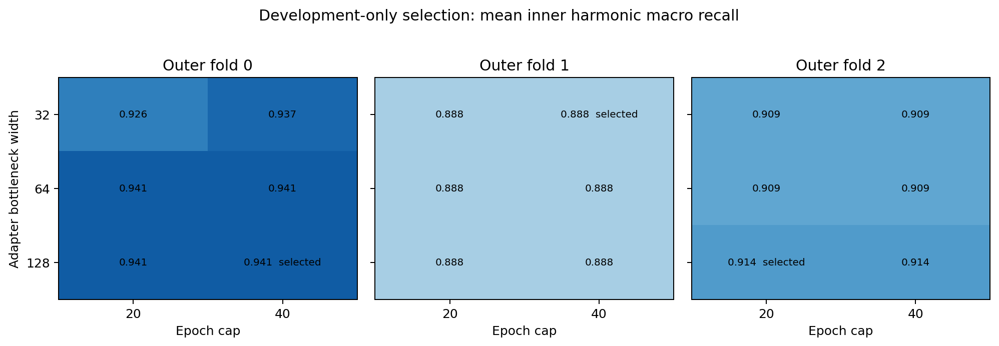<figcaption>Mean harmonic macro recall across the development-only width and epoch-cap search.</figcaption></figure>
<figure>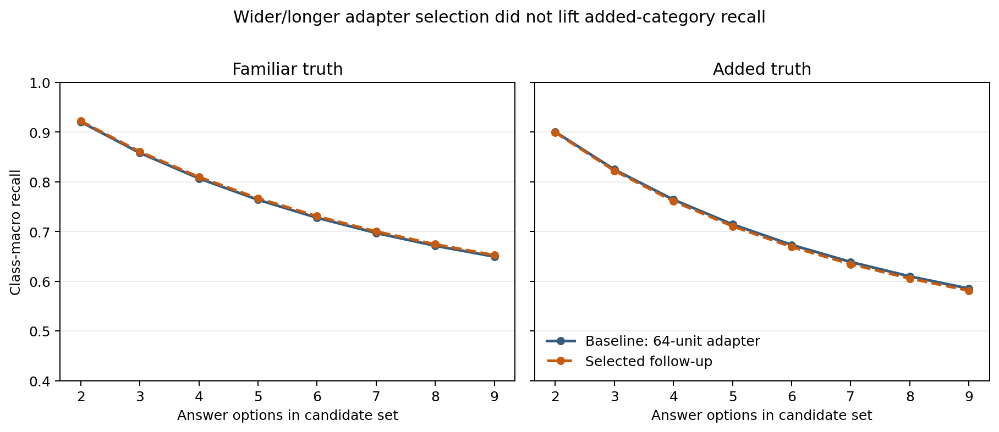<figcaption>Exploratory recall by candidate set size, baseline and selected follow-up.</figcaption></figure>


The development search was close across the six settings: mean harmonic macro recall was **0.90767** for width 32/cap 20; **0.91115** for 32/40; **0.91269** for 64/20 and 64/40; and **0.91428** for 128/20 and 128/40. This small spread and the mixed fold selections do not show a consistent capacity or duration benefit.

| Added category | Baseline recall | Follow-up recall | Difference (points) |
|---|---:|---:|---:|
| Adipose | 96.380% | 96.353% | −0.027 |
| Background | 43.960% | 42.893% | −1.066 |
| Cancer-associated stroma | 68.685% | 68.401% | −0.284 |
| Colorectal adenocarcinoma epithelium | 74.988% | 75.355% | +0.367 |
| Debris | 48.129% | 48.179% | +0.051 |
| Lymphocytes | 98.630% | 98.107% | −0.522 |
| Mucus | 74.098% | 73.570% | −0.529 |
| Normal colon mucosa | 50.291% | 49.687% | −0.604 |
| Smooth muscle | 87.270% | 86.829% | −0.441 |

| Candidate-set size | Added baseline | Added follow-up | Familiar baseline | Familiar follow-up |
|---:|---:|---:|---:|---:|
| 2 | 90.044% | 89.924% | 92.067% | 92.224% |
| 3 | 82.476% | 82.241% | 85.826% | 86.066% |
| 4 | 76.410% | 76.094% | 80.690% | 80.974% |
| 5 | 71.439% | 71.066% | 76.391% | 76.695% |
| 6 | 67.317% | 66.908% | 72.769% | 73.079% |
| 7 | 63.871% | 63.445% | 69.711% | 70.019% |
| 8 | 60.972% | 60.547% | 67.131% | 67.431% |
| 9 | 58.520% | 58.108% | 64.958% | 65.249% |

**Timing scope:** development search 1.059 seconds in the successful checkpoint-resumed invocation; development fits 54.388 seconds total; selected refits 8.792 seconds; cached-feature test scoring 0.528 seconds across 36 rows (7,180 features per row, batch 512). The mean per-row scoring times were 0.01465 seconds for baseline and 0.01470 seconds for follow-up. These exclude encoder, data acquisition, transfer and notebook startup.

**Reproducibility hashes:** protocol `41e1d8e8a942d0d137265d9cb745fec21dcad613e768a1cca41ed0bcca16f5eb`; features `a7a083ea6a03b967e6805d426a060a8f10c9a4c16f3ead8aa82fc92e8f6632b3`; text bank `1de147ce13c29ec94234aa05f435ea91597364ad4e097a47c4ddd6ecf1b43c8c`; selected settings `16801b1160b70332a38add2f489453406d9b38e09e8bb5a04ad5f4013e4c9edc`; search CSV `45cb9755e56e6d3eb9423e97bc5cd6669859e264b55fa92809e34f03f1272ff1`; fit CSV `b8708d22ac329818e2ba1a4a7bbc689c55ebf01e2c537d58ef7d37c6870b8dbe`; category CSV `babcb502b5e5b0b5609f59f6d4a3be113f032bbbdbe7292d833d4a03c0b6a3db`; candidate-set-size CSV `084b5377c22b2673b9295ad1c53598a502abadbff15561fa9aaab5ada638bf4e`; test logits `37928ea7e1186dc14a6c6d38429b9772c0a923ba41e58a8f71a7609a8f070f2d`; timings `bf6bd6155ad303839c4ba2b525268ddb5ef1f9db5a57bc22e45850de39e6cd66`.


<figure>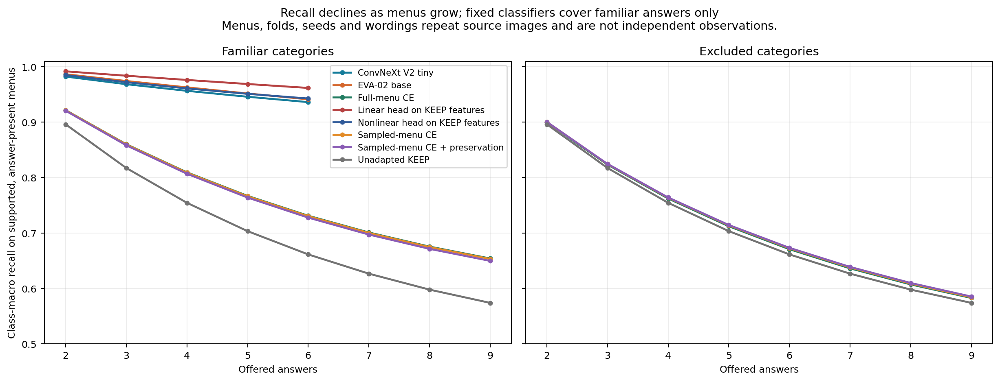<figcaption>Recall by candidate set size and category group.</figcaption></figure>

<figure>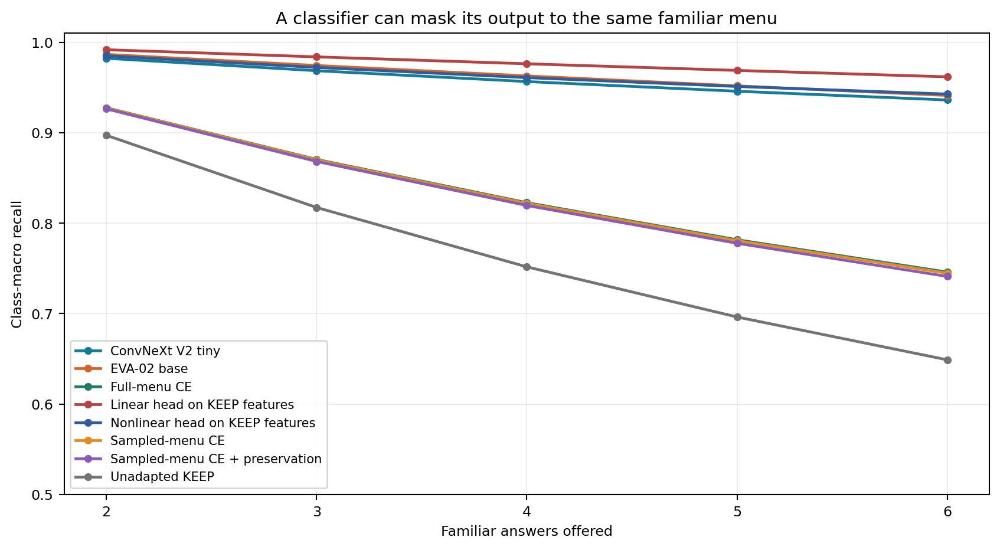<figcaption>Matched familiar-candidate set comparison.</figcaption></figure>

<figure>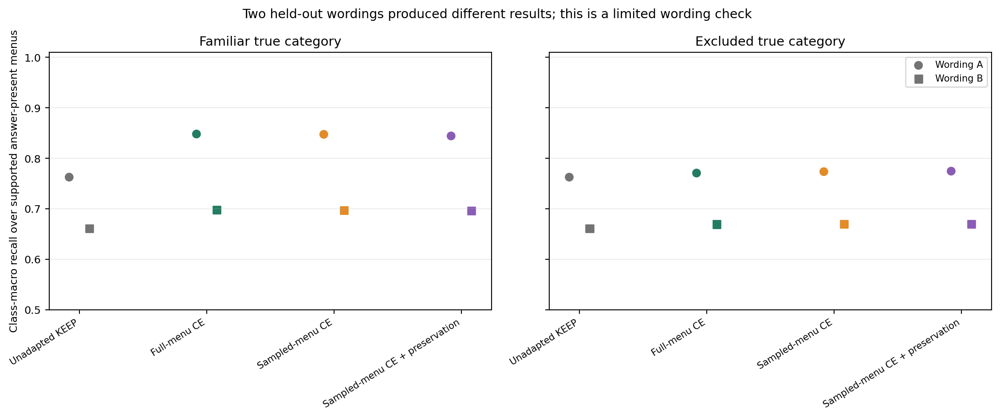<figcaption>Two held-out wording templates.</figcaption></figure>

<figure>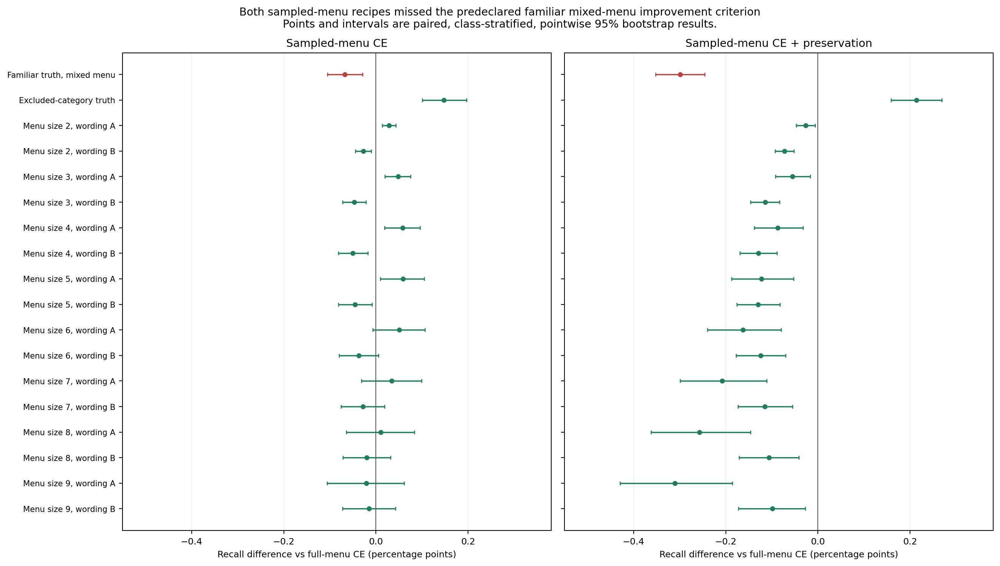<figcaption>Paired recipe differences and pointwise intervals.</figcaption></figure>

<figure>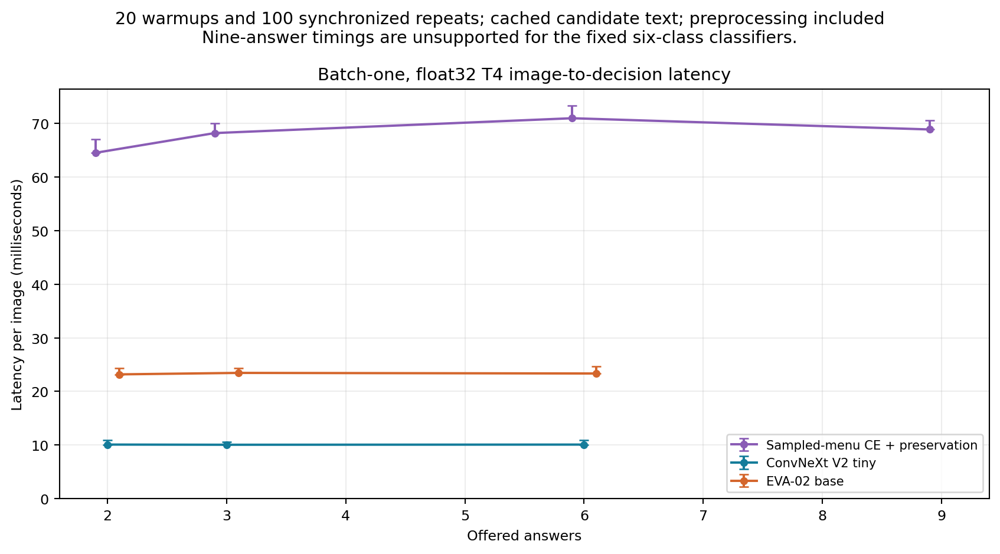<figcaption>Measured batch-one latency on the T4.</figcaption></figure>

<figure>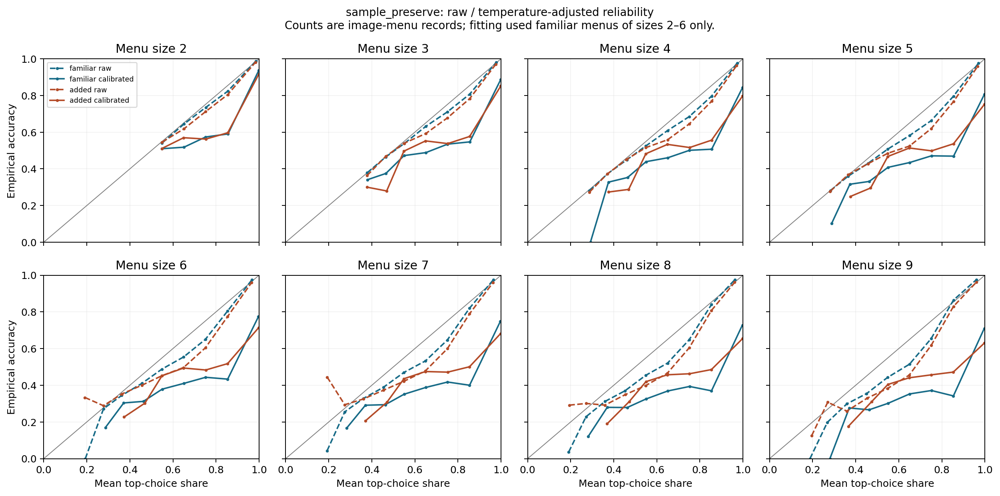<figcaption>Saved reliability diagram.</figcaption></figure>

<figure>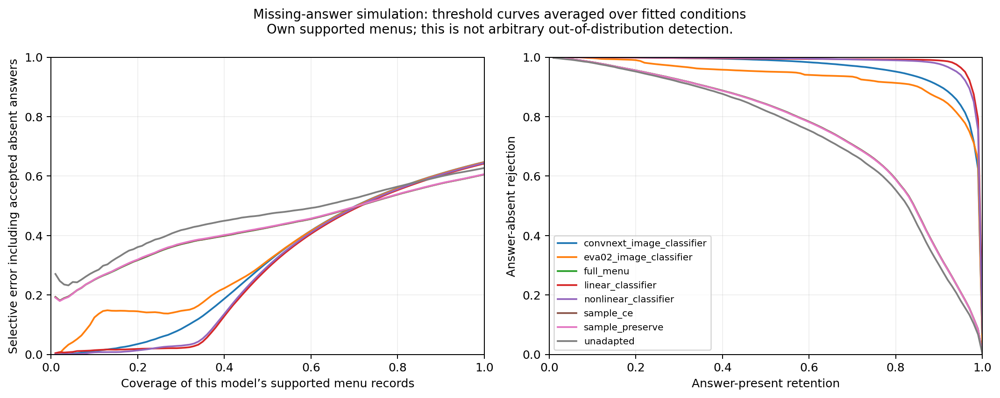<figcaption>Saved rejection and risk-coverage curves.</figcaption></figure>

## 6. Measure latency, memory and compute costs

**Exercise14:** compare cached-feature head scoring with complete image-to-decision measurements. Both use float32, the same GPU, batch1/32, menu2/3/6/9 where supported,20 warmups and100 synchronized repeats. End-to-end scope includes image preprocessing and encoder/head computation with candidate text cached. New-description text encoding and cold setup are separate. p50 is the median; p95 is the slower95th-percentile observation. OOM/unavailable/unsupported rows stay explicit.

GPU-hours per million images = `(mean_seconds_per_batch/batch_size)*1,000,000/3,600`. This is a workload conversion, not observed million-image execution or actual Colab billing. Optionally supply a dated hourly rate; no monetary advantage is assumed. Complete comparisons need the source-image author stage. The predeclared timing instance is fold0/seed7.

In [ ]:
"""Measured scope-specific inference costs, called only in the Colab run."""

def measure_inference(call, *, model, scope, batch_size, menu_size, warmup=20, repeats=100):
    unit = 'candidate_menu' if scope == 'new_candidate_text_encoding' else 'image'
    row = {'model': model, 'scope': scope, 'batch_size': batch_size, 'menu_size': menu_size,
           'precision': 'float32', 'hardware': HARDWARE, 'completed_warmups': 0,
           'completed_repeats': 0, 'timings_ms': [], 'status': 'pending', 'workload_unit': unit}
    if DEVICE.type != 'cuda':
        return {**row, 'status': 'unavailable', 'reason': 'Same-GPU benchmark requires CUDA.'}
    try:
        with torch.inference_mode():
            for _ in range(warmup):
                call(); row['completed_warmups'] += 1
            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
            baseline = torch.cuda.memory_allocated()
            for _ in range(repeats):
                torch.cuda.synchronize(); start = time.perf_counter()
                value = call()
                torch.cuda.synchronize()
                row['timings_ms'].append((time.perf_counter() - start) * 1000)
                row['completed_repeats'] += 1
                del value
            peak = torch.cuda.max_memory_allocated()
        times = np.asarray(row['timings_ms'])
        row.update(status='measured', p50_ms=float(np.median(times)), p95_ms=float(np.quantile(times, .95)),
                   throughput_units_per_second=float(batch_size * 1000 / times.mean()),
                   peak_allocated_bytes=int(peak), baseline_allocated_bytes=int(baseline),
                   incremental_peak_bytes=int(peak-baseline), measured_seconds=float(times.sum()/1000),
                   gpu_hours_per_million_units=float(times.mean()/1000/batch_size*1e6/3600))
        if USD_PER_GPU_HOUR is not None:
            if not USD_RATE_DATE or not np.isfinite(USD_PER_GPU_HOUR) or USD_PER_GPU_HOUR < 0:
                raise ValueError('A monetary scenario needs a finite nonnegative rate and explicit date.')
            row.update(usd_per_gpu_hour=float(USD_PER_GPU_HOUR), rate_date=USD_RATE_DATE,
                       assumed_usd_per_million_units=row['gpu_hours_per_million_units']*USD_PER_GPU_HOUR)
    except torch.cuda.OutOfMemoryError:
        row.update(status='oom', reason='Condition did not complete; no extrapolated timing.')
        torch.cuda.empty_cache()
    return row


def run_inference_benchmarks(cohort_images=None, classifier_records=()):
    rows, cold = [], []
    familiar, _ = fold_classes(0)
    text = TEXT_BANK['eval_0'].to(DEVICE)
    # Predeclared fold/seed: benchmark fitted instances, without pretending seed repeats are timing replicates.
    candidates = [(kind, model) for (kind, fold, seed), model in MODELS.items() if fold == 0 and seed == 7]
    candidates.append(('unadapted', None))
    for kind, model in candidates:
        supported = tuple(familiar) if kind.endswith('_classifier') else tuple(range(9))
        if model is not None: model.to(DEVICE).eval()
        for batch in (1, 32):
            x = FEATURES['test'][:batch].to(DEVICE)
            for size in (2, 3, 6, 9):
                if size > len(supported):
                    rows.append({'model': kind, 'scope': 'cached_feature_head', 'batch_size': batch,
                                 'menu_size': size, 'status': 'unsupported'}); continue
                ids = supported[:size]
                if kind.endswith('_classifier'):
                    columns = [familiar.index(c) for c in ids]
                    call = lambda: model(x)[:, columns]
                elif model is None:
                    call = lambda: LOGIT_SCALE * (F.normalize(x, dim=-1) @ text[list(ids)].T)
                else:
                    call = lambda: model(x, text[list(ids)])
                rows.append(measure_inference(call, model=kind, scope='cached_feature_head', batch_size=batch, menu_size=size))
        if model is not None: model.cpu()
        torch.cuda.empty_cache()
    if cohort_images is not None and DEVICE.type == 'cuda':
        try:
            start = time.perf_counter(); encoder = load_encoder().float().eval(); torch.cuda.synchronize()
            cold.append({'model': 'KEEP', 'scope': 'encoder_activation_existing_CPU_or_HF_cache', 'seconds': time.perf_counter()-start,
                         'network_cache_state': 'recorded by HF cache; not an uncached-download experiment'})
            scorer = MODELS[('sample_preserve', 0, 7)].to(DEVICE).eval()
            for batch in (1, 32):
                images = [Image.fromarray(v) for v in cohort_images['test'][:batch]]
                for size in (2, 3, 6, 9):
                    ids = tuple(range(size))
                    def image_decision():
                        tensor = torch.stack([TRANSFORM(v) for v in images]).to(DEVICE)
                        features = F.normalize(encoder.encode_image(tensor).float(), dim=-1)
                        return scorer(features, text[list(ids)])
                    rows.append(measure_inference(image_decision, model='sample_preserve', scope='image_to_decision_cached_menu_including_preprocess', batch_size=batch, menu_size=size))
                    descriptions = [TEMPLATE_BANK['eval_0'].format(name=LABELS[c]) for c in ids]
                    def text_encoding():
                        tokens = TOKENIZER(descriptions, return_tensors='pt', padding=True, truncation=False).to(DEVICE)
                        return encoder.encode_text(tokens).float()
                    if batch == 1:
                        rows.append(measure_inference(text_encoding, model='KEEP', scope='new_candidate_text_encoding', batch_size=1, menu_size=size))
            scorer.cpu(); freeze_backbone_on_cpu()
        except torch.cuda.OutOfMemoryError:
            cold.append({'model':'KEEP', 'scope':'complete_model_setup', 'status':'oom', 'reason':'Setup did not complete; no timing extrapolation.'})
            for (kind,fold,seed), item in MODELS.items(): item.cpu()
            freeze_backbone_on_cpu()
        for record in classifier_records:
            meta = record['metadata']
            fold = record.get('fold', meta.get('fold')); seed = record.get('seed', meta.get('seed'))
            if fold != 0 or seed != 7: continue
            kind = record.get('kind', record.get('model', meta.get('kind', meta.get('model'))))
            try:
                start = time.perf_counter(); model, transform = load_classifier_for_benchmark(record)
                model.to(DEVICE).float().eval(); torch.cuda.synchronize()
            except torch.cuda.OutOfMemoryError:
                cold.append({'model':kind, 'scope':'complete_model_setup', 'status':'oom', 'reason':'Setup did not complete; no timing extrapolation.'})
                if 'model' in locals(): model.cpu()
                torch.cuda.empty_cache()
                continue
            cold.append({'model': kind, 'scope': 'fitted_local_checkpoint_setup', 'seconds': time.perf_counter()-start})
            for batch in (1, 32):
                images = [Image.fromarray(v) for v in cohort_images['test'][:batch]]
                for size in (2, 3, 6, 9):
                    if size == 9:
                        rows.append({'model': kind, 'scope': 'image_to_decision_cached_menu_including_preprocess', 'batch_size': batch, 'menu_size': size, 'status': 'unsupported'}); continue
                    def image_decision_classifier():
                        tensor = torch.stack([transform(v) for v in images]).to(DEVICE)
                        return model(tensor)[:, :size]
                    rows.append(measure_inference(image_decision_classifier, model=kind, scope='image_to_decision_cached_menu_including_preprocess', batch_size=batch, menu_size=size))
            model.cpu(); del model; torch.cuda.empty_cache()
    else:
        cold.append({'scope': 'complete_image_model_timing', 'status': 'unavailable', 'reason': 'Author source-image stage not requested/completed.'})
    payload = {'protocol_sha': PROTOCOL_SHA, 'fold': 0, 'seed': 7, 'rows': rows, 'cold_setup': cold,
               'first_encoder_setup': ENCODER_SETUP_RECORDS, 'native_image_shape':[224,224,3],
               'complete_preprocessing':{r['model']:r['metadata']['spec']['preprocessing'] for r in classifier_records},
               'cost_scope': 'compute-hour workload conversion; optional dated user rate; no actual billing claim'}
    (RUN_DIR/'benchmark.json').write_text(json.dumps(payload, indent=2))
    pd.DataFrame([{k:v for k,v in r.items() if k not in ('timings_ms','hardware')} for r in rows]).to_csv(RUN_DIR/'benchmark.csv', index=False)
    return payload


In [ ]:
BENCHMARK = run_inference_benchmarks(COHORT_IMAGES, CLASSIFIER_RECORDS)

## 7. Plot the results and judge the hypothesis

The hypothesis is better familiar mixed-candidate set recall without materially degrading excluded-category recognition. Examine means, worst candidate set size, worst wording, worst category fold and harmful familiar distractors. Conditional uncertainty uses paired, class-stratified source-image bootstrap: repeated candidate sets/folds/seeds travel together, rather than becoming pretend independent patients.

Predeclared tutorial tolerances are improvement in familiar mixed-candidate set recall, at most2 percentage points pooled excluded recall loss, and at most5 points loss in any full-coverage size/held-out-wording group. If uncertainty cannot exclude material loss, robustness is inconclusive. These tolerances are research choices, not clinical acceptability. Calibration and rejection can fail while their experiments still teach useful methods.

In [ ]:
SIGNATURE = 'lambertleong.com'

PLACEMENTS = {
    'accuracy-by-size': (.36, .54, .018),
    'matched-familiar-menus': (.68, .31, .018),
    'held-out-wording': (.29, .46, .018),
    'latency': (.47, .48, .018),
    'risk-rejection': (.28, .38, .018),
    'reliability': (.16, .40, .015),
    'paired-robustness': (.21, .52, .012),
    'paired-sample-ce': (.88, .75, .014),
    'paired-sample-preserve': (.88, .75, .014),
    'adapter-followup-candidate-set-size': (.34, .40, .018),
    'adapter-followup-development-search': (.403, .953, .013),
    'vlm-candidate-size': (.26, .61, .018),
    'vlm-matched-decisions': (.90, .22, .012),
    'vlm-added-category': (.61, .175, .016),
    'category-transfer-mobile': (.48, .37, .030),
    'category-transfer': (.61, .80, .018),
    'editable-prediction-mobile': (.65, .79, .026),
    'editable-prediction': (.72, .66, .018),
    'tissue-collage-mobile': (.52, .49, .035),
    'tissue-collage': (.51, .525, .021),
    'tissue-description-architecture': (.50, .92, .018),
}

def placement(stem):
    key = stem.removeprefix('rounded-').removeprefix('reader-').removeprefix('keep-')
    if key.startswith('rotating-menu-'):
        key = key.removeprefix('rotating-menu-')
    key = key.removeprefix('rotating-')
    return PLACEMENTS[key]

def figure_watermark(fig, stem):
    """Place the signature using the reviewed layout for this figure."""
    x, y, size = placement(stem)
    fig.text(x, 1-y, SIGNATURE, ha='center', va='center',
             fontsize=fig.get_figwidth()*72*size, color='#808080', alpha=.40,
             gid='site-watermark')

"""Actual-data plots and paired uncertainty from the saved menu-evidence tables."""

_ROTATING_LABELS = {
    'unadapted': 'Unadapted KEEP',
    'full_menu': 'Full-menu training',
    'sample_ce': 'Sampled-menu CE',
    'sample_preserve': 'Sampled-menu CE + preservation',
    'linear_classifier': 'Linear KEEP-feature head',
    'nonlinear_classifier': 'Nonlinear KEEP-feature head',
    'convnext_image_classifier': 'ConvNeXt V2 tiny',
    'eva02_image_classifier': 'EVA-02 base',
}


def _rotating_model_label(kind):
    return _ROTATING_LABELS.get(kind, str(kind).replace('_', ' '))


def _rotating_group_label(scope):
    if scope == 'primary familiar recall with added alternatives':
        return 'Familiar truth, mixed menu'
    if scope == 'pooled excluded-category recall':
        return 'Excluded-category truth'
    if scope.startswith('menu size '):
        size, wording = scope.removeprefix('menu size ').split(', wording ')
        return f'Menu size {size}, wording {"A" if wording == "eval_0" else "B"}'
    if scope.startswith('fold '):
        fold, group = scope.split(': ', 1)
        return f'{fold.capitalize()}, {"familiar mixed" if group == "familiar mixed menus" else "excluded categories"}'
    return str(scope)

def _rotating_read_tables(run_dir, suffix, kinds=None):
    frames = []
    for path in sorted((Path(run_dir) / 'metrics').glob('*-' + suffix)):
        if kinds is not None and not any(path.name.startswith(kind + '-fold') for kind in kinds):
            continue
        if suffix == 'per_image.csv.gz':
            needed = ['sample_id', 'true_id', 'cohort', 'menu_size', 'present', 'menu_scope',
                      'supported', 'count', 'accuracy', 'kind', 'fold', 'seed', 'template', 'protocol_sha']
            for chunk in pd.read_csv(path, usecols=needed, chunksize=50000):
                chunk = chunk.loc[chunk['supported'].eq(True) & chunk['present'].eq(True)]
                if len(chunk):
                    frames.append(chunk)
        else:
            frame = pd.read_csv(path)
            if len(frame):
                frames.append(frame)
    if not frames:
        return pd.DataFrame()
    return pd.concat(frames, ignore_index=True)


def _rotating_class_macro(frame, metric, groups):
    valid = frame.loc[np.isfinite(frame[metric]) & (frame['count'] > 0)].copy()
    valid['weighted_metric'] = valid[metric] * valid['count']
    class_keys = list(groups) + ['true_id']
    weighted = valid.groupby(class_keys, dropna=False)[['weighted_metric', 'count']].sum().reset_index()
    weighted['value'] = weighted['weighted_metric'] / weighted['count']
    pooled = weighted.groupby(list(groups), dropna=False).agg(
        value=('value', 'mean'), class_count=('true_id', 'nunique'), menu_records=('count', 'sum')).reset_index()
    return pooled


def _rotating_save_figure(fig, folder, stem):
    folder.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    figure_watermark(fig, stem)
    result = {}
    for suffix in ('.svg', '.png'):
        path = folder / (stem + suffix)
        fig.savefig(path, dpi=180, bbox_inches='tight', facecolor='white')
        result[suffix[1:]] = str(path)
    plt.close(fig)
    return result


def rotating_robustness_audit(run_dir=None, *, candidate='sample_preserve', reference='full_menu', repeats=2000):
    """A stringent descriptive gate using paired source-image, class-stratified CIs.

    Intervals are pointwise, conditional dataset/design uncertainty. They are not
    simultaneous guarantees, patient-level inference or clinical acceptance limits.
    """
    run_dir = Path(RUN_DIR if run_dir is None else run_dir)
    frames = _rotating_read_tables(run_dir, 'per_image.csv.gz', kinds=(candidate, reference))
    if frames.empty or not {candidate, reference}.issubset(set(frames['kind'])):
        raise ValueError('Both candidate and reference executed per-image artifacts are required.')
    valid = frames.loc[frames['supported'].eq(True) & frames['present'].eq(True)].copy()
    if 'protocol_sha' not in valid or valid['protocol_sha'].nunique() != 1:
        raise ValueError('Uncertainty comparison must use exactly one recorded protocol.')
    records = []

    def comparison(scope, subset, tolerance, direction='preserve'):
        left = subset.loc[subset['kind'] == candidate]
        right = subset.loc[subset['kind'] == reference]
        expected_classes = set(subset['true_id'])
        coverage = (set(left['true_id']) == expected_classes == set(right['true_id']))
        if not coverage or not len(left) or not len(right):
            raise ValueError('A predeclared robustness group lacks matched class coverage: ' + scope)
        result = paired_class_bootstrap(left, right, repeats=repeats, seed=2028)
        lower, upper = result['lower_95'], result['upper_95']
        boundary = 0. if direction == 'improve' else -float(tolerance)
        met = lower > boundary if direction == 'improve' else lower >= boundary
        failed = upper <= boundary if direction == 'improve' else upper < boundary
        uncertainty_scope = result.pop('scope')
        records.append({'scope': scope, 'uncertainty_scope': uncertainty_scope,
                        'candidate': candidate, 'reference': reference,
                        'tolerance': float(tolerance), 'criterion': direction, 'full_class_coverage': coverage,
                        'decision': 'met' if met else 'failed' if failed else 'inconclusive', **result})

    familiar_mixed = valid.loc[(valid['cohort'] == 'familiar') & (valid['menu_scope'] == 'mixed')]
    comparison('primary familiar recall with added alternatives', familiar_mixed, 0., 'improve')
    added = valid.loc[valid['cohort'] == 'added']
    comparison('pooled excluded-category recall', added, .02)
    for size in range(2, 10):
        for template in ('eval_0', 'eval_1'):
            subset = valid.loc[(valid['menu_size'] == size) & (valid['template'] == template)]
            if set(subset['true_id']) != set(range(9)):
                raise ValueError('Every size/wording group must cover all nine true categories.')
            comparison(f'menu size {size}, wording {template}', subset, .05)
    decision_rows = len(records)
    # Fold results are reported explicitly; the planned gate uses pooled criteria above.
    for fold in sorted(valid['fold'].unique()):
        comparison(f'fold {fold}: familiar mixed menus', familiar_mixed.loc[familiar_mixed['fold'] == fold], 0., 'improve')
        comparison(f'fold {fold}: excluded categories', added.loc[added['fold'] == fold], .02)
    table = pd.DataFrame(records)
    gate = table.iloc[:decision_rows]
    if gate['decision'].eq('met').all():
        decision = 'met'
    elif gate['decision'].eq('failed').any():
        decision = 'failed'
    else:
        decision = 'inconclusive'
    result = {'candidate': candidate, 'reference': reference, 'decision': decision,
              'protocol_sha': str(valid['protocol_sha'].iloc[0]),
              'criteria': ['positive primary mixed-menu familiar recall difference',
                           'pooled excluded-category recall loss at most 2 percentage points',
                           'every menu-size/held-out-wording recall loss at most 5 percentage points'],
              'decision_rule': 'all corresponding pointwise 95% lower confidence bounds must meet the tolerance',
              'uncertainty': 'class-stratified paired source-image bootstrap; all menus/folds/seeds/wording travel together',
              'limitations': 'conditional dataset/design intervals; no patient independence or simultaneous confidence guarantee',
              'fold_results': 'reported separately and not silently pooled away',
              'evaluated_group_count': decision_rows}
    folder = run_dir / 'metrics'
    table.to_csv(folder / ('robustness-' + candidate + '-vs-' + reference + '.csv'), index=False)
    _score_write_json(folder / ('robustness-' + candidate + '-vs-' + reference + '.json'), result)
    return result, table


def make_rotating_figures(run_dir=None, *, bootstrap_repeats=2000):
    """Read executed exports only; no missing results are synthesized or filled with zero."""
    run_dir = Path(RUN_DIR if run_dir is None else run_dir)
    folder = run_dir / 'figures'
    aggregates = _rotating_read_tables(run_dir, 'aggregates.csv')
    if aggregates.empty:
        raise ValueError('Execute/export menu evidence before requesting actual-data plots.')
    if aggregates['protocol_sha'].nunique() != 1:
        raise ValueError('Plot inputs mix incompatible protocols.')
    present = aggregates.loc[aggregates['supported'].eq(True) & aggregates['present'].eq(True)]
    paths = {}
    size = _rotating_class_macro(present, 'accuracy', ['kind', 'cohort', 'menu_size'])
    size.to_csv(run_dir / 'metrics' / 'plot-accuracy-by-size.csv', index=False)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
    for ax, cohort in zip(axes, ('familiar', 'added')):
        for kind, group in size.loc[size['cohort'] == cohort].groupby('kind'):
            group = group.sort_values('menu_size')
            ax.plot(group['menu_size'], group['value'], marker='o', markersize=3, label=_rotating_model_label(kind))
        ax.set(title=cohort.capitalize() + ' true categories', xlabel='Supplied menu size', xticks=range(2, 10), ylim=(0, 1))
        ax.grid(alpha=.2)
    axes[0].set_ylabel('Class-macro recall on supported present menus')
    axes[0].legend(fontsize=7, loc='best')
    fig.suptitle('Own supported menus: classifier curves omit added candidates\nRepeated menus, seeds and wording are not independent source images.', fontsize=11)
    paths['accuracy_by_size'] = _rotating_save_figure(fig, folder, 'rotating-accuracy-by-size')

    matched = present.loc[(present['cohort'] == 'familiar') & (present['added_distractors'] == 0)]
    matched = _rotating_class_macro(matched, 'accuracy', ['kind', 'menu_size'])
    matched.to_csv(run_dir / 'metrics' / 'plot-matched-familiar-menus.csv', index=False)
    fig, ax = plt.subplots(figsize=(8, 4.8))
    for kind, group in matched.groupby('kind'):
        group = group.sort_values('menu_size')
        ax.plot(group['menu_size'], group['value'], marker='o', markersize=3, label=_rotating_model_label(kind))
    ax.set(xlabel='Supplied familiar menu size', ylabel='Class-macro recall', xticks=range(2, 7), ylim=(0, 1),
           title='Identical familiar subsets: every method can mask its allowed answers')
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
    paths['matched_familiar_menus'] = _rotating_save_figure(fig, folder, 'rotating-matched-familiar-menus')

    wording = _rotating_class_macro(present, 'accuracy', ['kind', 'cohort', 'template'])
    wording.to_csv(run_dir / 'metrics' / 'plot-wording-recall.csv', index=False)
    worst = wording.groupby(['kind', 'cohort']).agg(worst_wording_recall=('value', 'min'),
                                                 mean_wording_recall=('value', 'mean'),
                                                 wording_count=('template', 'nunique')).reset_index()
    worst.to_csv(run_dir / 'metrics' / 'plot-worst-wording.csv', index=False)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    kinds = sorted(wording['kind'].unique())
    for ax, cohort in zip(axes, ('familiar', 'added')):
        for i, template in enumerate(('eval_0', 'eval_1')):
            group = wording.loc[(wording['cohort'] == cohort) & (wording['template'] == template)].set_index('kind')
            values = [group.loc[kind, 'value'] if kind in group.index else np.nan for kind in kinds]
            ax.scatter(np.arange(len(kinds)) + (i - .5) * .16, values, label=template, s=30)
        ax.set(title=cohort.capitalize(), xticks=np.arange(len(kinds)), ylim=(0, 1))
        ax.set_xticklabels([_rotating_model_label(kind) for kind in kinds], rotation=45, ha='right', fontsize=8)
        ax.grid(axis='y', alpha=.2)
    axes[0].set_ylabel('Class-macro recall across present menus')
    axes[1].legend(fontsize=9)
    fig.suptitle('Held-out wording: both outcomes and the worst wording remain visible', fontsize=11)
    paths['wording'] = _rotating_save_figure(fig, folder, 'rotating-held-out-wording')

    reliability = _rotating_read_tables(run_dir, 'reliability.csv')
    if not reliability.empty:
        keys = ['kind', 'cohort', 'menu_size', 'calibration', 'bin']
        pooled = reliability.groupby(keys)[['count', 'confidence_sum', 'correct_sum']].sum().reset_index()
        pooled['mean_confidence'] = pooled['confidence_sum'] / pooled['count'].replace(0, np.nan)
        pooled['empirical_accuracy'] = pooled['correct_sum'] / pooled['count'].replace(0, np.nan)
        pooled.to_csv(run_dir / 'metrics' / 'plot-reliability-by-size-cohort.csv', index=False)
        # Calibration metrics pool bins directly; averaging ECE values would be incorrect.
        pooled['absolute_gap_sum'] = abs(pooled['confidence_sum'] - pooled['correct_sum'])
        ece = pooled.groupby(keys[:-1])[['count', 'absolute_gap_sum']].sum().reset_index()
        ece['ece'] = ece['absolute_gap_sum'] / ece['count']
        ece.to_csv(run_dir / 'metrics' / 'plot-ece-by-size-cohort.csv', index=False)
        selected_kind = 'sample_preserve' if 'sample_preserve' in set(pooled['kind']) else str(pooled['kind'].iloc[0])
        fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True)
        for ax, menu_size in zip(axes.flat, range(2, 10)):
            subset = pooled.loc[(pooled['kind'] == selected_kind) & (pooled['menu_size'] == menu_size)]
            ax.plot([0, 1], [0, 1], color='grey', linewidth=.8)
            for cohort, color in (('familiar', '#176b87'), ('added', '#b44b28')):
                for calibration, style in (('raw', '--'), ('calibrated', '-')):
                    group = subset.loc[(subset['cohort'] == cohort) & (subset['calibration'] == calibration) &
                                       (subset['count'] > 0)].sort_values('bin')
                    ax.plot(group['mean_confidence'], group['empirical_accuracy'], style, color=color,
                            marker='o', markersize=2, label=cohort + ' ' + calibration)
            ax.set(title=f'Menu size {menu_size}', xlim=(0, 1), ylim=(0, 1))
            ax.grid(alpha=.15)
        axes[0, 0].legend(fontsize=7)
        for ax in axes[-1]:
            ax.set_xlabel('Mean top-choice share')
        for ax in axes[:, 0]:
            ax.set_ylabel('Empirical accuracy')
        fig.suptitle(_rotating_model_label(selected_kind) + ': raw / temperature-adjusted reliability\nCounts are image-menu records; fitting used familiar menus of sizes 2–6 only.', fontsize=11)
        paths['reliability'] = _rotating_save_figure(fig, folder, 'rotating-reliability')

    curve_grid = np.linspace(.01, 1., 100)
    curve_rows = []
    curve_files = sorted((run_dir / 'metrics').glob('*-curves.csv.gz'))
    curve_files += sorted((run_dir / 'metrics').glob('*-curves.csv'))
    for file in curve_files:
        curve = pd.read_csv(file)
        if curve.empty:
            continue
        kind = str(curve['kind'].iloc[0])
        for x_name, y_name, label in (('coverage', 'combined_selective_error', 'risk'),
                                      ('present_retention', 'absent_rejection', 'rejection')):
            points = curve.loc[np.isfinite(curve[x_name]) & np.isfinite(curve[y_name])]
            points = points.groupby(x_name)[y_name].mean().sort_index()
            if len(points) < 2:
                continue
            interpolated = np.interp(curve_grid, points.index.to_numpy(), points.to_numpy(), left=np.nan, right=np.nan)
            for x, value in zip(curve_grid, interpolated):
                if np.isfinite(value):
                    curve_rows.append({'kind': kind, 'curve': label, 'x': float(x), 'value': float(value),
                                       'fold': int(curve['fold'].iloc[0]), 'seed': int(curve['seed'].iloc[0]),
                                       'template': str(curve['template'].iloc[0])})
    if curve_rows:
        table = pd.DataFrame(curve_rows)
        # Wording-invariant classifier copies have equal values and are not counted as independent evidence.
        line = table.groupby(['kind', 'curve', 'x'])['value'].mean().reset_index()
        line.to_csv(run_dir / 'metrics' / 'plot-risk-rejection-curves.csv', index=False)
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
        for ax, label in zip(axes, ('risk', 'rejection')):
            for kind, group in line.loc[line['curve'] == label].groupby('kind'):
                ax.plot(group['x'], group['value'], label=_rotating_model_label(kind))
            ax.set(xlim=(0, 1), ylim=(0, 1))
            ax.grid(alpha=.2)
        axes[0].set(xlabel='Coverage of this model’s supported menu records', ylabel='Selective error including accepted absent answers')
        axes[1].set(xlabel='Answer-present retention', ylabel='Answer-absent rejection')
        axes[1].legend(fontsize=8)
        fig.suptitle('Missing-answer simulation: threshold curves averaged over fitted conditions\nOwn supported menus; this is not arbitrary out-of-distribution detection.', fontsize=11)
        paths['rejection'] = _rotating_save_figure(fig, folder, 'rotating-risk-rejection')

    decisions = {}
    for candidate in ('sample_ce', 'sample_preserve'):
        if {candidate, 'full_menu'}.issubset(set(present['kind'])):
            result, table = rotating_robustness_audit(run_dir, candidate=candidate, repeats=bootstrap_repeats)
            decisions[candidate] = result
            pooled = table.iloc[:result['evaluated_group_count']]
            fig, ax = plt.subplots(figsize=(10, max(5, len(pooled) * .29)))
            positions = np.arange(len(pooled))
            ax.errorbar(pooled['difference'] * 100, positions,
                        xerr=np.maximum(0., np.vstack(((pooled['difference'] - pooled['lower_95']) * 100,
                                                     (pooled['upper_95'] - pooled['difference']) * 100))), fmt='o', markersize=3)
            ax.axvline(0, color='grey', linewidth=.8)
            ax.set(yticks=positions, yticklabels=[_rotating_group_label(value) for value in pooled['scope']],
                   xlabel='Paired recall difference (percentage points), pointwise 95% interval',
                   title=_rotating_model_label(candidate) + ' minus full-menu training: ' + result['decision'])
            ax.tick_params(axis='y', labelsize=8)
            ax.invert_yaxis()
            ax.grid(axis='x', alpha=.2)
            paths['paired_' + candidate] = _rotating_save_figure(fig, folder, 'rotating-paired-' + candidate)
    result = {'figures': paths, 'robustness': decisions,
              'source': 'executed run metrics CSV files', 'protocol_sha': str(aggregates['protocol_sha'].iloc[0]),
              'plots_are': 'descriptive repeated-condition summaries; confidence intervals only where explicitly plotted'}
    _score_write_json(run_dir / 'figure-manifest.json', result)
    return result


In [ ]:
FIGURE_REPORT = make_rotating_figures(RUN_DIR)
display(FIGURE_REPORT)

## 8. Return typed decisions and change the choices

**Exercise10:** edit `MY_CANDIDATES` below. IDs are nonempty unique application strings. Duplicate descriptions, empty candidate sets, invalid image positions and missing fields produce explicit errors. The helper returns raw scores, calibrated shares, chosen ID or None, rejection score, threshold and protocol version. Neither typed outputs nor abstention is exclusive to a model that compares images with supplied text descriptions.

Try reordering; changing IDs; adding a built-in description; removing the true answer; and changing wording. Built-in descriptions stay cached. Custom wording requires explicit `ALLOW_NEW_TEXT_ENCODING=True` and downloads frozen starting model on first use. Changed descriptions/domains do not inherit a guarantee from prior calibration.

In [ ]:
"""Decoder-free application interface; IDs label results, text supplies meaning."""

def typed_decision(candidate_ids, logits, temperature, threshold, *, sample_id, descriptions=None):
    ids = list(candidate_ids)
    scores = np.asarray(logits, dtype=np.float64)
    if len(ids) < 2 or len(set(ids)) != len(ids) or not all(isinstance(v,str) and v.strip() for v in ids):
        raise ValueError('Need at least two distinct nonempty application IDs.')
    if scores.shape != (len(ids),) or not np.isfinite(scores).all():
        raise ValueError('Finite scores must align with candidate IDs.')
    if not np.isfinite(temperature) or temperature <= 0 or not np.isfinite(threshold):
        raise ValueError('Need a finite positive temperature and finite rejection threshold.')
    shares = softmax_numpy(scores / temperature)
    rejected = bool(scores.max() < threshold)
    return {'candidate_ids': ids, 'descriptions': descriptions,
            'scores': scores.tolist(), 'shares': shares.tolist(),
            'selected_id': None if rejected else ids[int(scores.argmax())], 'abstained': rejected,
            'rejection_score': float(scores.max()), 'threshold': float(threshold), 'temperature': float(temperature),
            'protocol_version': PROTOCOL_VERSION, 'sample_id': str(sample_id), 'supported': True,
            'policy_scope': 'familiar calibration fit; changed wording/category/domain is transfer, not a renewed guarantee'}


def predict_classifier(candidate_ids, category_ids, *, image_position=0, fold=0, seed=7, kind='linear_classifier'):
    familiar, _ = fold_classes(fold)
    categories = list(category_ids)
    if len(candidate_ids) < 2 or len(set(candidate_ids)) != len(candidate_ids) or not all(isinstance(v,str) and v.strip() for v in candidate_ids):
        raise ValueError('Need at least two distinct nonempty application IDs.')
    if len(categories) != len(candidate_ids) or len(set(categories)) != len(categories) or not set(categories).issubset(LABELS):
        raise ValueError('Align distinct canonical tissue IDs with application IDs.')
    if not set(categories).issubset(familiar):
        return {'supported': False, 'candidate_ids': list(candidate_ids), 'unsupported_category_ids': sorted(set(categories)-set(familiar)),
                'selected_id': None, 'abstained': None, 'reason': 'Menu exceeds this classifier output catalog.', 'protocol_version': PROTOCOL_VERSION}
    if isinstance(image_position, bool) or not isinstance(image_position,(int,np.integer)) or not 0 <= image_position < len(FEATURES['test']):
        raise ValueError('Select a valid stored test image position.')
    policy = next(p for p in json.loads((RUN_DIR/'calibrations.json').read_text()) if (p['kind'],p['fold'],p['seed']) == (kind,fold,seed))
    model = MODELS[(kind,fold,seed)].to(DEVICE).eval()
    try:
        with torch.inference_mode():
            logits = model(FEATURES['test'][image_position:image_position+1].to(DEVICE))[0].cpu().numpy()
    finally:
        model.cpu()
    return typed_decision(candidate_ids, logits[[familiar.index(c) for c in categories]], policy['temperature'], policy['threshold'],
                          sample_id=SPLIT_IDS['test'][image_position])

def predict_candidates(candidates, *, image_position=0, fold=0, seed=7, kind='sample_preserve'):
    records = validate_descriptions(candidates)
    if isinstance(image_position, bool) or not isinstance(image_position, (int, np.integer)) or not 0 <= image_position < len(FEATURES['test']):
        raise ValueError('Select a valid stored test image position.')
    known = {template.format(name=LABELS[c]): TEXT_BANK[key][c]
             for key, template in TEMPLATE_BANK.items() for c in LABELS}
    descriptions = [record['description'] for record in records]
    if all(value in known for value in descriptions):
        vectors = torch.stack([known[value] for value in descriptions])
    else:
        if not ALLOW_NEW_TEXT_ENCODING:
            raise ValueError('New descriptions require ALLOW_NEW_TEXT_ENCODING=True and one frozen KEEP text-encoding pass. Reorder or add built-in descriptions to stay on the cached path.')
        vectors = encode_text_strings(descriptions)
    policy = next(p for p in json.loads((RUN_DIR/'calibrations.json').read_text())
                  if p['kind'] == kind and p['fold'] == fold and p['seed'] == seed)
    model = MODELS[(kind, fold, seed)].to(DEVICE).eval()
    try:
        with torch.inference_mode():
            logits = model(FEATURES['test'][image_position:image_position+1].to(DEVICE), vectors.to(DEVICE))[0].cpu().numpy()
    finally:
        model.cpu()
    return typed_decision([r['id'] for r in records], logits, policy['temperature'], policy['threshold'],
                          sample_id=SPLIT_IDS['test'][image_position], descriptions=descriptions)


def explorer_example():
    position = int(ARRAYS['example_test_positions'][0])
    candidates = [{'id': f'tissue-{c}', 'description': TEMPLATE_BANK['eval_0'].format(name=LABELS[c])}
                  for c in (0, 3, 5, 7)]
    result = predict_candidates(candidates, image_position=position)
    (RUN_DIR/'explorer.json').write_text(json.dumps(result, indent=2))
    display(Image.fromarray(ARRAYS['examples'][0]))
    display(pd.DataFrame({'id': result['candidate_ids'], 'score': result['scores'], 'share': result['shares']}))
    print('Selected:', result['selected_id'], '| abstained:', result['abstained'])
    return result


In [ ]:
MY_CANDIDATES = [
    {'id': 'fat', 'description': TEMPLATE_BANK['eval_0'].format(name=LABELS[0])},
    {'id': 'lymph', 'description': TEMPLATE_BANK['eval_0'].format(name=LABELS[3])},
    {'id': 'muscle', 'description': TEMPLATE_BANK['eval_0'].format(name=LABELS[5])},
]
EXPLORER_RESULT = predict_candidates(MY_CANDIDATES, image_position=int(ARRAYS['example_test_positions'][0]))
(RUN_DIR/'explorer.json').write_text(json.dumps(EXPLORER_RESULT, indent=2))
familiar, _ = fold_classes(0)
CLASSIFIER_EXAMPLE = predict_classifier([f'class-{c}' for c in familiar[:3]], familiar[:3], image_position=int(ARRAYS['example_test_positions'][0]))
(RUN_DIR/'typed-examples.json').write_text(json.dumps({'description_scorer':EXPLORER_RESULT, 'fixed_classifier':CLASSIFIER_EXAMPLE}, indent=2))
display(EXPLORER_RESULT)
display(Image.fromarray(ARRAYS['examples'][0]))


## 9. Adapt the code and save the evidence

1. Supply images and domain-appropriate image/text encoders. New images or encoders require new image encoding; the cached PathMNIST features cannot stand in for them.
2. Define application IDs and candidate descriptions, then freeze a candidate set/wording policy before evaluating.
3. Isolate training, selection, temperature fitting, threshold fitting and evaluation sources. Category exclusion must apply to every tuning input.
4. Fit the intended components; retain pretrained and fixed-head references. Re-evaluate wording, added categories, missing-answer errors and resource costs.
5. Integrate the typed helper, preserving accepted versus correct and unsupported versus wrong.

The final cell exports source, protocol, partitions, checksums, heads, chosen complete-model weights, raw logits, exhaustive candidate set aggregates, calibration/rejection data, uncertainty, figures and timings. Save the executed notebook too. Resume optimizer caches and the native cohort archive remain in CACHE and must be preserved separately if you want future reproduction.

A topic's implementation is not its executed evidence. The saved-artifact auditor must pass before any new result or all14 coverage claim is promoted into the article. No SOTA, robustness, confidence, rejection or speed win is assumed. A fixed classifier may remain preferable for a stable catalog.

References: [Pretrained pathology model](https://huggingface.co/Astaxanthin/KEEP), [MedMNIST](https://medmnist.com/), [source tissue study](https://doi.org/10.1371/journal.pmed.1002730), [ConvNeXt V2](https://arxiv.org/abs/2301.00808), [EVA-02](https://arxiv.org/abs/2303.11331).

## Vision-language LLM comparison: completed development pilot

We retain every existing experiment and add **Qwen2.5-VL-3B-Instruct**, a general-purpose vision-language LLM. It receives the same original pathology images and supplied descriptions. Our **Jev-inspired model** compares images with supplied descriptions using the starting model plus a trained image adapter; the conventional classifiers have fixed category outputs. This new stage does not benchmark Jev's actual product.

**Saved run status:** the Colab T4 pilot completed on 18 development images and 54 requests, with no invalid responses. Development timing selected 30 test images per category under the predeclared runtime rule. The matched comparison then completed on 270 test images and 3,240 requests and passed its saved-artifact audit; its results appear below. The runtime is no longer active. For reproduction, restore the exact native image cohort and `.provenance.json` sidecar before starting this stage. Embedded the starting model features cannot substitute for pixels, and the example thumbnails cannot substitute for the development cohort. The stage stops before downloading weights if the required pixels are missing.

The fixed pilot selects 18 images (two per tissue category) exclusively from the existing development selection partition. Each image receives three requests: familiar categories, an added category, and a missing correct answer. All use the selection wording, three tissue options, and allow NONE. The model runs in float16 on a Tesla T4, with greedy decoding and a maximum of eight new tokens. It records 54 raw answers, invalid answers, per-condition correctness/rejection, timing and memory. It does not infer calibration from generated text.

Use the existing pinned setup. Run only the prerequisite cells and this stage via `scripts/run_keep_vlm_pilot_from_notebook.py` on authenticated Colab SSH; the runner skips historical training and evaluation stages. Keep `ALLOW_SOURCE_DOWNLOAD=False`, `ALLOW_NEW_TEXT_ENCODING=False`, and `RUN_COMPLETE_MODELS=False`. Native cache recovery requires separate explicit authorization. The runner records the notebook hash, executed cell hashes, and exact flag overrides. Save its stdout and stderr to the run directory.

The audited pilot was used to freeze the matched test request list before test execution. For reproduction, preserve that protocol and request list. Compare old saved scores on those same image IDs and candidate sets. Our test set has prior exposure, so any such result is exploratory. Cached the starting model head timings cannot be compared with a VLM's complete image-to-answer time to claim speedup. No model execution occurs locally; default reader mode leaves this stage disabled.

Model reference: https://huggingface.co/Qwen/Qwen2.5-VL-3B-Instruct (revision pinned in the next cell).


In [ ]:
RUN_VLM_PILOT = False  # Opt-in Colab T4 development pilot only.


In [ ]:
"""Opt-in Colab T4 VLM pilot. Defining this cell performs no model execution."""

VLM_PILOT_PROTOCOL = {
    'version': 'pathology-vlm-development-pilot-v1',
    'feature_sha256': FEATURE_EXPECTED_SHA,
    'base_protocol_sha256': PROTOCOL_SHA,
    'repo': 'Qwen/Qwen2.5-VL-3B-Instruct',
    'revision': '66285546d2b821cf421d4f5eb2576359d3770cd3',
    'transformers': '4.57.6',
    'precision': 'float16', 'attention': 'sdpa', 'batch_size': 1,
    'seed': 20261022, 'images_per_category': 2,
    'source_split': 'val', 'partition': 'selection', 'wording': 'selection',
    'image_pixels': [224, 224], 'warmups': 3, 'max_new_tokens': 8,
    'do_sample': False,
    'conditions': ['familiar_present', 'added_present', 'answer_absent'],
    'candidate_count': 3, 'none_allowed_in_all_conditions': True,
    'parser': 'strip surrounding whitespace; exact A/B/C/NONE only',
    'purpose': 'development feasibility pilot; not a test-set result or a model/prompt search',
    'prompt_prefix': (
        'Identify the tissue in this colorectal histopathology image using the answer options below.\n'
        'Return only the option letter. If none of the descriptions matches the image, return NONE.\n'
        'Do not provide an explanation.\n'
    ),
}


def _vlm_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(',', ':')).encode()).hexdigest()


def _vlm_requests():
    selection = partition_validation(SPLIT_IDS['val'], SPLIT_LABELS['val'])['selection']
    result = []
    for truth in LABELS:
        eligible = [int(i) for i in selection if int(SPLIT_LABELS['val'][i]) == truth]
        eligible.sort(key=lambda i: _vlm_digest([VLM_PILOT_PROTOCOL['seed'], str(SPLIT_IDS['val'][i])]))
        for row in eligible[:VLM_PILOT_PROTOCOL['images_per_category']]:
            source_id = str(SPLIT_IDS['val'][row])
            added_fold = next(f for f, cats in enumerate(NOVEL_TRIPLES) if truth in cats)
            for condition in VLM_PILOT_PROTOCOL['conditions']:
                fold = (added_fold + 1) % 3 if condition == 'familiar_present' else added_fold
                familiar, _ = fold_classes(fold)
                rng = np.random.default_rng(int(_vlm_digest([source_id, condition, VLM_PILOT_PROTOCOL['seed']])[:16], 16))
                pool = [c for c in familiar if c != truth]
                present = condition != 'answer_absent'
                candidates = ([truth] if present else []) + [int(c) for c in rng.choice(pool, 2 if present else 3, replace=False)]
                candidates = [int(c) for c in rng.permutation(candidates)]
                options = '\n'.join(f'{chr(65+j)}: ' + TEMPLATE_BANK['selection'].format(name=LABELS[c]) for j, c in enumerate(candidates))
                item = {'source_id': source_id, 'row': row, 'truth': int(truth), 'fold': int(fold),
                        'condition': condition, 'candidate_ids': candidates, 'answer_present': present,
                        'prompt': VLM_PILOT_PROTOCOL['prompt_prefix'] + options}
                item['request_id'] = _vlm_digest(item)
                result.append(item)
    if len(result) != 54 or len({r['source_id'] for r in result}) != 18:
        raise ValueError('Pilot coverage differs from the fixed 18-image / 54-request design.')
    return result


def run_vlm_development_pilot(protocol=None, requests=None):
    protocol = VLM_PILOT_PROTOCOL if protocol is None else protocol
    try:
        import google.colab  # Guard before model load or execution.
    except ImportError as exc:
        raise RuntimeError('Execute this pilot only in the authenticated Colab T4 session.') from exc
    if RUN_MODE != 'author' or not torch.cuda.is_available() or 'T4' not in torch.cuda.get_device_name():
        raise RuntimeError('The VLM pilot requires author mode on a Colab Tesla T4.')
    if metadata.version('transformers') != protocol['transformers']:
        raise RuntimeError('Run the existing pinned setup cell first.')
    protocol_sha = _vlm_digest(protocol)
    folder = RUN_DIR / (protocol.get('artifact_prefix', 'vlm-development-pilot-') + protocol_sha[:12])
    folder.mkdir(exist_ok=True)
    protocol_path = folder / 'protocol.json'
    if protocol_path.exists() and json.loads(protocol_path.read_text()) != protocol:
        raise ValueError('Resume protocol mismatch; preserve this directory.')
    protocol_path.write_text(json.dumps(protocol, indent=2))
    requests = _vlm_requests() if requests is None else requests
    (folder / 'requests.json').write_text(json.dumps(requests, indent=2))
    discovery = discover_source_assets()
    available = (discovery['cohort_exists'] and discovery['cohort_sidecar_exists']) or (
        all(discovery['native_members'].values()) and discovery['native_manifest_exists'])
    if not available:
        (folder / 'status.json').write_text(json.dumps({'status': 'blocked_missing_native_pixels',
            'discovery': discovery, 'protocol_sha256': protocol_sha, 'model_loaded': False}, indent=2))
        raise FileNotFoundError('Restore the PathMNIST224 exact cohort and provenance sidecar or validated native cache. '
                                'No dataset or VLM weights were downloaded. KEEP feature vectors are not image pixels.')
    cohort = native_cohort()
    images = cohort[protocol['source_split']]  # Existing validator checks IDs, labels, dimensions and provenance hashes.
    for request in requests:
        request['image_sha256'] = hashlib.sha256(images[request['row']].tobytes(order='C')).hexdigest()
    request_sha = _vlm_digest(requests)
    identity = {'protocol_sha256': protocol_sha, 'requests_sha256': request_sha}
    identity_path = folder / 'identity.json'
    if identity_path.exists() and json.loads(identity_path.read_text()) != identity:
        raise ValueError('Resume image/request identity differs; preserve the previous run.')
    identity_path.write_text(json.dumps(identity, indent=2))
    (folder / 'requests.json').write_text(json.dumps(requests, indent=2))
    raw_path = folder / 'responses.jsonl'
    records = [json.loads(line) for line in raw_path.read_text().splitlines()] if raw_path.exists() else []
    expected = {r['request_id']: r for r in requests}
    completed = set()
    for record in records:
        rid = record['request_id']
        if rid not in expected or rid in completed or record['protocol_sha256'] != protocol_sha:
            raise ValueError('Invalid or duplicate saved request; preserve partial evidence.')
        if record['image_sha256'] != expected[rid]['image_sha256']:
            raise ValueError('Saved response image hash differs.')
        completed.add(rid)
    pending = [r for r in requests if r['request_id'] not in completed]
    model = processor = None
    try:
        if pending:
            from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration
            setup_start = time.perf_counter()
            snapshot = Path(snapshot_download(protocol['repo'], revision=protocol['revision'],
                allow_patterns=['*.json', '*.txt', '*.safetensors', 'LICENSE']))
            files = {p.name: sha256_file(p) for p in sorted(snapshot.iterdir()) if p.is_file()}
            (folder / 'model-files.json').write_text(json.dumps({'repo': protocol['repo'],
                'revision': protocol['revision'], 'sha256': files}, indent=2))
            processor = AutoProcessor.from_pretrained(str(snapshot), local_files_only=True,
                                                       min_pixels=224*224, max_pixels=224*224)
            model = Qwen2_5_VLForConditionalGeneration.from_pretrained(str(snapshot), local_files_only=True,
                torch_dtype=torch.float16, attn_implementation='sdpa').to('cuda').eval()
            torch.cuda.synchronize()
            setup_seconds = time.perf_counter() - setup_start
            (folder / 'environment.json').write_text(json.dumps({'hardware': HARDWARE, 'packages': PACKAGES,
                'setup_seconds': setup_seconds, 'setup_scope': 'download, artifact hashing and model/processor initialization',
                'timing_scope': 'resident RGB array to decoded decision; includes PIL conversion, prompt formatting, preprocessing, device transfer, vision/language inference and decoding; excludes source disk read, download and model setup'}, indent=2))

            def infer(request, image_arrays=images):
                torch.cuda.synchronize()
                started = time.perf_counter()
                img = Image.fromarray(image_arrays[request['row']])
                messages = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': request['prompt']}]}]
                text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
                inputs = processor(text=[text], images=[img], padding=True, return_tensors='pt').to('cuda')
                input_tokens = int(inputs['input_ids'].shape[-1])
                grid = inputs['image_grid_thw'].detach().cpu().tolist()
                with torch.inference_mode():
                    output = model.generate(**inputs, max_new_tokens=protocol['max_new_tokens'],
                                            do_sample=False, use_cache=True)
                generated = output[:, input_tokens:]
                raw = processor.batch_decode(generated, skip_special_tokens=True,
                                             clean_up_tokenization_spaces=False)[0]
                torch.cuda.synchronize()
                return raw, time.perf_counter() - started, input_tokens, int(generated.shape[-1]), grid

            for request in _vlm_requests()[:protocol['warmups']]:
                infer(request, cohort['val'])
            torch.cuda.reset_peak_memory_stats()
            for request in tqdm(pending, desc='Development VLM requests'):
                raw, elapsed, n_input, n_output, grid = infer(request)
                answer = raw.strip()
                letters = tuple(chr(65+i) for i in range(len(request['candidate_ids'])))
                valid = answer in letters + ('NONE',)
                predicted = request['candidate_ids'][ord(answer)-65] if answer in letters else None
                record = {**request, 'protocol_sha256': protocol_sha, 'raw_answer': raw,
                          'valid': valid, 'rejected': answer == 'NONE', 'predicted_category': predicted,
                          'correct': bool(valid and ((request['answer_present'] and predicted == request['truth']) or
                                                    (not request['answer_present'] and answer == 'NONE'))),
                          'latency_seconds': elapsed, 'input_tokens': n_input, 'output_tokens': n_output,
                          'image_grid_thw': grid, 'peak_allocated_gpu_bytes': int(torch.cuda.max_memory_allocated())}
                with raw_path.open('a') as out:
                    out.write(json.dumps(record) + '\n')
                    out.flush()
                records.append(record)
        summaries = []
        for condition in protocol['conditions']:
            subset = [r for r in records if r['condition'] == condition]
            recalls = [float(np.mean([r['correct'] for r in subset if r['truth'] == c])) for c in LABELS]
            summaries.append({'condition': condition, 'requests': len(subset), 'macro_correct_rate': float(np.mean(recalls)),
                'invalid_rate': float(np.mean([not r['valid'] for r in subset])),
                'rejection_rate': float(np.mean([r['rejected'] for r in subset])),
                'latency_median_seconds': float(np.median([r['latency_seconds'] for r in subset])),
                'latency_p95_seconds': float(np.quantile([r['latency_seconds'] for r in subset], .95))})
        (folder / 'summary.json').write_text(json.dumps(summaries, indent=2))
        (folder / 'status.json').write_text(json.dumps({'status': 'complete_pending_artifact_audit',
            **identity, 'requests': len(records), 'test_images_used': len({r['source_id'] for r in records}) if protocol['source_split']=='test' else 0, 'warmup_split': 'development selection'}, indent=2))
    except Exception as exc:
        (folder / 'status.json').write_text(json.dumps({'status': 'interrupted', **identity,
            'completed_requests': len(records), 'error_type': type(exc).__name__, 'error': str(exc)}, indent=2))
        raise
    finally:
        del model, processor
        gc.collect()
        torch.cuda.empty_cache()
        hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(folder.iterdir())
                  if p.is_file() and p.name != 'manifest.json'}
        (folder / 'manifest.json').write_text(json.dumps({'files': hashes, **identity}, indent=2))
    print('VLM artifacts:', folder, '|', protocol['purpose'])
    return summaries


In [ ]:
VLM_PILOT_RESULTS = None
if RUN_VLM_PILOT:
    VLM_PILOT_RESULTS = run_vlm_development_pilot()
    print(json.dumps(VLM_PILOT_RESULTS, indent=2))
else:
    print('VLM pilot disabled; no VLM weights downloaded or model executed.')


### Optional exploratory comparison with a vision-language LLM
Use the authenticated Colab T4 runner after the development pilot. The original pathology image IDs, category folds, saved baseline scores and description wordings are reused. Sample count is chosen only from development latency, using the predeclared 10/20/30-images-per-category budget rule. Candidate sets contain three or six descriptions, and the correct answer is sometimes absent. This test set has already been inspected: these results are exploratory.
Qwen2.5-VL-3B generates an answer letter or NONE. Our Jev-inspired model compares each image with the supplied descriptions. Linear and nonlinear classifiers have fixed six-category output heads; unsupported added categories are recorded as unsupported. No earlier training stage is repeated.


In [ ]:
RUN_VLM_COMPARISON = False
VLM_COMPARISON_IMAGES_PER_CATEGORY = 0  # Freeze from audited pilot latency before test execution.


In [ ]:
"""Exploratory matched VLM comparison; opt-in and Colab-only through shared runner."""

def make_vlm_comparison_protocol(images_per_category):
    if images_per_category not in (10, 20, 30):
        raise ValueError('Choose the predeclared runtime-budget range: 10, 20, or 30 images/category.')
    return {**VLM_PILOT_PROTOCOL,
        'version': 'pathology-vlm-matched-exploratory-v1',
        'artifact_prefix': 'vlm-matched-exploratory-',
        'source_split': 'test', 'partition': 'deterministic stratified exploratory subset',
        'images_per_category': images_per_category,
        'wording': 'paired eval_0 and eval_1', 'wordings': ['eval_0', 'eval_1'],
        'candidate_count': None, 'candidate_sizes': [3, 6],
        'parser': 'strip surrounding whitespace; exact offered letter or NONE only',
        'purpose': 'Exploratory matched test comparison; test set previously inspected, not independent confirmation.',
        'sampling_rule': 'per-category source IDs sorted by SHA256([seed, source_id]); first N',
        'budget_rule': 'largest of 10/20/30 images per category estimated to finish within 90 minutes from development pilot p95 latency; no recognition-based selection',
        'model_selection': 'one fixed model/revision/prompt; no test tuning',
        'baseline_recipes': ['unadapted', 'full_menu', 'sample_ce', 'sample_preserve', 'linear_classifier', 'nonlinear_classifier'],
        'baseline_seeds': [7, 17, 27],
        'comparison_rule': 'same source IDs, fold, candidate IDs, ordering and wording; saved scores only; original rejection thresholds',
        'warmup_rule': 'three original development pilot requests; no test warmup',
    }


def make_vlm_comparison_requests(protocol):
    result=[]
    for truth in LABELS:
        eligible=np.flatnonzero(SPLIT_LABELS['test']==truth).tolist()
        eligible.sort(key=lambda i:_vlm_digest([protocol['seed'],str(SPLIT_IDS['test'][i])]))
        for row in eligible[:protocol['images_per_category']]:
            source_id=str(SPLIT_IDS['test'][row])
            added_fold=next(f for f,cats in enumerate(NOVEL_TRIPLES) if truth in cats)
            for condition in protocol['conditions']:
                fold=(added_fold+1)%3 if condition=='familiar_present' else added_fold
                familiar,_=fold_classes(fold)
                present=condition!='answer_absent'
                for size in protocol['candidate_sizes']:
                    rng=np.random.default_rng(int(_vlm_digest([source_id,condition,size,protocol['seed']])[:16],16))
                    pool=[c for c in familiar if c!=truth]
                    candidates=([truth] if present else [])+[int(c) for c in rng.choice(pool,size-1 if present else size,replace=False)]
                    candidates=[int(c) for c in rng.permutation(candidates)]
                    for wording in protocol['wordings']:
                        options='\n'.join(f'{chr(65+j)}: '+TEMPLATE_BANK[wording].format(name=LABELS[c]) for j,c in enumerate(candidates))
                        item={'source_id':source_id,'row':int(row),'truth':int(truth),'fold':int(fold),
                              'condition':condition,'candidate_ids':candidates,'candidate_size':size,'wording':wording,
                              'answer_present':present,'prompt':protocol['prompt_prefix']+options}
                        item['request_id']=_vlm_digest(item);result.append(item)
    expected=9*protocol['images_per_category']*len(protocol['conditions'])*len(protocol['candidate_sizes'])*len(protocol['wordings'])
    if len(result)!=expected or len({r['request_id'] for r in result})!=expected:
        raise ValueError('Exploratory request coverage differs from protocol.')
    return result


def run_vlm_matched_comparison():
    if not VLM_COMPARISON_IMAGES_PER_CATEGORY:
        raise ValueError('Freeze sample count from audited development timing first.')
    protocol=make_vlm_comparison_protocol(VLM_COMPARISON_IMAGES_PER_CATEGORY)
    requests=make_vlm_comparison_requests(protocol)
    return run_vlm_development_pilot(protocol,requests)


In [ ]:
if RUN_VLM_COMPARISON:
    VLM_COMPARISON_SUMMARY = run_vlm_matched_comparison()
else:
    print('Exploratory VLM comparison disabled; saved reader evidence remains available.')


### Audited matched comparison results

A 30-per-category sample was frozen from development timing before test inference: **270 unique test images and 3,240 requests**. Each image was asked with three or six answer options, two existing evaluation wordings, and one of three conditions. Qwen2.5-VL-3B-Instruct ran on the Colab Tesla T4. The same saved saved image–description scores were recomputed for these exact IDs, folds, options, and wordings; six prior recipes and three seeds were reused. **The official test set had been inspected previously; these results are exploratory, not independent confirmation.**

| Method | Familiar: decision / choice | Added: decision / choice | Reject when answer is absent |
|---|---:|---:|---:|
| Qwen2.5-VL-3B | 42.9% / 42.9% | 40.1% / 40.1% | 0.0% |
| Starting pathology model | 59.5% / 69.3% | 68.8% / 77.0% | 40.8% |
| Jev-inspired model, all six choices | 66.9% / 78.0% | 66.4% / 77.2% | 45.3% |
| Jev-inspired model, sampled choices | 67.2% / 78.3% | 66.2% / 77.1% | 45.6% |
| Jev-inspired model, sampled choices + preservation | 66.6% / 77.7% | 66.6% / 77.2% | 45.4% |
| Linear classifier | 87.5% / 98.1% | Unsupported: fixed six-category output head | 94.3% |
| Nonlinear classifier | 86.7% / 97.0% | Unsupported: fixed six-category output head | 91.5% |

“Decision” includes rejection; “choice” measures whether the selected offered description matches the truth before rejection. Rows average equally over categories, two wordings, and two candidate-set sizes. Saved classifier seeds are averaged within the image. Unsupported means the fixed head has no output for an added category, so it is not counted as an error. Qwen used no rejection rule and returned an option every time.

**Our Jev-inspired model beat this Qwen model on the matched pathology questions.** It made correct final decisions in about 67% of familiar-category cases and 66–67% of added-category cases, versus Qwen's 43% and 40%. The linear classifier was strongest on familiar categories, with 98% correct choices and 88% correct final decisions; its fixed head cannot represent an added category.

**The trained adapter did not provide the added-category advantage over Qwen.** The starting pathology model reached 69% correct final decisions on added categories. Before rejection, its correct choices were 77.0%, versus 77.1–77.2% for the trained adapters. Their final-decision difference includes the effect of their saved rejection policies. The wider/longer adapter follow-up also did not improve added-category recall over its matched baseline. These outcomes apply to this sample, prompt, model and task; they do not benchmark Jev itself or establish a general advantage over LLMs. Output flexibility and recognition quality are separate.

<figure>
<img src="/assets/images/essays/system-1/reader-keep-vlm-matched-decisions.svg" alt="Correct final decisions for familiar categories, added categories and answer-absent candidate sets" style="width:100%;height:auto;">
<figcaption><strong>Matched exploratory test comparison.</strong> A test set previously inspected. Classifier heads have no output for added categories.</figcaption>
</figure>

<figure>
<img src="/assets/images/essays/system-1/reader-keep-vlm-candidate-size.svg" alt="Correct final decisions with three or six answer options" style="width:100%;height:auto;">
<figcaption>Candidate-set size results on the same images and wordings.</figcaption>
</figure>

<figure>
<img src="/assets/images/essays/system-1/reader-keep-vlm-added-category.svg" alt="Added-category results by tissue for Qwen and Jev-inspired models" style="width:100%;height:auto;">
<figcaption>Category variation hidden by an overall average.</figcaption>
</figure>

Qwen’s median per-request time was **0.187 seconds**, and p95 was **0.205 seconds**, measured from resident RGB pixels through decoded answer on the T4. This includes processing and generation. It excludes source reads and model setup. The older image–description timing measures cached-feature scoring, so the two times do not support a speed comparison. The full saved-artifact audit, raw requests, hashes and detailed category tables are in `assets/notebooks/jev-from-scratch/results/keep-vlm-comparison-20261023/`.


In [ ]:
SOURCE_CELLS = {'adapter_followup': '"""Development-only adapter width/duration search, called only on an author T4."""\nimport itertools\nimport time\n\n\nFOLLOWUP_PROTOCOL = {\n    \'version\': \'adapter-capacity-duration-v1\',\n    \'widths\': list(FOLLOWUP_ADAPTER_WIDTHS),\n    \'epoch_caps\': list(FOLLOWUP_EPOCH_CAPS),\n    \'fixed_recipe\': {\'model\': \'sample_preserve\', \'learning_rate\': ADAPTER_LR,\n                     \'adapter_bound\': ADAPTER_BOUND, \'batch_size\': BATCH_SIZE,\n                     \'weight_decay\': WEIGHT_DECAY, \'seeds_for_search\': [7],\n                     \'seeds_for_refit\': list(SEEDS)},\n    \'selection\': \'per outer fold, mean inner harmonic macro recall across the three existing development category pairs; then mean CE, smaller width, shorter epoch cap; refit duration is the median selected inner epoch\',\n    \'test_scope\': \'exploratory follow-up; test set was inspected in earlier work and is never used for selection\',\n    \'feature_sha256\': FEATURE_EXPECTED_SHA,\n    \'text_protocol_sha256\': PROTOCOL_SHA,\n}\nFOLLOWUP_PROTOCOL_SHA = stable_digest(FOLLOWUP_PROTOCOL)\nFOLLOWUP_DIR = RUN_DIR / (\'adapter-followup-\' + FOLLOWUP_PROTOCOL_SHA[:12])\n\n\ndef _load_completed_adapter_followup():\n    manifest_path = FOLLOWUP_DIR / \'manifest.json\'\n    if not manifest_path.is_file():\n        return None\n    manifest = json.loads(manifest_path.read_text())\n    if manifest.get(\'protocol_sha256\') != FOLLOWUP_PROTOCOL_SHA:\n        raise RuntimeError(\'Existing follow-up manifest has a different protocol; preserve it and use a new run directory.\')\n    for relative, expected in manifest.get(\'artifacts\', {}).items():\n        path = RUN_DIR / relative\n        if not path.is_file() or sha256_file(path) != expected:\n            raise RuntimeError(\'Existing follow-up artifact is missing or changed: \' + relative)\n    if manifest.get(\'feature_sha256\') != FEATURE_SHA or manifest.get(\'text_bank_sha256\') != sha256_file(RUN_DIR / \'text-bank.npz\'):\n        raise RuntimeError(\'Existing follow-up inputs differ; preserve the artifacts and use a new run directory.\')\n    category = pd.read_csv(FOLLOWUP_DIR / \'category-results.csv\')\n    sizes = pd.read_csv(FOLLOWUP_DIR / \'candidate-set-size-results.csv\')\n    search = pd.read_csv(FOLLOWUP_DIR / \'search.csv\')\n    timing = json.loads((FOLLOWUP_DIR / \'timings.json\').read_text())\n    selected = json.loads((FOLLOWUP_DIR / \'selected.json\').read_text())[\'settings\']\n    return {\'selected\': selected, \'search\': search, \'category_results\': category,\n            \'candidate_set_size_results\': sizes, \'timings\': timing, \'manifest\': manifest}\n\n\ndef _followup_category_metrics(logits, fold, method, seed, template):\n    y = SPLIT_LABELS[\'test\']\n    familiar, added = fold_classes(fold)\n    rows = []\n    for category in range(9):\n        positions = np.flatnonzero(y == category)\n        for size in range(2, 10):\n            menus = [menu for menu, present in enumerate_menus(tuple(range(9)), category)\n                     if present and len(menu) == size]\n            correct = 0\n            for menu in menus:\n                prediction = np.asarray(menu)[logits[np.ix_(positions, menu)].argmax(axis=1)]\n                correct += int((prediction == category).sum())\n            total = len(positions) * len(menus)\n            rows.append({\'method\': method, \'fold\': fold, \'seed\': seed, \'template\': template,\n                         \'category_id\': category, \'category\': LABELS[category],\n                         \'category_role\': \'familiar\' if category in familiar else \'added\',\n                         \'candidate_set_size\': size, \'correct\': correct, \'count\': total,\n                         \'recall\': correct / total if total else None,\n                         \'scope\': \'answer-present candidate sets; exploratory test follow-up\'})\n    return rows\n\n\ndef _followup_size_metrics(category_rows):\n    frame = pd.DataFrame(category_rows)\n    output = []\n    keys = [\'method\', \'fold\', \'seed\', \'template\', \'category_role\', \'candidate_set_size\']\n    for key, group in frame.groupby(keys, sort=True):\n        # Give every tissue equal weight after averaging its candidate sets.\n        output.append({**dict(zip(keys, key)), \'category_macro_recall\': float(group[\'recall\'].mean()),\n                       \'category_count\': int(group[\'category_id\'].nunique()),\n                       \'scope\': \'class-macro recall over answer-present candidate sets; exploratory test follow-up\'})\n    return output\n\n\ndef run_adapter_capacity_duration_followup(baseline_fits):\n    """Select per-fold settings on development category pairs, then score test once."""\n    if RUN_MODE != \'author\' or DEVICE.type != \'cuda\' or HARDWARE.get(\'gpu\') != \'Tesla T4\':\n        raise RuntimeError(\'The adapter follow-up requires explicit author mode on a Colab Tesla T4.\')\n    if FEATURE_SHA != FEATURE_EXPECTED_SHA or not (RUN_DIR / \'text-bank.npz\').is_file():\n        raise RuntimeError(\'Restore the exact audited feature and cached text bank before the follow-up; no download or encoding was started.\')\n\n    FOLLOWUP_DIR.mkdir(parents=True, exist_ok=True)\n    cached = _load_completed_adapter_followup()\n    if cached is not None:\n        print(\'Verified completed adapter follow-up artifacts; reusing saved results.\')\n        return cached\n\n    protocol_path = FOLLOWUP_DIR / \'protocol.json\'\n    protocol_path.write_text(json.dumps({\'protocol\': FOLLOWUP_PROTOCOL,\n                                         \'protocol_sha256\': FOLLOWUP_PROTOCOL_SHA}, indent=2))\n    partitions = partition_validation(SPLIT_IDS[\'val\'], SPLIT_LABELS[\'val\'], seed=2028)\n    selection_positions = np.asarray(partitions[\'selection\'], dtype=np.int64)\n    selected_lambdas = {}\n    for row in baseline_fits:\n        if row.get(\'model\') == \'sample_preserve\' and int(row.get(\'seed\', -1)) == SEEDS[0]:\n            selected_lambdas[int(row[\'fold\'])] = float(row[\'selected_preservation_lambda\'])\n    if set(selected_lambdas) != {0, 1, 2}:\n        raise ValueError(\'The audited sample-preserve baseline recipe is required for all three folds.\')\n\n    search_rows, selected, refit_rows = [], [], []\n    yield_arrays, category_rows, timing_rows = {}, [], []\n    search_started = time.perf_counter()\n    for fold in range(3):\n        familiar, outer_added = fold_classes(fold)\n        lambda_value = selected_lambdas[fold]\n        candidate_records = []\n        for inner, (inner_train, inner_added) in enumerate(inner_partitions(familiar)):\n            if set(inner_train) & set(inner_added) or set(outer_added) & (set(inner_train) | set(inner_added)):\n                raise ValueError(\'Follow-up development category split is not isolated.\')\n            for width, epoch_cap in itertools.product(FOLLOWUP_ADAPTER_WIDTHS, FOLLOWUP_EPOCH_CAPS):\n                context = {\'stage\': \'adapter-followup-inner\', \'fold\': fold, \'inner\': inner,\n                           \'adapter_width\': width, \'epoch_cap\': epoch_cap,\n                           \'baseline_preservation_lambda\': lambda_value,\n                           \'followup_protocol_sha256\': FOLLOWUP_PROTOCOL_SHA}\n                _model, info, _history = _menu_fit(\n                    \'sample_preserve\', inner_train, familiar, inner_added, SEEDS[0],\n                    ADAPTER_LR, epoch_cap, lambda_value, selection_positions, context,\n                    select=True, adapter_width=width)\n                row = {**info, \'inner\': inner, \'inner_train_categories\': list(inner_train),\n                       \'inner_added_categories\': list(inner_added), \'outer_added_categories\': list(outer_added),\n                       \'baseline_preservation_lambda\': lambda_value,\n                       \'candidate_width\': width, \'epoch_cap\': epoch_cap,\n                       \'selection_score\': float(info[\'selection_score\']),\n                       \'selection_seen_recall\': float(info[\'selection_seen_recall\']),\n                       \'selection_inner_added_recall\': float(info[\'selection_inner_added_recall\']),\n                       \'selection_loss\': float(info[\'selection_loss\'])}\n                search_rows.append(row)\n                candidate_records.append(row)\n                del _model\n        means = {}\n        for width, epoch_cap in itertools.product(FOLLOWUP_ADAPTER_WIDTHS, FOLLOWUP_EPOCH_CAPS):\n            group = [row for row in candidate_records\n                     if row[\'candidate_width\'] == width and row[\'epoch_cap\'] == epoch_cap]\n            means[(width, epoch_cap)] = {\n                \'mean_harmonic_recall\': float(np.mean([row[\'selection_score\'] for row in group])),\n                \'mean_selection_loss\': float(np.mean([row[\'selection_loss\'] for row in group])),\n                \'selected_training_epochs\': int(np.median([row[\'selected_epoch\'] for row in group])),\n                \'inner_splits\': len(group)}\n        width, epoch_cap = min(means, key=lambda key: (\n            -means[key][\'mean_harmonic_recall\'], means[key][\'mean_selection_loss\'], key[0], key[1]))\n        selected.append({\'fold\': fold, \'familiar_categories\': list(familiar),\n                         \'outer_added_categories\': list(outer_added),\n                         \'preservation_lambda\': lambda_value, \'adapter_width\': width,\n                         \'epoch_cap\': epoch_cap,\n                         \'refit_epochs\': means[(width, epoch_cap)][\'selected_training_epochs\'],\n                         **means[(width, epoch_cap)],\n                         \'selection_rule\': FOLLOWUP_PROTOCOL[\'selection\']})\n\n    # Freeze all selected settings before reading the test split.\n    development_search_seconds = time.perf_counter() - search_started\n    selected_path = FOLLOWUP_DIR / \'selected.json\'\n    selected_path.write_text(json.dumps({\'protocol_sha256\': FOLLOWUP_PROTOCOL_SHA,\n                                         \'settings\': selected}, indent=2))\n    for setting in selected:\n        fold, width, epoch_cap = setting[\'fold\'], setting[\'adapter_width\'], setting[\'epoch_cap\']\n        refit_epochs = setting[\'refit_epochs\']\n        familiar, outer_added = fold_classes(fold)\n        for seed in SEEDS:\n            context = {\'stage\': \'adapter-followup-refit\', \'fold\': fold,\n                       \'adapter_width\': width, \'epoch_cap\': epoch_cap, \'refit_epochs\': refit_epochs,\n                       \'outer_added_categories\': list(outer_added),\n                       \'followup_protocol_sha256\': FOLLOWUP_PROTOCOL_SHA}\n            model, info, _history = _menu_fit(\n                \'sample_preserve\', familiar, familiar, (), seed, ADAPTER_LR, refit_epochs,\n                setting[\'preservation_lambda\'], np.asarray([], dtype=np.int64), context,\n                select=False, adapter_width=width)\n            refit_rows.append({**info, \'adapter_width\': width, \'epoch_cap\': epoch_cap,\n                               \'refit_epochs\': refit_epochs,\n                               \'outer_added_categories\': list(outer_added),\n                               \'preservation_lambda\': setting[\'preservation_lambda\']})\n            for template in (\'eval_0\', \'eval_1\'):\n                _menu_sync()\n                started = time.perf_counter()\n                logits = _score_model(model, FEATURES[\'test\'], TEXT_BANK[template])\n                _menu_sync()\n                elapsed = time.perf_counter() - started\n                label = f\'followup_f{fold}_s{seed}_{template}\'\n                yield_arrays[label] = logits\n                category_rows.extend(_followup_category_metrics(logits, fold, \'selected_followup\', seed, template))\n                timing_rows.append({\'method\': \'selected_followup\', \'fold\': fold, \'seed\': seed,\n                                    \'template\': template, \'test_score_seconds\': elapsed,\n                                    \'image_count\': len(SPLIT_IDS[\'test\']), \'batch_size\': 512})\n            baseline_model = MODELS[(\'sample_preserve\', fold, seed)]\n            for template in (\'eval_0\', \'eval_1\'):\n                _menu_sync()\n                started = time.perf_counter()\n                logits = _score_model(baseline_model, FEATURES[\'test\'], TEXT_BANK[template])\n                _menu_sync()\n                elapsed = time.perf_counter() - started\n                label = f\'baseline_f{fold}_s{seed}_{template}\'\n                yield_arrays[label] = logits\n                category_rows.extend(_followup_category_metrics(logits, fold, \'baseline_sample_preserve\', seed, template))\n                timing_rows.append({\'method\': \'baseline_sample_preserve\', \'fold\': fold, \'seed\': seed,\n                                    \'template\': template, \'test_score_seconds\': elapsed,\n                                    \'image_count\': len(SPLIT_IDS[\'test\']), \'batch_size\': 512})\n            del model\n\n    search_frame = pd.DataFrame(search_rows)\n    search_frame.to_csv(FOLLOWUP_DIR / \'search.csv\', index=False)\n    pd.DataFrame(refit_rows).to_csv(FOLLOWUP_DIR / \'fits.csv\', index=False)\n    category_frame = pd.DataFrame(category_rows)\n    category_frame.to_csv(FOLLOWUP_DIR / \'category-results.csv\', index=False)\n    size_frame = pd.DataFrame(_followup_size_metrics(category_rows))\n    size_frame.to_csv(FOLLOWUP_DIR / \'candidate-set-size-results.csv\', index=False)\n    logits_path = FOLLOWUP_DIR / \'test-logits.npz\'\n    np.savez_compressed(logits_path, labels=SPLIT_LABELS[\'test\'], sample_ids=SPLIT_IDS[\'test\'], **yield_arrays)\n    timing_data = {\'protocol_sha256\': FOLLOWUP_PROTOCOL_SHA,\n                   \'development_search_seconds\': development_search_seconds,\n                   \'development_fit_seconds\': float(search_frame[\'elapsed_seconds\'].sum()),\n                   \'selected_refit_seconds\': float(pd.DataFrame(refit_rows)[\'elapsed_seconds\'].sum()),\n                   \'test_scoring_seconds\': float(sum(row[\'test_score_seconds\'] for row in timing_rows)),\n                   \'total_followup_elapsed_seconds\': time.perf_counter() - search_started,\n                   \'test_scoring\': timing_rows,\n                   \'timing_scope\': \'Colab GPU synchronized fit and cached-text score timings; excludes encoder, data acquisition, archive transfer, and notebook startup.\'}\n    timing_path = FOLLOWUP_DIR / \'timings.json\'\n    timing_path.write_text(json.dumps(timing_data, indent=2))\n    output_paths = [protocol_path, selected_path, FOLLOWUP_DIR / \'search.csv\',\n                    FOLLOWUP_DIR / \'fits.csv\', FOLLOWUP_DIR / \'category-results.csv\',\n                    FOLLOWUP_DIR / \'candidate-set-size-results.csv\', logits_path, timing_path]\n    checkpoint_paths = sorted({Path(row[\'checkpoint_path\']) for row in [*search_rows, *refit_rows]})\n    output_paths.extend(path for checkpoint in checkpoint_paths\n                        for path in (checkpoint, checkpoint.with_suffix(\'.json\')))\n    manifest = {\'status\': \'exploratory_test_followup_after_prior_test_inspection\',\n                \'protocol_sha256\': FOLLOWUP_PROTOCOL_SHA, \'feature_sha256\': FEATURE_SHA,\n                \'text_bank_sha256\': sha256_file(RUN_DIR / \'text-bank.npz\'),\n                \'selected_settings\': selected,\n                \'artifacts\': {path.relative_to(RUN_DIR).as_posix(): sha256_file(path) for path in output_paths}}\n    manifest_path = FOLLOWUP_DIR / \'manifest.json\'\n    manifest_path.write_text(json.dumps(manifest, indent=2))\n    return {\'selected\': selected, \'search\': search_frame, \'category_results\': category_frame,\n            \'candidate_set_size_results\': size_frame, \'timings\': timing_data,\n            \'manifest\': manifest}\n', 'benchmarking': '"""Measured scope-specific inference costs, called only in the Colab run."""\n\ndef measure_inference(call, *, model, scope, batch_size, menu_size, warmup=20, repeats=100):\n    unit = \'candidate_menu\' if scope == \'new_candidate_text_encoding\' else \'image\'\n    row = {\'model\': model, \'scope\': scope, \'batch_size\': batch_size, \'menu_size\': menu_size,\n           \'precision\': \'float32\', \'hardware\': HARDWARE, \'completed_warmups\': 0,\n           \'completed_repeats\': 0, \'timings_ms\': [], \'status\': \'pending\', \'workload_unit\': unit}\n    if DEVICE.type != \'cuda\':\n        return {**row, \'status\': \'unavailable\', \'reason\': \'Same-GPU benchmark requires CUDA.\'}\n    try:\n        with torch.inference_mode():\n            for _ in range(warmup):\n                call(); row[\'completed_warmups\'] += 1\n            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()\n            baseline = torch.cuda.memory_allocated()\n            for _ in range(repeats):\n                torch.cuda.synchronize(); start = time.perf_counter()\n                value = call()\n                torch.cuda.synchronize()\n                row[\'timings_ms\'].append((time.perf_counter() - start) * 1000)\n                row[\'completed_repeats\'] += 1\n                del value\n            peak = torch.cuda.max_memory_allocated()\n        times = np.asarray(row[\'timings_ms\'])\n        row.update(status=\'measured\', p50_ms=float(np.median(times)), p95_ms=float(np.quantile(times, .95)),\n                   throughput_units_per_second=float(batch_size * 1000 / times.mean()),\n                   peak_allocated_bytes=int(peak), baseline_allocated_bytes=int(baseline),\n                   incremental_peak_bytes=int(peak-baseline), measured_seconds=float(times.sum()/1000),\n                   gpu_hours_per_million_units=float(times.mean()/1000/batch_size*1e6/3600))\n        if USD_PER_GPU_HOUR is not None:\n            if not USD_RATE_DATE or not np.isfinite(USD_PER_GPU_HOUR) or USD_PER_GPU_HOUR < 0:\n                raise ValueError(\'A monetary scenario needs a finite nonnegative rate and explicit date.\')\n            row.update(usd_per_gpu_hour=float(USD_PER_GPU_HOUR), rate_date=USD_RATE_DATE,\n                       assumed_usd_per_million_units=row[\'gpu_hours_per_million_units\']*USD_PER_GPU_HOUR)\n    except torch.cuda.OutOfMemoryError:\n        row.update(status=\'oom\', reason=\'Condition did not complete; no extrapolated timing.\')\n        torch.cuda.empty_cache()\n    return row\n\n\ndef run_inference_benchmarks(cohort_images=None, classifier_records=()):\n    rows, cold = [], []\n    familiar, _ = fold_classes(0)\n    text = TEXT_BANK[\'eval_0\'].to(DEVICE)\n    # Predeclared fold/seed: benchmark fitted instances, without pretending seed repeats are timing replicates.\n    candidates = [(kind, model) for (kind, fold, seed), model in MODELS.items() if fold == 0 and seed == 7]\n    candidates.append((\'unadapted\', None))\n    for kind, model in candidates:\n        supported = tuple(familiar) if kind.endswith(\'_classifier\') else tuple(range(9))\n        if model is not None: model.to(DEVICE).eval()\n        for batch in (1, 32):\n            x = FEATURES[\'test\'][:batch].to(DEVICE)\n            for size in (2, 3, 6, 9):\n                if size > len(supported):\n                    rows.append({\'model\': kind, \'scope\': \'cached_feature_head\', \'batch_size\': batch,\n                                 \'menu_size\': size, \'status\': \'unsupported\'}); continue\n                ids = supported[:size]\n                if kind.endswith(\'_classifier\'):\n                    columns = [familiar.index(c) for c in ids]\n                    call = lambda: model(x)[:, columns]\n                elif model is None:\n                    call = lambda: LOGIT_SCALE * (F.normalize(x, dim=-1) @ text[list(ids)].T)\n                else:\n                    call = lambda: model(x, text[list(ids)])\n                rows.append(measure_inference(call, model=kind, scope=\'cached_feature_head\', batch_size=batch, menu_size=size))\n        if model is not None: model.cpu()\n        torch.cuda.empty_cache()\n    if cohort_images is not None and DEVICE.type == \'cuda\':\n        try:\n            start = time.perf_counter(); encoder = load_encoder().float().eval(); torch.cuda.synchronize()\n            cold.append({\'model\': \'KEEP\', \'scope\': \'encoder_activation_existing_CPU_or_HF_cache\', \'seconds\': time.perf_counter()-start,\n                         \'network_cache_state\': \'recorded by HF cache; not an uncached-download experiment\'})\n            scorer = MODELS[(\'sample_preserve\', 0, 7)].to(DEVICE).eval()\n            for batch in (1, 32):\n                images = [Image.fromarray(v) for v in cohort_images[\'test\'][:batch]]\n                for size in (2, 3, 6, 9):\n                    ids = tuple(range(size))\n                    def image_decision():\n                        tensor = torch.stack([TRANSFORM(v) for v in images]).to(DEVICE)\n                        features = F.normalize(encoder.encode_image(tensor).float(), dim=-1)\n                        return scorer(features, text[list(ids)])\n                    rows.append(measure_inference(image_decision, model=\'sample_preserve\', scope=\'image_to_decision_cached_menu_including_preprocess\', batch_size=batch, menu_size=size))\n                    descriptions = [TEMPLATE_BANK[\'eval_0\'].format(name=LABELS[c]) for c in ids]\n                    def text_encoding():\n                        tokens = TOKENIZER(descriptions, return_tensors=\'pt\', padding=True, truncation=False).to(DEVICE)\n                        return encoder.encode_text(tokens).float()\n                    if batch == 1:\n                        rows.append(measure_inference(text_encoding, model=\'KEEP\', scope=\'new_candidate_text_encoding\', batch_size=1, menu_size=size))\n            scorer.cpu(); freeze_backbone_on_cpu()\n        except torch.cuda.OutOfMemoryError:\n            cold.append({\'model\':\'KEEP\', \'scope\':\'complete_model_setup\', \'status\':\'oom\', \'reason\':\'Setup did not complete; no timing extrapolation.\'})\n            for (kind,fold,seed), item in MODELS.items(): item.cpu()\n            freeze_backbone_on_cpu()\n        for record in classifier_records:\n            meta = record[\'metadata\']\n            fold = record.get(\'fold\', meta.get(\'fold\')); seed = record.get(\'seed\', meta.get(\'seed\'))\n            if fold != 0 or seed != 7: continue\n            kind = record.get(\'kind\', record.get(\'model\', meta.get(\'kind\', meta.get(\'model\'))))\n            try:\n                start = time.perf_counter(); model, transform = load_classifier_for_benchmark(record)\n                model.to(DEVICE).float().eval(); torch.cuda.synchronize()\n            except torch.cuda.OutOfMemoryError:\n                cold.append({\'model\':kind, \'scope\':\'complete_model_setup\', \'status\':\'oom\', \'reason\':\'Setup did not complete; no timing extrapolation.\'})\n                if \'model\' in locals(): model.cpu()\n                torch.cuda.empty_cache()\n                continue\n            cold.append({\'model\': kind, \'scope\': \'fitted_local_checkpoint_setup\', \'seconds\': time.perf_counter()-start})\n            for batch in (1, 32):\n                images = [Image.fromarray(v) for v in cohort_images[\'test\'][:batch]]\n                for size in (2, 3, 6, 9):\n                    if size == 9:\n                        rows.append({\'model\': kind, \'scope\': \'image_to_decision_cached_menu_including_preprocess\', \'batch_size\': batch, \'menu_size\': size, \'status\': \'unsupported\'}); continue\n                    def image_decision_classifier():\n                        tensor = torch.stack([transform(v) for v in images]).to(DEVICE)\n                        return model(tensor)[:, :size]\n                    rows.append(measure_inference(image_decision_classifier, model=kind, scope=\'image_to_decision_cached_menu_including_preprocess\', batch_size=batch, menu_size=size))\n            model.cpu(); del model; torch.cuda.empty_cache()\n    else:\n        cold.append({\'scope\': \'complete_image_model_timing\', \'status\': \'unavailable\', \'reason\': \'Author source-image stage not requested/completed.\'})\n    payload = {\'protocol_sha\': PROTOCOL_SHA, \'fold\': 0, \'seed\': 7, \'rows\': rows, \'cold_setup\': cold,\n               \'first_encoder_setup\': ENCODER_SETUP_RECORDS, \'native_image_shape\':[224,224,3],\n               \'complete_preprocessing\':{r[\'model\']:r[\'metadata\'][\'spec\'][\'preprocessing\'] for r in classifier_records},\n               \'cost_scope\': \'compute-hour workload conversion; optional dated user rate; no actual billing claim\'}\n    (RUN_DIR/\'benchmark.json\').write_text(json.dumps(payload, indent=2))\n    pd.DataFrame([{k:v for k,v in r.items() if k not in (\'timings_ms\',\'hardware\')} for r in rows]).to_csv(RUN_DIR/\'benchmark.csv\', index=False)\n    return payload\n', 'calibration': '"""Fit on designated familiar calibration rows; evaluate with fixed probability bins."""\n\ndef _validated_menu_logits(logits, labels, class_ids=tuple(range(9))):\n    a = np.asarray(logits, dtype=np.float64)\n    y = np.asarray(labels).reshape(-1)\n    ids = tuple(class_ids)\n    if a.shape != (len(y), 9) or not len(y) or not np.isfinite(a).all():\n        raise ValueError(\'Supply finite N by 9 canonical logits and nonempty labels.\')\n    if len(ids) < 2 or len(set(ids)) != len(ids) or not set(ids).issubset(range(9)):\n        raise ValueError(\'Use distinct canonical category IDs.\')\n    if not np.isin(y, ids).all():\n        raise ValueError(\'Calibration labels must be familiar; excluded labels cannot fit a policy.\')\n    return a, y.astype(int), tuple(sorted(ids))\n\n\ndef _familiar_menu_arrays(logits, labels, familiar_ids):\n    a, y, ids = _validated_menu_logits(logits, labels, familiar_ids)\n    if len(ids) != 6:\n        raise ValueError(\'This protocol requires six familiar categories.\')\n    by_size = {}\n    for k in range(2, 7):\n        score_rows, targets = [], []\n        for truth in ids:\n            rows = np.flatnonzero(y == truth)\n            if not len(rows):\n                raise ValueError(\'Every familiar calibration category needs examples.\')\n            for menu, _present in enumerate_menus(ids, truth, min_k=k):\n                menu = tuple(menu)\n                if len(menu) == k and truth in menu:\n                    score_rows.append(a[np.ix_(rows, menu)])\n                    targets.append(np.full(len(rows), menu.index(truth), dtype=int))\n        by_size[k] = (np.concatenate(score_rows), np.concatenate(targets))\n    return by_size\n\n\ndef fit_menu_temperature(logits, labels, familiar_ids, *, max_iter=60):\n    """Call only with the dedicated temperature rows, never selection or test rows.\n\n    Equal weight per menu size; all familiar present menus within each size.\n    Torch is used only when the reader calls this function in Colab.\n    """\n    groups = _familiar_menu_arrays(logits, labels, familiar_ids)\n    tensors = [(torch.as_tensor(a, dtype=torch.float64),\n                torch.as_tensor(y, dtype=torch.long)) for a, y in groups.values()]\n    log_temperature = torch.zeros((), dtype=torch.float64, requires_grad=True)\n    optimizer = torch.optim.LBFGS([log_temperature], max_iter=max_iter,\n                                line_search_fn=\'strong_wolfe\')\n\n    def objective():\n        temperature = log_temperature.clamp(-7., 7.).exp()\n        return torch.stack([F.cross_entropy(a / temperature, y) for a, y in tensors]).mean()\n\n    raw_nll = float(objective().detach())\n\n    def closure():\n        optimizer.zero_grad()\n        loss = objective()\n        loss.backward()\n        return loss\n\n    optimizer.step(closure)\n    value = float(log_temperature.detach().clamp(-7., 7.).exp())\n    calibrated_nll = float(objective().detach())\n    if not np.isfinite(value) or calibrated_nll > raw_nll + 1e-10:\n        value, calibrated_nll = 1., raw_nll\n    return {\'temperature\': value, \'raw_nll\': raw_nll, \'calibrated_nll\': calibrated_nll,\n            \'image_count\': int(len(labels)), \'counts_by_size\': {str(k): len(v[1]) for k, v in groups.items()},\n            \'weighting\': \'equal menu sizes 2 through 6; uniform rows and menus within size\',\n            \'log_temperature_bounds\': [-7., 7.], \'boundary_fit\': bool(abs(np.log(value)) > 6.99),\n            \'fitting_scope\': \'dedicated familiar temperature partition, answer present\'}\n\n\ndef probability_metrics(scores, targets, temperature=1.):\n    a = np.asarray(scores, dtype=np.float64)\n    target = np.asarray(targets, dtype=int).reshape(-1)\n    if a.ndim != 2 or len(a) != len(target) or not len(a) or not np.isfinite(a).all():\n        raise ValueError(\'Need finite scores and aligned target positions.\')\n    if not np.isfinite(temperature) or temperature <= 0 or np.any(target < 0) or np.any(target >= a.shape[1]):\n        raise ValueError(\'Need a positive temperature and valid targets.\')\n    scaled = a / temperature\n    shifted = scaled - scaled.max(axis=1, keepdims=True)\n    log_normalizer = np.log(np.exp(shifted).sum(axis=1))\n    probabilities = np.exp(shifted - log_normalizer[:, None])\n    correct = a.argmax(axis=1) == target\n    confidence = probabilities.max(axis=1)\n    bins = np.minimum((confidence * 10).astype(int), 9)\n    nll = log_normalizer - shifted[np.arange(len(a)), target]\n    brier = (probabilities ** 2).sum(axis=1) - 2 * probabilities[np.arange(len(a)), target] + 1\n    reliability = []\n    for b in range(10):\n        mask = bins == b\n        reliability.append({\'bin\': b, \'lower\': b / 10, \'upper\': (b + 1) / 10,\n                            \'count\': int(mask.sum()), \'confidence_sum\': float(confidence[mask].sum()),\n                            \'correct_sum\': int(correct[mask].sum())})\n    ece = sum(abs(r[\'confidence_sum\'] - r[\'correct_sum\']) for r in reliability) / len(a)\n    return {\'nll\': nll, \'brier\': brier, \'correct\': correct, \'confidence\': confidence,\n            \'reliability\': reliability, \'ece\': float(ece)}\n', 'classifier_benchmarks': '"""Optional full image-model optimization; definitions alone start no downloads or fits."""\n\n\ndef _classifier_digest_file(path):\n    import hashlib\n    digest = hashlib.sha256()\n    with open(path, \'rb\') as handle:\n        for block in iter(lambda: handle.read(1024 * 1024), b\'\'):\n            digest.update(block)\n    return digest.hexdigest()\n\n\ndef _classifier_digest(value):\n    import hashlib\n    import json\n    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(\',\', \':\')).encode()).hexdigest()\n\n\ndef _classifier_seed(seed):\n    import random\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n\n\ndef _classifier_predict(model, images, positions, transform, batch_size=16):\n    positions = np.asarray(positions, dtype=np.int64)\n    model.eval()\n    chunks = []\n    with torch.inference_mode():\n        for start in range(0, len(positions), batch_size):\n            rows = positions[start:start + batch_size]\n            x = torch.stack([transform(Image.fromarray(images[i])) for i in rows]).to(DEVICE)\n            chunks.append(model(x).float().cpu().numpy())\n    result = np.concatenate(chunks) if chunks else np.empty((0, 6), dtype=np.float32)\n    if result.shape != (len(positions), 6) or not np.isfinite(result).all():\n        raise RuntimeError(\'Image classifier returned invalid six-column logits.\')\n    return result\n\n\ndef _classifier_fit_candidate(name, repo, revision, images, image_sha, familiar, fold, seed, lr,\n                              selection_positions, weight_path, config_path):\n    import copy\n    import json\n    import random\n    import time\n    import timm\n    from timm.data import create_transform, resolve_model_data_config\n\n    _classifier_seed(seed)\n    model = timm.create_model(f\'hf-hub:{repo}@{revision}\', pretrained=True,\n                              num_classes=len(familiar)).to(device=DEVICE, dtype=torch.float32)\n    data_config = resolve_model_data_config(model)\n    evaluate_transform = create_transform(**data_config, is_training=False)\n    # Keep the pretrained evaluation geometry; train with independent orientation flips.\n    from torchvision.transforms import Compose, RandomHorizontalFlip, RandomVerticalFlip\n    train_transform = Compose([RandomHorizontalFlip(), RandomVerticalFlip(), evaluate_transform])\n    train_pos = np.flatnonzero(np.isin(SPLIT_LABELS[\'train\'], familiar))\n    select_pos = np.asarray(selection_positions, dtype=np.int64)\n    select_pos = select_pos[np.isin(SPLIT_LABELS[\'val\'][select_pos], familiar)]\n    if any(np.sum(SPLIT_LABELS[\'val\'][select_pos] == c) != 8 for c in familiar):\n        raise ValueError(\'Classifier selection must use exactly eight rows per familiar category.\')\n    fitting_ids = [str(x) for x in SPLIT_IDS[\'train\'][train_pos]]\n    selection_ids = [str(x) for x in SPLIT_IDS[\'val\'][select_pos]]\n    if set(fitting_ids) & set(selection_ids):\n        raise ValueError(\'Classifier fitting and selection IDs overlap.\')\n    spec = {\'schema\': 1, \'recipe\': \'familiar-only-image-finetuning-v1\', \'name\': name,\n            \'repo\': repo, \'revision\': revision, \'protocol_sha256\': PROTOCOL_SHA,\n            \'feature_sha256\': FEATURE_SHA, \'image_sha256\': image_sha,\n            \'initial_weights_sha256\': _classifier_digest_file(weight_path),\n            \'download_config_sha256\': _classifier_digest_file(config_path),\n            \'pretrained_config\': copy.deepcopy(model.pretrained_cfg),\n            \'preprocessing\': data_config,\n            \'augmentation\': \'independent horizontal and vertical flips, p=0.5 each; pretrained evaluation transform\',\n            \'access\': \'public Hugging Face checkpoint; initial file resolved with token=False\',\n            \'checkpoint_url\': f\'https://huggingface.co/{repo}/resolve/{revision}/model.safetensors\',\n            \'license\': \'cc-by-nc-4.0\' if name == \'convnext\' else \'mit\',\n            \'trainable_parameters\': sum(p.numel() for p in model.parameters() if p.requires_grad),\n            \'supported_ids\': list(familiar), \'fold\': int(fold), \'seed\': int(seed), \'lr\': float(lr),\n            \'epochs_cap\': min(int(EPOCHS), 20), \'batch_size\': 16, \'precision\': \'float32\',\n            \'optimizer\': \'AdamW\', \'weight_decay\': 1e-4, \'scheduler\': \'constant learning rate\',\n            \'fitting_source_ids\': fitting_ids, \'selection_source_ids\': selection_ids,\n            \'selection\': \'maximum familiar macro recall, then minimum CE, then earlier epoch\',\n            \'timm_version\': timm.__version__, \'torch_version\': str(torch.__version__)}\n    # JSON round trip fixes tuple/list representation for exact resume comparisons.\n    spec = json.loads(json.dumps(spec, sort_keys=True))\n    identity = _classifier_digest(spec)\n    folder = CACHE / \'classifier-training\'\n    folder.mkdir(parents=True, exist_ok=True)\n    path, manifest_path = folder / f\'{identity}.pt\', folder / f\'{identity}.json\'\n    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)\n    history, completed, best_state, best_key, best_epoch, elapsed = [], 0, None, None, 0, 0.\n    if path.exists() or manifest_path.exists():\n        if not path.exists() or not manifest_path.exists():\n            raise RuntimeError(\'Incomplete classifier checkpoint pair; preserve it for audit.\')\n        manifest = json.loads(manifest_path.read_text())\n        if manifest[\'spec\'] != spec or manifest[\'checkpoint_sha256\'] != _classifier_digest_file(path):\n            raise RuntimeError(\'Classifier resume specification or checkpoint hash differs.\')\n        saved = torch.load(path, map_location=\'cpu\', weights_only=False)\n        model.load_state_dict(saved[\'state_dict\'])\n        optimizer.load_state_dict(saved[\'optimizer\'])\n        history, completed = saved[\'history\'], saved[\'completed_epoch\']\n        best_state, best_key, best_epoch = saved[\'best_state\'], saved[\'best_key\'], saved[\'best_epoch\']\n        elapsed = saved[\'elapsed_seconds\']\n        random.setstate(saved[\'python_rng\'])\n        np.random.set_state(saved[\'numpy_rng\'])\n        torch.set_rng_state(saved[\'torch_rng\'].cpu())\n        if torch.cuda.is_available():\n            torch.cuda.set_rng_state_all([s.cpu() for s in saved[\'cuda_rng\']])\n        del saved\n    local_y = {int(c): i for i, c in enumerate(familiar)}\n    target = np.asarray([local_y[int(c)] for c in SPLIT_LABELS[\'train\'][train_pos]])\n    selection_y = SPLIT_LABELS[\'val\'][select_pos]\n    for epoch in range(completed + 1, spec[\'epochs_cap\'] + 1):\n        if DEVICE.type == \'cuda\':\n            torch.cuda.synchronize(DEVICE)\n        start = time.perf_counter()\n        model.train()\n        order = np.random.default_rng(seed + epoch * 100003).permutation(len(train_pos))\n        total_loss = 0.\n        for offset in range(0, len(order), 16):\n            indices = order[offset:offset + 16]\n            x = torch.stack([train_transform(Image.fromarray(images[\'train\'][train_pos[i]]))\n                             for i in indices]).to(DEVICE)\n            y = torch.as_tensor(target[indices], dtype=torch.long, device=DEVICE)\n            optimizer.zero_grad(set_to_none=True)\n            loss = F.cross_entropy(model(x), y)\n            if not torch.isfinite(loss):\n                raise RuntimeError(\'Non-finite image-classifier training loss; checkpoint retained.\')\n            loss.backward()\n            optimizer.step()\n            total_loss += float(loss.detach()) * len(indices)\n        scores = _classifier_predict(model, images[\'val\'], select_pos, evaluate_transform)\n        local_selection_y = torch.as_tensor([local_y[int(c)] for c in selection_y], dtype=torch.long)\n        selection_loss = float(F.cross_entropy(torch.from_numpy(scores), local_selection_y))\n        predictions = np.asarray(familiar)[scores.argmax(1)]\n        recall = float(np.mean([np.mean(predictions[selection_y == c] == c) for c in familiar]))\n        rank = (recall, -selection_loss, -epoch)\n        if best_key is None or rank > tuple(best_key):\n            best_key, best_epoch = rank, epoch\n            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}\n        if DEVICE.type == \'cuda\':\n            torch.cuda.synchronize(DEVICE)\n        elapsed += time.perf_counter() - start\n        history.append({\'epoch\': epoch, \'train_loss\': total_loss / len(train_pos),\n                        \'selection_recall\': recall, \'selection_loss\': selection_loss})\n        saved = {\'spec\': spec, \'state_dict\': model.state_dict(), \'optimizer\': optimizer.state_dict(),\n                 \'history\': history, \'completed_epoch\': epoch, \'best_state\': best_state,\n                 \'best_key\': best_key, \'best_epoch\': best_epoch, \'elapsed_seconds\': elapsed,\n                 \'python_rng\': random.getstate(), \'numpy_rng\': np.random.get_state(),\n                 \'torch_rng\': torch.get_rng_state(),\n                 \'cuda_rng\': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}\n        temporary = path.with_suffix(\'.pt.tmp\')\n        torch.save(saved, temporary)\n        temporary.replace(path)\n        manifest_tmp = manifest_path.with_suffix(\'.json.tmp\')\n        manifest_tmp.write_text(json.dumps({\'spec\': spec, \'checkpoint_sha256\': _classifier_digest_file(path),\n                                           \'completed_epoch\': epoch}, indent=2))\n        manifest_tmp.replace(manifest_path)\n        print(f\'{name} fold={fold} seed={seed} lr={lr:g} epoch={epoch} selection={recall:.3f}\')\n    if best_state is None:\n        raise RuntimeError(\'No optimized classifier checkpoint exists; epochs_cap must be positive.\')\n    info = {\'spec\': spec, \'best_epoch\': int(best_epoch), \'selection_recall\': float(best_key[0]),\n            \'selection_loss\': float(-best_key[1]), \'history\': history,\n            \'fit_seconds\': float(elapsed), \'checkpoint_sha256\': _classifier_digest_file(path)}\n    del optimizer, model, best_state\n    import gc\n    gc.collect()\n    if DEVICE.type == \'cuda\':\n        torch.cuda.empty_cache()\n    return info, path\n\n\ndef run_classifier_benchmarks(cohort_images):\n    """Optimize each model/grid/fold/seed, then emit aligned six-column split logits.\n\n    This optional path is expensive: two LRs × 20 epochs × three folds × three seeds\n    per architecture. Batch16 float32 is a memory budget, not measured Colab fit.\n    Input rows must follow SPLIT_IDS exactly and contain original uint8 RGB pixels.\n    """\n    if globals().get(\'COMPARATOR_CHOICE\') != \'strong_representatives\':\n        raise RuntimeError(\'Resolve the comparator scope: COMPARATOR_CHOICE must be strong_representatives.\')\n    if not 1 <= int(EPOCHS) <= 20:\n        raise ValueError(\'Full image-model optimization requires an epoch cap between 1 and 20.\')\n    import hashlib\n    import json\n    import gc\n    import timm\n    from huggingface_hub import hf_hub_download\n    from timm.data import create_transform, resolve_model_data_config\n\n    image_hash = hashlib.sha256()\n    for split in (\'train\', \'val\', \'test\'):\n        a = np.asarray(cohort_images[split])\n        if a.dtype != np.uint8 or a.shape != (len(SPLIT_IDS[split]), 224, 224, 3):\n            raise ValueError(f\'{split} images must be aligned uint8 N×224×224×3.\')\n        if len(SPLIT_LABELS[split]) != len(a):\n            raise ValueError(\'Image/label alignment length differs.\')\n        image_hash.update(split.encode())\n        image_hash.update(a.tobytes())\n        image_hash.update(_classifier_digest([str(i) for i in SPLIT_IDS[split]]).encode())\n        image_hash.update(np.asarray(SPLIT_LABELS[split], dtype=np.int64).tobytes())\n    image_sha = image_hash.hexdigest()\n    models = {\n        \'convnext\': (\'timm/convnextv2_tiny.fcmae_ft_in22k_in1k\',\n                    \'b1dd46230e80bf4cc3fa0c3c905db2c3ec53a817\', (1e-4, 1e-3)),\n        \'eva02\': (\'timm/eva02_base_patch14_224.mim_in22k\',\n                  \'0ecfe3fab2be96198054b55157bd448097ba1828\', (1e-5, 1e-4)),\n    }\n    partitions = partition_validation(SPLIT_IDS[\'val\'], SPLIT_LABELS[\'val\'])\n    results = []\n    for name, (repo, revision, lrs) in models.items():\n        weight_path = hf_hub_download(repo, \'model.safetensors\', revision=revision, token=False)\n        config_path = hf_hub_download(repo, \'config.json\', revision=revision, token=False)\n        for fold in range(3):\n            familiar, _ = fold_classes(fold)\n            for seed in SEEDS:\n                candidates = [_classifier_fit_candidate(name, repo, revision, cohort_images, image_sha,\n                              familiar, fold, seed, lr, partitions[\'selection\'], weight_path, config_path)\n                              for lr in lrs]\n                info, path = max(candidates, key=lambda pair: (pair[0][\'selection_recall\'],\n                                  -pair[0][\'selection_loss\'], -pair[0][\'spec\'][\'lr\']))\n                saved = torch.load(path, map_location=\'cpu\', weights_only=False)\n                export_dir = CHECKPOINTS / \'complete-models\'\n                export_dir.mkdir(parents=True, exist_ok=True)\n                export_path = export_dir / f\'{name}-fold{fold}-seed{seed}.pt\'\n                exported = {\'schema\': 1, \'spec\': info[\'spec\'],\n                            \'state_dict\': saved[\'best_state\'],\n                            \'supported_ids\': list(familiar), \'best_epoch\': info[\'best_epoch\'],\n                            \'source_resume_checkpoint_sha256\': info[\'checkpoint_sha256\']}\n                temporary = export_path.with_suffix(\'.pt.tmp\')\n                torch.save(exported, temporary)\n                temporary.replace(export_path)\n                export_sha = _classifier_digest_file(export_path)\n                score_spec = {\'schema\': 1, \'selected_weights_sha256\': export_sha,\n                              \'source_resume_checkpoint_sha256\': info[\'checkpoint_sha256\'],\n                              \'image_sha256\': image_sha, \'protocol_sha256\': PROTOCOL_SHA,\n                              \'supported_ids\': list(familiar), \'preprocessing\': info[\'spec\'][\'preprocessing\']}\n                score_folder = CACHE / \'classifier-logits\'\n                score_folder.mkdir(parents=True, exist_ok=True)\n                score_key = _classifier_digest(score_spec)\n                score_path = score_folder / (score_key + \'.npz\')\n                score_manifest = score_folder / (score_key + \'.json\')\n                if score_path.exists() or score_manifest.exists():\n                    if not score_path.exists() or not score_manifest.exists():\n                        raise RuntimeError(\'Incomplete final classifier score cache; preserve it for audit.\')\n                    cache_meta = json.loads(score_manifest.read_text())\n                    if cache_meta[\'spec\'] != score_spec or cache_meta[\'sha256\'] != _classifier_digest_file(score_path):\n                        raise RuntimeError(\'Final classifier score-cache provenance/hash differs.\')\n                    with np.load(score_path, allow_pickle=False) as archive:\n                        logits = {}\n                        for split in (\'train\', \'val\', \'test\'):\n                            if (not np.array_equal(archive[split + \'_ids\'], SPLIT_IDS[split]) or\n                                    not np.array_equal(archive[split + \'_labels\'], SPLIT_LABELS[split])):\n                                raise RuntimeError(\'Final classifier score-cache IDs/labels differ.\')\n                            values = archive[split + \'_logits\']\n                            if values.shape != (len(SPLIT_IDS[split]), 6) or not np.isfinite(values).all():\n                                raise RuntimeError(\'Invalid final classifier score-cache logits.\')\n                            logits[split] = values.copy()\n                    print(f\'Reused final classifier logits: {name}, fold={fold}, seed={seed}.\')\n                else:\n                    architecture = repo.rsplit(\'/\', 1)[1].split(\'.\', 1)[0]\n                    model = timm.create_model(architecture, pretrained=False, num_classes=6,\n                                              pretrained_cfg=info[\'spec\'][\'pretrained_config\'])\n                    model.load_state_dict(saved[\'best_state\'])\n                    model.to(device=DEVICE, dtype=torch.float32)\n                    transform = create_transform(**info[\'spec\'][\'preprocessing\'], is_training=False)\n                    # Other validation partitions and test rows are scored after LR selection.\n                    logits = {split: _classifier_predict(model, cohort_images[split],\n                               np.arange(len(SPLIT_IDS[split])), transform) for split in (\'train\', \'val\', \'test\')}\n                    temporary = score_path.with_suffix(\'.npz.tmp\')\n                    with temporary.open(\'wb\') as handle:\n                        np.savez_compressed(handle, **{k + \'_logits\': v for k, v in logits.items()},\n                                            **{k + \'_ids\': v for k, v in SPLIT_IDS.items()},\n                                            **{k + \'_labels\': v for k, v in SPLIT_LABELS.items()})\n                    temporary.replace(score_path)\n                    manifest_tmp = score_manifest.with_suffix(\'.json.tmp\')\n                    manifest_tmp.write_text(json.dumps({\'spec\': score_spec,\n                                                       \'sha256\': _classifier_digest_file(score_path)}, indent=2))\n                    manifest_tmp.replace(score_manifest)\n                    del model\n                info = dict(info, source_resume_checkpoint_path=str(path),\n                            source_resume_checkpoint_sha256=info[\'checkpoint_sha256\'],\n                            checkpoint_sha256=_classifier_digest_file(export_path),\n                            checkpoint_format=\'selected_weights_only\',\n                            final_logits_cache_path=str(score_path),\n                            final_logits_cache_sha256=_classifier_digest_file(score_path))\n                results.append({\'model\': name + \'_image_classifier\', \'fold\': fold, \'seed\': int(seed),\n                                \'supported_ids\': list(familiar), \'logits\': logits, \'metadata\': info,\n                                \'checkpoint_path\': str(export_path), \'checkpoint\': str(export_path),\n                                \'search\': [item[0] for item in candidates]})\n                del saved, exported\n                gc.collect()\n                if DEVICE.type == \'cuda\':\n                    torch.cuda.empty_cache()\n    return results\n\n\ndef load_classifier_for_benchmark(record, map_location=\'cpu\'):\n    """Load the selected local fit and exact stored transform without fitting/downloads."""\n    import timm\n    from timm.data import create_transform\n    path = Path(record[\'checkpoint_path\'])\n    info = record[\'metadata\']\n    if _classifier_digest_file(path) != info[\'checkpoint_sha256\']:\n        raise RuntimeError(\'Selected image-classifier checkpoint hash differs.\')\n    saved = torch.load(path, map_location=\'cpu\', weights_only=False)\n    spec = info[\'spec\']\n    if saved[\'spec\'] != spec or list(record[\'supported_ids\']) != spec[\'supported_ids\']:\n        raise RuntimeError(\'Classifier fit metadata or supported-column order differs.\')\n    architecture = spec[\'repo\'].rsplit(\'/\', 1)[1].split(\'.\', 1)[0]\n    model = timm.create_model(architecture, pretrained=False, num_classes=6,\n                              pretrained_cfg=spec[\'pretrained_config\'])\n    state = saved[\'state_dict\'] if info.get(\'checkpoint_format\') == \'selected_weights_only\' else saved[\'best_state\']\n    if info.get(\'checkpoint_format\') == \'selected_weights_only\':\n        if saved[\'source_resume_checkpoint_sha256\'] != info[\'source_resume_checkpoint_sha256\']:\n            raise RuntimeError(\'Exported classifier source checkpoint hash differs.\')\n    model.load_state_dict(state)\n    model = model.to(device=map_location, dtype=torch.float32).eval()\n    transform = create_transform(**spec[\'preprocessing\'], is_training=False)\n    return model, transform\n', 'config': "from pathlib import Path\nfrom datetime import datetime,timezone\nimport base64\nimport gc\nimport gzip\nimport hashlib\nimport io\nimport json\nimport platform\nimport random\nimport shutil\nimport time\nimport zipfile\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nfrom PIL import Image\nfrom tqdm.auto import tqdm\nimport torch\nfrom torch import nn\nimport torch.nn.functional as F\nfrom transformers import AutoModel,BertTokenizerFast\nfrom torchvision import transforms\nfrom huggingface_hub import snapshot_download\n\nif not torch.cuda.is_available():raise RuntimeError('Select a GPU under Runtime → Change runtime type and Run all.')\nDEVICE=torch.device('cuda')\nMODEL_REPO='Astaxanthin/KEEP'\nMODEL_REVISION='28a25d95cc6ba27a7e6fab3f144e13dbafd8b21e'\nTEMPLATES=('A histopathology image showing {name}.','A colorectal tissue image showing {name}.')\nSEEDS=(7,17,27)\nSAMPLE_SEED=2026\nPARTITION_SEED=2027\nEPOCHS=20\nBATCH_SIZE=128\nENCODER_BATCH=16\nADAPTER_WIDTH=64\nADAPTER_BOUND=.05\nADAPTER_LR=1e-3\nBASELINE_LRS=(1e-3,1e-2)\nWEIGHT_DECAY=1e-4\nDATA_URL='https://zenodo.org/api/records/10519652/files/pathmnist_224.npz/content'\nDATA_BYTES=12629854322\nDATA_MD5='2c51a510bcdc9cf8ddb2af93af1eadec'\nPAIRED_IDENTITY='c612d2dd85289bba56646d2946f1403ab48bc9084d32c3c1044ccc9fc4e128e3'\nUSE_STORED_FEATURES=True  # False recomputes the frozen features from source images.\nCACHE=Path('/content/pathology-native-cache') if Path('/content').exists() else Path('pathology-native-cache')\nCACHE.mkdir(parents=True,exist_ok=True)\nRUN_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')\nRUN_DIR=CACHE.parent/('keep-tutorial-run-'+RUN_ID);RUN_DIR.mkdir()\nFIGURES=RUN_DIR/'figures';FIGURES.mkdir()\nCHECKPOINTS=RUN_DIR/'checkpoints';CHECKPOINTS.mkdir()\nFEATURE_CACHE=CACHE/'keep-tutorial-features.npz'\nPACKAGES={k:metadata.version(k) for k in [*PINS,'torch','torchvision','numpy','pandas','Pillow','matplotlib']}\nHARDWARE={'gpu':torch.cuda.get_device_name(),'gpu_memory_gib':torch.cuda.get_device_properties(0).total_memory/2**30,'python':platform.python_version(),'torch':torch.__version__,'cuda':torch.version.cuda}\nTIMINGS={}\ntorch.backends.cuda.matmul.allow_tf32=False\ntorch.backends.cudnn.allow_tf32=False\ntorch.backends.cudnn.benchmark=False\nprint(HARDWARE)\nprint('Stored frozen features are used when available. Training the small heads still runs in this notebook.')\n", 'contracts': '"""Pure data contracts. No torch or model imports."""\nimport hashlib\nimport io\nimport json\nimport numpy as np\nLABELS={0:\'adipose\',1:\'background\',2:\'debris\',3:\'lymphocytes\',4:\'mucus\',5:\'smooth muscle\',6:\'normal colon mucosa\',7:\'cancer-associated stroma\',8:\'colorectal adenocarcinoma epithelium\'}\nNOVEL_TRIPLES=((0,1,2),(3,4,5),(6,7,8))\n\ndef fold_classes(fold):\n    if isinstance(fold,bool) or not isinstance(fold,(int,np.integer)) or not 0<=fold<3:raise ValueError(\'Choose fold0,1or2.\')\n    novel=NOVEL_TRIPLES[int(fold)]\n    return tuple(c for c in LABELS if c not in novel),novel\n\ndef inner_partitions(seen):\n    seen=tuple(sorted(seen))\n    if len(seen)!=6 or len(set(seen))!=6:raise ValueError(\'Need six distinct familiar classes.\')\n    return [(tuple(c for c in seen if c not in seen[i:i+2]),seen[i:i+2]) for i in range(0,6,2)]\n\ndef harmonic_recall(s,u):\n    if not 0<=s<=1 or not 0<=u<=1:raise ValueError(\'Recall must lie in[0,1].\')\n    return 0. if s+u==0 else 2*s*u/(s+u)\n\ndef development_partition(labels,indices,seed=2027):\n    y=np.asarray(labels).reshape(-1);ids=np.asarray(indices).reshape(-1)\n    if len(y)!=900 or len(ids)!=900 or len(set(ids.tolist()))!=900:raise ValueError(\'Need900 unique development images.\')\n    rng=np.random.default_rng(seed);train=[];val=[]\n    for c in LABELS:\n        positions=np.flatnonzero(y==c)\n        if len(positions)!=100:raise ValueError(\'Need100 development images per class.\')\n        order=rng.permutation(positions);train.extend(order[:80]);val.extend(order[80:])\n    return np.sort(np.array(train)),np.sort(np.array(val))\n\ndef normalized_features(a):\n    a=np.asarray(a,dtype=np.float32)\n    if a.ndim!=2 or not np.isfinite(a).all():raise ValueError(\'Invalid feature matrix.\')\n    norms=np.linalg.norm(a,axis=1,keepdims=True)\n    if np.any(norms<1e-8):raise ValueError(\'Zero-length feature vector.\')\n    return a/norms\n\ndef decode_feature_bundle(raw,expected_revision,\n        expected_templates=(\'A histopathology image showing {name}.\',\'A colorectal tissue image showing {name}.\'),\n        expected_partition_seed=2027,\n        expected_identity=\'c612d2dd85289bba56646d2946f1403ab48bc9084d32c3c1044ccc9fc4e128e3\'):\n    with np.load(io.BytesIO(raw),allow_pickle=False) as archive:\n        arrays={k:archive[k].copy() for k in archive.files}\n    meta=json.loads(str(arrays.pop(\'metadata\')))\n    if meta.get(\'schema\')!=1 or meta.get(\'model_revision\')!=expected_revision or meta.get(\'feature_dim\')!=768:raise ValueError(\'Feature snapshot does not match the tutorial checkpoint/schema.\')\n    if not np.isfinite(meta.get(\'logit_scale\',float(\'nan\'))) or meta[\'logit_scale\']<=0:raise ValueError(\'Invalid pretrained logit scale.\')\n    if meta.get(\'primary\')!=\'ensemble\' or len(meta.get(\'templates\',[]))!=2:raise ValueError(\'Unexpected prompt protocol.\')\n    if tuple(meta[\'templates\'])!=tuple(expected_templates) or meta.get(\'partition_seed\')!=expected_partition_seed:raise ValueError(\'Feature snapshot uses different prompts or partitions.\')\n    all_ids=set()\n    for split,n in [(\'train\',720),(\'val\',180),(\'test\',7180)]:\n        y=arrays[split+\'_labels\'];ids=arrays[split+\'_ids\'];features=arrays[split+\'_features\']\n        if y.shape!=(n,) or ids.shape!=(n,) or features.shape!=(n,768) or not np.isin(y,list(LABELS)).all():raise ValueError(\'Feature snapshot split shape or labels differ.\')\n        if len(set(ids.tolist()))!=n or all_ids&set(ids.tolist()):raise ValueError(\'Feature snapshot repeats images across splits.\')\n        all_ids.update(ids.tolist());arrays[split+\'_features\']=normalized_features(features)\n        expected_prefix=\'pathmnist224:test:\' if split==\'test\' else \'pathmnist224:val:\'\n        if not all(str(i).startswith(expected_prefix) for i in ids):raise ValueError(\'Unexpected source sample ID.\')\n        for sample in ids:\n            source_index=int(str(sample).rsplit(\':\',1)[1])\n            if source_index<0 or source_index>=(7180 if split==\'test\' else 10004):raise ValueError(\'Source sample index out of range.\')\n        for c in LABELS:\n            count=int(np.sum(y==c))\n            if not count or (split!=\'test\' and count!=(80 if split==\'train\' else 20)):raise ValueError(\'Class counts differ from protocol.\')\n    pairs=sorted([[int(str(sample).rsplit(\':\',1)[1]),int(label)] for split in (\'train\',\'val\')\n                  for sample,label in zip(arrays[split+\'_ids\'],arrays[split+\'_labels\'])])\n    identity=hashlib.sha256(json.dumps(pairs,separators=(\',\',\':\')).encode()).hexdigest()\n    if identity!=expected_identity or meta.get(\'development_identity_sha256\')!=identity:raise ValueError(\'Development sample identity differs from the fixed protocol.\')\n    source_indices=np.array([p[0] for p in pairs]);source_labels=np.array([p[1] for p in pairs])\n    train_positions,val_positions=development_partition(source_labels,source_indices,expected_partition_seed)\n    for split,positions in [(\'train\',train_positions),(\'val\',val_positions)]:\n        expected_ids={f\'pathmnist224:val:{int(source_indices[i])}\' for i in positions}\n        if set(arrays[split+\'_ids\'].tolist())!=expected_ids:raise ValueError(\'Development training/validation assignment differs from the fixed split seed.\')\n    for wording in [\'template_1\',\'template_2\',\'ensemble\']:\n        key=\'text_\'+wording\n        if arrays[key].shape!=(9,768):raise ValueError(\'Text feature shape differs.\')\n        arrays[key]=normalized_features(arrays[key])\n    if arrays[\'examples\'].shape!=(18,128,128,3) or arrays[\'example_test_positions\'].shape!=(18,):raise ValueError(\'Invalid example images/positions.\')\n    if arrays[\'example_test_positions\'].dtype.kind not in \'iu\' or np.any(arrays[\'example_test_positions\']<0) or np.any(arrays[\'example_test_positions\']>=7180):raise ValueError(\'Invalid example positions.\')\n    if not np.array_equal(arrays[\'test_labels\'][arrays[\'example_test_positions\']],np.repeat(np.arange(9),2)):raise ValueError(\'Example images are misaligned with their labels.\')\n    return arrays,meta\n\ndef stratified_indices(labels, max_per_class, seed):\n    y = np.asarray(labels).reshape(-1)\n    if max_per_class is not None and (isinstance(max_per_class, bool) or not isinstance(max_per_class, int) or max_per_class < 1):\n        raise ValueError("max_per_class must be a positive integer or None")\n    if not np.isin(y, list(LABELS)).all():\n        raise ValueError("unexpected dataset class ID")\n    rng = np.random.default_rng(seed)\n    selected = []\n    for c in LABELS:\n        idx = np.flatnonzero(y == c)\n        if not len(idx):\n            raise ValueError(f"class {c} is missing from the split")\n        take = len(idx) if max_per_class is None else min(len(idx), max_per_class)\n        selected.extend(rng.choice(idx, take, replace=False).tolist())\n    return np.sort(np.asarray(selected, dtype=np.int64))\n\n\ndef local_targets(labels, candidate_ids):\n    ids = list(candidate_ids)\n    if len(ids) < 2 or len(set(ids)) != len(ids):\n        raise ValueError("candidate IDs must be distinct and contain at least two entries")\n    lookup = {c: i for i, c in enumerate(ids)}\n    y = np.asarray(labels).reshape(-1)\n    if not all(c in lookup for c in y.tolist()):\n        raise ValueError("a true class is absent from this training/evaluation menu")\n    return np.asarray([lookup[c] for c in y.tolist()], dtype=np.int64)\n\n\ndef validate_descriptions(candidates):\n    # IDs are application keys, not learned class indices; arbitrary new strings are allowed.\n    if not isinstance(candidates, (list, tuple)) or len(candidates) < 2:\n        raise ValueError("supply at least two candidates as a list of {\'id\', \'description\'} records")\n    records = []\n    for c in candidates:\n        if not isinstance(c, dict) or set(c) != {\'id\', \'description\'}:\n            raise ValueError("each candidate needs exactly \'id\' and \'description\'")\n        if not isinstance(c[\'id\'], str) or not c[\'id\'].strip():\n            raise ValueError("candidate IDs must be nonempty strings")\n        if not isinstance(c[\'description\'], str) or not c[\'description\'].strip():\n            raise ValueError("candidate descriptions must be nonempty strings")\n        records.append({\'id\': c[\'id\'].strip(), \'description\': c[\'description\'].strip()})\n    if len({c[\'id\'] for c in records}) != len(records):\n        raise ValueError("candidate IDs must be unique")\n    if len({c[\'description\'].casefold() for c in records}) != len(records):\n        raise ValueError("duplicate descriptions create an ambiguous choice; use distinct descriptions")\n    return records\n\n\ndef softmax_numpy(logits):\n    a = np.asarray(logits, dtype=np.float64)\n    if a.ndim not in (1, 2) or a.shape[-1] < 2 or not np.isfinite(a).all():\n        raise ValueError("finite logits for at least two choices are required")\n    e = np.exp(a - a.max(axis=-1, keepdims=True))\n    return e / e.sum(axis=-1, keepdims=True)\n\n\ndef classification_metrics(y_true, y_pred, class_ids, macro_ids=None):\n    y = np.asarray(y_true).reshape(-1)\n    pred = np.asarray(y_pred).reshape(-1)\n    ids = list(class_ids)\n    if not len(y) or len(y) != len(pred) or len(set(ids)) != len(ids):\n        raise ValueError("need nonempty, equally sized labels/predictions and unique classes")\n    if not np.isin(y, ids).all() or not np.isin(pred, ids).all():\n        raise ValueError("metric class IDs must cover labels and predictions")\n    macro_ids = ids if macro_ids is None else list(macro_ids)\n    if not macro_ids or not set(macro_ids).issubset(ids) or not np.isin(y, macro_ids).all():\n        raise ValueError("macro classes must cover true labels and be part of the candidate set")\n    recalls, f1s = [], []\n    for c in macro_ids:\n        positives = (y == c)\n        if not positives.any():\n            raise ValueError(f"class {c} has no true examples; macro metrics would be misleading")\n        tp = int(np.sum(positives & (pred == c)))\n        fn = int(np.sum(positives & (pred != c)))\n        fp = int(np.sum(~positives & (pred == c)))\n        recalls.append(tp / (tp + fn))\n        f1s.append(2 * tp / (2 * tp + fp + fn))\n    return {\'n\': int(len(y)), \'accuracy\': float(np.mean(y == pred)),\n            \'balanced_accuracy\': float(np.mean(recalls)), \'macro_f1\': float(np.mean(f1s))}\n\n\ndef prediction_records(scores, labels, sample_indices, candidate_ids):\n    a = np.asarray(scores)\n    y = np.asarray(labels).reshape(-1)\n    indices = np.asarray(sample_indices).reshape(-1)\n    ids = list(candidate_ids)\n    if a.shape != (len(y), len(ids)) or len(indices) != len(y) or not np.isfinite(a).all():\n        raise ValueError("score rows and candidate columns must match the examples and menu")\n    targets = local_targets(y, ids)\n    probs = softmax_numpy(a)\n    chosen = a.argmax(axis=1)\n    return [dict(sample_id=f\'pathmnist224:test:{int(idx)}\', true_id=int(truth),\n                 predicted_id=int(ids[int(pos)]), correct=bool(int(pos) == int(target)),\n                 max_softmax=float(p.max()), candidate_ids=ids,\n                 logits=[float(v) for v in row])\n            for idx, truth, pos, target, p, row in zip(indices, y, chosen, targets, probs, a)]\n\n\ndef stable_digest(value):\n    return hashlib.sha256(json.dumps(value, sort_keys=True, allow_nan=False).encode()).hexdigest()\n\n\ndef sha256_file(path):\n    h = hashlib.sha256()\n    with open(path, \'rb\') as f:\n        for chunk in iter(lambda: f.read(1024 * 1024), b\'\'):\n            h.update(chunk)\n    return h.hexdigest()\n', 'encoder': "# Load the backbone only when rebuilding features or encoding a new description/image.\nENCODER=None\nSNAPSHOT=None\nTOKENIZER=None\nTRANSFORM=None\n\ndef load_encoder():\n    global ENCODER,SNAPSHOT,TOKENIZER,TRANSFORM\n    if ENCODER is None:\n        started=time.perf_counter()\n        SNAPSHOT=Path(snapshot_download(MODEL_REPO,revision=MODEL_REVISION,allow_patterns=[\n            'config.json','model.safetensors','modeling_keep.py','tokenizer_config.json','vocab.txt','README.md']))\n        ENCODER=AutoModel.from_pretrained(SNAPSHOT,trust_remote_code=True,local_files_only=True,use_safetensors=True).eval()\n        ENCODER.requires_grad_(False)\n        TOKENIZER=BertTokenizerFast.from_pretrained(SNAPSHOT,local_files_only=True)\n        TRANSFORM=transforms.Compose([transforms.Resize(224,interpolation=transforms.InterpolationMode.BICUBIC),\n                    transforms.CenterCrop((224,224)),transforms.ToTensor(),\n                    transforms.Normalize((.485,.456,.406),(.229,.224,.225))])\n        if 'ENCODER_SETUP_RECORDS' in globals():\n            ENCODER_SETUP_RECORDS.append({'scope':'first_KEEP_CPU_setup_in_this_run_including_cache_or_download',\n                'seconds':time.perf_counter()-started,'revision':MODEL_REVISION,\n                'network_state':'HF cache may already contain files; not an uncached-download measurement'})\n    return ENCODER.to(DEVICE)\n\ndef freeze_backbone_on_cpu():\n    if ENCODER is not None:ENCODER.cpu()\n    torch.cuda.empty_cache()\n\ndef encode_text_strings(descriptions):\n    encoder=load_encoder()\n    tokens=TOKENIZER(descriptions,return_tensors='pt',padding=True,truncation=False)\n    if tokens['input_ids'].shape[1]>256:raise ValueError('Shorten the candidate descriptions to256tokens or fewer.')\n    try:\n        with torch.inference_mode():features=encoder.encode_text(tokens.to(DEVICE)).float().cpu()\n        return F.normalize(features,dim=-1)\n    finally:freeze_backbone_on_cpu()\n", 'evaluation': '# Test data enters model scoring only after all heads/settings/checkpoints are fixed.\nSUMMARY_ROWS=[];ORDER_ROWS=[];ABSENCE_ROWS=[]\nPREDICTION_COUNT=0\nPREDICTION_PATH=RUN_DIR/\'per-image-predictions.jsonl.gz\'\nwith gzip.open(PREDICTION_PATH,\'wt\') as stream:pass\nx=FEATURES[\'test\'].to(DEVICE);test_y=SPLIT_LABELS[\'test\']\n\ndef evaluate_saved_scores(kind,fold,seed,wording,scenario,scores,ids,cohort):\n    global PREDICTION_COUNT\n    positions=np.flatnonzero(np.isin(test_y,cohort));a=scores[positions]\n    pred=np.asarray(ids)[a.argmax(1)]\n    context={\'model\':kind,\'fold\':fold,\'seed\':seed,\'wording\':wording,\'scenario\':scenario}\n    result=classification_metrics(test_y[positions],pred,ids,macro_ids=cohort)\n    SUMMARY_ROWS.append({**context,\'status\':\'evaluated\',**result,\n                         \'predicted_familiar_fraction\':float(np.mean(np.isin(pred,fold_classes(fold)[0])))})\n    with gzip.open(PREDICTION_PATH,\'at\') as stream:\n        for row,position in zip(prediction_records(a,test_y[positions],positions,ids),positions):\n            row[\'sample_id\']=str(SAMPLE_IDS[\'test\'][position]);stream.write(json.dumps({**context,**row},allow_nan=False)+\'\\n\')\n    PREDICTION_COUNT+=len(positions)\n\nfor fold in range(3):\n    familiar,novel=fold_classes(fold)\n    scenarios=[(\'familiar_six\',familiar,familiar),(\'novel_three\',novel,novel),(\'mixed_nine\',tuple(LABELS),tuple(LABELS)),\n               (\'mixed_familiar\',tuple(LABELS),familiar),(\'mixed_novel\',tuple(LABELS),novel)]\n    entries=[(\'unadapted_keep\',-1,None)]+[(kind,seed,MODELS[(kind,fold,seed)]) for seed in SEEDS\n                for kind in (\'description_scorer\',\'linear_classifier\',\'nonlinear_classifier\')]\n    for kind,seed,model in entries:\n        if model is not None:model.to(DEVICE)\n        fixed=kind in (\'linear_classifier\',\'nonlinear_classifier\')\n        for wording,text in TEXTS.items():\n            text=text.to(DEVICE)\n            if fixed and wording!=\'ensemble\':continue\n            with torch.inference_mode():full=(LOGIT_SCALE*(x@text.T) if model is None else model(x,text)).cpu().numpy()\n            ids=familiar if fixed else tuple(LABELS)\n            for scenario,menu,cohort in scenarios:\n                if fixed and scenario!=\'familiar_six\':\n                    if wording==\'ensemble\':SUMMARY_ROWS.append({\'model\':kind,\'fold\':fold,\'seed\':seed,\'wording\':wording,\'scenario\':scenario,\'status\':\'unsupported_new_classes\',\'accuracy\':None,\'balanced_accuracy\':None,\'macro_f1\':None})\n                    continue\n                columns=[ids.index(c) for c in menu]\n                evaluate_saved_scores(kind,fold,seed,wording,scenario,full[:,columns],menu,cohort)\n            if wording!=\'ensemble\':continue\n            if not fixed:\n                with torch.inference_mode():\n                    original=LOGIT_SCALE*(x@text.T) if model is None else model(x,text)\n                    restored=(LOGIT_SCALE*(x@text.flip(0).T) if model is None else model(x,text.flip(0))).flip(1)\n                gap=float((original-restored).abs().max())\n                margin=original.topk(2,dim=1).values;ties=(margin[:,0]-margin[:,1])<=1e-4\n                flips=original.argmax(1)!=restored.argmax(1)\n                ORDER_ROWS.append({\'model\':kind,\'fold\':fold,\'seed\':seed,\'max_logit_gap\':gap,\'flip_rate\':float(flips.float().mean()),\'non_tied_flips\':int((flips&~ties).sum())})\n            for c in ids:\n                pos=np.flatnonzero(test_y==c);keep=[j for j,k in enumerate(ids) if k!=c]\n                shares=softmax_numpy(full[pos][:,keep]).max(1)\n                ABSENCE_ROWS.append({\'model\':kind,\'fold\':fold,\'seed\':seed,\'omitted_true_id\':c,\'n\':len(pos),\n                                     \'mean_max_softmax\':float(shares.mean()),\'fraction_above_0_9\':float(np.mean(shares>=.9)),\'correct_fraction\':0.})\n        if model is not None:model.cpu()\nSUMMARY=pd.DataFrame(SUMMARY_ROWS);ORDERS=pd.DataFrame(ORDER_ROWS);ABSENCE=pd.DataFrame(ABSENCE_ROWS)\nprimary=SUMMARY.query("wording==\'ensemble\' and status==\'evaluated\'")\nFOLD_RESULTS=primary.groupby([\'model\',\'scenario\',\'fold\'],as_index=False)[[\'accuracy\',\'balanced_accuracy\',\'macro_f1\']].mean()\nRESULT_TABLE=FOLD_RESULTS.groupby([\'model\',\'scenario\'],as_index=False)[[\'accuracy\',\'balanced_accuracy\',\'macro_f1\']].mean()\ndisplay(RESULT_TABLE)\nprint(\'Means average seeds within each of three category folds, then folds. These are descriptive averages, not independent studies.\')\n', 'explorer': "# Change a description, reorder/add choices, or choose another labeled image; rerun this cell.\nMY_FOLD=0  # Fold0 excludes adipose, background and debris from head training.\nMY_TISSUE_ID=0\nMY_EXAMPLE=0  # First or second deterministic test image of this category.\nMY_CANDIDATES=[\n    {'id':'adipose','description':'A histopathology image showing adipose.'},\n    {'id':'smooth-muscle','description':'A histopathology image showing smooth muscle.'},\n    {'id':'lymphocytes','description':'A histopathology image showing lymphocytes.'},\n    {'id':'stroma','description':'A histopathology image showing cancer-associated stroma.'},\n]\n\n\ndef candidate_features(records):\n    # Cache by description, never by application ID. New IDs with the same text retain the same meaning.\n    known={template.format(name=LABELS[c]):TEXTS[f'template_{i+1}'][c] for i,template in enumerate(TEMPLATES) for c in LABELS}\n    missing=list(dict.fromkeys(r['description'] for r in records if r['description'] not in known))\n    if missing:\n        print('Encoding new descriptions with frozen KEEP. The first edit downloads the backbone if it is not cached.')\n        encoded=encode_text_strings(missing).numpy().astype(np.float16)\n        encoded=normalized_features(encoded)\n        known.update({s:torch.from_numpy(v) for s,v in zip(missing,encoded)})\n    return torch.stack([known[r['description']] for r in records])\n\n\ndef predict_descriptions(image_features,candidates,model):\n    if image_features.numel()!=768 or not torch.isfinite(image_features).all():raise ValueError('Supply one finite768-number KEEP image feature vector.')\n    records=validate_descriptions(candidates);text=candidate_features(records)\n    feature=F.normalize(image_features.reshape(1,-1).float().cpu(),dim=-1)\n    with torch.inference_mode():\n        logits=model.cpu().eval()(feature,text).squeeze(0).numpy()\n        baseline=(LOGIT_SCALE*(feature@text.T)).squeeze(0).numpy()\n    shares=softmax_numpy(logits);base_shares=softmax_numpy(baseline)\n    return pd.DataFrame([{**r,'logit':float(s),'softmax_share':float(p),'unadapted_share':float(bp)} for r,s,p,bp in zip(records,logits,shares,base_shares)])\n\nfold_classes(MY_FOLD)\nif isinstance(MY_TISSUE_ID,bool) or not isinstance(MY_TISSUE_ID,(int,np.integer)) or MY_TISSUE_ID not in LABELS or isinstance(MY_EXAMPLE,bool) or not isinstance(MY_EXAMPLE,(int,np.integer)) or MY_EXAMPLE not in (0,1):raise ValueError('Choose a tissue ID0–8 and example0or1.')\nposition=int(EXAMPLE_POSITIONS[2*MY_TISSUE_ID+MY_EXAMPLE])\nfeature=FEATURES['test'][position]\nmodel=MODELS[('description_scorer',MY_FOLD,SEEDS[0])]\nTABLE=predict_descriptions(feature,MY_CANDIDATES,model)\nfig,axes=plt.subplots(1,2,figsize=(9,3.8),layout='constrained',gridspec_kw={'width_ratios':[1,1.7]})\naxes[0].imshow(EXAMPLES[2*MY_TISSUE_ID+MY_EXAMPLE]);axes[0].axis('off');axes[0].set_title('Dataset: '+LABELS[MY_TISSUE_ID])\nlabels=[r['id'] for r in TABLE.to_dict(orient='records')]\naxes[1].barh(range(len(TABLE)),TABLE.softmax_share,color='#246d9a');axes[1].set_yticks(range(len(TABLE)),labels);axes[1].invert_yaxis();axes[1].set(xlim=(0,1),xlabel='Relative softmax share',title='Same image · supplied descriptions')\nsave_figure(fig,'editable-prediction');display(TABLE)\nprint('Selected:',TABLE.loc[TABLE.logit.idxmax(),'id'])\nprint('Shares depend on the menu; they are not calibrated medical confidence. Removing the true answer still forces a choice.')\nEXPLORER_RESULT={'fold':MY_FOLD,'seed':SEEDS[0],'true_id':MY_TISSUE_ID,'sample_id':str(SAMPLE_IDS['test'][position]),'rows':TABLE.to_dict(orient='records')}\n# Same supplied descriptions in reverse order; compare scores after restoring application identities.\nreordered=predict_descriptions(feature,list(reversed(MY_CANDIDATES)),model).set_index('id')\noriginal=TABLE.set_index('id');gap=float(np.max(np.abs(original.logit-reordered.loc[original.index].logit)))\nprint('Maximum score change after reordering:',gap)\nsaved=torch.load(CHECKPOINTS/f'description_scorer-fold{MY_FOLD}-seed{SEEDS[0]}.pt',map_location='cpu',weights_only=True)\nreloaded=Adapter(saved['adapter_bound'],width=saved['adapter_width']).eval();reloaded.load_state_dict(saved['state_dict'])\nwith torch.inference_mode():RELOAD_GAP=float((reloaded(feature[None],TEXT_FEATURES)-model(feature[None],TEXT_FEATURES)).abs().max())\nassert RELOAD_GAP<=1e-6\nprint('Checkpoint reload maximum logit difference:',RELOAD_GAP)\n", 'export': "for name,frame in [('metrics',SUMMARY),('fold-metrics',FOLD_RESULTS),('result-table',RESULT_TABLE),('inner-selection',INNER),\n                   ('fits',FITS),('training-history',HISTORY),('order-checks',ORDERS),('answer-absent',ABSENCE)]:\n    frame.to_csv(RUN_DIR/(name+'.csv'),index=False)\n(RUN_DIR/'explorer.json').write_text(json.dumps(EXPLORER_RESULT,indent=2,allow_nan=False))\nconfig={'model':MODEL_REPO,'model_revision':MODEL_REVISION,'feature_sha256':FEATURE_SHA,'feature_metadata':FEATURE_METADATA,\n        'templates':TEMPLATES,'primary_wording':'ensemble','novel_triples':NOVEL_TRIPLES,'training_seeds':SEEDS,\n        'partition_seed':PARTITION_SEED,'adapter_width':ADAPTER_WIDTH,'adapter_bound':ADAPTER_BOUND,'adapter_lr':ADAPTER_LR,\n        'baseline_learning_rates':BASELINE_LRS,'search_epochs':EPOCHS,'batch_size':BATCH_SIZE,'weight_decay':WEIGHT_DECAY,\n        'checkpoint_selection':{'adapter':'median inner harmonic-recall-selected epoch; outer novel data excluded',\n                                'classifiers':'highest familiar validation recall; then lowest CE; then lower LR'},\n        'training_shuffle':'seed + fold*10000 + epoch; inner adds inner*1000',\n        'development_source':'900images from official validation, split80/20 per class for tutorial training/validation',\n        'test_source':'full official7180-image test partition; earlier experiments used this collection with other models',\n        'pretraining_overlap':'Not established','purpose':'educational image-description scoring; no hosted Jev evaluation or clinical claim'}\n(RUN_DIR/'config.json').write_text(json.dumps(config,indent=2,allow_nan=False))\n(RUN_DIR/'source-cells.json').write_text(json.dumps(SOURCE_CELLS,indent=2))\n(RUN_DIR/'README.txt').write_text(\n    'KEEP tissue-description tutorial results\\n\\n'\n    'feature-bundle.npz contains the frozen feature snapshot and example thumbnails. Every head was trained in the notebook.\\n'\n    'metrics.csv contains per-fold/seed/wording/scenario scores; missing new-class metrics mean unsupported coverage.\\n'\n    'per-image-predictions.jsonl.gz contains every evaluated test score and candidate identity.\\n'\n    'inner-selection.csv records category partitions and selected adapter epochs.\\n'\n    'result-table.csv averages training seeds within folds and then the three folds; no independent-sample CI is claimed.\\n'\n    'config.json includes source sample identities, data access/checksums, package/encoder provenance and actual settings.\\n'\n    'Save the executed notebook separately using File → Download → Download.ipynb.\\n')\nmanifest={'run_id':RUN_ID,'hardware':HARDWARE,'packages':PACKAGES,'timings':TIMINGS,\n          'stored_feature_snapshot_reused':FEATURE_REUSED,'feature_sha256':FEATURE_SHA,'prediction_rows':PREDICTION_COUNT,\n          'checkpoint_reload_max_logit_difference':RELOAD_GAP,'source_scope':'distributed code excluding embedded data; embedded snapshot verified by feature_sha256; executed notebook preserves edits',\n          'artifacts':[{'path':str(p.relative_to(RUN_DIR)),'bytes':p.stat().st_size,'sha256':sha256_file(p)}\n                       for p in sorted(RUN_DIR.rglob('*')) if p.is_file() and p.name!='manifest.json']}\n(RUN_DIR/'manifest.json').write_text(json.dumps(manifest,indent=2,allow_nan=False))\narchive=Path(shutil.make_archive(str(RUN_DIR),'zip',RUN_DIR));print('Saved:',archive)\ntry:\n    from google.colab import files\n    files.download(str(archive))\nexcept ImportError:pass\nexcept Exception as exc:print('Use the Files panel to download',archive.name,type(exc).__name__)\n", 'features': '# A stored snapshot skips only frozen encoding. Every trainable head is fitted below.\nFEATURE_BYTES=None\nif USE_STORED_FEATURES and EMBEDDED_BUNDLE_BASE64:\n    FEATURE_BYTES=base64.b64decode(EMBEDDED_BUNDLE_BASE64,validate=True)\nelif USE_STORED_FEATURES and FEATURE_CACHE.exists():\n    FEATURE_BYTES=FEATURE_CACHE.read_bytes()\nFEATURE_REUSED=FEATURE_BYTES is not None\nif FEATURE_BYTES is None:\n    t0=time.perf_counter()\n    MEMBERS={\'val_images.npy\':{\'bytes\':1505882240,\'crc32\':1599971856},\'val_labels.npy\':{\'bytes\':10132,\'crc32\':3956904655},\n             \'test_images.npy\':{\'bytes\':1080791168,\'crc32\':1135906783},\'test_labels.npy\':{\'bytes\':7308,\'crc32\':556420596}}\n    cache_manifest=CACHE/\'validation-members.json\'\n    record=json.loads(cache_manifest.read_text()) if cache_manifest.exists() else {}\n    member_records={}\n    with HTTPRangeFile(DATA_URL,DATA_BYTES,block_size=128*1024*1024) as remote:\n        with zipfile.ZipFile(remote) as archive:\n            for name,expected in MEMBERS.items():\n                info=archive.getinfo(name)\n                if info.file_size!=expected[\'bytes\'] or info.CRC!=expected[\'crc32\']:raise ValueError(\'Source ZIP member differs from the recorded release.\')\n                path=CACHE/name;old=record.get(name,{})\n                if path.exists() and path.stat().st_size==expected[\'bytes\'] and old.get(\'archive_md5_expected\')==DATA_MD5 and old.get(\'sha256\')==sha256_file(path):\n                    member_records[name]=old;print(\'Using verified cache:\',name);continue\n                temp=path.with_suffix(\'.download\')\n                with archive.open(info) as stream,temp.open(\'wb\') as f,tqdm(total=info.file_size,unit=\'B\',unit_scale=True,desc=\'Extract \'+name) as bar:\n                    for block in iter(lambda:stream.read(8*1024*1024),b\'\'):f.write(block);bar.update(len(block))\n                if temp.stat().st_size!=expected[\'bytes\']:raise ValueError(\'Incomplete source member.\')\n                temp.replace(path)\n                member_records[name]={\'sha256\':sha256_file(path),\'bytes\':path.stat().st_size,\'zip_crc32_verified\':info.CRC,\'archive_md5_expected\':DATA_MD5}\n                record[name]=member_records[name];cache_manifest.write_text(json.dumps(record,indent=2))\n        data_access={\'method\':\'val/test ZIP members through bounded ranges\',\'global_archive_md5_verified\':False,\n                     \'successful_range_payload_bytes\':remote.bytes_downloaded,\'range_block_bytes\':remote.block_size,\'members\':member_records}\n    TIMINGS[\'source_data_seconds\']=time.perf_counter()-t0\n    dev_labels=np.load(CACHE/\'val_labels.npy\',allow_pickle=False).reshape(-1)\n    test_labels=np.load(CACHE/\'test_labels.npy\',allow_pickle=False).reshape(-1)\n    if len(dev_labels)!=10004 or len(test_labels)!=7180:raise ValueError(\'Unexpected official source split sizes.\')\n    selected=stratified_indices(dev_labels,100,SAMPLE_SEED)\n    identity=hashlib.sha256(json.dumps([[int(i),int(dev_labels[i])] for i in selected],separators=(\',\',\':\')).encode()).hexdigest()\n    if identity!=PAIRED_IDENTITY:raise ValueError(\'Development sample differs from the recorded preflight.\')\n    train_pos,val_pos=development_partition(dev_labels[selected],selected,PARTITION_SEED)\n    positions={\'train\':selected[train_pos],\'val\':selected[val_pos],\'test\':np.arange(7180)}\n    labels={\'train\':dev_labels[positions[\'train\']],\'val\':dev_labels[positions[\'val\']],\'test\':test_labels}\n    ids={s:np.asarray([f\'pathmnist224:{"test" if s=="test" else "val"}:{i}\' for i in pos]) for s,pos in positions.items()}\n    encoder=load_encoder();t0=time.perf_counter()\n    texts={}\n    for i,template in enumerate(TEMPLATES):\n        tokens=TOKENIZER([template.format(name=LABELS[c]) for c in LABELS],return_tensors=\'pt\',padding=True,truncation=False).to(DEVICE)\n        if tokens[\'input_ids\'].shape[1]>256:raise ValueError(\'Prompt exceeds256tokens.\')\n        with torch.inference_mode():features=encoder.encode_text(tokens).float().cpu()\n        texts[f\'template_{i+1}\']=F.normalize(features,dim=-1)\n    texts[\'ensemble\']=F.normalize(torch.stack(list(texts.values())).mean(0),dim=-1)\n    encoded={};examples=None;example_positions=None\n    for split,pos in positions.items():\n        raw=np.load(CACHE/(\'test_images.npy\' if split==\'test\' else \'val_images.npy\'),mmap_mode=\'r\',allow_pickle=False)\n        chunks=[]\n        for start in tqdm(range(0,len(pos),ENCODER_BATCH),desc=\'Encode \'+split):\n            batch=torch.stack([TRANSFORM(Image.fromarray(raw[i]).convert(\'RGB\')) for i in pos[start:start+ENCODER_BATCH]]).to(DEVICE)\n            with torch.inference_mode(),torch.autocast(\'cuda\',dtype=torch.float16):features=encoder.encode_image(batch)\n            chunks.append(F.normalize(features.float(),dim=-1).cpu());del batch,features\n        encoded[split]=torch.cat(chunks).numpy().astype(np.float16)\n        if split==\'test\':\n            example_positions=np.array([i for c in LABELS for i in np.flatnonzero(labels[\'test\']==c)[:2]],dtype=np.int64)\n            examples=np.stack([np.asarray(Image.fromarray(raw[pos[i]]).resize((128,128),Image.Resampling.LANCZOS)) for i in example_positions])\n        del raw,chunks\n    scale=float(encoder.logit_scale.exp().detach().cpu())\n    upstream={p.name:sha256_file(p) for p in SNAPSHOT.iterdir() if p.is_file()}\n    feature_meta={\'schema\':1,\'model\':MODEL_REPO,\'model_revision\':MODEL_REVISION,\'feature_dim\':768,\n                  \'templates\':TEMPLATES,\'primary\':\'ensemble\',\'logit_scale\':scale,\'packages\':PACKAGES,\'hardware\':HARDWARE,\n                  \'image_encoding\':\'float16 autocast; normalized float32 then float16 snapshot; float32 renormalized on load\',\n                  \'data_access\':data_access,\'development_identity_sha256\':identity,\'partition_seed\':PARTITION_SEED,\n                  \'development_source\':\'900images sampled from officialvalidation;80training/20validation per class\',\n                  \'test_source\':\'full officialtest partition\',\'preprocessing\':repr(TRANSFORM),\'upstream_files\':upstream}\n    output=io.BytesIO()\n    np.savez_compressed(output,metadata=json.dumps(feature_meta),examples=examples,example_test_positions=example_positions,\n                        **{s+\'_features\':f for s,f in encoded.items()},**{s+\'_labels\':y for s,y in labels.items()},\n                        **{s+\'_ids\':a for s,a in ids.items()},**{\'text_\'+k:v.numpy().astype(np.float16) for k,v in texts.items()})\n    FEATURE_BYTES=output.getvalue();FEATURE_CACHE.write_bytes(FEATURE_BYTES)\n    TIMINGS[\'frozen_encoding_seconds\']=time.perf_counter()-t0\n    del encoder,encoded,output,texts\n    freeze_backbone_on_cpu()\nARRAYS,FEATURE_METADATA=decode_feature_bundle(FEATURE_BYTES,MODEL_REVISION,expected_templates=TEMPLATES,expected_partition_seed=PARTITION_SEED,expected_identity=PAIRED_IDENTITY)\nif tuple(FEATURE_METADATA[\'templates\'])!=TEMPLATES or FEATURE_METADATA[\'partition_seed\']!=PARTITION_SEED:raise ValueError(\'Cached features use different prompts or development partitions; rebuild the snapshot.\')\nFEATURE_SHA=hashlib.sha256(FEATURE_BYTES).hexdigest()\nFEATURES={s:torch.from_numpy(ARRAYS[s+\'_features\']) for s in (\'train\',\'val\',\'test\')}\nSPLIT_LABELS={s:ARRAYS[s+\'_labels\'].astype(np.int64) for s in FEATURES}\nSAMPLE_IDS={s:ARRAYS[s+\'_ids\'] for s in FEATURES}\nTEXTS={k:torch.from_numpy(ARRAYS[\'text_\'+k]) for k in (\'template_1\',\'template_2\',\'ensemble\')}\nTEXT_FEATURES=TEXTS[\'ensemble\']\nLOGIT_SCALE=float(FEATURE_METADATA[\'logit_scale\'])\nEXAMPLES=ARRAYS[\'examples\'];EXAMPLE_POSITIONS=ARRAYS[\'example_test_positions\']\n(RUN_DIR/\'feature-bundle.npz\').write_bytes(FEATURE_BYTES)\nprint(\'Frozen features ready:\',{k:tuple(v.shape) for k,v in FEATURES.items()})\nprint(\'Feature snapshot reused:\',FEATURE_REUSED,\'| compressed size:\',round(len(FEATURE_BYTES)/2**20,1),\'MiB\')\n', 'figures': 'SIGNATURE = \'lambertleong.com\'\n\nPLACEMENTS = {\n    \'accuracy-by-size\': (.36, .54, .018),\n    \'matched-familiar-menus\': (.68, .31, .018),\n    \'held-out-wording\': (.29, .46, .018),\n    \'latency\': (.47, .48, .018),\n    \'risk-rejection\': (.28, .38, .018),\n    \'reliability\': (.16, .40, .015),\n    \'paired-robustness\': (.21, .52, .012),\n    \'paired-sample-ce\': (.88, .75, .014),\n    \'paired-sample-preserve\': (.88, .75, .014),\n    \'adapter-followup-candidate-set-size\': (.34, .40, .018),\n    \'adapter-followup-development-search\': (.403, .953, .013),\n    \'vlm-candidate-size\': (.26, .61, .018),\n    \'vlm-matched-decisions\': (.90, .22, .012),\n    \'vlm-added-category\': (.61, .175, .016),\n    \'category-transfer-mobile\': (.48, .37, .030),\n    \'category-transfer\': (.61, .80, .018),\n    \'editable-prediction-mobile\': (.65, .79, .026),\n    \'editable-prediction\': (.72, .66, .018),\n    \'tissue-collage-mobile\': (.52, .49, .035),\n    \'tissue-collage\': (.51, .525, .021),\n    \'tissue-description-architecture\': (.50, .92, .018),\n}\n\ndef placement(stem):\n    key = stem.removeprefix(\'rounded-\').removeprefix(\'reader-\').removeprefix(\'keep-\')\n    if key.startswith(\'rotating-menu-\'):\n        key = key.removeprefix(\'rotating-menu-\')\n    key = key.removeprefix(\'rotating-\')\n    return PLACEMENTS[key]\n\ndef figure_watermark(fig, stem):\n    """Place the signature using the reviewed layout for this figure."""\n    x, y, size = placement(stem)\n    fig.text(x, 1-y, SIGNATURE, ha=\'center\', va=\'center\',\n             fontsize=fig.get_figwidth()*72*size, color=\'#808080\', alpha=.40,\n             gid=\'site-watermark\')\n\ndef save_figure(fig,name):\n    figure_watermark(fig, name)\n    fig.savefig(FIGURES/(name+\'.png\'),dpi=180,bbox_inches=\'tight\',facecolor=\'white\')\n    fig.savefig(FIGURES/(name+\'.svg\'),bbox_inches=\'tight\',facecolor=\'white\')\n    plt.show();plt.close(fig)\n\nfig,axes=plt.subplots(3,3,figsize=(11,9),layout=\'constrained\')\nfor c,ax in zip(LABELS,axes.flat):\n    ax.imshow(np.concatenate(EXAMPLES[2*c:2*c+2],axis=1));ax.axis(\'off\')\n    ax.set_title(LABELS[c].replace(\'colorectal adenocarcinoma epithelium\',\'Colorectal adenocarcinoma\\nepithelium\'),fontsize=11)\nfig.suptitle(\'Nine tissue categories · two deterministic test examples per category\',fontsize=14)\nsave_figure(fig,\'tissue-collage\')\n\ncolors={\'linear_classifier\':\'#91969b\',\'nonlinear_classifier\':\'#41474d\',\'unadapted_keep\':\'#b36022\',\'description_scorer\':\'#246d9a\'}\nnames={\'linear_classifier\':\'Linear\\nclassifier\',\'nonlinear_classifier\':\'Nonlinear\\nclassifier\',\'unadapted_keep\':\'Unadapted\\nKEEP\',\'description_scorer\':\'Trained\\nscorer\'}\nfig,axes=plt.subplots(1,3,figsize=(12,4.8),sharey=True,layout=\'constrained\')\nfor ax,scenario,title in zip(axes,[\'familiar_six\',\'mixed_familiar\',\'mixed_novel\'],[\'Familiar tissue · six choices\',\'Familiar tissue · nine choices\',\'Held-out tissue · nine choices\']):\n    kinds=list(colors) if scenario==\'familiar_six\' else [\'unadapted_keep\',\'description_scorer\']\n    for i,kind in enumerate(kinds):\n        values=FOLD_RESULTS.query(\'model==@kind and scenario==@scenario\').balanced_accuracy.to_numpy()\n        ax.bar(i,values.mean(),color=colors[kind],alpha=.7,width=.55)\n        ax.scatter(i+np.linspace(-.12,.12,len(values)),values,color=colors[kind],edgecolor=\'black\',s=35,zorder=3)\n    ax.axhline(1/(6 if scenario==\'familiar_six\' else 9),color=\'#888\',linestyle=\':\',linewidth=1)\n    ax.set_xticks(range(len(kinds)),[names[k] for k in kinds],fontsize=9)\n    ax.set(title=title,ylim=(0,1));ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1));ax.spines[[\'top\',\'right\']].set_visible(False)\naxes[0].set_ylabel(\'Balanced accuracy (mean class recall)\')\nfig.suptitle(\'Bars average category folds · dots show folds after averaging training seeds\',fontsize=12)\nsave_figure(fig,\'category-transfer\')\n', 'menu_cache': '"""Explicit cache migration and native-image acquisition; no fallback downloads."""\n\ndef discover_source_assets():\n    cohort = Path(SOURCE_COHORT_ARCHIVE) if SOURCE_COHORT_ARCHIVE else CACHE/(\'cohort-\'+FEATURE_SHA+\'.npz\')\n    members = (\'val_images.npy\',\'val_labels.npy\',\'test_images.npy\',\'test_labels.npy\')\n    report = {\'cache\':str(CACHE), \'cohort\':str(cohort), \'cohort_exists\':cohort.is_file(),\n              \'cohort_sidecar_exists\':cohort.with_suffix(\'.provenance.json\').is_file(),\n              \'native_members\':{name:(CACHE/name).stat().st_size if (CACHE/name).is_file() else None for name in members},\n              \'native_manifest_exists\':(CACHE/\'validation-members.json\').is_file(),\n              \'scope\':\'Discovery only; full hashes, labels and IDs are validated before use. No download.\'}\n    (RUN_DIR/\'source-discovery.json\').write_text(json.dumps(report, indent=2))\n    print(\'Native image cache discovery:\', report)\n    available = (report[\'cohort_exists\'] and report[\'cohort_sidecar_exists\']) or (all(report[\'native_members\'].values()) and report[\'native_manifest_exists\'])\n    if RUN_MODE == \'author\' and RUN_COMPLETE_MODELS and not available and not ALLOW_SOURCE_DOWNLOAD:\n        raise FileNotFoundError(\'Full author reproduction needs native pixels. Reuse the old runtime/cache or supply SOURCE_COHORT_ARCHIVE plus its sidecar. If they are gone, explicitly enable ALLOW_SOURCE_DOWNLOAD once; no download has started. The KEEP image features remain embedded.\')\n    return report\n\ndef load_rotating_features(embedded):\n    raw = base64.b64decode(embedded, validate=True)\n    if hashlib.sha256(raw).hexdigest() != FEATURE_EXPECTED_SHA:\n        raise ValueError(\'Wrong/corrupt embedded feature snapshot. Restore the audited notebook; no download was started.\')\n    arrays, meta = decode_feature_bundle(raw, MODEL_REVISION)\n    (RUN_DIR / \'feature-bundle.npz\').write_bytes(raw)\n    return arrays, meta, raw\n\n\ndef load_text_bank(embedded=\'\'):\n    path = CACHE / (\'keep-menu-text-\' + PROTOCOL_SHA + \'.npz\')\n    raw = base64.b64decode(embedded, validate=True) if embedded else (path.read_bytes() if path.exists() else None)\n    if raw is None:\n        if not (RUN_MODE == \'author\' and ALLOW_NEW_TEXT_ENCODING):\n            raise RuntimeError(\'This preparation copy needs one author wording-encoding stage. Set RUN_MODE="author" and ALLOW_NEW_TEXT_ENCODING=True in Colab. KEEP image features are reused; no dataset download is needed. After audit, the reader copy embeds this small text bank.\')\n        t0 = time.perf_counter()\n        bank = {key: encode_text_strings([template.format(name=LABELS[c]) for c in LABELS]).numpy()\n                for key, template in TEMPLATE_BANK.items() if not key.startswith(\'historical_\')}\n        bank.update(historical_0=ARRAYS[\'text_template_1\'], historical_1=ARRAYS[\'text_template_2\'])\n        meta = {\'schema\': 2, \'protocol_sha\': PROTOCOL_SHA, \'feature_sha\': FEATURE_SHA,\n                \'model_revision\': MODEL_REVISION, \'templates\': TEMPLATE_BANK,\n                \'image_features\': \'reused genuine schema-1 snapshot; no new image encoding\',\n                \'new_text_encoding_seconds\': time.perf_counter() - t0}\n        stream = io.BytesIO(); np.savez_compressed(stream, metadata=json.dumps(meta), **bank)\n        raw = stream.getvalue(); path.write_bytes(raw)\n    with np.load(io.BytesIO(raw), allow_pickle=False) as archive:\n        meta = json.loads(str(archive[\'metadata\']))\n        if (meta.get(\'schema\'), meta.get(\'protocol_sha\'), meta.get(\'feature_sha\'), meta.get(\'model_revision\')) != (2, PROTOCOL_SHA, FEATURE_SHA, MODEL_REVISION):\n            raise ValueError(\'Text-bank protocol/checkpoint mismatch. Preserve the cache and provide the matching snapshot.\')\n        if meta.get(\'templates\') != TEMPLATE_BANK:\n            raise ValueError(\'Text strings differ from the frozen wording protocol.\')\n        bank = {}\n        for key in TEMPLATE_BANK:\n            values = archive[key]\n            if values.shape != (9, 768): raise ValueError(\'Wrong text embedding dimensions: \' + key)\n            bank[key] = torch.from_numpy(normalized_features(values))\n    (RUN_DIR / \'text-bank.npz\').write_bytes(raw)\n    return bank, meta\n\n\ndef native_cohort():\n    """Return aligned exact source images, reusing full native arrays when present."""\n    cohort_path = CACHE / (\'cohort-\' + FEATURE_SHA + \'.npz\')\n    supplied = Path(SOURCE_COHORT_ARCHIVE) if SOURCE_COHORT_ARCHIVE else cohort_path\n    if supplied.exists():\n        sidecar = supplied.with_suffix(\'.provenance.json\')\n        if not sidecar.exists():\n            raise ValueError(\'Cohort archive lacks its .provenance.json sidecar. Preserve it; supply the verified archive/sidecar pair or use the validated native cache.\')\n        provenance = json.loads(sidecar.read_text())\n        if provenance.get(\'sha256\') != sha256_file(supplied) or provenance.get(\'feature_sha\') != FEATURE_SHA or not provenance.get(\'members\'):\n            raise ValueError(\'Cohort checksum/provenance differs. No source download was started.\')\n        with np.load(supplied, allow_pickle=False) as archive:\n            out = {}\n            for split in FEATURES:\n                if not np.array_equal(archive[split + \'_ids\'], SPLIT_IDS[split]):\n                    raise ValueError(\'Cohort source IDs do not match frozen features.\')\n                if not np.array_equal(archive[split + \'_labels\'], SPLIT_LABELS[split]):\n                    raise ValueError(\'Cohort labels do not match frozen features.\')\n                images = archive[split + \'_images\']\n                if images.shape != (len(SPLIT_IDS[split]), 224, 224, 3) or images.dtype != np.uint8:\n                    raise ValueError(\'Invalid exact-cohort image shape/dtype.\')\n                out[split] = images.copy()\n            (RUN_DIR/\'source-cache.json\').write_text(json.dumps({**provenance, \'archive\': str(supplied),\n                \'validation\': \'archive sidecar hash, source IDs, labels, shape and dtype verified\'}, indent=2))\n            return out\n    expected = {\'val_images.npy\': (1505882240, 1599971856), \'val_labels.npy\': (10132, 3956904655),\n                \'test_images.npy\': (1080791168, 1135906783), \'test_labels.npy\': (7308, 556420596)}\n    record_path = CACHE / \'validation-members.json\'\n    records = json.loads(record_path.read_text()) if record_path.exists() else {}\n    missing = []\n    for name, (size, crc) in expected.items():\n        path = CACHE / name; old = records.get(name, {})\n        if path.exists():\n            if path.stat().st_size != size or old.get(\'sha256\') != sha256_file(path):\n                raise ValueError(\'Existing native cache member is incompatible or unverified: \' + str(path) + \'. Preserve it and its validation-members.json for inspection; no replacement download was started.\')\n        else:\n            missing.append(name)\n    if missing and not ALLOW_SOURCE_DOWNLOAD:\n        raise FileNotFoundError(\'Native cache missing/unverified: \' + \', \'.join(missing) + \'. Provide SOURCE_COHORT_ARCHIVE or explicitly enable ALLOW_SOURCE_DOWNLOAD once. KEEP features are already available; do not restart the runtime.\')\n    if missing:\n        with HTTPRangeFile(DATA_URL, DATA_BYTES, block_size=128*1024*1024) as remote:\n            with zipfile.ZipFile(remote) as archive:\n                for name in missing:\n                    size, crc = expected[name]; info = archive.getinfo(name)\n                    if (info.file_size, info.CRC) != (size, crc): raise ValueError(\'Source release changed.\')\n                    temp = CACHE / (name + \'.download\')\n                    with archive.open(info) as src, temp.open(\'wb\') as dst:\n                        shutil.copyfileobj(src, dst, length=8*1024*1024)\n                    if temp.stat().st_size != size: raise ValueError(\'Incomplete source acquisition.\')\n                    temp.replace(CACHE / name)\n                    records[name] = {\'sha256\': sha256_file(CACHE / name), \'bytes\': size,\n                                     \'zip_crc32_verified\': crc, \'archive_md5_expected\': DATA_MD5}\n                    record_path.write_text(json.dumps(records, indent=2))\n    out = {}\n    for split in FEATURES:\n        source = \'test\' if split == \'test\' else \'val\'\n        indices = np.asarray([int(str(i).rsplit(\':\', 1)[1]) for i in SPLIT_IDS[split]])\n        labels = np.load(CACHE / (source + \'_labels.npy\'), allow_pickle=False).reshape(-1)\n        if not np.array_equal(labels[indices], SPLIT_LABELS[split]): raise ValueError(\'Native labels differ from frozen IDs.\')\n        raw = np.load(CACHE / (source + \'_images.npy\'), mmap_mode=\'r\', allow_pickle=False)\n        out[split] = np.asarray(raw[indices]).copy()\n    np.savez_compressed(cohort_path, **{s + \'_images\': v for s, v in out.items()},\n                        **{s + \'_ids\': v for s, v in SPLIT_IDS.items()},\n                        **{s + \'_labels\': v for s, v in SPLIT_LABELS.items()})\n    provenance = {\'archive\': str(cohort_path), \'sha256\': sha256_file(cohort_path),\n        \'feature_sha\': FEATURE_SHA, \'members\': records, \'full_source_archive_md5_verified\': False,\n        \'validation\': \'source member hashes and selected ID/label alignment verified\'}\n    cohort_path.with_suffix(\'.provenance.json\').write_text(json.dumps(provenance, indent=2))\n    (RUN_DIR / \'source-cache.json\').write_text(json.dumps(provenance, indent=2))\n    print(\'Reusable exact-cohort archive:\', cohort_path, \'— save it with your run before ending this runtime.\')\n    return out\n', 'menu_evaluation': '"""Exhaustive score-array menu audit; no encoder calls or model imports."""\n\ndef evaluate_menu_scores(logits, labels, sample_ids, familiar_ids, *, supported_ids=None,\n                         temperature=1., rejection_threshold=None, metadata=None, chunk_size=256):\n    """Derive all 502 menus per image from one saved nine-column score matrix.\n\n    Aggregates retain class, cohort, size, distractor composition and answer presence.\n    Per-image summaries preserve source IDs for clustered, paired uncertainty.\n    Unsupported classifier menus count as unsupported, never as classification errors.\n    """\n    a, y, _ = _validated_menu_logits(logits, labels)\n    image_ids = np.asarray(sample_ids).reshape(-1)\n    familiar = set(familiar_ids)\n    supported = set(range(9) if supported_ids is None else supported_ids)\n    if len(image_ids) != len(y) or len(set(image_ids.tolist())) != len(y):\n        raise ValueError(\'Need one unique source ID per score row.\')\n    if len(familiar) != 6 or not familiar.issubset(range(9)) or not supported.issubset(range(9)) or len(supported) < 2:\n        raise ValueError(\'Need six familiar IDs and at least two supported canonical IDs.\')\n    if not np.isfinite(temperature) or temperature <= 0 or chunk_size < 1:\n        raise ValueError(\'Need a positive finite temperature and chunk size.\')\n    if rejection_threshold is not None and not np.isfinite(rejection_threshold):\n        raise ValueError(\'Use a finite fitted rejection threshold or None.\')\n    meta = {} if metadata is None else dict(metadata)\n    reserved = {\'sample_id\', \'true_id\', \'cohort\', \'menu_size\', \'present\', \'menu_scope\',\n                \'familiar_distractors\', \'added_distractors\', \'supported\', \'count\'}\n    if reserved & set(meta):\n        raise ValueError(\'Metadata overlaps evaluation fields.\')\n    aggregates, reliability, per_image = [], [], []\n    for truth in range(9):\n        rows = np.flatnonzero(y == truth)\n        if not len(rows):\n            continue\n        cohort = \'familiar\' if truth in familiar else \'added\'\n        buckets = {}\n        image_sums = {}\n        menus = [menu for menu, _present in enumerate_menus(tuple(range(9)), truth)]\n        if len(menus) != 502 or sum(truth in menu for menu in menus) != 255:\n            raise ValueError(\'Menu enumerator does not implement 255 present and 247 absent menus.\')\n        for menu in menus:\n            menu = tuple(menu)\n            present = truth in menu\n            k = len(menu)\n            familiar_distractors = sum(c in familiar and c != truth for c in menu)\n            added_distractors = sum(c not in familiar and c != truth for c in menu)\n            scope = (\'mixed\' if any(c in familiar for c in menu) and any(c not in familiar for c in menu)\n                     else \'familiar_only\' if all(c in familiar for c in menu) else \'added_only\')\n            valid = set(menu).issubset(supported)\n            key = (k, familiar_distractors, added_distractors, present, valid)\n            if key not in buckets:\n                buckets[key] = {\'count\': 0, \'correct_sum\': 0., \'accepted_sum\': 0.,\n                                \'accepted_error_sum\': 0., \'confusion_into_familiar_sum\': 0.,\n                                \'raw_nll_sum\': 0., \'raw_brier_sum\': 0.,\n                                \'calibrated_nll_sum\': 0., \'calibrated_brier_sum\': 0.,\n                                \'bins\': {mode: np.zeros((10, 3)) for mode in (\'raw\', \'calibrated\')}}\n            bucket = buckets[key]\n            bucket[\'count\'] += len(rows)\n            image_key = (k, present, scope, valid)\n            if image_key not in image_sums:\n                image_sums[image_key] = np.zeros((len(rows), 8))\n            summary = image_sums[image_key]\n            summary[:, 0] += 1\n            if not valid:\n                continue\n            for start in range(0, len(rows), chunk_size):\n                stop = min(start + chunk_size, len(rows))\n                scores = a[np.ix_(rows[start:stop], menu)]\n                predicted = np.asarray(menu)[scores.argmax(axis=1)]\n                correct = predicted == truth\n                accepted = (scores.max(axis=1) >= rejection_threshold if rejection_threshold is not None\n                            else np.ones(len(scores), dtype=bool))\n                confusion = (predicted != truth) & np.isin(predicted, list(familiar))\n                bucket[\'correct_sum\'] += int(correct.sum())\n                bucket[\'accepted_sum\'] += int(accepted.sum())\n                bucket[\'accepted_error_sum\'] += int((accepted & ~correct).sum())\n                bucket[\'confusion_into_familiar_sum\'] += int(confusion.sum())\n                summary[start:stop, 1] += correct\n                summary[start:stop, 2] += accepted\n                summary[start:stop, 3] += accepted & ~correct\n                if present:\n                    targets = np.full(len(scores), menu.index(truth), dtype=int)\n                    for offset, mode, value in ((4, \'raw\', 1.), (6, \'calibrated\', temperature)):\n                        metrics = probability_metrics(scores, targets, value)\n                        bucket[mode + \'_nll_sum\'] += float(metrics[\'nll\'].sum())\n                        bucket[mode + \'_brier_sum\'] += float(metrics[\'brier\'].sum())\n                        summary[start:stop, offset] += metrics[\'nll\']\n                        summary[start:stop, offset + 1] += metrics[\'brier\']\n                        for b in metrics[\'reliability\']:\n                            bucket[\'bins\'][mode][b[\'bin\']] += [b[\'count\'], b[\'confidence_sum\'], b[\'correct_sum\']]\n        for (k, fd, ad, present, valid), bucket in buckets.items():\n            base = dict(meta, true_id=truth, cohort=cohort, menu_size=k, familiar_distractors=fd,\n                        added_distractors=ad, present=present, supported=valid)\n            n = bucket[\'count\']\n            record = dict(base, count=int(n), accuracy=bucket[\'correct_sum\'] / n if valid and present else np.nan,\n                          retention=bucket[\'accepted_sum\'] / n if valid and present else np.nan,\n                          absent_rejection=1 - bucket[\'accepted_sum\'] / n if valid and not present else np.nan,\n                          false_acceptance=bucket[\'accepted_sum\'] / n if valid and not present else np.nan,\n                          coverage=bucket[\'accepted_sum\'] / n if valid else np.nan,\n                          selective_error=(bucket[\'accepted_error_sum\'] / bucket[\'accepted_sum\']\n                                           if valid and bucket[\'accepted_sum\'] else np.nan),\n                          confusion_into_familiar=bucket[\'confusion_into_familiar_sum\'] / n if valid and present else np.nan)\n            for mode in (\'raw\', \'calibrated\'):\n                for metric in (\'nll\', \'brier\'):\n                    record[mode + \'_\' + metric] = bucket[mode + \'_\' + metric + \'_sum\'] / n if valid and present else np.nan\n                bins = bucket[\'bins\'][mode]\n                record[mode + \'_ece\'] = float(np.abs(bins[:, 1] - bins[:, 2]).sum() / n) if valid and present else np.nan\n                if valid and present:\n                    for b, values in enumerate(bins):\n                        reliability.append(dict(base, calibration=mode, bin=b, lower=b / 10, upper=(b + 1) / 10,\n                                                count=int(values[0]), confidence_sum=float(values[1]),\n                                                correct_sum=int(values[2])))\n            aggregates.append(record)\n        for (k, present, scope, valid), sums in image_sums.items():\n            for i, values in enumerate(sums):\n                n, correct, accepted, errors, raw_nll, raw_brier, cal_nll, cal_brier = values\n                per_image.append(dict(meta, sample_id=str(image_ids[rows[i]]), true_id=truth, cohort=cohort,\n                                      menu_size=k, present=present, menu_scope=scope, supported=valid, count=int(n),\n                                      accuracy=float(correct / n) if valid and present else np.nan,\n                                      coverage=float(accepted / n) if valid else np.nan,\n                                      accepted_error_count=int(errors) if valid else 0,\n                                      raw_nll=float(raw_nll / n) if valid and present else np.nan,\n                                      raw_brier=float(raw_brier / n) if valid and present else np.nan,\n                                      calibrated_nll=float(cal_nll / n) if valid and present else np.nan,\n                                      calibrated_brier=float(cal_brier / n) if valid and present else np.nan))\n    return {\'aggregates\': pd.DataFrame(aggregates), \'reliability\': pd.DataFrame(reliability),\n            \'per_image\': pd.DataFrame(per_image),\n            \'manifest\': dict(meta, image_count=len(y), canonical_ids=list(range(9)), familiar_ids=sorted(familiar),\n                             supported_ids=sorted(supported), menus_per_image=502, present_menus=255, absent_menus=247,\n                             temperature=float(temperature), rejection_threshold=rejection_threshold,\n                             prediction_ties=\'first canonical candidate ID in sorted menu\',\n                             raw_scores=\'retain original N by 9 logits once in the run NPZ\')}\n\n\ndef paired_class_bootstrap(per_image, reference, *, metric=\'accuracy\', repeats=2000, seed=2028):\n    """Class-macro paired image bootstrap, conditional on this dataset/protocol.\n\n    Filter both frames to identical scopes before calling. All fold/seed/template\n    rows for each image travel together via their within-image average. Menus are\n    weighted by their counts within an image; images and classes have equal weight.\n    """\n    if repeats < 1:\n        raise ValueError(\'Need a positive number of bootstrap draws.\')\n    required = {\'sample_id\', \'true_id\', \'count\', metric}\n    if not required.issubset(per_image) or not required.issubset(reference):\n        raise ValueError(\'Missing paired-summary columns.\')\n    identity = [c for c in (\'sample_id\', \'true_id\', \'fold\', \'fold_id\', \'seed\', \'template\', \'template_id\', \'menu_size\',\n                            \'present\', \'menu_scope\', \'supported\') if c in per_image and c in reference]\n    left_keys = per_image[identity + [\'count\']].astype(str).sort_values(identity + [\'count\']).reset_index(drop=True)\n    right_keys = reference[identity + [\'count\']].astype(str).sort_values(identity + [\'count\']).reset_index(drop=True)\n    if not left_keys.equals(right_keys):\n        raise ValueError(\'Paired uncertainty requires identical image/menu/fold/seed/template scopes.\')\n\n    def collapse(frame):\n        valid = frame.loc[np.isfinite(frame[metric])].copy()\n        if valid.empty or np.any(valid[\'count\'] <= 0):\n            raise ValueError(\'No valid positive-count rows for this metric.\')\n        valid[\'weighted\'] = valid[metric] * valid[\'count\']\n        grouped = valid.groupby([\'sample_id\', \'true_id\'])[[\'weighted\', \'count\']].sum()\n        return (grouped[\'weighted\'] / grouped[\'count\']).rename(\'value\')\n\n    left, right = collapse(per_image), collapse(reference)\n    if not left.index.equals(right.index):\n        raise ValueError(\'Models must have identical supported image coverage.\')\n    difference = (left - right).reset_index(name=\'difference\')\n    rng = np.random.default_rng(seed)\n    strata = [g[\'difference\'].to_numpy() for _, g in difference.groupby(\'true_id\')]\n    boot = np.zeros(repeats)\n    for values in strata:\n        for start in range(0, repeats, 128):\n            end = min(start + 128, repeats)\n            boot[start:end] += rng.choice(values, size=(end - start, len(values)), replace=True).mean(axis=1) / len(strata)\n    return {\'difference\': float(np.mean([v.mean() for v in strata])),\n            \'lower_95\': float(np.quantile(boot, .025)), \'upper_95\': float(np.quantile(boot, .975)),\n            \'source_images\': len(difference), \'classes\': len(strata), \'repeats\': repeats, \'seed\': seed,\n            \'estimand\': \'class-macro mean paired source-image difference, count-weighted menus within image\',\n            \'scope\': \'conditional dataset/protocol uncertainty; source images are not independent patients\'}\n\n\ndef harmful_distractor_summary(logits, labels, familiar_ids, *, supported_ids=None):\n    """Count directed present-menu -> one-added-choice edges that destroy a correct choice."""\n    a, y, _ = _validated_menu_logits(logits, labels)\n    familiar = set(familiar_ids)\n    supported = set(range(9) if supported_ids is None else supported_ids)\n    records = []\n    for truth in range(9):\n        rows = np.flatnonzero(y == truth)\n        if not len(rows):\n            continue\n        for k in range(2, 9):\n            for distractor_cohort in (\'familiar\', \'added\'):\n                opportunities = harmed = 0\n                for menu, _present in enumerate_menus(tuple(range(9)), truth, min_k=k):\n                    menu = tuple(menu)\n                    if len(menu) != k or truth not in menu or not set(menu).issubset(supported):\n                        continue\n                    base_correct = np.asarray(menu)[a[np.ix_(rows, menu)].argmax(axis=1)] == truth\n                    for added in sorted(supported - set(menu)):\n                        if (\'familiar\' if added in familiar else \'added\') != distractor_cohort:\n                            continue\n                        outranks_truth = ((a[rows, added] > a[rows, truth]) |\n                                          ((a[rows, added] == a[rows, truth]) & (added < truth)))\n                        opportunities += int(base_correct.sum())\n                        harmed += int((base_correct & outranks_truth).sum())\n                records.append({\'true_id\': truth, \'cohort\': \'familiar\' if truth in familiar else \'added\',\n                                \'base_menu_size\': k, \'distractor_cohort\': distractor_cohort,\n                                \'correct_base_edges\': opportunities, \'harmed_edges\': harmed,\n                                \'harmful_distractor_frequency\': harmed / opportunities if opportunities else np.nan})\n    return pd.DataFrame(records)\n', 'menu_protocol': '"""Frozen follow-up protocol; these definitions execute no models."""\nfrom itertools import combinations\n\nPROTOCOL_VERSION = \'keep-rotating-menu-v2\'\nFEATURE_EXPECTED_SHA = \'a7a083ea6a03b967e6805d426a060a8f10c9a4c16f3ead8aa82fc92e8f6632b3\'\nTEMPLATE_BANK = {\n    \'train_0\': \'A tissue image of {name}.\',\n    \'train_1\': \'This histology patch shows {name}.\',\n    \'train_2\': \'The tissue category in this image is {name}.\',\n    \'selection\': \'A histology image of {name}.\',\n    \'eval_0\': \'This tissue patch contains {name}.\',\n    \'eval_1\': \'An image of colorectal tissue showing {name}.\',\n    \'historical_0\': \'A histopathology image showing {name}.\',\n    \'historical_1\': \'A colorectal tissue image showing {name}.\',\n}\n\n\ndef partition_validation(ids, labels, seed=2028):\n    ids, labels = np.asarray(ids), np.asarray(labels)\n    if ids.ndim != 1 or labels.shape != ids.shape or len(set(ids.tolist())) != len(ids):\n        raise ValueError(\'Validation IDs must be unique and aligned with labels.\')\n    rng = np.random.default_rng(seed)\n    result = {k: [] for k in (\'selection\', \'temperature\', \'rejection\')}\n    for category in LABELS:\n        rows = np.flatnonzero(labels == category)\n        if len(rows) != 20:\n            raise ValueError(\'Protocol v2 requires exactly 20 validation rows per category.\')\n        # Sorting by source ID makes partition membership independent of array ordering.\n        rows = rows[np.argsort(ids[rows])]\n        rows = rng.permutation(rows)\n        for name, subset in zip(result, (rows[:8], rows[8:14], rows[14:])):\n            result[name].extend(subset.tolist())\n    return {k: np.sort(np.asarray(v, dtype=np.int64)) for k, v in result.items()}\n\n\ndef enumerate_menus(class_ids, true_id, min_k=2):\n    ids = tuple(class_ids)\n    if len(ids) != len(set(ids)) or len(ids) < 2 or true_id not in ids:\n        raise ValueError(\'Need distinct class IDs including the true class.\')\n    if isinstance(min_k, bool) or not isinstance(min_k, int) or not 2 <= min_k <= len(ids):\n        raise ValueError(\'Minimum menu size must be between 2 and catalog size.\')\n    for size in range(min_k, len(ids) + 1):\n        for menu in combinations(ids, size):\n            yield menu, true_id in menu\n\n\nPROTOCOL = {\n    \'version\': PROTOCOL_VERSION,\n    \'feature_sha256\': FEATURE_EXPECTED_SHA,\n    \'checkpoint\': {\'repo\': MODEL_REPO, \'revision\': MODEL_REVISION},\n    \'labels\': LABELS, \'outer_excluded\': NOVEL_TRIPLES, \'seeds\': SEEDS,\n    \'validation_seed\': 2028, \'validation_counts_per_class\': [8, 6, 6],\n    \'templates\': TEMPLATE_BANK, \'epochs_cap\': EPOCHS, \'batch_size\': BATCH_SIZE,\n    \'adapter_lr\': ADAPTER_LR, \'head_lrs\': BASELINE_LRS,\n    \'preservation_lambdas\': [0, .1, 1], \'adapter_bound\': ADAPTER_BOUND,\n    \'menus\': {\'min_size\': 2, \'max_size\': 9, \'present_per_image\': 255, \'absent_per_image\': 247},\n    \'order_tolerance\': 1e-5, \'ece_bins\': 10, \'threshold_present_retention\': .95,\n    \'bootstrap\': {\'unit\': \'source image ID\', \'strata\': \'true category\', \'repeats\': 2000, \'seed\': 2028},\n    \'robustness_tolerances_pp\': {\'excluded_pooled_loss\': 2, \'worst_size_template_loss\': 5},\n    \'prior_test_exposure\': True,\n    \'comparator_gate\': \'strong_representatives_selected_by_Lambert_2026-10-16_no_SOTA_claim\',\n    \'classifier_epoch_cap\': 20, \'classifier_lrs\': {\'convnext\': [1e-4, 1e-3], \'eva02\': [1e-5, 1e-4]},\n    \'classifiers\': {\n        \'convnext\': {\'repo\': \'timm/convnextv2_tiny.fcmae_ft_in22k_in1k\', \'revision\': \'b1dd46230e80bf4cc3fa0c3c905db2c3ec53a817\'},\n        \'eva02\': {\'repo\': \'timm/eva02_base_patch14_224.mim_in22k\', \'revision\': \'0ecfe3fab2be96198054b55157bd448097ba1828\'},\n    },\n    \'timing\': {\'batch_sizes\': [1, 32], \'menu_sizes\': [2, 3, 6, 9], \'warmup\': 20, \'repeats\': 100, \'precision\': \'float32\'},\n}\nPROTOCOL_SHA = stable_digest(PROTOCOL)\n', 'menu_runner': '"""Colab-only score/evidence stages. Defining these helpers executes no models."""\n\ndef _score_array_sha(value):\n    a = np.ascontiguousarray(value)\n    return hashlib.sha256(str(a.dtype).encode() + str(a.shape).encode() + a.tobytes()).hexdigest()\n\n\ndef _score_state_sha(model):\n    if model is None:\n        return stable_digest({\'scorer\': \'unadapted normalized frozen KEEP similarity\',\n                              \'revision\': MODEL_REVISION, \'scale\': float(LOGIT_SCALE)})\n    digest = hashlib.sha256()\n    for name, value in sorted(model.state_dict().items()):\n        digest.update(name.encode())\n        digest.update(_score_array_sha(value.detach().cpu().numpy()).encode())\n    return digest.hexdigest()\n\n\ndef _score_write_json(path, value):\n    path.parent.mkdir(parents=True, exist_ok=True)\n    temporary = path.with_suffix(path.suffix + \'.tmp\')\n    temporary.write_text(json.dumps(value, indent=2, sort_keys=True, allow_nan=False))\n    temporary.replace(path)\n\n\ndef _score_resume(stage, spec):\n    path = RUN_DIR / \'score-stages\' / (stage + \'.json\')\n    if not path.exists():\n        return None\n    saved = json.loads(path.read_text())\n    if saved[\'input_sha256\'] != stable_digest(spec):\n        raise RuntimeError(\'Existing score stage has incompatible inputs; preserve it and choose a new run directory: \' + stage)\n    for name, expected in saved[\'artifacts\'].items():\n        file = RUN_DIR / name\n        if not file.is_file() or sha256_file(file) != expected:\n            raise RuntimeError(\'Saved score evidence is missing or changed: \' + name)\n    return saved\n\n\ndef _score_complete(stage, spec, paths, summary):\n    artifacts = {str(path.relative_to(RUN_DIR)): sha256_file(path) for path in paths}\n    saved = {\'input_sha256\': stable_digest(spec), \'inputs\': spec, \'artifacts\': artifacts, \'summary\': summary}\n    _score_write_json(RUN_DIR / \'score-stages\' / (stage + \'.json\'), saved)\n    return saved\n\n\ndef _score_merge_records(path, rows, keys):\n    previous = json.loads(path.read_text()) if path.exists() else []\n    merged = {tuple(row.get(key) for key in keys): row for row in previous}\n    for row in rows:\n        merged[tuple(row.get(key) for key in keys)] = row\n    _score_write_json(path, list(merged.values()))\n\n\ndef _score_model(model, features, text, supported_ids=None, *, batch_size=512):\n    """One score matrix, in canonical nine-column coordinates; no softmax here."""\n    classifier = supported_ids is not None\n    outputs = []\n    if model is not None:\n        model.to(DEVICE).eval()\n    text_device = None if classifier else text.to(DEVICE)\n    try:\n        with torch.inference_mode():\n            for start in range(0, len(features), batch_size):\n                x = features[start:start + batch_size].to(DEVICE)\n                if classifier:\n                    raw = model(x)\n                elif model is None:\n                    raw = LOGIT_SCALE * (F.normalize(x, dim=-1) @ F.normalize(text_device, dim=-1).T)\n                else:\n                    raw = model(x, text_device)\n                outputs.append(raw.detach().cpu().numpy())\n    finally:\n        if model is not None:\n            model.cpu()\n    scores = np.concatenate(outputs).astype(np.float32, copy=False)\n    if classifier:\n        if scores.shape[1] != len(supported_ids):\n            raise ValueError(\'Classifier columns do not match its supported category order.\')\n        canonical = np.zeros((len(scores), 9), dtype=np.float32)\n        canonical[:, list(supported_ids)] = scores\n        return canonical\n    if scores.shape[1] != 9:\n        raise ValueError(\'Description scorer must produce nine canonical logits.\')\n    return scores\n\n\ndef export_wording_disagreement(kind, fold, seed):\n    arrays = []\n    supported = None\n    for template in (\'eval_0\', \'eval_1\'):\n        path = RUN_DIR/\'scores\'/f\'{kind}-fold{fold}-seed{seed}-{template}.npz\'\n        with np.load(path, allow_pickle=False) as archive:\n            arrays.append(archive[\'logits\'].copy())\n            meta = json.loads(str(archive[\'metadata\']))\n            supported = set(meta[\'supported_ids\'])\n    familiar, _ = fold_classes(fold)\n    records = []\n    for truth in range(9):\n        rows = np.flatnonzero(SPLIT_LABELS[\'test\'] == truth)\n        for size in range(2,10):\n            count, disagreements = 0, 0\n            for menu, present in enumerate_menus(tuple(range(9)), truth, min_k=size):\n                if len(menu) != size or not present or not set(menu).issubset(supported): continue\n                first, second = [a[np.ix_(rows, menu)].argmax(1) for a in arrays]\n                count += len(rows); disagreements += int((first != second).sum())\n            records.append({\'kind\':kind, \'fold\':fold, \'seed\':seed, \'true_id\':truth,\n                \'cohort\':\'familiar\' if truth in familiar else \'added\', \'menu_size\':size,\n                \'count\':count, \'disagreements\':disagreements,\n                \'disagreement_rate\':disagreements/count if count else None,\n                \'scope\':\'matched supported answer-present menus; eval_0 versus eval_1\'})\n    pd.DataFrame(records).to_csv(RUN_DIR/\'metrics\'/f\'{kind}-fold{fold}-seed{seed}-wording-disagreement.csv\', index=False)\n\n\ndef _score_calibration(kind, fold, seed, checkpoint_sha, state_sha, val_logits, *, template, supported_ids=None):\n    familiar, _ = fold_classes(fold)\n    partitions = partition_validation(SPLIT_IDS[\'val\'], SPLIT_LABELS[\'val\'], seed=2028)\n    positions = {name: rows[np.isin(SPLIT_LABELS[\'val\'][rows], familiar)]\n                 for name, rows in partitions.items()}\n    temperature_ids = [str(v) for v in SPLIT_IDS[\'val\'][positions[\'temperature\']]]\n    rejection_ids = [str(v) for v in SPLIT_IDS[\'val\'][positions[\'rejection\']]]\n    selection_ids = set(str(v) for v in SPLIT_IDS[\'val\'][positions[\'selection\']])\n    if (set(temperature_ids) & set(rejection_ids) or selection_ids & set(temperature_ids)\n            or selection_ids & set(rejection_ids)):\n        raise ValueError(\'Selection, temperature and rejection source IDs overlap.\')\n    stem = f\'{kind}-fold{fold}-seed{seed}-calibration\'\n    supported_ids = list(range(9) if supported_ids is None else supported_ids)\n    spec = {\'version\': \'menu-score-evidence-v1\', \'protocol_sha\': PROTOCOL_SHA, \'kind\': kind,\n            \'fold\': int(fold), \'seed\': int(seed), \'checkpoint_sha\': checkpoint_sha, \'state_sha\': state_sha,\n            \'val_logits_sha\': _score_array_sha(val_logits), \'template\': template,\n            \'val_ids_sha\': _score_array_sha(SPLIT_IDS[\'val\']),\n            \'val_labels_sha\': _score_array_sha(SPLIT_LABELS[\'val\']),\n            \'temperature_fit_ids\': temperature_ids, \'rejection_fit_ids\': rejection_ids, \'supported_ids\': supported_ids}\n    resumed = _score_resume(stem, spec)\n    path = RUN_DIR / \'calibration\' / (stem + \'.json\')\n    if resumed is not None:\n        return json.loads(path.read_text())\n    ti, ri = positions[\'temperature\'], positions[\'rejection\']\n    temperature = fit_menu_temperature(val_logits[ti], SPLIT_LABELS[\'val\'][ti], familiar)\n    rejection = fit_rejection_threshold(val_logits[ri], SPLIT_LABELS[\'val\'][ri], familiar)\n    result = {**spec, \'temperature\': temperature[\'temperature\'], \'threshold\': rejection[\'threshold\'],\n              \'temp_fit_ids\': temperature_ids, \'temperature_evidence\': temperature,\n              \'rejection_evidence\': rejection, \'calibration_template\': template,\n              \'scope_note\': \'Both policies fit once using designated familiar-only rows; final wording is transfer.\'}\n    _score_write_json(path, result)\n    score_path = RUN_DIR / \'scores\' / (stem + \'.npz\')\n    score_path.parent.mkdir(parents=True, exist_ok=True)\n    metadata = {**result, \'split\': \'val\', \'temp\': result[\'temperature\'], \'supported_ids\': supported_ids,\n                \'unsupported_fill_value\': 0. if len(supported_ids) < 9 else None}\n    np.savez_compressed(score_path, logits=np.asarray(val_logits, dtype=np.float32), labels=SPLIT_LABELS[\'val\'],\n                        sample_ids=np.asarray(SPLIT_IDS[\'val\'], dtype=str), metadata=json.dumps(metadata, sort_keys=True))\n    _score_complete(stem, spec, [path, score_path], {\'kind\': kind, \'fold\': int(fold), \'seed\': int(seed),\n                                                \'calibration\': str(path.relative_to(RUN_DIR))})\n    return result\n\n\ndef _score_export(stem, logits, metadata, calibration, *, supported_ids):\n    metadata = {**metadata, \'protocol_sha\': PROTOCOL_SHA, \'split\': \'test\', \'supported_ids\': list(supported_ids),\n                \'temp\': float(calibration[\'temperature\']), \'temperature\': float(calibration[\'temperature\']),\n                \'threshold\': float(calibration[\'threshold\']), \'temp_fit_ids\': calibration[\'temp_fit_ids\'],\n                \'rejection_fit_ids\': calibration[\'rejection_fit_ids\'],\n                \'calibration_template\': calibration[\'calibration_template\'],\n                \'unsupported_fill_value\': 0. if len(supported_ids) < 9 else None}\n    spec = {\'version\': \'menu-score-evidence-v1\', **metadata, \'logits_sha\': _score_array_sha(logits),\n            \'ids_sha\': _score_array_sha(SPLIT_IDS[\'test\']), \'labels_sha\': _score_array_sha(SPLIT_LABELS[\'test\'])}\n    resumed = _score_resume(stem, spec)\n    if resumed is not None:\n        return resumed[\'summary\']\n    score_path = RUN_DIR / \'scores\' / (stem + \'.npz\')\n    score_path.parent.mkdir(parents=True, exist_ok=True)\n    np.savez_compressed(score_path, logits=np.asarray(logits, dtype=np.float32), labels=SPLIT_LABELS[\'test\'],\n                        sample_ids=np.asarray(SPLIT_IDS[\'test\'], dtype=str), metadata=json.dumps(metadata, sort_keys=True))\n    metric_metadata = {key: metadata[key] for key in (\'kind\', \'fold\', \'seed\', \'template\', \'protocol_sha\')}\n    familiar, _ = fold_classes(int(metadata[\'fold\']))\n    evaluated = evaluate_menu_scores(logits, SPLIT_LABELS[\'test\'], SPLIT_IDS[\'test\'], familiar,\n                                     supported_ids=supported_ids, temperature=calibration[\'temperature\'],\n                                     rejection_threshold=calibration[\'threshold\'], metadata=metric_metadata)\n    folder = RUN_DIR / \'metrics\'\n    folder.mkdir(parents=True, exist_ok=True)\n    paths = [score_path]\n    for name in (\'aggregates\', \'reliability\', \'per_image\'):\n        suffix = \'.csv.gz\' if name == \'per_image\' else \'.csv\'\n        path = folder / (stem + \'-\' + name + suffix)\n        evaluated[name].to_csv(path, index=False)\n        paths.append(path)\n    curves = rejection_risk_coverage(logits, SPLIT_LABELS[\'test\'], familiar, supported_ids=supported_ids)\n    for key, value in metric_metadata.items():\n        curves[key] = value\n    curve_path = folder / (stem + \'-curves.csv.gz\')\n    curves.to_csv(curve_path, index=False)\n    paths.append(curve_path)\n    harmful = harmful_distractor_summary(logits, SPLIT_LABELS[\'test\'], familiar, supported_ids=supported_ids)\n    for key, value in metric_metadata.items():\n        harmful[key] = value\n    harmful_path = folder / (stem + \'-harmful.csv.gz\')\n    harmful.to_csv(harmful_path, index=False)\n    paths.append(harmful_path)\n    manifest_path = folder / (stem + \'-manifest.json\')\n    _score_write_json(manifest_path, {**evaluated[\'manifest\'], \'score_metadata\': metadata,\n                                     \'curve\': \'all distinct raw maximum-score breakpoints\',\n                                     \'independence\': \'menus, seeds and wording are repeated measurements of source images\'})\n    paths.append(manifest_path)\n    agg = evaluated[\'aggregates\']\n    summary = {**metric_metadata, \'score_path\': str(score_path.relative_to(RUN_DIR)),\n               \'checkpoint_sha\': metadata[\'checkpoint_sha\'], \'state_sha\': metadata.get(\'state_sha\'),\n               \'supported_menu_records\': int(agg.loc[agg[\'supported\'], \'count\'].sum()),\n               \'unsupported_menu_records\': int(agg.loc[~agg[\'supported\'], \'count\'].sum()),\n               \'calibration_template\': calibration[\'calibration_template\']}\n    _score_complete(stem, spec, paths, summary)\n    return summary\n\n\ndef _score_order_records(model, kind, fold, seed, template, *, supported_ids, state_sha, checkpoint_sha):\n    """Rescore 18 fixed stratified source images rather than inferring invariance."""\n    rng = np.random.default_rng(2028)\n    sample = []\n    for truth in range(9):\n        candidates = np.flatnonzero(SPLIT_LABELS[\'test\'] == truth)\n        if len(candidates) < 2:\n            raise ValueError(\'Order audit needs two source images in each canonical category.\')\n        sample.extend(rng.choice(candidates, 2, replace=False).tolist())\n    rows = np.asarray(sample, dtype=int)\n    classifier = kind.endswith(\'_classifier\')\n    catalog = tuple(supported_ids) if classifier else tuple(range(9))\n    x = FEATURES[\'test\'][rows]\n    text = TEXT_BANK[template]\n    base = _score_model(model, x, text, catalog if classifier else None)[:, list(catalog)]\n    records = []\n    permutations = {\'reverse\': np.arange(len(catalog))[::-1],\n                    \'shuffle\': np.random.default_rng(2028).permutation(len(catalog))}\n    if model is not None:\n        model.to(DEVICE).eval()\n    try:\n        for name, permutation in permutations.items():\n            with torch.inference_mode():\n                if classifier:\n                    # A fixed head rescores its fixed catalog, then the application masks/reorders columns.\n                    changed = model(x.to(DEVICE))[:, permutation.tolist()].cpu().numpy()\n                elif model is None:\n                    changed = (LOGIT_SCALE * (F.normalize(x.to(DEVICE), dim=-1) @\n                               F.normalize(text[permutation.tolist()].to(DEVICE), dim=-1).T)).cpu().numpy()\n                else:\n                    changed = model(x.to(DEVICE), text[permutation.tolist()].to(DEVICE)).cpu().numpy()\n            restored = changed[:, np.argsort(permutation)]\n            sorted_base = np.sort(base, axis=1)\n            non_tied = sorted_base[:, -1] - sorted_base[:, -2] > PROTOCOL[\'order_tolerance\']\n            # Candidate positions are converted back to canonical IDs before prediction comparison.\n            changed_ids = np.asarray(catalog)[permutation][changed.argmax(axis=1)]\n            original_ids = np.asarray(catalog)[base.argmax(axis=1)]\n            for i, row in enumerate(rows):\n                records.append({\'kind\': kind, \'fold\': fold, \'seed\': seed, \'template\': template,\n                                \'sample_id\': str(SPLIT_IDS[\'test\'][row]), \'true_id\': int(SPLIT_LABELS[\'test\'][row]),\n                                \'permutation\': name, \'permutation_ids\': json.dumps(np.asarray(catalog)[permutation].tolist()),\n                                \'max_logit_gap\': float(np.max(np.abs(base[i] - restored[i]))),\n                                \'non_tied\': bool(non_tied[i]),\n                                \'prediction_flip\': bool(non_tied[i] and changed_ids[i] != original_ids[i]),\n                                \'tolerance\': PROTOCOL[\'order_tolerance\'], \'state_sha\': state_sha,\n                                \'checkpoint_sha\': checkpoint_sha,\n                                \'implementation\': \'fixed head forward then ID-aligned columns\' if classifier else \'direct permuted-text rescore\'})\n    finally:\n        if model is not None:\n            model.cpu()\n    return records\n\n\ndef _score_semantics_example(model, kind, fold, seed, template):\n    if kind.endswith(\'_classifier\'):\n        return None\n    x = FEATURES[\'test\'][:1]\n    text = TEXT_BANK[template]\n    original = _score_model(model, x, text)[0]\n    renamed = _score_model(model, x, text)[0]\n    arbitrary_ids = [f\'application-choice-{i + 31}\' for i in range(9)]\n    changed_ids = [f\'renamed-option-{i + 91}\' for i in range(9)]\n    permutation = np.arange(9)\n    permutation[:2] = permutation[1::-1]\n    if model is not None:\n        model.to(DEVICE).eval()\n    try:\n        with torch.inference_mode():\n            if model is None:\n                swapped = (LOGIT_SCALE * (F.normalize(x.to(DEVICE), dim=-1) @\n                           F.normalize(text[permutation.tolist()].to(DEVICE), dim=-1).T)).cpu().numpy()[0]\n            else:\n                swapped = model(x.to(DEVICE), text[permutation.tolist()].to(DEVICE)).cpu().numpy()[0]\n    finally:\n        if model is not None:\n            model.cpu()\n    return {\'kind\': kind, \'fold\': fold, \'seed\': seed, \'template\': template,\n            \'sample_id\': str(SPLIT_IDS[\'test\'][0]), \'ids_before\': arbitrary_ids, \'ids_after_rename\': changed_ids,\n            \'descriptions_before\': [TEMPLATE_BANK[template].format(name=LABELS[i]) for i in range(9)],\n            \'descriptions_after_swap\': [TEMPLATE_BANK[template].format(name=LABELS[int(i)]) for i in permutation],\n            \'logits_before\': original.tolist(), \'logits_after_id_rename\': renamed.tolist(),\n            \'id_rename_max_logit_gap\': float(np.max(np.abs(original - renamed))),\n            \'selected_id_before\': arbitrary_ids[int(original.argmax())],\n            \'selected_id_after_rename\': changed_ids[int(renamed.argmax())],\n            \'id_rename_explanation\': \'Application keys never enter the scorer; only description embeddings do.\',\n            \'fixed_ids_after_description_swap\': arbitrary_ids, \'description_permutation\': permutation.tolist(),\n            \'logits_after_description_swap\': swapped.tolist(),\n            \'description_swap_max_gap\': float(np.max(np.abs(swapped - original[permutation]))),\n            \'changed_description_assignment_max_effect\': float(np.max(np.abs(swapped - original))),\n            \'scope\': \'Changing descriptions means swapping two supplied label descriptions; no novel semantics are asserted.\'}\n\n\ndef run_score_evidence(fit_records, *, templates=(\'eval_0\', \'eval_1\'), include_unadapted=True):\n    """Author/reader run: score all small models, then export each stage before continuing."""\n    lookup = {(row[\'model\'], int(row[\'fold\']), int(row[\'seed\'])): row for row in fit_records}\n    summaries, calibrations, order_records, checkpoint_records = [], [], [], []\n    keys = list(MODELS)\n    if include_unadapted:\n        keys += [(\'unadapted\', fold, seed) for fold in range(3) for seed in SEEDS]\n    for kind, fold, seed in keys:\n        if kind not in (\'full_menu\', \'sample_ce\', \'sample_preserve\', \'linear_classifier\',\n                        \'nonlinear_classifier\', \'unadapted\'):\n            raise ValueError(\'Unexpected model kind in menu score orchestration: \' + kind)\n        model = None if kind == \'unadapted\' else MODELS[(kind, fold, seed)]\n        info = lookup.get((kind, fold, seed), {})\n        path = Path(info[\'checkpoint_path\']) if info.get(\'checkpoint_path\') else None\n        checkpoint_sha = sha256_file(path) if path is not None else None\n        if path is not None and checkpoint_sha != info.get(\'checkpoint_sha256\'):\n            raise RuntimeError(\'Fitted checkpoint changed before menu evaluation.\')\n        if kind != \'unadapted\' and path is None:\n            raise ValueError(\'Every trained model needs its fit/checkpoint provenance.\')\n        state_before = _score_state_sha(model)\n        familiar, _ = fold_classes(fold)\n        classifier = kind.endswith(\'_classifier\')\n        supported = tuple(familiar) if classifier else tuple(range(9))\n        val_logits = _score_model(model, FEATURES[\'val\'], TEXT_BANK[\'selection\'], familiar if classifier else None)\n        calibration = _score_calibration(kind, fold, seed, checkpoint_sha, state_before, val_logits,\n                                         template=\'wording_invariant\' if classifier else \'selection\', supported_ids=supported)\n        calibrations.append(calibration)\n        fixed_test_logits = (_score_model(model, FEATURES[\'test\'], TEXT_BANK[\'selection\'], familiar)\n                             if classifier else None)\n        for template in templates:\n            logits = (fixed_test_logits if classifier else\n                      _score_model(model, FEATURES[\'test\'], TEXT_BANK[template]))\n            metadata = {\'kind\': kind, \'fold\': int(fold), \'seed\': int(seed), \'template\': template,\n                        \'checkpoint_sha\': checkpoint_sha, \'state_sha\': state_before,\n                        \'checkpoint_revision\': MODEL_REVISION if kind == \'unadapted\' else None,\n                        \'checkpoint_provenance\': \'frozen pretrained revision; no fitted checkpoint\' if kind == \'unadapted\' else str(path),\n                        \'wording_invariant\': classifier}\n            stem = f\'{kind}-fold{fold}-seed{seed}-{template}\'\n            summaries.append(_score_export(stem, logits, metadata, calibration, supported_ids=supported))\n            order_records.extend(_score_order_records(model, kind, fold, seed, template,\n                                                       supported_ids=supported, state_sha=state_before,\n                                                       checkpoint_sha=checkpoint_sha))\n            semantic = _score_semantics_example(model, kind, fold, seed, template)\n            if semantic is not None:\n                _score_write_json(RUN_DIR / \'semantics\' / (stem + \'.json\'), semantic)\n        export_wording_disagreement(kind, fold, seed)\n        state_after = _score_state_sha(model)\n        checkpoint_after = sha256_file(path) if path is not None else None\n        if state_before != state_after or checkpoint_sha != checkpoint_after:\n            raise RuntimeError(\'Model state or checkpoint changed during menu evaluation.\')\n        checkpoint_records.append({\'kind\': kind, \'fold\': fold, \'seed\': seed,\n                                   \'state_sha_before\': state_before, \'state_sha_after\': state_after,\n                                   \'checkpoint_sha_before\': checkpoint_sha, \'checkpoint_sha_after\': checkpoint_after,\n                                   \'unchanged\': True})\n        print(f\'Saved menu evidence: {kind}, fold {fold}, seed {seed}.\')\n    pd.DataFrame(order_records).to_csv(RUN_DIR / \'order-checks.csv\', index=False)\n    pd.DataFrame(checkpoint_records).to_csv(RUN_DIR / \'checkpoint-invariance.csv\', index=False)\n    _score_merge_records(RUN_DIR / \'calibrations.json\', calibrations, (\'kind\', \'fold\', \'seed\'))\n    _score_merge_records(RUN_DIR / \'score-summary.json\', summaries, (\'kind\', \'fold\', \'seed\', \'template\'))\n    export_wording_disagreement(kind, fold, seed)\n    return summaries\n\n\ndef process_score_record(record, *, templates=(\'eval_0\', \'eval_1\')):\n    """Use exported full-model logits; the caller already performed all image inference.\n\n    record: logits={\'val\': Nval by 6, \'test\': Ntest by 6}, supported_ids in\n    column order, metadata={kind,fold,seed}, checkpoint_path and checkpoint_sha.\n    Classifiers are duplicated only as explicitly wording-invariant paired records.\n    """\n    meta = dict(record.get(\'metadata\', {}))\n    kind = meta.get(\'kind\', record.get(\'kind\', record.get(\'model\', meta.get(\'model\'))))\n    fold = int(meta.get(\'fold\', record.get(\'fold\')))\n    seed = int(meta.get(\'seed\', record.get(\'seed\')))\n    if not isinstance(kind, str) or not kind:\n        raise ValueError(\'Complete-model record needs a kind/model name.\')\n    meta.update(kind=kind, fold=fold, seed=seed)\n    supported = tuple(record[\'supported_ids\'])\n    familiar, _ = fold_classes(fold)\n    if set(supported) != set(familiar) or len(supported) != 6:\n        raise ValueError(\'Complete-model scores must cover exactly the familiar catalog.\')\n    path = Path(record.get(\'checkpoint_path\', record.get(\'checkpoint\', meta.get(\'checkpoint_path\'))))\n    checkpoint_sha = sha256_file(path)\n    expected = record.get(\'checkpoint_sha\', record.get(\'checkpoint_sha256\',\n                          meta.get(\'checkpoint_sha\', meta.get(\'checkpoint_sha256\'))))\n    if checkpoint_sha != expected:\n        raise RuntimeError(\'Complete-model checkpoint hash differs from its score provenance.\')\n    canonical = {}\n    for split in (\'val\', \'test\'):\n        local = np.asarray(record[\'logits\'][split], dtype=np.float32)\n        if local.shape != (len(SPLIT_LABELS[split]), 6) or not np.isfinite(local).all():\n            raise ValueError(\'Complete-model logits must align with every canonical split source row.\')\n        if \'sample_ids\' in record and not np.array_equal(np.asarray(record[\'sample_ids\'][split]), SPLIT_IDS[split]):\n            raise ValueError(\'Complete-model score source IDs are out of order.\')\n        if \'labels\' in record and not np.array_equal(np.asarray(record[\'labels\'][split]), SPLIT_LABELS[split]):\n            raise ValueError(\'Complete-model score labels differ from the canonical split.\')\n        canonical[split] = np.zeros((len(local), 9), dtype=np.float32)\n        canonical[split][:, list(supported)] = local\n    calibration = _score_calibration(kind, fold, seed, checkpoint_sha, checkpoint_sha,\n                                     canonical[\'val\'], template=\'wording_invariant\', supported_ids=supported)\n    summaries = []\n    for template in templates:\n        metadata = {**meta, \'template\': template, \'wording_invariant\': True,\n                    \'checkpoint_sha\': checkpoint_sha, \'checkpoint_provenance\': str(path),\n                    \'state_sha\': None, \'state_sha_basis\': \'no live model state supplied; checkpoint file hash is recorded separately\'}\n        stem = f\'{kind}-fold{fold}-seed{seed}-{template}\'\n        summaries.append(_score_export(stem, canonical[\'test\'], metadata, calibration, supported_ids=supported))\n    if sha256_file(path) != checkpoint_sha:\n        raise RuntimeError(\'Complete-model checkpoint changed during score processing.\')\n    _score_merge_records(RUN_DIR / \'calibrations.json\', [calibration], (\'kind\', \'fold\', \'seed\'))\n    _score_merge_records(RUN_DIR / \'score-summary.json\', summaries, (\'kind\', \'fold\', \'seed\', \'template\'))\n    return summaries\n', 'menu_training': '"""Rotating-menu fits. Defining this cell never starts a model or a fit."""\nimport hashlib\nimport json\nimport math\nimport time\n\n\ndef sample_training_menu(true_id, familiar_ids, rng):\n    """Uniform size, true answer included, then randomize and remap its position."""\n    familiar = np.asarray(familiar_ids, dtype=np.int64)\n    if len(set(familiar.tolist())) != len(familiar) or len(familiar) < 2 or true_id not in familiar:\n        raise ValueError(\'Need distinct familiar categories containing the true answer.\')\n    size = int(rng.integers(2, len(familiar) + 1))\n    others = familiar[familiar != true_id]\n    menu = rng.permutation(np.r_[int(true_id), rng.choice(others, size - 1, replace=False)])\n    return menu, int(np.flatnonzero(menu == true_id)[0])\n\n\ndef _menu_sync():\n    if DEVICE.type == \'cuda\':\n        torch.cuda.synchronize(DEVICE)\n\n\ndef _menu_hash(path):\n    digest = hashlib.sha256()\n    with open(path, \'rb\') as handle:\n        for chunk in iter(lambda: handle.read(1024 * 1024), b\'\'):\n            digest.update(chunk)\n    return digest.hexdigest()\n\n\ndef _menu_seed(seed):\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n\n\ndef _menu_model(kind, n, adapter_width=ADAPTER_WIDTH):\n    return (Head(n, kind == \'nonlinear_classifier\') if kind.endswith(\'_classifier\')\n            else Adapter(ADAPTER_BOUND, True, adapter_width)).to(DEVICE)\n\n\ndef _menu_selection(model, kind, train_ids, eval_ids, inner_novel, positions):\n    # Only caller-supplied selection rows and the frozen selection wording enter tuning.\n    positions = np.asarray(positions, dtype=np.int64)\n    positions = positions[np.isin(SPLIT_LABELS[\'val\'][positions], eval_ids)]\n    y = SPLIT_LABELS[\'val\'][positions]\n    model.eval()\n    with torch.inference_mode():\n        x = FEATURES[\'val\'][positions].to(DEVICE)\n        scores = model(x) if kind.endswith(\'_classifier\') else model(x, TEXT_BANK[\'selection\'][list(eval_ids)].to(DEVICE))\n        loss = float(F.cross_entropy(scores, torch.as_tensor(local_targets(y, eval_ids), device=DEVICE)))\n        pred = np.asarray(eval_ids)[scores.argmax(1).cpu().numpy()]\n    seen = float(np.mean([np.mean(pred[y == c] == c) for c in train_ids]))\n    added = (float(np.mean([np.mean(pred[y == c] == c) for c in inner_novel]))\n             if inner_novel else None)\n    return {\'selection_score\': harmonic_recall(seen, added) if added is not None else seen,\n            \'selection_seen_recall\': seen, \'selection_inner_added_recall\': added,\n            \'selection_loss\': loss}\n\n\ndef _menu_fit(kind, train_ids, eval_ids, inner_novel, seed, lr, epochs, preservation,\n              selection_positions, context, select=True, adapter_width=ADAPTER_WIDTH):\n    """Resume an exact stage; every epoch sees each permitted training row once."""\n    train_ids, eval_ids = tuple(train_ids), tuple(eval_ids)\n    train_pos = np.flatnonzero(np.isin(SPLIT_LABELS[\'train\'], train_ids))\n    selected_pos = np.asarray(selection_positions, dtype=np.int64)\n    selected_pos = selected_pos[np.isin(SPLIT_LABELS[\'val\'][selected_pos], eval_ids)]\n    fitting_ids = [str(v) for v in SPLIT_IDS[\'train\'][train_pos]]\n    selection_ids = [str(v) for v in SPLIT_IDS[\'val\'][selected_pos]] if select else []\n    if set(fitting_ids) & set(selection_ids) or set(train_ids) & set(inner_novel):\n        raise ValueError(\'Training/selection or inner-category isolation failed.\')\n    template_ids = (\'train_0\', \'train_1\', \'train_2\')\n    text_digest = hashlib.sha256(b\'\'.join(TEXT_BANK[k].detach().cpu().numpy().tobytes()\n                                        for k in (*template_ids, \'selection\'))).hexdigest()\n    spec = {\'recipe\': \'rotating-menu-training-v1\', \'protocol_sha256\': PROTOCOL_SHA,\n            \'feature_sha256\': FEATURE_SHA, \'text_sha256\': text_digest, \'model\': kind,\n            \'train_ids\': list(train_ids), \'eval_ids\': list(eval_ids), \'inner_novel_ids\': list(inner_novel),\n            \'fitting_source_ids\': fitting_ids, \'selection_source_ids\': selection_ids,\n            \'selection_template\': \'selection\' if select else None, \'seed\': int(seed),\n            \'lr\': float(lr), \'epochs\': int(epochs), \'batch_size\': BATCH_SIZE,\n            \'weight_decay\': WEIGHT_DECAY, \'preservation_lambda\': float(preservation),\n            \'adapter_bound\': ADAPTER_BOUND, \'adapter_width\': int(adapter_width),\n            \'logit_scale\': float(LOGIT_SCALE), \'context\': context, \'select\': bool(select)}\n    key = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()\n    folder = CHECKPOINTS / \'menu-training\'\n    folder.mkdir(parents=True, exist_ok=True)\n    path, manifest_path = folder / (key + \'.pt\'), folder / (key + \'.json\')\n    _menu_seed(seed)\n    model = _menu_model(kind, len(train_ids), adapter_width)\n    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)\n    history, histogram, templates, completed, best_epoch = [], {}, {}, 0, 0\n    best_key, best_state, elapsed = None, None, 0.\n    if path.exists() or manifest_path.exists():\n        if not path.exists() or not manifest_path.exists():\n            raise RuntimeError(f\'Incomplete checkpoint pair: {key}; preserve it and use a new run directory.\')\n        manifest = json.loads(manifest_path.read_text())\n        if manifest[\'spec\'] != spec or manifest[\'checkpoint_sha256\'] != _menu_hash(path):\n            raise RuntimeError(\'Checkpoint provenance/hash mismatch; refusing an incompatible resume.\')\n        saved = torch.load(path, map_location=DEVICE, weights_only=False)\n        model.load_state_dict(saved[\'state_dict\'])\n        optimizer.load_state_dict(saved[\'optimizer\'])\n        history, histogram, templates = saved[\'history\'], saved[\'menu_histogram\'], saved[\'template_histogram\']\n        completed, best_epoch = saved[\'completed_epoch\'], saved[\'best_epoch\']\n        best_key, best_state, elapsed = saved[\'best_key\'], saved[\'best_state\'], saved[\'elapsed_seconds\']\n    x = FEATURES[\'train\'][train_pos].to(DEVICE)\n    y = np.asarray(SPLIT_LABELS[\'train\'][train_pos], dtype=np.int64)\n    text_cache = {k: TEXT_BANK[k].to(DEVICE) for k in template_ids}\n    if not history:\n        metrics = _menu_selection(model, kind, train_ids, eval_ids, inner_novel, selected_pos) if select else {}\n        history.append({\'epoch\': 0, \'train_loss\': None, \'ce_loss\': None, \'kl_loss\': None, **metrics})\n        best_key = (metrics.get(\'selection_score\', 0.), -metrics.get(\'selection_loss\', 0.), 0)\n        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}\n    for epoch in range(completed + 1, epochs + 1):\n        _menu_sync()\n        started = time.perf_counter()\n        model.train()\n        rng = np.random.default_rng(seed + epoch * 100003)\n        order = rng.permutation(len(x))\n        totals = np.zeros(3, dtype=np.float64)\n        for start in range(0, len(order), BATCH_SIZE):\n            idx = order[start:start + BATCH_SIZE]\n            index = torch.as_tensor(idx, device=DEVICE)\n            batch = x[index]\n            template_id = template_ids[int(rng.integers(len(template_ids)))]\n            templates[template_id] = templates.get(template_id, 0) + 1\n            if kind.endswith(\'_classifier\'):\n                scores = model(batch)\n                target = torch.as_tensor(local_targets(y[idx], train_ids), device=DEVICE)\n                kl = scores.new_zeros(())\n                histogram[str(len(train_ids))] = histogram.get(str(len(train_ids)), 0) + len(idx)\n            else:\n                text = text_cache[template_id]\n                if kind == \'full_menu\':\n                    menus = [(np.asarray(train_ids), int(np.flatnonzero(np.asarray(train_ids) == truth)[0])) for truth in y[idx]]\n                else:\n                    menus = [sample_training_menu(int(truth), train_ids, rng) for truth in y[idx]]\n                width = max(len(menu) for menu, _ in menus)\n                candidates = np.zeros((len(idx), width), dtype=np.int64)\n                valid = np.zeros((len(idx), width), dtype=bool)\n                targets = []\n                for row, (menu, target_pos) in enumerate(menus):\n                    candidates[row, :len(menu)], valid[row, :len(menu)] = menu, True\n                    targets.append(target_pos)\n                    histogram[str(len(menu))] = histogram.get(str(len(menu)), 0) + 1\n                columns = torch.as_tensor(candidates, device=DEVICE)\n                mask = torch.as_tensor(valid, device=DEVICE)\n                scores = model(batch, text).gather(1, columns).masked_fill(~mask, -1e9)\n                target = torch.as_tensor(targets, device=DEVICE)\n                with torch.no_grad():\n                    teacher = (LOGIT_SCALE * (F.normalize(batch, dim=-1) @ F.normalize(text, dim=-1).T))\n                    teacher = teacher.gather(1, columns).masked_fill(~mask, -1e9)\n                    teacher_probs = teacher.softmax(-1).detach()\n                kl = F.kl_div(scores.log_softmax(-1), teacher_probs, reduction=\'batchmean\')\n            ce = F.cross_entropy(scores, target)\n            loss = ce + preservation * kl\n            if not torch.isfinite(loss):\n                raise RuntimeError(\'Nonfinite rotating-menu training loss.\')\n            optimizer.zero_grad(set_to_none=True)\n            loss.backward()\n            optimizer.step()\n            totals += np.array([float(loss.detach()), float(ce.detach()), float(kl.detach())]) * len(idx)\n        model.eval()\n        metrics = _menu_selection(model, kind, train_ids, eval_ids, inner_novel, selected_pos) if select else {}\n        candidate_key = (metrics.get(\'selection_score\', 0.), -metrics.get(\'selection_loss\', 0.), -epoch)\n        if (select and candidate_key > tuple(best_key)) or not select:\n            best_key, best_epoch = candidate_key, epoch\n            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}\n        _menu_sync()\n        epoch_seconds = time.perf_counter() - started\n        elapsed += epoch_seconds\n        history.append({\'epoch\': epoch, \'train_loss\': totals[0] / len(x),\n                        \'ce_loss\': totals[1] / len(x), \'kl_loss\': totals[2] / len(x),\n                        \'epoch_seconds\': epoch_seconds, \'optimizer_steps\': math.ceil(len(x) / BATCH_SIZE),\n                        \'image_presentations\': len(x), **metrics})\n        saved = {\'state_dict\': model.state_dict(), \'optimizer\': optimizer.state_dict(),\n                 \'history\': history, \'menu_histogram\': histogram, \'template_histogram\': templates,\n                 \'completed_epoch\': epoch, \'best_epoch\': best_epoch, \'best_key\': best_key,\n                 \'best_state\': best_state, \'elapsed_seconds\': elapsed}\n        temporary = path.with_suffix(\'.pt.tmp\')\n        torch.save(saved, temporary)\n        temporary.replace(path)\n        manifest_tmp = manifest_path.with_suffix(\'.json.tmp\')\n        manifest_tmp.write_text(json.dumps({\'spec\': spec, \'checkpoint_sha256\': _menu_hash(path),\n                                          \'completed_epoch\': epoch}, indent=2))\n        manifest_tmp.replace(manifest_path)\n    if not path.exists():\n        torch.save({\'state_dict\': model.state_dict(), \'optimizer\': optimizer.state_dict(),\n                    \'history\': history, \'menu_histogram\': histogram, \'template_histogram\': templates,\n                    \'completed_epoch\': 0, \'best_epoch\': best_epoch, \'best_key\': best_key,\n                    \'best_state\': best_state, \'elapsed_seconds\': elapsed}, path)\n        manifest_path.write_text(json.dumps({\'spec\': spec, \'checkpoint_sha256\': _menu_hash(path),\n                                            \'completed_epoch\': 0}, indent=2))\n    model.load_state_dict(best_state)\n    model = model.cpu()\n    selected_metrics = next((row for row in history\n                             if int(row.get(\'epoch\', -1)) == best_epoch), {}) if select else {}\n    info = {**context, \'model\': kind, \'seed\': seed, \'lr\': lr, \'preservation_lambda\': preservation,\n            \'selected_epoch\': best_epoch, \'executed_epochs\': epochs, \'elapsed_seconds\': elapsed,\n            \'fitting_source_ids\': fitting_ids, \'selection_source_ids\': selection_ids,\n            \'train_ids\': list(train_ids), \'eval_ids\': list(eval_ids),\n            \'inner_novel_ids\': list(inner_novel), \'selection_template\': \'selection\' if select else None,\n            \'protocol_sha256\': PROTOCOL_SHA, \'feature_sha256\': FEATURE_SHA,\n            \'stage_key\': key, \'checkpoint_path\': str(path),\n            \'checkpoint_sha256\': _menu_hash(path) if path.exists() else None,\n            \'menu_histogram\': histogram, \'template_histogram\': templates,\n            \'optimizer_steps\': epochs * math.ceil(len(x) / BATCH_SIZE),\n            \'image_presentations\': epochs * len(x),\n            \'selection_seen_recall\': selected_metrics.get(\'selection_seen_recall\'),\n            \'selection_inner_added_recall\': selected_metrics.get(\'selection_inner_added_recall\'),\n            \'trainable_parameters\': sum(p.numel() for p in model.parameters()),\n            \'selection_score\': float(best_key[0]), \'selection_loss\': float(-best_key[1])}\n    return model, info, [{**context, \'model\': kind, \'seed\': seed, \'lr\': lr,\n                          \'preservation_lambda\': preservation, \'stage_key\': key, **row} for row in history]\n\n\ndef run_menu_training():\n    """Fit all ablations; no test data or calibration rows are read by this function."""\n    partitions = partition_validation(SPLIT_IDS[\'val\'], SPLIT_LABELS[\'val\'], seed=2028)\n    selection = np.asarray(partitions[\'selection\'], dtype=np.int64)\n    models, fits, histories, inner_rows = {}, [], [], []\n    for fold in range(3):\n        familiar, outer_added = fold_classes(fold)\n        searches = {\'full_menu\': [], 0.: [], .1: [], 1.: []}\n        for inner, (train_ids, added_ids) in enumerate(inner_partitions(familiar)):\n            if (set(train_ids) | set(added_ids)) & set(outer_added):\n                raise ValueError(\'Outer-excluded categories entered inner selection.\')\n            for kind, preservation in [(\'full_menu\', 0.), (\'sample_ce\', 0.),\n                                       (\'sample_preserve\', .1), (\'sample_preserve\', 1.)]:\n                context = {\'stage\': \'inner\', \'fold\': fold, \'inner\': inner}\n                model, info, rows = _menu_fit(kind, train_ids, familiar, added_ids, 7,\n                                             ADAPTER_LR, EPOCHS, preservation, selection, context)\n                searches[\'full_menu\' if kind == \'full_menu\' else preservation].append(info)\n                inner_rows.append(info)\n                histories.extend(rows)\n                del model\n        # Candidate zero is the sampled-CE ablation, so its search is reused exactly.\n        chosen_lambda = min((0., .1, 1.), key=lambda value: (\n            -np.mean([r[\'selection_score\'] for r in searches[value]]),\n            np.mean([r[\'selection_loss\'] for r in searches[value]]), value))\n        epoch_pool = searches[\'full_menu\'] + searches[0.] + searches[chosen_lambda]\n        matched_epochs = int(np.median([r[\'selected_epoch\'] for r in epoch_pool]))\n        for seed in SEEDS:\n            for kind, preservation in [(\'full_menu\', 0.), (\'sample_ce\', 0.),\n                                       (\'sample_preserve\', chosen_lambda)]:\n                model, info, rows = _menu_fit(kind, familiar, familiar, (), seed, ADAPTER_LR,\n                                             matched_epochs, preservation, selection,\n                                             {\'stage\': \'outer\', \'fold\': fold}, select=False)\n                info.update({\'selection\': \'shared median inner-selected epoch; matched scorer steps\',\n                             \'selected_preservation_lambda\': chosen_lambda,\n                             \'search_stage_keys\': [r[\'stage_key\'] for values in searches.values() for r in values]})\n                models[(kind, fold, seed)] = model\n                fits.append(info)\n                histories.extend(rows)\n            for kind in (\'linear_classifier\', \'nonlinear_classifier\'):\n                candidates = []\n                for lr in BASELINE_LRS:\n                    model, info, rows = _menu_fit(kind, familiar, familiar, (), seed, lr,\n                                                 EPOCHS, 0., selection,\n                                                 {\'stage\': \'head-search\', \'fold\': fold})\n                    candidates.append((model, info))\n                    histories.extend(rows)\n                    inner_rows.append(info)\n                model, info = min(candidates, key=lambda item: (-item[1][\'selection_score\'],\n                                                               item[1][\'selection_loss\'], item[1][\'lr\']))\n                info = {**info, \'stage\': \'outer\', \'selection\': \'familiar selection recall, then CE, then lower LR\',\n                        \'search_stage_keys\': [r[\'stage_key\'] for _, r in candidates]}\n                models[(kind, fold, seed)] = model\n                fits.append(info)\n                del candidates\n            print(f\'Rotating-menu fold {fold}, seed {seed}: scorer epochs={matched_epochs}, lambda={chosen_lambda:g}.\')\n    return models, fits, histories, inner_rows\n', 'models': "class Adapter(nn.Module):\n    def __init__(self, alpha=ADAPTER_BOUND, bounded=True, width=ADAPTER_WIDTH):\n        super().__init__()\n        self.down=nn.Linear(768,width,bias=False)\n        self.up=nn.Linear(width,768,bias=False)\n        nn.init.zeros_(self.up.weight)\n        self.alpha,self.bounded=alpha,bounded\n    def update(self,x):\n        raw=self.up(F.gelu(self.down(x)))\n        return self.alpha*raw/(raw.norm(dim=-1,keepdim=True).clamp_min(1.) if self.bounded else 1.)\n    def forward(self,x,text):\n        return LOGIT_SCALE*(F.normalize(x+self.update(x),dim=-1)@F.normalize(text,dim=-1).T)\n\nclass Head(nn.Module):\n    def __init__(self,n,nonlinear=False):\n        super().__init__()\n        self.net=(nn.Sequential(nn.Linear(768,ADAPTER_WIDTH,bias=False),nn.GELU(),nn.Linear(ADAPTER_WIDTH,768,bias=False),nn.Linear(768,n))\n                  if nonlinear else nn.Linear(768,n))\n    def forward(self,x,text=None):\n        return self.net(x)\n\ndef macro_recall(y,pred,classes):\n    return float(np.mean([np.mean(pred[y==c]==c) for c in classes]))\n\ndef score_validation(model,ids,familiar,novel=()):\n    positions=np.flatnonzero(np.isin(SPLIT_LABELS['val'],ids))\n    x=FEATURES['val'][positions].to(DEVICE)\n    text=TEXT_FEATURES[list(ids)].to(DEVICE)\n    with torch.inference_mode():scores=model(x,text).cpu().numpy()\n    y=SPLIT_LABELS['val'][positions];pred=np.asarray(ids)[scores.argmax(1)]\n    seen=macro_recall(y,pred,familiar)\n    unseen=macro_recall(y,pred,novel) if novel else None\n    return {'seen_recall':seen,'novel_recall':unseen,\n            'selection_score':harmonic_recall(seen,unseen) if novel else seen,\n            'val_loss':float(F.cross_entropy(torch.from_numpy(scores),torch.from_numpy(local_targets(y,ids))))}\n\ndef train_development(kind,train_ids,eval_ids,novel_ids,seed,lr,alpha=ADAPTER_BOUND,epochs=EPOCHS,select=True,shuffle_offset=0):\n    # The caller decides whether selection uses seen-only or inner-transfer validation.\n    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed);torch.cuda.manual_seed_all(seed)\n    model=(Adapter(alpha,True) if kind == 'description_scorer' else Head(len(train_ids),kind=='nonlinear_classifier')).to(DEVICE)\n    pos=np.flatnonzero(np.isin(SPLIT_LABELS['train'],train_ids))\n    assert not set(train_ids)&set(novel_ids)\n    x=FEATURES['train'][pos].to(DEVICE)\n    y=torch.from_numpy(local_targets(SPLIT_LABELS['train'][pos],train_ids)).to(DEVICE)\n    text=TEXT_FEATURES[list(train_ids)].to(DEVICE)\n    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=WEIGHT_DECAY)\n    best=-float('inf');best_key=None;best_state=None;best_epoch=0;history=[]\n    for epoch in range(epochs+1):\n        loss_mean=None\n        if epoch:\n            model.train();total=0.\n            order=torch.randperm(len(x),generator=torch.Generator().manual_seed(seed+shuffle_offset+epoch)).to(DEVICE)\n            for idx in order.split(BATCH_SIZE):\n                loss=F.cross_entropy(model(x[idx],text),y[idx])\n                if not torch.isfinite(loss):raise RuntimeError('Nonfinite training loss.')\n                opt.zero_grad(set_to_none=True);loss.backward();opt.step();total+=float(loss.detach())*len(idx)\n            loss_mean=total/len(x)\n        model.eval()\n        metrics=score_validation(model,eval_ids,train_ids,novel_ids) if select else {}\n        history.append({'epoch':epoch,'train_loss':loss_mean,**metrics})\n        key=(metrics['selection_score'], -metrics['val_loss'] if not novel_ids else -epoch) if select else None\n        if (select and (best_key is None or key>best_key)) or (not select and epoch==epochs):\n            best_key=key\n            best=metrics.get('selection_score',0.)\n            best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()};best_epoch=epoch\n    model.load_state_dict(best_state)\n    return model.cpu(),best_epoch,best,history\n", 'rejection': '"""Raw-score rejection with a separate familiar-only threshold partition."""\n\ndef fit_rejection_threshold(logits, labels, familiar_ids, *, retention=.95):\n    if not 0 < retention <= 1:\n        raise ValueError(\'retention must lie in (0, 1].\')\n    groups = _familiar_menu_arrays(logits, labels, familiar_ids)\n    maxima = np.concatenate([scores.max(axis=1) for scores, _ in groups.values()])\n    # Accept scores >= threshold, preserving ties at the empirical boundary.\n    ordered = np.sort(maxima)\n    index = len(ordered) - int(np.ceil(retention * len(ordered)))\n    threshold = float(ordered[index])\n    return {\'threshold\': threshold, \'target_retention\': float(retention),\n            \'observed_present_retention\': float(np.mean(maxima >= threshold)),\n            \'image_count\': int(len(labels)), \'menu_record_count\': int(len(maxima)),\n            \'score\': \'maximum raw pre-softmax candidate logit\', \'accept_rule\': \'score >= threshold\',\n            \'fitting_scope\': \'dedicated familiar rejection partition; no excluded or test rows\',\n            \'weighting\': \'uniform image-menu records across all familiar present menus sizes 2 to 6\',\n            \'guarantee\': \'empirical operating point, not a risk bound\'}\n\n\ndef rejection_risk_coverage(logits, labels, familiar_ids, *, supported_ids=None, max_points=None):\n    """Exact threshold counts using sorted sufficient statistics, without duplicated JSON.\n\n    Absent menus simulate omission of a dataset answer, not arbitrary OOD tissue.\n    By default retain every distinct threshold breakpoint. Set max_points only for\n    an explicitly sampled preview, keeping the full audit curve in the run export.\n    """\n    a, y, _ = _validated_menu_logits(logits, labels)\n    if max_points is not None and max_points < 2:\n        raise ValueError(\'Need at least two curve points.\')\n    supported = set(range(9) if supported_ids is None else supported_ids)\n    present_scores, absent_scores, error_scores = [], [], []\n    for truth in range(9):\n        rows = np.flatnonzero(y == truth)\n        for menu, _present in enumerate_menus(tuple(range(9)), truth):\n            menu = tuple(menu)\n            if not set(menu).issubset(supported):\n                continue\n            scores = a[np.ix_(rows, menu)]\n            maxima = scores.max(axis=1)\n            if truth in menu:\n                present_scores.append(maxima)\n                error_scores.append(maxima[np.asarray(menu)[scores.argmax(axis=1)] != truth])\n            else:\n                absent_scores.append(maxima)\n    present = np.sort(np.concatenate(present_scores)) if present_scores else np.array([])\n    absent = np.sort(np.concatenate(absent_scores)) if absent_scores else np.array([])\n    errors = np.sort(np.concatenate(error_scores)) if error_scores else np.array([])\n    combined = np.concatenate((present, absent))\n    if not len(combined):\n        return pd.DataFrame()\n    interior = np.unique(combined) if max_points is None else np.quantile(combined, np.linspace(0, 1, max_points))\n    thresholds = np.unique(np.r_[np.nextafter(combined.min(), -np.inf), interior,\n                                 np.nextafter(combined.max(), np.inf)])\n    records = []\n    for threshold in thresholds:\n        accepted_present = len(present) - np.searchsorted(present, threshold, side=\'left\')\n        accepted_absent = len(absent) - np.searchsorted(absent, threshold, side=\'left\')\n        accepted_errors = len(errors) - np.searchsorted(errors, threshold, side=\'left\')\n        accepted = accepted_present + accepted_absent\n        records.append({\'threshold\': float(threshold), \'present_count\': int(len(present)),\n                        \'absent_count\': int(len(absent)), \'accepted_present\': int(accepted_present),\n                        \'accepted_absent\': int(accepted_absent),\n                        \'present_retention\': float(accepted_present / len(present)) if len(present) else np.nan,\n                        \'absent_rejection\': float(1 - accepted_absent / len(absent)) if len(absent) else np.nan,\n                        \'false_acceptance\': float(accepted_absent / len(absent)) if len(absent) else np.nan,\n                        \'coverage\': float(accepted / len(combined)),\n                        \'present_selective_error\': float(accepted_errors / accepted_present) if accepted_present else np.nan,\n                        \'combined_selective_error\': float((accepted_errors + accepted_absent) / accepted) if accepted else np.nan})\n    return pd.DataFrame(records)\n', 'rotating_config': "from pathlib import Path\nfrom datetime import datetime, timezone\nfrom importlib import metadata\nimport base64\nimport gc\nimport gzip\nimport hashlib\nimport io\nimport json\nimport platform\nimport random\nimport shutil\nimport time\nimport zipfile\nimport numpy as np\nimport pandas as pd\nimport matplotlib.pyplot as plt\nfrom PIL import Image\nfrom tqdm.auto import tqdm\nimport torch\nfrom torch import nn\nimport torch.nn.functional as F\nfrom transformers import AutoModel, BertTokenizerFast\nfrom torchvision import transforms\nfrom huggingface_hub import snapshot_download\n\n# Reader mode never acquires source images or new encoder weights automatically.\nRUN_MODE = 'reader'  # 'author' also prepares wording and complete-image-model evidence.\nCOMPARATOR_CHOICE = 'strong_representatives'  # Selected by Lambert, 2026-10-16.\nALLOW_SOURCE_DOWNLOAD = False  # Explicit opt-in only if validated native cache is unavailable.\nALLOW_NEW_TEXT_ENCODING = False  # Author mode requires True once to cache six new templates.\nRUN_COMPLETE_MODELS = False  # Author run: True. Expensive CNN/ViT fine-tuning is optional for readers.\nRUN_ADAPTER_FOLLOWUP = False  # Author-only width/duration follow-up; uses cached image and text features.\nRESUME_RUN_DIR = ''  # Existing /content/keep-rotating-menu-... directory after interruption.\nDURABLE_CACHE_DIR = ''  # Optional existing mounted/local directory; this notebook never mounts Drive.\nSOURCE_COHORT_ARCHIVE = ''  # Optional exact-cohort archive produced by a previous author run.\nUSD_PER_GPU_HOUR = None  # Optional dated scenario, never a Colab billing assertion.\nUSD_RATE_DATE = ''\n\nDEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')\nMODEL_REPO = 'Astaxanthin/KEEP'\nMODEL_REVISION = '28a25d95cc6ba27a7e6fab3f144e13dbafd8b21e'\nSEEDS = (7, 17, 27)\nSAMPLE_SEED, PARTITION_SEED = 2026, 2027\nEPOCHS, BATCH_SIZE, ENCODER_BATCH = 20, 128, 16\nADAPTER_WIDTH, ADAPTER_BOUND, ADAPTER_LR = 64, .05, 1e-3\nFOLLOWUP_ADAPTER_WIDTHS, FOLLOWUP_EPOCH_CAPS = (32, 64, 128), (20, 40)\nBASELINE_LRS, WEIGHT_DECAY = (1e-3, 1e-2), 1e-4\nTEMPLATES = ('A histopathology image showing {name}.', 'A colorectal tissue image showing {name}.')\nDATA_URL = 'https://zenodo.org/api/records/10519652/files/pathmnist_224.npz/content'\nDATA_BYTES, DATA_MD5 = 12629854322, '2c51a510bcdc9cf8ddb2af93af1eadec'\nCACHE = Path(DURABLE_CACHE_DIR) if DURABLE_CACHE_DIR else Path('/content/pathology-native-cache')\nCACHE.mkdir(parents=True, exist_ok=True)\nRUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')\nRUN_DIR = Path(RESUME_RUN_DIR) if RESUME_RUN_DIR else CACHE.parent / ('keep-rotating-menu-' + RUN_ID)\nRUN_DIR.mkdir(parents=True, exist_ok=True)\nCHECKPOINTS, FIGURES = RUN_DIR / 'checkpoints', RUN_DIR / 'figures'\nCHECKPOINTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)\nHARDWARE = {'gpu': torch.cuda.get_device_name() if torch.cuda.is_available() else None,\n            'gpu_memory_bytes': torch.cuda.get_device_properties(0).total_memory if torch.cuda.is_available() else None,\n            'python': platform.python_version(), 'torch': torch.__version__, 'cuda': torch.version.cuda}\nPACKAGES = {k: metadata.version(k) for k in ('torch', 'torchvision', 'numpy', 'pandas', 'transformers', 'timm', 'huggingface_hub')}\nTIMINGS = {}\nENCODER_SETUP_RECORDS = []\ntorch.backends.cuda.matmul.allow_tf32 = False\ntorch.backends.cudnn.allow_tf32 = False\ntorch.backends.cudnn.benchmark = False\nprint('Run directory:', RUN_DIR, '| mode:', RUN_MODE, '| hardware:', HARDWARE)\n", 'rotating_explorer': '"""Decoder-free application interface; IDs label results, text supplies meaning."""\n\ndef typed_decision(candidate_ids, logits, temperature, threshold, *, sample_id, descriptions=None):\n    ids = list(candidate_ids)\n    scores = np.asarray(logits, dtype=np.float64)\n    if len(ids) < 2 or len(set(ids)) != len(ids) or not all(isinstance(v,str) and v.strip() for v in ids):\n        raise ValueError(\'Need at least two distinct nonempty application IDs.\')\n    if scores.shape != (len(ids),) or not np.isfinite(scores).all():\n        raise ValueError(\'Finite scores must align with candidate IDs.\')\n    if not np.isfinite(temperature) or temperature <= 0 or not np.isfinite(threshold):\n        raise ValueError(\'Need a finite positive temperature and finite rejection threshold.\')\n    shares = softmax_numpy(scores / temperature)\n    rejected = bool(scores.max() < threshold)\n    return {\'candidate_ids\': ids, \'descriptions\': descriptions,\n            \'scores\': scores.tolist(), \'shares\': shares.tolist(),\n            \'selected_id\': None if rejected else ids[int(scores.argmax())], \'abstained\': rejected,\n            \'rejection_score\': float(scores.max()), \'threshold\': float(threshold), \'temperature\': float(temperature),\n            \'protocol_version\': PROTOCOL_VERSION, \'sample_id\': str(sample_id), \'supported\': True,\n            \'policy_scope\': \'familiar calibration fit; changed wording/category/domain is transfer, not a renewed guarantee\'}\n\n\ndef predict_classifier(candidate_ids, category_ids, *, image_position=0, fold=0, seed=7, kind=\'linear_classifier\'):\n    familiar, _ = fold_classes(fold)\n    categories = list(category_ids)\n    if len(candidate_ids) < 2 or len(set(candidate_ids)) != len(candidate_ids) or not all(isinstance(v,str) and v.strip() for v in candidate_ids):\n        raise ValueError(\'Need at least two distinct nonempty application IDs.\')\n    if len(categories) != len(candidate_ids) or len(set(categories)) != len(categories) or not set(categories).issubset(LABELS):\n        raise ValueError(\'Align distinct canonical tissue IDs with application IDs.\')\n    if not set(categories).issubset(familiar):\n        return {\'supported\': False, \'candidate_ids\': list(candidate_ids), \'unsupported_category_ids\': sorted(set(categories)-set(familiar)),\n                \'selected_id\': None, \'abstained\': None, \'reason\': \'Menu exceeds this classifier output catalog.\', \'protocol_version\': PROTOCOL_VERSION}\n    if isinstance(image_position, bool) or not isinstance(image_position,(int,np.integer)) or not 0 <= image_position < len(FEATURES[\'test\']):\n        raise ValueError(\'Select a valid stored test image position.\')\n    policy = next(p for p in json.loads((RUN_DIR/\'calibrations.json\').read_text()) if (p[\'kind\'],p[\'fold\'],p[\'seed\']) == (kind,fold,seed))\n    model = MODELS[(kind,fold,seed)].to(DEVICE).eval()\n    try:\n        with torch.inference_mode():\n            logits = model(FEATURES[\'test\'][image_position:image_position+1].to(DEVICE))[0].cpu().numpy()\n    finally:\n        model.cpu()\n    return typed_decision(candidate_ids, logits[[familiar.index(c) for c in categories]], policy[\'temperature\'], policy[\'threshold\'],\n                          sample_id=SPLIT_IDS[\'test\'][image_position])\n\ndef predict_candidates(candidates, *, image_position=0, fold=0, seed=7, kind=\'sample_preserve\'):\n    records = validate_descriptions(candidates)\n    if isinstance(image_position, bool) or not isinstance(image_position, (int, np.integer)) or not 0 <= image_position < len(FEATURES[\'test\']):\n        raise ValueError(\'Select a valid stored test image position.\')\n    known = {template.format(name=LABELS[c]): TEXT_BANK[key][c]\n             for key, template in TEMPLATE_BANK.items() for c in LABELS}\n    descriptions = [record[\'description\'] for record in records]\n    if all(value in known for value in descriptions):\n        vectors = torch.stack([known[value] for value in descriptions])\n    else:\n        if not ALLOW_NEW_TEXT_ENCODING:\n            raise ValueError(\'New descriptions require ALLOW_NEW_TEXT_ENCODING=True and one frozen KEEP text-encoding pass. Reorder or add built-in descriptions to stay on the cached path.\')\n        vectors = encode_text_strings(descriptions)\n    policy = next(p for p in json.loads((RUN_DIR/\'calibrations.json\').read_text())\n                  if p[\'kind\'] == kind and p[\'fold\'] == fold and p[\'seed\'] == seed)\n    model = MODELS[(kind, fold, seed)].to(DEVICE).eval()\n    try:\n        with torch.inference_mode():\n            logits = model(FEATURES[\'test\'][image_position:image_position+1].to(DEVICE), vectors.to(DEVICE))[0].cpu().numpy()\n    finally:\n        model.cpu()\n    return typed_decision([r[\'id\'] for r in records], logits, policy[\'temperature\'], policy[\'threshold\'],\n                          sample_id=SPLIT_IDS[\'test\'][image_position], descriptions=descriptions)\n\n\ndef explorer_example():\n    position = int(ARRAYS[\'example_test_positions\'][0])\n    candidates = [{\'id\': f\'tissue-{c}\', \'description\': TEMPLATE_BANK[\'eval_0\'].format(name=LABELS[c])}\n                  for c in (0, 3, 5, 7)]\n    result = predict_candidates(candidates, image_position=position)\n    (RUN_DIR/\'explorer.json\').write_text(json.dumps(result, indent=2))\n    display(Image.fromarray(ARRAYS[\'examples\'][0]))\n    display(pd.DataFrame({\'id\': result[\'candidate_ids\'], \'score\': result[\'scores\'], \'share\': result[\'shares\']}))\n    print(\'Selected:\', result[\'selected_id\'], \'| abstained:\', result[\'abstained\'])\n    return result\n', 'rotating_export': '"""Save stages and provenance; no external publication APIs."""\n\ndef write_run_inputs():\n    path = RUN_DIR/\'protocol.json\'\n    if path.exists() and json.loads(path.read_text()) != json.loads(json.dumps(PROTOCOL)):\n        raise ValueError(\'Resume protocol differs. Preserve this run and choose a new output directory.\')\n    path.write_text(json.dumps(PROTOCOL, indent=2))\n    partitions = partition_validation(SPLIT_IDS[\'val\'], SPLIT_LABELS[\'val\'])\n    (RUN_DIR/\'partition.json\').write_text(json.dumps({k: SPLIT_IDS[\'val\'][v].tolist() for k,v in partitions.items()}, indent=2))\n    (RUN_DIR/\'environment.json\').write_text(json.dumps({\'hardware\': HARDWARE, \'packages\': PACKAGES, \'mode\': RUN_MODE}, indent=2))\n\n\ndef export_fit_records(fits, histories, inner):\n    folder = RUN_DIR/\'fit-manifests\'; folder.mkdir(exist_ok=True)\n    for row in [*fits, *inner]:\n        checkpoint = Path(row[\'checkpoint_path\'])\n        source = checkpoint.with_suffix(\'.json\')\n        shutil.copyfile(source, folder/(row[\'stage_key\'] + \'.json\'))\n    pd.DataFrame(fits).to_json(RUN_DIR/\'fits.json\', orient=\'records\', indent=2)\n    pd.DataFrame(inner).to_json(RUN_DIR/\'inner-selection.json\', orient=\'records\', indent=2)\n    pd.DataFrame(histories).to_csv(RUN_DIR/\'training-history.csv\', index=False)\n\n\ndef export_complete_records(records):\n    folder = RUN_DIR/\'fit-manifests\'; folder.mkdir(exist_ok=True)\n    summaries = []\n    for record in records:\n        meta = record[\'metadata\']; spec = meta[\'spec\']\n        stem = f"{record[\'model\']}-fold{record[\'fold\']}-seed{record[\'seed\']}"\n        for trial, search in enumerate(record[\'search\']):\n            (folder/(stem+f\'-lr{trial}.json\')).write_text(json.dumps({\'spec\': search[\'spec\'],\n                \'checkpoint_sha256\': search[\'checkpoint_sha256\'], \'completed_epoch\': search[\'spec\'][\'epochs_cap\'],\n                \'history\': search[\'history\'], \'fit_seconds\': search[\'fit_seconds\']}, indent=2))\n        summaries.append({k:v for k,v in record.items() if k != \'logits\'})\n    (RUN_DIR/\'complete-model-fits.json\').write_text(json.dumps(summaries, indent=2))\n\n\ndef seal_run(source_cells, stage_summaries, benchmark, figure_report):\n    # Coverage is provisional until the independent saved-artifact audit passes.\n    complete_path = RUN_DIR/\'complete-model-fits.json\'\n    complete_fits = json.loads(complete_path.read_text()) if complete_path.exists() else []\n    complete = len(complete_fits) == 18 and len({(r[\'model\'],r[\'fold\'],r[\'seed\']) for r in complete_fits}) == 18\n    status = {\'status\': \'awaiting_independent_saved_artifact_audit\',\n              \'coverage\': {str(i): False for i in range(1,15)},\n              \'implemented_topics\': list(range(1,15)),\n              \'coverage_note\': \'All coverage flags stay false until the independent saved-artifact audit verifies executed evidence.\',\n              \'complete_model_present\': complete, \'protocol_sha\': PROTOCOL_SHA,\n              \'comparator_scope\': COMPARATOR_CHOICE, \'all_rows_audited\': False,\n              \'reader_snapshot_ready\': False,\n              \'text_bank_exported\': (RUN_DIR/\'text-bank.npz\').exists(),\n              \'robustness\': figure_report.get(\'robustness\', \'not adjudicated\'),\n              \'limitations\': [\'Exploratory follow-up after prior test exposure\', \'No patient-independence guarantee\',\n                              \'Pretraining overlap unresolved\', \'Calibration counts are small\',\n                              \'Missing answer is dataset-menu omission, not general OOD detection\']}\n    (RUN_DIR/\'run-status.json\').write_text(json.dumps(status, indent=2))\n    (RUN_DIR/\'source-cells.json\').write_text(json.dumps(source_cells, indent=2))\n    (RUN_DIR/\'stage-summaries.json\').write_text(json.dumps(stage_summaries, indent=2))\n    manifest = {\'schema\': 2, \'protocol_sha\': PROTOCOL_SHA, \'files\': {}}\n    for path in sorted(RUN_DIR.rglob(\'*\')):\n        if path.is_file() and path.name != \'manifest.json\':\n            manifest[\'files\'][path.relative_to(RUN_DIR).as_posix()] = sha256_file(path)\n    (RUN_DIR/\'manifest.json\').write_text(json.dumps(manifest, indent=2))\n    archive = shutil.make_archive(str(RUN_DIR), \'zip\', RUN_DIR)\n    print(\'Evidence archive:\', archive)\n    print(\'Save the executed notebook too. Preserve the native cache/cohort and optimizer cache to resume expensive fits.\')\n    try:\n        from google.colab import files\n        files.download(archive)\n    except ImportError:\n        pass\n    return archive\n', 'rotating_figures': 'SIGNATURE = \'lambertleong.com\'\n\nPLACEMENTS = {\n    \'accuracy-by-size\': (.36, .54, .018),\n    \'matched-familiar-menus\': (.68, .31, .018),\n    \'held-out-wording\': (.29, .46, .018),\n    \'latency\': (.47, .48, .018),\n    \'risk-rejection\': (.28, .38, .018),\n    \'reliability\': (.16, .40, .015),\n    \'paired-robustness\': (.21, .52, .012),\n    \'paired-sample-ce\': (.88, .75, .014),\n    \'paired-sample-preserve\': (.88, .75, .014),\n    \'adapter-followup-candidate-set-size\': (.34, .40, .018),\n    \'adapter-followup-development-search\': (.403, .953, .013),\n    \'vlm-candidate-size\': (.26, .61, .018),\n    \'vlm-matched-decisions\': (.90, .22, .012),\n    \'vlm-added-category\': (.61, .175, .016),\n    \'category-transfer-mobile\': (.48, .37, .030),\n    \'category-transfer\': (.61, .80, .018),\n    \'editable-prediction-mobile\': (.65, .79, .026),\n    \'editable-prediction\': (.72, .66, .018),\n    \'tissue-collage-mobile\': (.52, .49, .035),\n    \'tissue-collage\': (.51, .525, .021),\n    \'tissue-description-architecture\': (.50, .92, .018),\n}\n\ndef placement(stem):\n    key = stem.removeprefix(\'rounded-\').removeprefix(\'reader-\').removeprefix(\'keep-\')\n    if key.startswith(\'rotating-menu-\'):\n        key = key.removeprefix(\'rotating-menu-\')\n    key = key.removeprefix(\'rotating-\')\n    return PLACEMENTS[key]\n\ndef figure_watermark(fig, stem):\n    """Place the signature using the reviewed layout for this figure."""\n    x, y, size = placement(stem)\n    fig.text(x, 1-y, SIGNATURE, ha=\'center\', va=\'center\',\n             fontsize=fig.get_figwidth()*72*size, color=\'#808080\', alpha=.40,\n             gid=\'site-watermark\')\n\n"""Actual-data plots and paired uncertainty from the saved menu-evidence tables."""\n\n_ROTATING_LABELS = {\n    \'unadapted\': \'Unadapted KEEP\',\n    \'full_menu\': \'Full-menu training\',\n    \'sample_ce\': \'Sampled-menu CE\',\n    \'sample_preserve\': \'Sampled-menu CE + preservation\',\n    \'linear_classifier\': \'Linear KEEP-feature head\',\n    \'nonlinear_classifier\': \'Nonlinear KEEP-feature head\',\n    \'convnext_image_classifier\': \'ConvNeXt V2 tiny\',\n    \'eva02_image_classifier\': \'EVA-02 base\',\n}\n\n\ndef _rotating_model_label(kind):\n    return _ROTATING_LABELS.get(kind, str(kind).replace(\'_\', \' \'))\n\n\ndef _rotating_group_label(scope):\n    if scope == \'primary familiar recall with added alternatives\':\n        return \'Familiar truth, mixed menu\'\n    if scope == \'pooled excluded-category recall\':\n        return \'Excluded-category truth\'\n    if scope.startswith(\'menu size \'):\n        size, wording = scope.removeprefix(\'menu size \').split(\', wording \')\n        return f\'Menu size {size}, wording {"A" if wording == "eval_0" else "B"}\'\n    if scope.startswith(\'fold \'):\n        fold, group = scope.split(\': \', 1)\n        return f\'{fold.capitalize()}, {"familiar mixed" if group == "familiar mixed menus" else "excluded categories"}\'\n    return str(scope)\n\ndef _rotating_read_tables(run_dir, suffix, kinds=None):\n    frames = []\n    for path in sorted((Path(run_dir) / \'metrics\').glob(\'*-\' + suffix)):\n        if kinds is not None and not any(path.name.startswith(kind + \'-fold\') for kind in kinds):\n            continue\n        if suffix == \'per_image.csv.gz\':\n            needed = [\'sample_id\', \'true_id\', \'cohort\', \'menu_size\', \'present\', \'menu_scope\',\n                      \'supported\', \'count\', \'accuracy\', \'kind\', \'fold\', \'seed\', \'template\', \'protocol_sha\']\n            for chunk in pd.read_csv(path, usecols=needed, chunksize=50000):\n                chunk = chunk.loc[chunk[\'supported\'].eq(True) & chunk[\'present\'].eq(True)]\n                if len(chunk):\n                    frames.append(chunk)\n        else:\n            frame = pd.read_csv(path)\n            if len(frame):\n                frames.append(frame)\n    if not frames:\n        return pd.DataFrame()\n    return pd.concat(frames, ignore_index=True)\n\n\ndef _rotating_class_macro(frame, metric, groups):\n    valid = frame.loc[np.isfinite(frame[metric]) & (frame[\'count\'] > 0)].copy()\n    valid[\'weighted_metric\'] = valid[metric] * valid[\'count\']\n    class_keys = list(groups) + [\'true_id\']\n    weighted = valid.groupby(class_keys, dropna=False)[[\'weighted_metric\', \'count\']].sum().reset_index()\n    weighted[\'value\'] = weighted[\'weighted_metric\'] / weighted[\'count\']\n    pooled = weighted.groupby(list(groups), dropna=False).agg(\n        value=(\'value\', \'mean\'), class_count=(\'true_id\', \'nunique\'), menu_records=(\'count\', \'sum\')).reset_index()\n    return pooled\n\n\ndef _rotating_save_figure(fig, folder, stem):\n    folder.mkdir(parents=True, exist_ok=True)\n    fig.tight_layout()\n    figure_watermark(fig, stem)\n    result = {}\n    for suffix in (\'.svg\', \'.png\'):\n        path = folder / (stem + suffix)\n        fig.savefig(path, dpi=180, bbox_inches=\'tight\', facecolor=\'white\')\n        result[suffix[1:]] = str(path)\n    plt.close(fig)\n    return result\n\n\ndef rotating_robustness_audit(run_dir=None, *, candidate=\'sample_preserve\', reference=\'full_menu\', repeats=2000):\n    """A stringent descriptive gate using paired source-image, class-stratified CIs.\n\n    Intervals are pointwise, conditional dataset/design uncertainty. They are not\n    simultaneous guarantees, patient-level inference or clinical acceptance limits.\n    """\n    run_dir = Path(RUN_DIR if run_dir is None else run_dir)\n    frames = _rotating_read_tables(run_dir, \'per_image.csv.gz\', kinds=(candidate, reference))\n    if frames.empty or not {candidate, reference}.issubset(set(frames[\'kind\'])):\n        raise ValueError(\'Both candidate and reference executed per-image artifacts are required.\')\n    valid = frames.loc[frames[\'supported\'].eq(True) & frames[\'present\'].eq(True)].copy()\n    if \'protocol_sha\' not in valid or valid[\'protocol_sha\'].nunique() != 1:\n        raise ValueError(\'Uncertainty comparison must use exactly one recorded protocol.\')\n    records = []\n\n    def comparison(scope, subset, tolerance, direction=\'preserve\'):\n        left = subset.loc[subset[\'kind\'] == candidate]\n        right = subset.loc[subset[\'kind\'] == reference]\n        expected_classes = set(subset[\'true_id\'])\n        coverage = (set(left[\'true_id\']) == expected_classes == set(right[\'true_id\']))\n        if not coverage or not len(left) or not len(right):\n            raise ValueError(\'A predeclared robustness group lacks matched class coverage: \' + scope)\n        result = paired_class_bootstrap(left, right, repeats=repeats, seed=2028)\n        lower, upper = result[\'lower_95\'], result[\'upper_95\']\n        boundary = 0. if direction == \'improve\' else -float(tolerance)\n        met = lower > boundary if direction == \'improve\' else lower >= boundary\n        failed = upper <= boundary if direction == \'improve\' else upper < boundary\n        uncertainty_scope = result.pop(\'scope\')\n        records.append({\'scope\': scope, \'uncertainty_scope\': uncertainty_scope,\n                        \'candidate\': candidate, \'reference\': reference,\n                        \'tolerance\': float(tolerance), \'criterion\': direction, \'full_class_coverage\': coverage,\n                        \'decision\': \'met\' if met else \'failed\' if failed else \'inconclusive\', **result})\n\n    familiar_mixed = valid.loc[(valid[\'cohort\'] == \'familiar\') & (valid[\'menu_scope\'] == \'mixed\')]\n    comparison(\'primary familiar recall with added alternatives\', familiar_mixed, 0., \'improve\')\n    added = valid.loc[valid[\'cohort\'] == \'added\']\n    comparison(\'pooled excluded-category recall\', added, .02)\n    for size in range(2, 10):\n        for template in (\'eval_0\', \'eval_1\'):\n            subset = valid.loc[(valid[\'menu_size\'] == size) & (valid[\'template\'] == template)]\n            if set(subset[\'true_id\']) != set(range(9)):\n                raise ValueError(\'Every size/wording group must cover all nine true categories.\')\n            comparison(f\'menu size {size}, wording {template}\', subset, .05)\n    decision_rows = len(records)\n    # Fold results are reported explicitly; the planned gate uses pooled criteria above.\n    for fold in sorted(valid[\'fold\'].unique()):\n        comparison(f\'fold {fold}: familiar mixed menus\', familiar_mixed.loc[familiar_mixed[\'fold\'] == fold], 0., \'improve\')\n        comparison(f\'fold {fold}: excluded categories\', added.loc[added[\'fold\'] == fold], .02)\n    table = pd.DataFrame(records)\n    gate = table.iloc[:decision_rows]\n    if gate[\'decision\'].eq(\'met\').all():\n        decision = \'met\'\n    elif gate[\'decision\'].eq(\'failed\').any():\n        decision = \'failed\'\n    else:\n        decision = \'inconclusive\'\n    result = {\'candidate\': candidate, \'reference\': reference, \'decision\': decision,\n              \'protocol_sha\': str(valid[\'protocol_sha\'].iloc[0]),\n              \'criteria\': [\'positive primary mixed-menu familiar recall difference\',\n                           \'pooled excluded-category recall loss at most 2 percentage points\',\n                           \'every menu-size/held-out-wording recall loss at most 5 percentage points\'],\n              \'decision_rule\': \'all corresponding pointwise 95% lower confidence bounds must meet the tolerance\',\n              \'uncertainty\': \'class-stratified paired source-image bootstrap; all menus/folds/seeds/wording travel together\',\n              \'limitations\': \'conditional dataset/design intervals; no patient independence or simultaneous confidence guarantee\',\n              \'fold_results\': \'reported separately and not silently pooled away\',\n              \'evaluated_group_count\': decision_rows}\n    folder = run_dir / \'metrics\'\n    table.to_csv(folder / (\'robustness-\' + candidate + \'-vs-\' + reference + \'.csv\'), index=False)\n    _score_write_json(folder / (\'robustness-\' + candidate + \'-vs-\' + reference + \'.json\'), result)\n    return result, table\n\n\ndef make_rotating_figures(run_dir=None, *, bootstrap_repeats=2000):\n    """Read executed exports only; no missing results are synthesized or filled with zero."""\n    run_dir = Path(RUN_DIR if run_dir is None else run_dir)\n    folder = run_dir / \'figures\'\n    aggregates = _rotating_read_tables(run_dir, \'aggregates.csv\')\n    if aggregates.empty:\n        raise ValueError(\'Execute/export menu evidence before requesting actual-data plots.\')\n    if aggregates[\'protocol_sha\'].nunique() != 1:\n        raise ValueError(\'Plot inputs mix incompatible protocols.\')\n    present = aggregates.loc[aggregates[\'supported\'].eq(True) & aggregates[\'present\'].eq(True)]\n    paths = {}\n    size = _rotating_class_macro(present, \'accuracy\', [\'kind\', \'cohort\', \'menu_size\'])\n    size.to_csv(run_dir / \'metrics\' / \'plot-accuracy-by-size.csv\', index=False)\n    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)\n    for ax, cohort in zip(axes, (\'familiar\', \'added\')):\n        for kind, group in size.loc[size[\'cohort\'] == cohort].groupby(\'kind\'):\n            group = group.sort_values(\'menu_size\')\n            ax.plot(group[\'menu_size\'], group[\'value\'], marker=\'o\', markersize=3, label=_rotating_model_label(kind))\n        ax.set(title=cohort.capitalize() + \' true categories\', xlabel=\'Supplied menu size\', xticks=range(2, 10), ylim=(0, 1))\n        ax.grid(alpha=.2)\n    axes[0].set_ylabel(\'Class-macro recall on supported present menus\')\n    axes[0].legend(fontsize=7, loc=\'best\')\n    fig.suptitle(\'Own supported menus: classifier curves omit added candidates\\nRepeated menus, seeds and wording are not independent source images.\', fontsize=11)\n    paths[\'accuracy_by_size\'] = _rotating_save_figure(fig, folder, \'rotating-accuracy-by-size\')\n\n    matched = present.loc[(present[\'cohort\'] == \'familiar\') & (present[\'added_distractors\'] == 0)]\n    matched = _rotating_class_macro(matched, \'accuracy\', [\'kind\', \'menu_size\'])\n    matched.to_csv(run_dir / \'metrics\' / \'plot-matched-familiar-menus.csv\', index=False)\n    fig, ax = plt.subplots(figsize=(8, 4.8))\n    for kind, group in matched.groupby(\'kind\'):\n        group = group.sort_values(\'menu_size\')\n        ax.plot(group[\'menu_size\'], group[\'value\'], marker=\'o\', markersize=3, label=_rotating_model_label(kind))\n    ax.set(xlabel=\'Supplied familiar menu size\', ylabel=\'Class-macro recall\', xticks=range(2, 7), ylim=(0, 1),\n           title=\'Identical familiar subsets: every method can mask its allowed answers\')\n    ax.grid(alpha=.2)\n    ax.legend(fontsize=8)\n    paths[\'matched_familiar_menus\'] = _rotating_save_figure(fig, folder, \'rotating-matched-familiar-menus\')\n\n    wording = _rotating_class_macro(present, \'accuracy\', [\'kind\', \'cohort\', \'template\'])\n    wording.to_csv(run_dir / \'metrics\' / \'plot-wording-recall.csv\', index=False)\n    worst = wording.groupby([\'kind\', \'cohort\']).agg(worst_wording_recall=(\'value\', \'min\'),\n                                                 mean_wording_recall=(\'value\', \'mean\'),\n                                                 wording_count=(\'template\', \'nunique\')).reset_index()\n    worst.to_csv(run_dir / \'metrics\' / \'plot-worst-wording.csv\', index=False)\n    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)\n    kinds = sorted(wording[\'kind\'].unique())\n    for ax, cohort in zip(axes, (\'familiar\', \'added\')):\n        for i, template in enumerate((\'eval_0\', \'eval_1\')):\n            group = wording.loc[(wording[\'cohort\'] == cohort) & (wording[\'template\'] == template)].set_index(\'kind\')\n            values = [group.loc[kind, \'value\'] if kind in group.index else np.nan for kind in kinds]\n            ax.scatter(np.arange(len(kinds)) + (i - .5) * .16, values, label=template, s=30)\n        ax.set(title=cohort.capitalize(), xticks=np.arange(len(kinds)), ylim=(0, 1))\n        ax.set_xticklabels([_rotating_model_label(kind) for kind in kinds], rotation=45, ha=\'right\', fontsize=8)\n        ax.grid(axis=\'y\', alpha=.2)\n    axes[0].set_ylabel(\'Class-macro recall across present menus\')\n    axes[1].legend(fontsize=9)\n    fig.suptitle(\'Held-out wording: both outcomes and the worst wording remain visible\', fontsize=11)\n    paths[\'wording\'] = _rotating_save_figure(fig, folder, \'rotating-held-out-wording\')\n\n    reliability = _rotating_read_tables(run_dir, \'reliability.csv\')\n    if not reliability.empty:\n        keys = [\'kind\', \'cohort\', \'menu_size\', \'calibration\', \'bin\']\n        pooled = reliability.groupby(keys)[[\'count\', \'confidence_sum\', \'correct_sum\']].sum().reset_index()\n        pooled[\'mean_confidence\'] = pooled[\'confidence_sum\'] / pooled[\'count\'].replace(0, np.nan)\n        pooled[\'empirical_accuracy\'] = pooled[\'correct_sum\'] / pooled[\'count\'].replace(0, np.nan)\n        pooled.to_csv(run_dir / \'metrics\' / \'plot-reliability-by-size-cohort.csv\', index=False)\n        # Calibration metrics pool bins directly; averaging ECE values would be incorrect.\n        pooled[\'absolute_gap_sum\'] = abs(pooled[\'confidence_sum\'] - pooled[\'correct_sum\'])\n        ece = pooled.groupby(keys[:-1])[[\'count\', \'absolute_gap_sum\']].sum().reset_index()\n        ece[\'ece\'] = ece[\'absolute_gap_sum\'] / ece[\'count\']\n        ece.to_csv(run_dir / \'metrics\' / \'plot-ece-by-size-cohort.csv\', index=False)\n        selected_kind = \'sample_preserve\' if \'sample_preserve\' in set(pooled[\'kind\']) else str(pooled[\'kind\'].iloc[0])\n        fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True)\n        for ax, menu_size in zip(axes.flat, range(2, 10)):\n            subset = pooled.loc[(pooled[\'kind\'] == selected_kind) & (pooled[\'menu_size\'] == menu_size)]\n            ax.plot([0, 1], [0, 1], color=\'grey\', linewidth=.8)\n            for cohort, color in ((\'familiar\', \'#176b87\'), (\'added\', \'#b44b28\')):\n                for calibration, style in ((\'raw\', \'--\'), (\'calibrated\', \'-\')):\n                    group = subset.loc[(subset[\'cohort\'] == cohort) & (subset[\'calibration\'] == calibration) &\n                                       (subset[\'count\'] > 0)].sort_values(\'bin\')\n                    ax.plot(group[\'mean_confidence\'], group[\'empirical_accuracy\'], style, color=color,\n                            marker=\'o\', markersize=2, label=cohort + \' \' + calibration)\n            ax.set(title=f\'Menu size {menu_size}\', xlim=(0, 1), ylim=(0, 1))\n            ax.grid(alpha=.15)\n        axes[0, 0].legend(fontsize=7)\n        for ax in axes[-1]:\n            ax.set_xlabel(\'Mean top-choice share\')\n        for ax in axes[:, 0]:\n            ax.set_ylabel(\'Empirical accuracy\')\n        fig.suptitle(_rotating_model_label(selected_kind) + \': raw / temperature-adjusted reliability\\nCounts are image-menu records; fitting used familiar menus of sizes 2–6 only.\', fontsize=11)\n        paths[\'reliability\'] = _rotating_save_figure(fig, folder, \'rotating-reliability\')\n\n    curve_grid = np.linspace(.01, 1., 100)\n    curve_rows = []\n    curve_files = sorted((run_dir / \'metrics\').glob(\'*-curves.csv.gz\'))\n    curve_files += sorted((run_dir / \'metrics\').glob(\'*-curves.csv\'))\n    for file in curve_files:\n        curve = pd.read_csv(file)\n        if curve.empty:\n            continue\n        kind = str(curve[\'kind\'].iloc[0])\n        for x_name, y_name, label in ((\'coverage\', \'combined_selective_error\', \'risk\'),\n                                      (\'present_retention\', \'absent_rejection\', \'rejection\')):\n            points = curve.loc[np.isfinite(curve[x_name]) & np.isfinite(curve[y_name])]\n            points = points.groupby(x_name)[y_name].mean().sort_index()\n            if len(points) < 2:\n                continue\n            interpolated = np.interp(curve_grid, points.index.to_numpy(), points.to_numpy(), left=np.nan, right=np.nan)\n            for x, value in zip(curve_grid, interpolated):\n                if np.isfinite(value):\n                    curve_rows.append({\'kind\': kind, \'curve\': label, \'x\': float(x), \'value\': float(value),\n                                       \'fold\': int(curve[\'fold\'].iloc[0]), \'seed\': int(curve[\'seed\'].iloc[0]),\n                                       \'template\': str(curve[\'template\'].iloc[0])})\n    if curve_rows:\n        table = pd.DataFrame(curve_rows)\n        # Wording-invariant classifier copies have equal values and are not counted as independent evidence.\n        line = table.groupby([\'kind\', \'curve\', \'x\'])[\'value\'].mean().reset_index()\n        line.to_csv(run_dir / \'metrics\' / \'plot-risk-rejection-curves.csv\', index=False)\n        fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))\n        for ax, label in zip(axes, (\'risk\', \'rejection\')):\n            for kind, group in line.loc[line[\'curve\'] == label].groupby(\'kind\'):\n                ax.plot(group[\'x\'], group[\'value\'], label=_rotating_model_label(kind))\n            ax.set(xlim=(0, 1), ylim=(0, 1))\n            ax.grid(alpha=.2)\n        axes[0].set(xlabel=\'Coverage of this model’s supported menu records\', ylabel=\'Selective error including accepted absent answers\')\n        axes[1].set(xlabel=\'Answer-present retention\', ylabel=\'Answer-absent rejection\')\n        axes[1].legend(fontsize=8)\n        fig.suptitle(\'Missing-answer simulation: threshold curves averaged over fitted conditions\\nOwn supported menus; this is not arbitrary out-of-distribution detection.\', fontsize=11)\n        paths[\'rejection\'] = _rotating_save_figure(fig, folder, \'rotating-risk-rejection\')\n\n    decisions = {}\n    for candidate in (\'sample_ce\', \'sample_preserve\'):\n        if {candidate, \'full_menu\'}.issubset(set(present[\'kind\'])):\n            result, table = rotating_robustness_audit(run_dir, candidate=candidate, repeats=bootstrap_repeats)\n            decisions[candidate] = result\n            pooled = table.iloc[:result[\'evaluated_group_count\']]\n            fig, ax = plt.subplots(figsize=(10, max(5, len(pooled) * .29)))\n            positions = np.arange(len(pooled))\n            ax.errorbar(pooled[\'difference\'] * 100, positions,\n                        xerr=np.maximum(0., np.vstack(((pooled[\'difference\'] - pooled[\'lower_95\']) * 100,\n                                                     (pooled[\'upper_95\'] - pooled[\'difference\']) * 100))), fmt=\'o\', markersize=3)\n            ax.axvline(0, color=\'grey\', linewidth=.8)\n            ax.set(yticks=positions, yticklabels=[_rotating_group_label(value) for value in pooled[\'scope\']],\n                   xlabel=\'Paired recall difference (percentage points), pointwise 95% interval\',\n                   title=_rotating_model_label(candidate) + \' minus full-menu training: \' + result[\'decision\'])\n            ax.tick_params(axis=\'y\', labelsize=8)\n            ax.invert_yaxis()\n            ax.grid(axis=\'x\', alpha=.2)\n            paths[\'paired_\' + candidate] = _rotating_save_figure(fig, folder, \'rotating-paired-\' + candidate)\n    result = {\'figures\': paths, \'robustness\': decisions,\n              \'source\': \'executed run metrics CSV files\', \'protocol_sha\': str(aggregates[\'protocol_sha\'].iloc[0]),\n              \'plots_are\': \'descriptive repeated-condition summaries; confidence intervals only where explicitly plotted\'}\n    _score_write_json(run_dir / \'figure-manifest.json\', result)\n    return result\n', 'training': "MODELS={};INNER_ROWS=[];FIT_ROWS=[];HISTORY_ROWS=[]\nfor fold in range(3):\n    familiar,novel=fold_classes(fold);inner_epochs=[]\n    for inner,(inner_train,inner_novel) in enumerate(inner_partitions(familiar)):\n        assert not (set(inner_train)|set(inner_novel))&set(novel)\n        model,epoch,value,history=train_development('description_scorer',inner_train,familiar,inner_novel,\n                            7,ADAPTER_LR,ADAPTER_BOUND,shuffle_offset=fold*10000+inner*1000)\n        inner_epochs.append(epoch)\n        context={'stage':'inner','model':'description_scorer','fold':fold,'inner':inner,'seed':7,'lr':ADAPTER_LR}\n        INNER_ROWS.append({**context,'train_ids':list(inner_train),'novel_ids':list(inner_novel),'selected_epoch':epoch,'harmonic':value})\n        HISTORY_ROWS.extend({**context,**r} for r in history);del model\n    selected_epoch=int(np.median(inner_epochs))\n    print(f'Fold {fold}: inner transfer validation selected {selected_epoch} adapter epochs.')\n    for seed in SEEDS:\n        model,epoch,value,history=train_development('description_scorer',familiar,familiar,(),seed,ADAPTER_LR,\n                            ADAPTER_BOUND,epochs=selected_epoch,select=False,shuffle_offset=fold*10000)\n        MODELS[('description_scorer',fold,seed)]=model\n        context={'stage':'outer','model':'description_scorer','fold':fold,'seed':seed,'lr':ADAPTER_LR}\n        HISTORY_ROWS.extend({**context,**r} for r in history)\n        FIT_ROWS.append({**context,'selected_epoch':epoch,'selection':'median inner transfer-selected epoch',\n                         'trainable_parameters':sum(p.numel() for p in model.parameters())})\n        for kind in ('linear_classifier','nonlinear_classifier'):\n            candidates=[]\n            for lr in BASELINE_LRS:\n                fitted,epoch,value,history=train_development(kind,familiar,familiar,(),seed,lr,shuffle_offset=fold*10000)\n                last_selected=history[epoch]\n                candidates.append((value,last_selected['val_loss'],lr,epoch,fitted))\n                HISTORY_ROWS.extend({'stage':'baseline-search','model':kind,'fold':fold,'seed':seed,'lr':lr,**r} for r in history)\n            value,loss,lr,epoch,fitted=sorted(candidates,key=lambda x:(-x[0],x[1],x[2]))[0]\n            MODELS[(kind,fold,seed)]=fitted\n            FIT_ROWS.append({'stage':'outer','model':kind,'fold':fold,'seed':seed,'lr':lr,'selected_epoch':epoch,\n                             'selection':'maximum familiar validation recall; then minimum CE; then lower LR',\n                             'trainable_parameters':sum(p.numel() for p in fitted.parameters())})\n            del candidates\n        for kind in ('description_scorer','linear_classifier','nonlinear_classifier'):\n            info=next(r for r in FIT_ROWS if (r['model'],r['fold'],r['seed'])==(kind,fold,seed))\n            torch.save({'state_dict':MODELS[(kind,fold,seed)].state_dict(),'fit':info,'familiar_ids':familiar,'novel_ids':novel,\n                        'model_revision':MODEL_REVISION,'feature_sha256':FEATURE_SHA,'adapter_bound':ADAPTER_BOUND,\n                        'adapter_width':ADAPTER_WIDTH,'logit_scale':LOGIT_SCALE},CHECKPOINTS/f'{kind}-fold{fold}-seed{seed}.pt')\n        print(f'Completed fold {fold}, seed {seed}.')\nINNER=pd.DataFrame(INNER_ROWS);FITS=pd.DataFrame(FIT_ROWS);HISTORY=pd.DataFrame(HISTORY_ROWS)\ndisplay(FITS)\n", 'vlm_comparison': '"""Exploratory matched VLM comparison; opt-in and Colab-only through shared runner."""\n\ndef make_vlm_comparison_protocol(images_per_category):\n    if images_per_category not in (10, 20, 30):\n        raise ValueError(\'Choose the predeclared runtime-budget range: 10, 20, or 30 images/category.\')\n    return {**VLM_PILOT_PROTOCOL,\n        \'version\': \'pathology-vlm-matched-exploratory-v1\',\n        \'artifact_prefix\': \'vlm-matched-exploratory-\',\n        \'source_split\': \'test\', \'partition\': \'deterministic stratified exploratory subset\',\n        \'images_per_category\': images_per_category,\n        \'wording\': \'paired eval_0 and eval_1\', \'wordings\': [\'eval_0\', \'eval_1\'],\n        \'candidate_count\': None, \'candidate_sizes\': [3, 6],\n        \'parser\': \'strip surrounding whitespace; exact offered letter or NONE only\',\n        \'purpose\': \'Exploratory matched test comparison; test set previously inspected, not independent confirmation.\',\n        \'sampling_rule\': \'per-category source IDs sorted by SHA256([seed, source_id]); first N\',\n        \'budget_rule\': \'largest of 10/20/30 images per category estimated to finish within 90 minutes from development pilot p95 latency; no recognition-based selection\',\n        \'model_selection\': \'one fixed model/revision/prompt; no test tuning\',\n        \'baseline_recipes\': [\'unadapted\', \'full_menu\', \'sample_ce\', \'sample_preserve\', \'linear_classifier\', \'nonlinear_classifier\'],\n        \'baseline_seeds\': [7, 17, 27],\n        \'comparison_rule\': \'same source IDs, fold, candidate IDs, ordering and wording; saved scores only; original rejection thresholds\',\n        \'warmup_rule\': \'three original development pilot requests; no test warmup\',\n    }\n\n\ndef make_vlm_comparison_requests(protocol):\n    result=[]\n    for truth in LABELS:\n        eligible=np.flatnonzero(SPLIT_LABELS[\'test\']==truth).tolist()\n        eligible.sort(key=lambda i:_vlm_digest([protocol[\'seed\'],str(SPLIT_IDS[\'test\'][i])]))\n        for row in eligible[:protocol[\'images_per_category\']]:\n            source_id=str(SPLIT_IDS[\'test\'][row])\n            added_fold=next(f for f,cats in enumerate(NOVEL_TRIPLES) if truth in cats)\n            for condition in protocol[\'conditions\']:\n                fold=(added_fold+1)%3 if condition==\'familiar_present\' else added_fold\n                familiar,_=fold_classes(fold)\n                present=condition!=\'answer_absent\'\n                for size in protocol[\'candidate_sizes\']:\n                    rng=np.random.default_rng(int(_vlm_digest([source_id,condition,size,protocol[\'seed\']])[:16],16))\n                    pool=[c for c in familiar if c!=truth]\n                    candidates=([truth] if present else [])+[int(c) for c in rng.choice(pool,size-1 if present else size,replace=False)]\n                    candidates=[int(c) for c in rng.permutation(candidates)]\n                    for wording in protocol[\'wordings\']:\n                        options=\'\\n\'.join(f\'{chr(65+j)}: \'+TEMPLATE_BANK[wording].format(name=LABELS[c]) for j,c in enumerate(candidates))\n                        item={\'source_id\':source_id,\'row\':int(row),\'truth\':int(truth),\'fold\':int(fold),\n                              \'condition\':condition,\'candidate_ids\':candidates,\'candidate_size\':size,\'wording\':wording,\n                              \'answer_present\':present,\'prompt\':protocol[\'prompt_prefix\']+options}\n                        item[\'request_id\']=_vlm_digest(item);result.append(item)\n    expected=9*protocol[\'images_per_category\']*len(protocol[\'conditions\'])*len(protocol[\'candidate_sizes\'])*len(protocol[\'wordings\'])\n    if len(result)!=expected or len({r[\'request_id\'] for r in result})!=expected:\n        raise ValueError(\'Exploratory request coverage differs from protocol.\')\n    return result\n\n\ndef run_vlm_matched_comparison():\n    if not VLM_COMPARISON_IMAGES_PER_CATEGORY:\n        raise ValueError(\'Freeze sample count from audited development timing first.\')\n    protocol=make_vlm_comparison_protocol(VLM_COMPARISON_IMAGES_PER_CATEGORY)\n    requests=make_vlm_comparison_requests(protocol)\n    return run_vlm_development_pilot(protocol,requests)\n', 'vlm_pilot': '"""Opt-in Colab T4 VLM pilot. Defining this cell performs no model execution."""\n\nVLM_PILOT_PROTOCOL = {\n    \'version\': \'pathology-vlm-development-pilot-v1\',\n    \'feature_sha256\': FEATURE_EXPECTED_SHA,\n    \'base_protocol_sha256\': PROTOCOL_SHA,\n    \'repo\': \'Qwen/Qwen2.5-VL-3B-Instruct\',\n    \'revision\': \'66285546d2b821cf421d4f5eb2576359d3770cd3\',\n    \'transformers\': \'4.57.6\',\n    \'precision\': \'float16\', \'attention\': \'sdpa\', \'batch_size\': 1,\n    \'seed\': 20261022, \'images_per_category\': 2,\n    \'source_split\': \'val\', \'partition\': \'selection\', \'wording\': \'selection\',\n    \'image_pixels\': [224, 224], \'warmups\': 3, \'max_new_tokens\': 8,\n    \'do_sample\': False,\n    \'conditions\': [\'familiar_present\', \'added_present\', \'answer_absent\'],\n    \'candidate_count\': 3, \'none_allowed_in_all_conditions\': True,\n    \'parser\': \'strip surrounding whitespace; exact A/B/C/NONE only\',\n    \'purpose\': \'development feasibility pilot; not a test-set result or a model/prompt search\',\n    \'prompt_prefix\': (\n        \'Identify the tissue in this colorectal histopathology image using the answer options below.\\n\'\n        \'Return only the option letter. If none of the descriptions matches the image, return NONE.\\n\'\n        \'Do not provide an explanation.\\n\'\n    ),\n}\n\n\ndef _vlm_digest(value):\n    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(\',\', \':\')).encode()).hexdigest()\n\n\ndef _vlm_requests():\n    selection = partition_validation(SPLIT_IDS[\'val\'], SPLIT_LABELS[\'val\'])[\'selection\']\n    result = []\n    for truth in LABELS:\n        eligible = [int(i) for i in selection if int(SPLIT_LABELS[\'val\'][i]) == truth]\n        eligible.sort(key=lambda i: _vlm_digest([VLM_PILOT_PROTOCOL[\'seed\'], str(SPLIT_IDS[\'val\'][i])]))\n        for row in eligible[:VLM_PILOT_PROTOCOL[\'images_per_category\']]:\n            source_id = str(SPLIT_IDS[\'val\'][row])\n            added_fold = next(f for f, cats in enumerate(NOVEL_TRIPLES) if truth in cats)\n            for condition in VLM_PILOT_PROTOCOL[\'conditions\']:\n                fold = (added_fold + 1) % 3 if condition == \'familiar_present\' else added_fold\n                familiar, _ = fold_classes(fold)\n                rng = np.random.default_rng(int(_vlm_digest([source_id, condition, VLM_PILOT_PROTOCOL[\'seed\']])[:16], 16))\n                pool = [c for c in familiar if c != truth]\n                present = condition != \'answer_absent\'\n                candidates = ([truth] if present else []) + [int(c) for c in rng.choice(pool, 2 if present else 3, replace=False)]\n                candidates = [int(c) for c in rng.permutation(candidates)]\n                options = \'\\n\'.join(f\'{chr(65+j)}: \' + TEMPLATE_BANK[\'selection\'].format(name=LABELS[c]) for j, c in enumerate(candidates))\n                item = {\'source_id\': source_id, \'row\': row, \'truth\': int(truth), \'fold\': int(fold),\n                        \'condition\': condition, \'candidate_ids\': candidates, \'answer_present\': present,\n                        \'prompt\': VLM_PILOT_PROTOCOL[\'prompt_prefix\'] + options}\n                item[\'request_id\'] = _vlm_digest(item)\n                result.append(item)\n    if len(result) != 54 or len({r[\'source_id\'] for r in result}) != 18:\n        raise ValueError(\'Pilot coverage differs from the fixed 18-image / 54-request design.\')\n    return result\n\n\ndef run_vlm_development_pilot(protocol=None, requests=None):\n    protocol = VLM_PILOT_PROTOCOL if protocol is None else protocol\n    try:\n        import google.colab  # Guard before model load or execution.\n    except ImportError as exc:\n        raise RuntimeError(\'Execute this pilot only in the authenticated Colab T4 session.\') from exc\n    if RUN_MODE != \'author\' or not torch.cuda.is_available() or \'T4\' not in torch.cuda.get_device_name():\n        raise RuntimeError(\'The VLM pilot requires author mode on a Colab Tesla T4.\')\n    if metadata.version(\'transformers\') != protocol[\'transformers\']:\n        raise RuntimeError(\'Run the existing pinned setup cell first.\')\n    protocol_sha = _vlm_digest(protocol)\n    folder = RUN_DIR / (protocol.get(\'artifact_prefix\', \'vlm-development-pilot-\') + protocol_sha[:12])\n    folder.mkdir(exist_ok=True)\n    protocol_path = folder / \'protocol.json\'\n    if protocol_path.exists() and json.loads(protocol_path.read_text()) != protocol:\n        raise ValueError(\'Resume protocol mismatch; preserve this directory.\')\n    protocol_path.write_text(json.dumps(protocol, indent=2))\n    requests = _vlm_requests() if requests is None else requests\n    (folder / \'requests.json\').write_text(json.dumps(requests, indent=2))\n    discovery = discover_source_assets()\n    available = (discovery[\'cohort_exists\'] and discovery[\'cohort_sidecar_exists\']) or (\n        all(discovery[\'native_members\'].values()) and discovery[\'native_manifest_exists\'])\n    if not available:\n        (folder / \'status.json\').write_text(json.dumps({\'status\': \'blocked_missing_native_pixels\',\n            \'discovery\': discovery, \'protocol_sha256\': protocol_sha, \'model_loaded\': False}, indent=2))\n        raise FileNotFoundError(\'Restore the PathMNIST224 exact cohort and provenance sidecar or validated native cache. \'\n                                \'No dataset or VLM weights were downloaded. KEEP feature vectors are not image pixels.\')\n    cohort = native_cohort()\n    images = cohort[protocol[\'source_split\']]  # Existing validator checks IDs, labels, dimensions and provenance hashes.\n    for request in requests:\n        request[\'image_sha256\'] = hashlib.sha256(images[request[\'row\']].tobytes(order=\'C\')).hexdigest()\n    request_sha = _vlm_digest(requests)\n    identity = {\'protocol_sha256\': protocol_sha, \'requests_sha256\': request_sha}\n    identity_path = folder / \'identity.json\'\n    if identity_path.exists() and json.loads(identity_path.read_text()) != identity:\n        raise ValueError(\'Resume image/request identity differs; preserve the previous run.\')\n    identity_path.write_text(json.dumps(identity, indent=2))\n    (folder / \'requests.json\').write_text(json.dumps(requests, indent=2))\n    raw_path = folder / \'responses.jsonl\'\n    records = [json.loads(line) for line in raw_path.read_text().splitlines()] if raw_path.exists() else []\n    expected = {r[\'request_id\']: r for r in requests}\n    completed = set()\n    for record in records:\n        rid = record[\'request_id\']\n        if rid not in expected or rid in completed or record[\'protocol_sha256\'] != protocol_sha:\n            raise ValueError(\'Invalid or duplicate saved request; preserve partial evidence.\')\n        if record[\'image_sha256\'] != expected[rid][\'image_sha256\']:\n            raise ValueError(\'Saved response image hash differs.\')\n        completed.add(rid)\n    pending = [r for r in requests if r[\'request_id\'] not in completed]\n    model = processor = None\n    try:\n        if pending:\n            from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration\n            setup_start = time.perf_counter()\n            snapshot = Path(snapshot_download(protocol[\'repo\'], revision=protocol[\'revision\'],\n                allow_patterns=[\'*.json\', \'*.txt\', \'*.safetensors\', \'LICENSE\']))\n            files = {p.name: sha256_file(p) for p in sorted(snapshot.iterdir()) if p.is_file()}\n            (folder / \'model-files.json\').write_text(json.dumps({\'repo\': protocol[\'repo\'],\n                \'revision\': protocol[\'revision\'], \'sha256\': files}, indent=2))\n            processor = AutoProcessor.from_pretrained(str(snapshot), local_files_only=True,\n                                                       min_pixels=224*224, max_pixels=224*224)\n            model = Qwen2_5_VLForConditionalGeneration.from_pretrained(str(snapshot), local_files_only=True,\n                torch_dtype=torch.float16, attn_implementation=\'sdpa\').to(\'cuda\').eval()\n            torch.cuda.synchronize()\n            setup_seconds = time.perf_counter() - setup_start\n            (folder / \'environment.json\').write_text(json.dumps({\'hardware\': HARDWARE, \'packages\': PACKAGES,\n                \'setup_seconds\': setup_seconds, \'setup_scope\': \'download, artifact hashing and model/processor initialization\',\n                \'timing_scope\': \'resident RGB array to decoded decision; includes PIL conversion, prompt formatting, preprocessing, device transfer, vision/language inference and decoding; excludes source disk read, download and model setup\'}, indent=2))\n\n            def infer(request, image_arrays=images):\n                torch.cuda.synchronize()\n                started = time.perf_counter()\n                img = Image.fromarray(image_arrays[request[\'row\']])\n                messages = [{\'role\': \'user\', \'content\': [{\'type\': \'image\'}, {\'type\': \'text\', \'text\': request[\'prompt\']}]}]\n                text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)\n                inputs = processor(text=[text], images=[img], padding=True, return_tensors=\'pt\').to(\'cuda\')\n                input_tokens = int(inputs[\'input_ids\'].shape[-1])\n                grid = inputs[\'image_grid_thw\'].detach().cpu().tolist()\n                with torch.inference_mode():\n                    output = model.generate(**inputs, max_new_tokens=protocol[\'max_new_tokens\'],\n                                            do_sample=False, use_cache=True)\n                generated = output[:, input_tokens:]\n                raw = processor.batch_decode(generated, skip_special_tokens=True,\n                                             clean_up_tokenization_spaces=False)[0]\n                torch.cuda.synchronize()\n                return raw, time.perf_counter() - started, input_tokens, int(generated.shape[-1]), grid\n\n            for request in _vlm_requests()[:protocol[\'warmups\']]:\n                infer(request, cohort[\'val\'])\n            torch.cuda.reset_peak_memory_stats()\n            for request in tqdm(pending, desc=\'VLM requests\'):\n                raw, elapsed, n_input, n_output, grid = infer(request)\n                answer = raw.strip()\n                letters = tuple(chr(65+i) for i in range(len(request[\'candidate_ids\'])))\n                valid = answer in letters + (\'NONE\',)\n                predicted = request[\'candidate_ids\'][ord(answer)-65] if answer in letters else None\n                record = {**request, \'protocol_sha256\': protocol_sha, \'raw_answer\': raw,\n                          \'valid\': valid, \'rejected\': answer == \'NONE\', \'predicted_category\': predicted,\n                          \'correct\': bool(valid and ((request[\'answer_present\'] and predicted == request[\'truth\']) or\n                                                    (not request[\'answer_present\'] and answer == \'NONE\'))),\n                          \'latency_seconds\': elapsed, \'input_tokens\': n_input, \'output_tokens\': n_output,\n                          \'image_grid_thw\': grid, \'peak_allocated_gpu_bytes\': int(torch.cuda.max_memory_allocated())}\n                with raw_path.open(\'a\') as out:\n                    out.write(json.dumps(record) + \'\\n\')\n                    out.flush()\n                records.append(record)\n        summaries = []\n        for condition in protocol[\'conditions\']:\n            subset = [r for r in records if r[\'condition\'] == condition]\n            recalls = [float(np.mean([r[\'correct\'] for r in subset if r[\'truth\'] == c])) for c in LABELS]\n            summaries.append({\'condition\': condition, \'requests\': len(subset), \'macro_correct_rate\': float(np.mean(recalls)),\n                \'invalid_rate\': float(np.mean([not r[\'valid\'] for r in subset])),\n                \'rejection_rate\': float(np.mean([r[\'rejected\'] for r in subset])),\n                \'latency_median_seconds\': float(np.median([r[\'latency_seconds\'] for r in subset])),\n                \'latency_p95_seconds\': float(np.quantile([r[\'latency_seconds\'] for r in subset], .95))})\n        (folder / \'summary.json\').write_text(json.dumps(summaries, indent=2))\n        (folder / \'status.json\').write_text(json.dumps({\'status\': \'complete_pending_artifact_audit\',\n            **identity, \'requests\': len(records), \'test_images_used\': len({r[\'source_id\'] for r in records}) if protocol[\'source_split\']==\'test\' else 0, \'warmup_split\': \'development selection\'}, indent=2))\n    except Exception as exc:\n        (folder / \'status.json\').write_text(json.dumps({\'status\': \'interrupted\', **identity,\n            \'completed_requests\': len(records), \'error_type\': type(exc).__name__, \'error\': str(exc)}, indent=2))\n        raise\n    finally:\n        del model, processor\n        gc.collect()\n        torch.cuda.empty_cache()\n        hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(folder.iterdir())\n                  if p.is_file() and p.name != \'manifest.json\'}\n        (folder / \'manifest.json\').write_text(json.dumps({\'files\': hashes, **identity}, indent=2))\n    print(\'VLM artifacts:\', folder, \'|\', protocol[\'purpose\'])\n    return summaries\n'}


In [ ]:
RESULT_ARCHIVE = seal_run(SOURCE_CELLS, STAGE_SUMMARIES, BENCHMARK, FIGURE_REPORT)